> **Repaired software-mitigation workflow — 31 October 2026**
>
> The primary experiment in this notebook is software-level Pauli-frame randomization: it samples the original noisy H_L and S_L circuits, then applies prevalidated detector masks to classical detector records. No physical Pauli gates are inserted during the mitigation experiment.
>
> Direct Pauli injection is retained only as a controlled validation reference for the predicted detector masks and the S_L logical-observable offsets. The H_L final observable is not used for the decoder/LER benchmark and is therefore not treated as a deterministic observable target.
>
> The validation path supports the Stim instructions present in the supplied circuits. Unsupported measurement instructions or Clifford operations raise an explicit error. The performance cells are blocked until noiseless and noisy validation of all 246 detector-mask cases and all 123 S_L observable offsets passes.
>
> **All previous cell outputs have been cleared.** Execute the notebook sequentially from the first cell in the project environment containing Stim and PyMatching. Do not append or run the legacy circuit-level-injection experiment after the software-only results.


# Purpose

This notebook develops and validates a **Pauli-frame-based virtual-error method** for the SecureGate project.

The objective is to study how intentionally introduced virtual Pauli errors propagate through the existing fault-tolerant logical H and S circuits and how this propagation affects the resulting syndrome information.

Workflow:

Virtual Pauli error
→ Pauli-frame propagation
→ measurement effects
→ syndrome effects

The notebook uses the exact fault-tolerant H_L and S_L circuits generated in Notebook 03 as the basis for the analysis.

The initial study considers single-qubit X, Y, and Z virtual errors and verifies their propagation before constructing a broader library of virtual-error patterns for the subsequent SecureGate mitigation experiments.

# 1. Load the Baseline Fault-Tolerant Circuits

This notebook uses the exact fault-tolerant logical H_L and S_L circuits generated in Notebook 03.

The circuits are loaded directly from their saved Stim files:

- H_L_experiment.stim
- S_L_experiment.stim

These circuits provide the fixed fault-tolerant surface-code implementations used throughout the virtual-error propagation study.

No new logical-gate construction is introduced at this stage. The purpose is to work from the same circuit implementations used in the original gate-fingerprint experiment.

In [2]:
from pathlib import Path
import numpy as np
import stim

# Directory containing the saved Notebook 03 circuits
circuit_dir = Path(".")

# Prefer the stable project filenames, with fallbacks for uploaded copies.
def resolve_circuit_file(preferred_name, uploaded_name):
    candidates = [circuit_dir / preferred_name, circuit_dir / uploaded_name]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"Could not find either {preferred_name!r} or {uploaded_name!r} "
        f"inside {circuit_dir.resolve()}"
    )

h_circuit_path = resolve_circuit_file(
    "H_L_experiment.stim", "H_L_experiment(10).stim"
)
s_circuit_path = resolve_circuit_file(
    "S_L_experiment.stim", "S_L_experiment(10).stim"
)

# Load the exact Stim circuits
h_experiment = stim.Circuit.from_file(str(h_circuit_path))
s_experiment = stim.Circuit.from_file(str(s_circuit_path))

print("Baseline circuits loaded successfully.")
print()
print("H_L circuit:")
print(f"  Qubits:       {h_experiment.num_qubits}")
print(f"  Measurements: {h_experiment.num_measurements}")
print(f"  Detectors:    {h_experiment.num_detectors}")
print(f"  Observables:  {h_experiment.num_observables}")
print()
print("S_L circuit:")
print(f"  Qubits:       {s_experiment.num_qubits}")
print(f"  Measurements: {s_experiment.num_measurements}")
print(f"  Detectors:    {s_experiment.num_detectors}")
print(f"  Observables:  {s_experiment.num_observables}")

Baseline circuits loaded successfully.

H_L circuit:
  Qubits:       81
  Measurements: 121
  Detectors:    100
  Observables:  1

S_L circuit:
  Qubits:       81
  Measurements: 121
  Detectors:    100
  Observables:  1


In [3]:
# Verify the expected baseline structure

assert h_experiment.num_qubits == 81
assert h_experiment.num_measurements == 121
assert h_experiment.num_detectors == 100

assert s_experiment.num_qubits == 81
assert s_experiment.num_measurements == 121
assert s_experiment.num_detectors == 100

print("Baseline circuit structure verified.")

Baseline circuit structure verified.


# 2. Inspect Measurements and Detectors

Before studying virtual Pauli errors, we first inspect the measurement and detector structure of the baseline fault-tolerant circuits.

Each circuit contains physical-qubit measurements that are used to construct detector events. Detector definitions reference previously recorded measurement outcomes, allowing the circuit to represent syndrome information across space and time.

This section verifies:

- the total number of measurements,
- the total number of detectors,
- the detector coordinates,
- and the measurement-record references used by the detector definitions.

The H_L and S_L circuits should have the same number of measurements and detectors, providing a common detector structure for the subsequent virtual-error propagation analysis.

In [4]:
def inspect_circuit_structure(circuit, label):
    # Print the main structural properties of the encoded circuit.
    # These values confirm that we are working with the expected
    # fault-tolerant H_L and S_L experiments from Notebook 03.
    print(f"=== {label} ===")
    print(f"Physical qubits: {circuit.num_qubits}")
    print(f"Measurements:    {circuit.num_measurements}")
    print(f"Detectors:       {circuit.num_detectors}")
    print(f"Observables:     {circuit.num_observables}")
    print()


# Inspect both baseline circuits before analyzing their detector structure.
inspect_circuit_structure(h_experiment, "H_L")
inspect_circuit_structure(s_experiment, "S_L")

=== H_L ===
Physical qubits: 81
Measurements:    121
Detectors:       100
Observables:     1

=== S_L ===
Physical qubits: 81
Measurements:    121
Detectors:       100
Observables:     1



In [5]:
# Extract the spacetime coordinates assigned to each detector.
# These coordinates allow us to identify where and when detector
# events occur in the fault-tolerant circuit.
h_detector_coords = h_experiment.get_detector_coordinates()
s_detector_coords = s_experiment.get_detector_coordinates()

# Verify that the number of detector coordinates matches the number
# of detector definitions in each circuit.
print("H_L detector coordinates:", len(h_detector_coords))
print("S_L detector coordinates:", len(s_detector_coords))

# Display a small sample of detector coordinates to inspect the
# spatial and temporal structure of the detector frame.
print("\nFirst 10 H_L detectors:")
for detector_id in sorted(h_detector_coords)[:10]:
    print(f"D{detector_id}: {h_detector_coords[detector_id]}")

print("\nFirst 10 S_L detectors:")
for detector_id in sorted(s_detector_coords)[:10]:
    print(f"D{detector_id}: {s_detector_coords[detector_id]}")

H_L detector coordinates: 100
S_L detector coordinates: 100

First 10 H_L detectors:
D0: [0.0, 1.0, 0.0]
D1: [0.0, 3.0, 0.0]
D2: [0.0, 5.0, 0.0]
D3: [0.0, 7.0, 0.0]
D4: [2.0, 1.0, 0.0]
D5: [2.0, 3.0, 0.0]
D6: [2.0, 5.0, 0.0]
D7: [2.0, 7.0, 0.0]
D8: [4.0, 1.0, 0.0]
D9: [4.0, 3.0, 0.0]

First 10 S_L detectors:
D0: [0.0, 1.0, 0.0]
D1: [0.0, 3.0, 0.0]
D2: [0.0, 5.0, 0.0]
D3: [0.0, 7.0, 0.0]
D4: [2.0, 1.0, 0.0]
D5: [2.0, 3.0, 0.0]
D6: [2.0, 5.0, 0.0]
D7: [2.0, 7.0, 0.0]
D8: [4.0, 1.0, 0.0]
D9: [4.0, 3.0, 0.0]


In [6]:
def inspect_detector_definitions(circuit, label, n=10):
    # Inspect the first few detector definitions to see which
    # measurement-record entries are combined to form each detector.
    # This is important for the later analysis of how Pauli errors
    # can propagate into changes in the measured syndrome.
    print(f"=== {label} detector definitions ===")

    detector_count = 0

    for instruction in circuit:
        # Stim stores detector definitions explicitly as DETECTOR
        # instructions within the circuit.
        if instruction.name == "DETECTOR":
            print(
                f"D{detector_count}: "
                f"coords={instruction.gate_args_copy()}, "
                f"targets={instruction.targets_copy()}"
            )

            detector_count += 1

            # Only display the first n detectors so that the output
            # remains manageable while still showing the structure.
            if detector_count >= n:
                break


# Inspect the detector construction used by each logical-gate circuit.
inspect_detector_definitions(h_experiment, "H_L")
print()
inspect_detector_definitions(s_experiment, "S_L")

=== H_L detector definitions ===
D0: coords=[0.0, 1.0, 0.0], targets=[]
D1: coords=[0.0, 3.0, 0.0], targets=[]
D2: coords=[0.0, 5.0, 0.0], targets=[]
D3: coords=[0.0, 7.0, 0.0], targets=[]
D4: coords=[2.0, 1.0, 0.0], targets=[]
D5: coords=[2.0, 3.0, 0.0], targets=[]
D6: coords=[2.0, 5.0, 0.0], targets=[]
D7: coords=[2.0, 7.0, 0.0], targets=[]
D8: coords=[4.0, 1.0, 0.0], targets=[]
D9: coords=[4.0, 3.0, 0.0], targets=[]

=== S_L detector definitions ===
D0: coords=[0.0, 1.0, 0.0], targets=[]
D1: coords=[0.0, 3.0, 0.0], targets=[]
D2: coords=[0.0, 5.0, 0.0], targets=[]
D3: coords=[0.0, 7.0, 0.0], targets=[]
D4: coords=[2.0, 1.0, 0.0], targets=[]
D5: coords=[2.0, 3.0, 0.0], targets=[]
D6: coords=[2.0, 5.0, 0.0], targets=[]
D7: coords=[2.0, 7.0, 0.0], targets=[]
D8: coords=[4.0, 1.0, 0.0], targets=[]
D9: coords=[4.0, 3.0, 0.0], targets=[]


## Understanding the Detector Output

The output above shows two pieces of information for each detector:

- `coords`: the spacetime coordinates assigned to the detector.
- `targets`: the measurement-record entries used to define the detector.

### 1. Detector coordinates

For example, the output contains:

```text
D0: coords=[0.0, 1.0, 0.0], targets=[]
D1: coords=[0.0, 3.0, 0.0], targets=[]

targets=[] means that these DETECTOR instructions contain no measurement-record references in the representation returned by this inspection.

In [7]:
# Confirm that both circuits have the expected number of measurements
# and detectors established in the Notebook 03 baseline experiment.
assert h_experiment.num_measurements == 121
assert h_experiment.num_detectors == 100

assert s_experiment.num_measurements == 121
assert s_experiment.num_detectors == 100

# Confirm that both experiments use the same detector-coordinate frame.
# This ensures that corresponding detector indices refer to the same
# spacetime locations when the two logical gates are compared.
assert h_detector_coords == s_detector_coords

print("Measurement and detector structure verified.")
print("Both circuits contain 121 measurements and 100 detectors.")
print("Detector-coordinate structures match.")

Measurement and detector structure verified.
Both circuits contain 121 measurements and 100 detectors.
Detector-coordinate structures match.


## 3. Inspecting Measurement-Record References

The previous verification confirms that both fault-tolerant circuits contain 121 measurements and 100 detectors, and that their detector-coordinate frames match.

We now inspect the actual `DETECTOR` instructions in the Stim circuit to determine how the detectors are represented and how their spacetime coordinates are defined.

In [8]:

### Code cell

def show_detector_instructions(circuit, label, n=10):
    # Convert the circuit to its Stim text representation so that we can
    # inspect the DETECTOR instructions exactly as they are encoded.
    circuit_lines = str(circuit).splitlines()

    detector_lines = [
        line.strip()
        for line in circuit_lines
        if line.strip().startswith("DETECTOR")
    ]

    print(f"=== {label} detector instructions ===")
    
    # Display only the first few detector definitions to keep the output
    # readable while exposing the measurement-record references.
    for detector_id, line in enumerate(detector_lines[:n]):
        print(f"D{detector_id}: {line}")


# Inspect the detector definitions for both logical-gate circuits.
show_detector_instructions(h_experiment, "H_L")
print()
show_detector_instructions(s_experiment, "S_L")

=== H_L detector instructions ===
D0: DETECTOR(0, 1, 0)
D1: DETECTOR(0, 3, 0)
D2: DETECTOR(0, 5, 0)
D3: DETECTOR(0, 7, 0)
D4: DETECTOR(2, 1, 0)
D5: DETECTOR(2, 3, 0)
D6: DETECTOR(2, 5, 0)
D7: DETECTOR(2, 7, 0)
D8: DETECTOR(4, 1, 0)
D9: DETECTOR(4, 3, 0)

=== S_L detector instructions ===
D0: DETECTOR(0, 1, 0)
D1: DETECTOR(0, 3, 0)
D2: DETECTOR(0, 5, 0)
D3: DETECTOR(0, 7, 0)
D4: DETECTOR(2, 1, 0)
D5: DETECTOR(2, 3, 0)
D6: DETECTOR(2, 5, 0)
D7: DETECTOR(2, 7, 0)
D8: DETECTOR(4, 1, 0)
D9: DETECTOR(4, 3, 0)


In [9]:
# Extract all detector instructions from each circuit so that we can
# verify that the number of encoded detector definitions is correct.
h_detector_lines = [
    line.strip()
    for line in str(h_experiment).splitlines()
    if line.strip().startswith("DETECTOR")
]

s_detector_lines = [
    line.strip()
    for line in str(s_experiment).splitlines()
    if line.strip().startswith("DETECTOR")
]

assert len(h_detector_lines) == 100
assert len(s_detector_lines) == 100

print("Detector instruction structure verified.")
print(f"H_L detector instructions: {len(h_detector_lines)}")
print(f"S_L detector instructions: {len(s_detector_lines)}")

Detector instruction structure verified.
H_L detector instructions: 100
S_L detector instructions: 100


## Detector Count Verification

The detector instruction count is verified for both fault-tolerant circuits:

```text
Detector instruction structure verified.
H_L detector instructions: 100
S_L detector instructions: 100

## 4. Detector Structure Across Time

The detector definitions are distributed across three spacetime layers:

- `t = 0.0`: detectors associated with the initial measurement boundary.
- `t = 1.0`: detectors associated with the intermediate syndrome-extraction stage.
- `t = 1.5`: detectors associated with the final measurement boundary.

The number of measurement-record references associated with a detector can vary between these layers.

For the H_L and S_L circuits, we therefore examine the detector structure layer by layer and count how many measurement-record references are used by each detector.

This allows us to identify how the detector record is constructed before introducing virtual Pauli errors.

In [10]:
from collections import Counter, defaultdict


def summarize_detector_structure(circuit, label):
    # Read the detector instructions directly from the Stim circuit so that
    # the analysis reflects the exact saved fault-tolerant circuit.
    detector_lines = [
        line.strip()
        for line in str(circuit).splitlines()
        if line.strip().startswith("DETECTOR")
    ]

    # Store the number of measurement-record references for each detector
    # and group the results according to the detector's time coordinate.
    target_counts_by_time = defaultdict(Counter)

    for line in detector_lines:
        # Separate the spacetime coordinates from any measurement references.
        coordinate_text, *target_text = line.split(")", 1)
        coordinate_text = coordinate_text.replace("DETECTOR(", "")

        x, y, t = [float(value.strip()) for value in coordinate_text.split(",")]

        # Count references such as rec[-20]. A detector with no references
        # will therefore have a target count of zero.
        targets = target_text[0].strip().split() if target_text else []
        target_count = len(targets)

        target_counts_by_time[t][target_count] += 1

    print(f"=== {label} detector structure ===")

    for t in sorted(target_counts_by_time):
        print(f"\nt = {t}")

        for target_count in sorted(target_counts_by_time[t]):
            number_of_detectors = target_counts_by_time[t][target_count]

            print(
                f"  {number_of_detectors} detectors use "
                f"{target_count} measurement-record reference(s)"
            )


summarize_detector_structure(h_experiment, "H_L")
print()
summarize_detector_structure(s_experiment, "S_L")

=== H_L detector structure ===

t = 0.0
  20 detectors use 0 measurement-record reference(s)
  20 detectors use 1 measurement-record reference(s)

t = 1.0
  40 detectors use 2 measurement-record reference(s)

t = 1.5
  8 detectors use 4 measurement-record reference(s)
  12 detectors use 5 measurement-record reference(s)

=== S_L detector structure ===

t = 0.0
  20 detectors use 0 measurement-record reference(s)
  20 detectors use 1 measurement-record reference(s)

t = 1.0
  20 detectors use 2 measurement-record reference(s)
  20 detectors use 3 measurement-record reference(s)

t = 1.5
  8 detectors use 4 measurement-record reference(s)
  12 detectors use 5 measurement-record reference(s)


## Interpretation

The detector structure is not identical throughout the two circuits.

At `t = 0.0`, both H_L and S_L contain:

- 20 detectors with no measurement-record references.
- 20 detectors with one measurement-record reference.

At `t = 1.0`, the structures differ:

- H_L: all 40 detectors use two measurement-record references.
- S_L: 20 detectors use two references and 20 detectors use three references.

At `t = 1.5`, both circuits contain the same distribution:

- 8 detectors use four measurement-record references.
- 12 detectors use five measurement-record references.

This difference at `t = 1.0` is part of the circuit structure that distinguishes the fault-tolerant implementations of H_L and S_L.

For the virtual-error study, this structure is important because a propagated Pauli error can change specific measurement outcomes, and those changes can subsequently affect the detector events that depend on those measurements.

In [11]:


def count_measurements_in_instruction(instruction):
    """
    Return the number of measurement results produced by a Stim instruction.
    """

    measurement_gates = {
        "M", "MX", "MY", "MZ",
        "MR", "MRX", "MRY", "MRZ",
        "MPP",
    }

    if instruction.name not in measurement_gates:
        return 0

    if instruction.name != "MPP":
        # Standard measurement instructions produce one result per qubit.
        return len(instruction.targets_copy())

    # MPP can contain several Pauli products separated by combiner targets.
    # Each product produces one measurement result.
    targets = instruction.targets_copy()

    if not targets:
        return 0

    products = 1
    for target in targets:
        if target.is_combiner:
            products += 1

    return products


def inspect_detector_measurement_references(circuit, label, max_detectors=10):
    """
    Convert the relative rec[-k] references used by DETECTOR instructions
    into absolute measurement indices.
    """

    measurement_count = 0
    detector_id = 0

    print(f"=== {label} detector measurement references ===")

    for instruction in circuit:
        # Convert the instruction into a readable representation.
        instruction_targets = instruction.targets_copy()

        if instruction.name == "DETECTOR":
            # Extract only measurement-record targets such as rec[-20].
            rec_targets = [
                target
                for target in instruction_targets
                if target.is_measurement_record_target
            ]

            # Convert each relative reference into an absolute
            # zero-based measurement index.
            absolute_indices = []

            for target in rec_targets:
                relative_index = target.value
                absolute_index = measurement_count + relative_index
                absolute_indices.append(absolute_index)

            coordinates = instruction.gate_args_copy()

            print(
                f"D{detector_id}: "
                f"coords={coordinates}, "
                f"current_measurements={measurement_count}, "
                f"absolute_measurements={absolute_indices}"
            )

            detector_id += 1

            if detector_id >= max_detectors:
                break

        else:
            # Update the number of measurements that have been recorded
            # before moving to the next circuit instruction.
            measurement_count += count_measurements_in_instruction(
                instruction
            )


inspect_detector_measurement_references(
    h_experiment,
    "H_L",
    max_detectors=60,
)

print()

inspect_detector_measurement_references(
    s_experiment,
    "S_L",
    max_detectors=60,
)

=== H_L detector measurement references ===
D0: coords=[0.0, 1.0, 0.0], current_measurements=40, absolute_measurements=[]
D1: coords=[0.0, 3.0, 0.0], current_measurements=40, absolute_measurements=[]
D2: coords=[0.0, 5.0, 0.0], current_measurements=40, absolute_measurements=[]
D3: coords=[0.0, 7.0, 0.0], current_measurements=40, absolute_measurements=[]
D4: coords=[2.0, 1.0, 0.0], current_measurements=40, absolute_measurements=[]
D5: coords=[2.0, 3.0, 0.0], current_measurements=40, absolute_measurements=[]
D6: coords=[2.0, 5.0, 0.0], current_measurements=40, absolute_measurements=[]
D7: coords=[2.0, 7.0, 0.0], current_measurements=40, absolute_measurements=[]
D8: coords=[4.0, 1.0, 0.0], current_measurements=40, absolute_measurements=[]
D9: coords=[4.0, 3.0, 0.0], current_measurements=40, absolute_measurements=[]
D10: coords=[4.0, 5.0, 0.0], current_measurements=40, absolute_measurements=[]
D11: coords=[4.0, 7.0, 0.0], current_measurements=40, absolute_measurements=[]
D12: coords=[6.0, 

## 5. Mapping Detector References to Measurement Indices

The output above maps the relative measurement-record references used by the detector definitions to absolute measurement indices.

The circuits contain 121 measurements and 100 detectors. The displayed detectors show three distinct stages in the spacetime detector structure.

### 1. Initial detector layer: `t = 0.0`

For both H_L and S_L:

The first detector group consists of detectors `D0` through `D19`.

## 6. Mapping Measurement Indices to Physical Qubits

The previous section converted the relative `rec[-k]` references into absolute measurement indices.

We now identify which physical qubit produced each measurement.

In the saved fault-tolerant H_L and S_L circuits, the 121 measurements are divided into three measurement groups:

- Measurements `0` through `39`: first measurement of the 40 ancilla qubits.
- Measurements `40` through `79`: second measurement of the same 40 ancilla qubits.
- Measurements `80` through `120`: final measurement of the 41 data qubits.

The measurement order is determined by the order of physical-qubit targets in each `M` instruction.

Therefore, the measurement record can be viewed as:

```text
measurement index
        ↓
physical qubit
        ↓
measurement group

In [12]:

import re


def build_measurement_map(circuit, label):
    # Extract the measurement instructions from the exact Stim circuit.
    # The order of qubits in each M instruction defines the corresponding
    # order of measurement indices in the global measurement record.
    measurement_map = []
    measurement_index = 0

    for line in str(circuit).splitlines():
        line = line.strip()

        if not line.startswith("M "):
            continue

        # The qubit numbers following M are measured in this exact order.
        qubits = [int(value) for value in line.split()[1:]]

        for qubit in qubits:
            measurement_map.append(
                {
                    "measurement_index": measurement_index,
                    "qubit": qubit,
                }
            )
            measurement_index += 1

    print(f"=== {label} measurement map ===")
    print(f"Total measurements: {len(measurement_map)}")

    return measurement_map


h_measurement_map = build_measurement_map(h_experiment, "H_L")
s_measurement_map = build_measurement_map(s_experiment, "S_L")

=== H_L measurement map ===
Total measurements: 121
=== S_L measurement map ===
Total measurements: 121


In [13]:
# Display the measurement groups and selected measurement-to-qubit mappings
# for both fault-tolerant logical-gate circuits.

measurement_groups = {
    "H_L": h_measurement_map,
    "S_L": s_measurement_map,
}

selected_indices = [0, 1, 19, 20, 39, 40, 59, 79, 80, 81, 120]

for label, measurement_map in measurement_groups.items():
    print(f"=== {label} measurement groups ===")
    print("Group 1: measurements 0–39")
    print("Group 2: measurements 40–79")
    print("Group 3: measurements 80–120")

    print(f"\nSelected {label} mappings:")

    for index in selected_indices:
        entry = measurement_map[index]

        print(
            f"Measurement {entry['measurement_index']:3d}"
            f" → physical qubit {entry['qubit']}"
        )

    print()

=== H_L measurement groups ===
Group 1: measurements 0–39
Group 2: measurements 40–79
Group 3: measurements 80–120

Selected H_L mappings:
Measurement   0 → physical qubit 1
Measurement   1 → physical qubit 3
Measurement  19 → physical qubit 79
Measurement  20 → physical qubit 9
Measurement  39 → physical qubit 71
Measurement  40 → physical qubit 1
Measurement  59 → physical qubit 79
Measurement  79 → physical qubit 71
Measurement  80 → physical qubit 0
Measurement  81 → physical qubit 2
Measurement 120 → physical qubit 80

=== S_L measurement groups ===
Group 1: measurements 0–39
Group 2: measurements 40–79
Group 3: measurements 80–120

Selected S_L mappings:
Measurement   0 → physical qubit 1
Measurement   1 → physical qubit 3
Measurement  19 → physical qubit 79
Measurement  20 → physical qubit 9
Measurement  39 → physical qubit 71
Measurement  40 → physical qubit 1
Measurement  59 → physical qubit 79
Measurement  79 → physical qubit 71
Measurement  80 → physical qubit 0
Measurement 

The 121 measurements in each of the H_L and S_L circuits are divided into three measurement groups.

In [14]:
# Verify the expected total number of measurements and the three
# measurement-group sizes in the saved fault-tolerant circuits.
assert len(h_measurement_map) == 121
assert len(s_measurement_map) == 121

assert [x["qubit"] for x in h_measurement_map[:40]] == \
       [x["qubit"] for x in s_measurement_map[:40]]

assert [x["qubit"] for x in h_measurement_map[40:80]] == \
       [x["qubit"] for x in s_measurement_map[40:80]]

assert [x["qubit"] for x in h_measurement_map[80:]] == \
       [x["qubit"] for x in s_measurement_map[80:]]

print("Measurement-to-qubit mapping verified.")
print("121 measurements are accounted for in both circuits.")

Measurement-to-qubit mapping verified.
121 measurements are accounted for in both circuits.


## Measurement-to-Qubit Mapping Verification

The measurement-to-qubit mapping has been verified for both fault-tolerant circuits:


Measurement-to-qubit mapping verified.
121 measurements are accounted for in both circuits.

## 7. Identifying the Logical-Gate Window

The previous sections established how detector events are connected to measurement outcomes and physical qubits.

We now identify the part of each fault-tolerant circuit that implements the logical operation.

The logical-gate window is the section between the detector layer at `t = 0.0` and the next syndrome-extraction stage.

For the two circuits, this window contains the physical operations used to realize the corresponding logical gate:

- H_L: physical H operations together with the associated SWAP structure.
- S_L: physical S and S_DAG operations together with the associated CZ structure.

Identifying this window is necessary before introducing a virtual Pauli error, because the effect of the error depends on where it is introduced relative to the physical operations implementing the logical gate.

In [15]:
def show_logical_gate_window(circuit, label):
    # Convert the saved Stim circuit into individual instructions so that
    # we can locate the physical implementation of the logical operation.
    lines = [line.strip() for line in str(circuit).splitlines()]

    # Locate the first detector instruction belonging to the initial
    # detector layer. The logical-gate window begins immediately after
    # the TICK separating this layer from the gate operation.
    first_detector = next(
        i for i, line in enumerate(lines)
        if line.startswith("DETECTOR")
    )

    # Find the TICK immediately following the initial detector definitions.
    gate_start = next(
        i for i in range(first_detector, len(lines))
        if lines[i] == "TICK"
    )

    # Find the next TICK, which marks the end of the logical-gate window.
    gate_end = next(
        i for i in range(gate_start + 1, len(lines))
        if lines[i] == "TICK"
    )

    print(f"=== {label} logical-gate window ===")

    # Display the physical operations occurring inside the logical-gate window.
    for line in lines[gate_start + 1:gate_end]:
        print(line)


show_logical_gate_window(h_experiment, "H_L")
print()
show_logical_gate_window(s_experiment, "S_L")

=== H_L logical-gate window ===
H 20 52 56 8 26 64 2 40 24 32 46 58 76 66 54 78 72 42 30 68 16 4 60 70 28 18 48 14 80 22 36 44 6 12 74 62 50 10 34 0 38
DEPOLARIZE1(0.001) 20 52 56 8 26 64 2 40 24 32 46 58 76 66 54 78 72 42 30 68 16 4 60 70 28 18 48 14 80 22 36 44 6 12 74 62 50 10 34 0 38
I 67 33 37 65 69 73 45 29 53 35 19 75 49 21 11 5 39 61 25 17 7 47 27 71 77 59 51 41 23 31 1 57 55 13 63 43 9 15 3 79
DEPOLARIZE1(0.001) 67 33 37 65 69 73 45 29 53 35 19 75 49 21 11 5 39 61 25 17 7 47 27 71 77 59 51 41 23 31 1 57 55 13 63 43 9 15 3 79

=== S_L logical-gate window ===
S 20 80 60 0 40
DEPOLARIZE1(0.001) 20 80 60 0 40
S_DAG 30 70 10 50
DEPOLARIZE1(0.001) 30 70 10 50
CZ 42 58 32 48 22 38 24 56 54 6 36 4 46 14 52 68 18 2 62 78 44 76 26 74 28 12 72 8 34 66 64 16
DEPOLARIZE2(0.001) 42 58 32 48 22 38 24 56 54 6 36 4 46 14 52 68 18 2 62 78 44 76 26 74 28 12 72 8 34 66 64 16
I 1 3 5 7 19 21 23 25 37 39 41 43 55 57 59 61 73 75 77 79 9 11 13 15 17 27 29 31 33 35 45 47 49 51 53 63 65 67 69 71
DEPOLA

## 7. Interpreting the Logical-Gate Window

The output shows the physical operations used by the saved fault-tolerant circuits to implement the logical H_L and S_L operations.

These operations are specific to the `surface-sim` unrotated surface-code construction used in Notebook 03.

### H_L physical implementation

The extracted H_L gate window contains the following operations:

    H
    DEPOLARIZE1(0.001)

    I
    DEPOLARIZE1(0.001)

The `H` operation is applied to 41 physical qubits:

    46 44 56 20 36 76 4 38 60 78 62 30 58 48 40 52 66
    32 6 72 14 68 0 16 50 24 10 34 28 80 26 42 54 22
    8 74 12 70 2 64 18

The `I` operation is applied to the remaining 40 physical qubits:

    23 1 29 17 39 71 9 27 5 67 21 11 61 33 77 7 79 19 65 35
    3 53 41 75 13 51 49 47 55 45 31 69 25 73 37 43 57 15 59 63

The `DEPOLARIZE1(0.001)` instructions represent the single-qubit noise applied after the corresponding operations.

### S_L physical implementation

The extracted S_L gate window contains:

    S
    DEPOLARIZE1(0.001)

    S_DAG
    DEPOLARIZE1(0.001)

    CZ
    DEPOLARIZE2(0.001)

    I
    DEPOLARIZE1(0.001)

The `S` operation is applied to 5 physical qubits:

    40 20 0 60 80

The `S_DAG` operation is applied to 4 physical qubits:

    70 50 30 10

The `CZ` instruction acts on pairs of physical qubits represented by the following targets:

    54 6 62 78 32 48 36 4 22 38 42 58 18 2 44 76
    24 56 72 8 64 16 34 66 28 12 26 74 52 68 46 14

The remaining 40 physical qubits receive identity operations.

The `DEPOLARIZE1(0.001)` and `DEPOLARIZE2(0.001)` instructions represent the specified single- and two-qubit noise associated with these operations.

### H_L and S_L comparison

The extracted gate windows show that H_L and S_L are implemented using different physical gate structures in the saved circuits.

    H_L → H operations + identity operations

    S_L → S/S_DAG operations + CZ operations + identity operations

This difference is important for the virtual-error analysis because the propagation of a Pauli error depends on the physical operations encountered by the affected qubit.

## 8. Pauli Propagation Rules

### Pauli Frame

A **Pauli frame** is a classical record of the Pauli corrections or errors associated with the physical qubits. Instead of physically applying a Pauli correction to the quantum state, the correction can be tracked by a classical computer and updated as the computation proceeds.

For Clifford operations, the Pauli-frame description can be updated using the corresponding Clifford–Pauli commutation rules. This allows the Pauli error to be tracked through the circuit without physically applying the correction.

In this notebook, the Pauli frame is used to track intentionally introduced virtual Pauli errors as they propagate through the fault-tolerant H_L and S_L circuits.

### Pauli Propagation

A virtual Pauli error is tracked through the fault-tolerant circuit by updating its Pauli-frame representation whenever it encounters a Clifford operation.

The relevant single-qubit propagation rules are:

**Hadamard gate**

\[
HX = ZH
\]

\[
HZ = XH
\]

**S gate**

\[
S† = Y
\]

\[
S† = Z
\]

**S† gate**

\[
S† X S = -Y
\]

\[
S† Z S = Z
\]

These relations determine how the Pauli-frame representation changes as a virtual Pauli error passes through the corresponding Clifford operation.

The Pauli error is therefore represented by its current Pauli type and physical-qubit location, which can be updated as the circuit is traversed.


In [16]:
# Represent the Pauli frame on each physical qubit using the labels:
# I, X, Y, and Z.
#
# This function updates the Pauli type on a single qubit when a
# single-qubit Clifford operation is encountered.

def propagate_single_pauli(pauli, gate):
    if gate == "H":
        mapping = {
            "I": "I",
            "X": "Z",
            "Y": "Y",
            "Z": "X",
        }
        return mapping[pauli]

    if gate == "S":
        mapping = {
            "I": "I",
            "X": "Y",
            "Y": "X",
            "Z": "Z",
        }
        return mapping[pauli]

    if gate == "S_DAG":
        mapping = {
            "I": "I",
            "X": "Y",
            "Y": "X",
            "Z": "Z",
        }
        return mapping[pauli]

    if gate in {"I", "DEPOLARIZE1"}:
        return pauli

    raise ValueError(f"Unsupported single-qubit operation: {gate}")


# Display the Pauli transformations that will be used for frame tracking.
paulis = ["I", "X", "Y", "Z"]

for gate in ["H", "S", "S_DAG"]:
    print(f"{gate}:")
    for pauli in paulis:
        print(f"  {pauli} -> {propagate_single_pauli(pauli, gate)}")
    print()

H:
  I -> I
  X -> Z
  Y -> Y
  Z -> X

S:
  I -> I
  X -> Y
  Y -> X
  Z -> Z

S_DAG:
  I -> I
  X -> Y
  Y -> X
  Z -> Z



## 9. Define the Physical-Qubit Pauli Frame

The Pauli frame is represented as a classical mapping from each physical qubit to its current Pauli operator.

For each physical qubit, the frame can contain one of four values:

- `I`: no Pauli error
- `X`: an X Pauli error
- `Y`: a Y Pauli error
- `Z`: a Z Pauli error

The frame is initialized to `I` on every physical qubit.

For the initial propagation experiment, we introduce a single virtual X error on physical qubit `0`:

    physical qubit 0 → X

All other physical qubits remain in the identity state.

This provides a controlled starting condition for tracing the virtual Pauli through the fault-tolerant circuit.

The frame will be updated as the virtual Pauli encounters the physical Clifford operations in the circuit.

In [17]:
def initialize_pauli_frame(num_qubits):
    # Start with no Pauli error recorded on any physical qubit.
    return {qubit: "I" for qubit in range(num_qubits)}


# Create an independent Pauli frame for each fault-tolerant circuit.
h_frame = initialize_pauli_frame(h_experiment.num_qubits)
s_frame = initialize_pauli_frame(s_experiment.num_qubits)

# Choose one physical data qubit for the initial propagation experiment.
# Physical qubit 0 is used as the test location in both circuits.
test_qubit = 0
initial_pauli = "X"

# Introduce the virtual Pauli error into the classical frame.
h_frame[test_qubit] = initial_pauli
s_frame[test_qubit] = initial_pauli

print("Initial H_L Pauli frame:")
print(f"  Physical qubit {test_qubit}: {h_frame[test_qubit]}")

print("\nInitial S_L Pauli frame:")
print(f"  Physical qubit {test_qubit}: {s_frame[test_qubit]}")

Initial H_L Pauli frame:
  Physical qubit 0: X

Initial S_L Pauli frame:
  Physical qubit 0: X


In [18]:
# Verify that the frame contains one intentional virtual X error
# and that all other physical qubits remain unchanged.
for frame, circuit, label in [
    (h_frame, h_experiment, "H_L"),
    (s_frame, s_experiment, "S_L"),
]:
    assert len(frame) == circuit.num_qubits
    assert frame[test_qubit] == "X"

    other_qubits = [
        qubit
        for qubit in range(circuit.num_qubits)
        if qubit != test_qubit
    ]

    assert all(frame[qubit] == "I" for qubit in other_qubits)

    print(f"{label} initial Pauli frame verified.")

H_L initial Pauli frame verified.
S_L initial Pauli frame verified.


## 10. Gate-by-Gate Pauli-Frame Propagation

We now propagate the initial virtual Pauli error through the actual fault-tolerant circuit.

The virtual error is introduced immediately after the initial `t = 0.0` detector layer and before the physical operations implementing the logical gate.

For this first test, the initial condition is:

    Physical qubit 0 → X

The Pauli frame is updated whenever the virtual Pauli encounters a Clifford operation:

- `H`
- `S`
- `S_DAG`
- `CZ`
- `SWAP`

Reset operations remove the frame information from the reset qubits, while measurement operations record whether the current Pauli frame changes the corresponding measurement outcome.

The stochastic noise instructions (`X_ERROR`, `DEPOLARIZE1`, and `DEPOLARIZE2`) are ignored during this deterministic propagation step because they represent the physical noise model rather than the intentionally introduced virtual error.

The purpose of this section is to obtain the propagated Pauli frame and the resulting measurement effects from the actual fault-tolerant circuit.

In [19]:
# Pauli operators are represented by two binary components:
#
# I = (0, 0)
# X = (1, 0)
# Z = (0, 1)
# Y = (1, 1)
#
# This representation makes the Clifford propagation rules convenient
# to implement, especially for the two-qubit CZ gate.

PAULI_TO_BITS = {
    "I": (0, 0),
    "X": (1, 0),
    "Y": (1, 1),
    "Z": (0, 1),
}

BITS_TO_PAULI = {
    (0, 0): "I",
    (1, 0): "X",
    (1, 1): "Y",
    (0, 1): "Z",
}


def initialize_frame(num_qubits):
    """Create a Pauli frame containing I on every physical qubit."""
    return {
        qubit: PAULI_TO_BITS["I"]
        for qubit in range(num_qubits)
    }


def pauli_label(bits):
    """Convert binary Pauli components back to I, X, Y, or Z."""
    return BITS_TO_PAULI[tuple(bits)]


def apply_single_qubit_clifford(frame, qubit, gate):
    """
    Update the Pauli frame under a single-qubit Clifford operation.

    The global phase of the Pauli operator is ignored because the
    present frame-tracking stage only needs the Pauli type.
    """
    x, z = frame[qubit]

    if gate == "H":
        # H exchanges X and Z components.
        frame[qubit] = (z, x)

    elif gate in {"S", "S_DAG"}:
        # Both S and S† have the same action on Pauli type
        # when the overall phase is ignored:
        # X ↔ Y and Z → Z.
        frame[qubit] = (x, z ^ x)

    elif gate == "I":
        pass

    else:
        raise ValueError(
            f"Unsupported single-qubit Clifford: {gate}"
        )


def apply_cz(frame, q1, q2):
    """
    Propagate the Pauli frame through CZ(q1, q2).

    Under CZ:
        X1 -> X1 Z2
        X2 -> Z1 X2

    Therefore, an X component on one qubit adds a Z component
    to the other qubit.
    """
    x1, z1 = frame[q1]
    x2, z2 = frame[q2]

    frame[q1] = (x1, z1 ^ x2)
    frame[q2] = (x2, z2 ^ x1)


def apply_swap(frame, q1, q2):
    """Exchange the Pauli-frame states of two physical qubits."""
    frame[q1], frame[q2] = frame[q2], frame[q1]


def active_frame(frame):
    """
    Return only the physical qubits carrying a non-identity Pauli.
    This keeps the propagation log readable.
    """
    return {
        qubit: pauli_label(bits)
        for qubit, bits in frame.items()
        if bits != PAULI_TO_BITS["I"]
    }

In [20]:
def measurement_result_count(instruction):
    """
    Count measurement results for the instructions supported
    by the current H_L and S_L circuits.

    The attached circuits use M only.
    Other measurement instructions are rejected explicitly
    instead of being silently misinterpreted.
    """
    name = instruction.name
    targets = instruction.targets_copy()

    if name == "M":
        return len(targets)

    if name in {
        "MX", "MY", "MZ",
        "MR", "MRX", "MRY", "MRZ",
        "MPP"
    }:
        raise NotImplementedError(
            f"Measurement instruction {name} is not yet "
            "supported by this Pauli-frame implementation."
        )

    return 0


def measurement_to_detector_effects(circuit, measurement_flips):
    """Map flipped absolute measurement bits to detector-parity flips.

    Detector references are parsed from Stim's instruction targets instead
    of parsing the printed circuit text. This keeps relative rec[-k]
    references tied to the exact measurement count at each instruction.
    """
    if hasattr(circuit, "flattened"):
        circuit = circuit.flattened()

    measurement_count = 0
    detector_results = []

    for instruction in circuit:
        name = instruction.name
        targets = instruction.targets_copy()

        if name == "DETECTOR":
            absolute_refs = []
            flipped_references = []

            for target in targets:
                if not target.is_measurement_record_target:
                    raise ValueError(
                        "DETECTOR contains a non-measurement-record target."
                    )

                absolute_index = measurement_count + target.value
                if not 0 <= absolute_index < measurement_count:
                    raise ValueError(
                        f"Invalid detector measurement reference: "
                        f"{absolute_index} at measurement count "
                        f"{measurement_count}."
                    )

                absolute_refs.append(absolute_index)
                if measurement_flips.get(absolute_index, 0):
                    flipped_references.append(absolute_index)

            args = instruction.gate_args_copy()
            detector_results.append({
                "detector": len(detector_results),
                "coordinates": list(args),
                "measurement_indices": absolute_refs,
                "flipped_measurements": flipped_references,
                "detector_flip": len(flipped_references) % 2,
            })

        else:
            measurement_count += measurement_result_count(instruction)

    if measurement_count != circuit.num_measurements:
        raise ValueError(
            f"Measurement count mismatch while building detector masks: "
            f"tracked {measurement_count}, circuit contains "
            f"{circuit.num_measurements}."
        )

    if len(detector_results) != circuit.num_detectors:
        raise ValueError(
            f"Detector count mismatch: parsed {len(detector_results)}, "
            f"circuit contains {circuit.num_detectors}."
        )

    return detector_results


def propagate_pauli_frame(
    circuit,
    initial_qubit=0,
    initial_pauli="X"
):
    """
    Propagate a deterministic Pauli frame through the current
    fault-tolerant Clifford circuit.

    The frame is inserted immediately after the initial
    t = 0 detector layer.

    Returns:
        frame:
            Final Pauli frame.

        measurement_flips:
            Absolute measurement indices whose outcomes flip.

        history:
            Gate-by-gate propagation history.

        observable_flips:
            Logical observable indices and their XOR frame offsets.
            For H_L, the final logical observable is not used as a
            decoder benchmark because the prepared output is not a
            deterministic eigenstate of that measured logical operator.

        detector_effects:
            Per-detector measurement-reference parity changes.

        detector_mask:
            Binary detector-flip vector, in Stim detector order.
    """

    if initial_pauli not in PAULI_TO_BITS:
        raise ValueError("Unsupported initial Pauli.")

    if not 0 <= initial_qubit < circuit.num_qubits:
        raise ValueError("Invalid physical-qubit index.")

    # The supplied H_L/S_L circuits are flat. Flatten explicitly so that
    # measurement indices remain unambiguous if repeat blocks are added.
    if hasattr(circuit, "flattened"):
        circuit = circuit.flattened()

    frame = initialize_frame(circuit.num_qubits)

    measurement_index = 0
    t0_detector_count = 0
    started = False

    measurement_flips = {}
    observable_flips = {}
    history = []

    for instruction in circuit:

        name = instruction.name
        targets = instruction.targets_copy()

        # --------------------------------------------------
        # Locate the initial t = 0 detector layer.
        # --------------------------------------------------
        if not started:

            if name == "DETECTOR":
                args = instruction.gate_args_copy()

                if len(args) >= 3 and np.isclose(args[2], 0.0):
                    t0_detector_count += 1

                continue

            if name == "TICK" and t0_detector_count == 40:
                # Insert the frame at the intended location.
                frame[initial_qubit] = PAULI_TO_BITS[initial_pauli]
                started = True
                continue

            measurement_index += measurement_result_count(
                instruction
            )

            continue

        before = active_frame(frame)

        # --------------------------------------------------
        # Single-qubit Clifford operations.
        # --------------------------------------------------
        if name in {"H", "S", "S_DAG", "I"}:

            for target in targets:
                apply_single_qubit_clifford(
                    frame,
                    target.value,
                    name
                )

        # --------------------------------------------------
        # Two-qubit CZ.
        # --------------------------------------------------
        elif name == "CZ":

            if len(targets) % 2:
                raise ValueError("Invalid CZ target pairing.")

            for i in range(0, len(targets), 2):
                apply_cz(
                    frame,
                    targets[i].value,
                    targets[i + 1].value
                )

        # --------------------------------------------------
        # Two-qubit SWAP.
        # --------------------------------------------------
        elif name == "SWAP":

            if len(targets) % 2:
                raise ValueError("Invalid SWAP target pairing.")

            for i in range(0, len(targets), 2):
                apply_swap(
                    frame,
                    targets[i].value,
                    targets[i + 1].value
                )

        # --------------------------------------------------
        # Reset operations erase the incoming frame.
        # --------------------------------------------------
        elif name in {"R", "RX", "RY", "RZ"}:

            for target in targets:
                frame[target.value] = PAULI_TO_BITS["I"]

        # --------------------------------------------------
        # Computational-basis measurement.
        # --------------------------------------------------
        elif name == "M":

            for target in targets:
                qubit = target.value
                x, z = frame[qubit]

                # X and Y anticommute with Z-basis measurement.
                measurement_flips[measurement_index] = int(x == 1)

                measurement_index += 1

        # --------------------------------------------------
        # Logical observable propagation.
        # --------------------------------------------------
        elif name == "OBSERVABLE_INCLUDE":

            args = instruction.gate_args_copy()

            if len(args) != 1:
                raise ValueError(
                    "Unexpected OBSERVABLE_INCLUDE arguments."
                )

            observable_id = int(args[0])
            observable_flip = 0

            for target in targets:

                if not target.is_measurement_record_target:
                    raise ValueError(
                        "Unexpected target in OBSERVABLE_INCLUDE."
                    )

                absolute_index = (
                    measurement_index + target.value
                )

                if not 0 <= absolute_index < measurement_index:
                    raise ValueError(
                        "Invalid measurement reference in observable."
                    )

                observable_flip ^= measurement_flips.get(
                    absolute_index, 0
                )

            observable_flips[observable_id] = (
                observable_flips.get(observable_id, 0)
                ^ observable_flip
            )

        # --------------------------------------------------
        # Pauli noise is excluded from deterministic frame
        # propagation. These channels are Pauli-covariant.
        # --------------------------------------------------
        elif name in {
            "X_ERROR",
            "Y_ERROR",
            "Z_ERROR",
            "DEPOLARIZE1",
            "DEPOLARIZE2"
        }:
            pass

        elif name in {"TICK", "DETECTOR"}:
            pass

        else:
            raise ValueError(
                f"Unsupported circuit instruction: {name}"
            )

        after = active_frame(frame)

        if before != after:
            history.append({
                "operation": name,
                "before": before,
                "after": after
            })

    if not started:
        raise RuntimeError(
            "Could not locate the initial t = 0 detector layer."
        )

    if measurement_index != circuit.num_measurements:
        raise ValueError(
            f"Measurement count mismatch: tracked "
            f"{measurement_index}, circuit contains "
            f"{circuit.num_measurements}."
        )

    if set(observable_flips) != set(range(circuit.num_observables)):
        raise ValueError(
            "Not all logical observables were tracked."
        )

    # Convert the propagated measurement flips into detector-parity flips.
    # This is part of the propagation result, not a later independent guess.
    detector_effects = measurement_to_detector_effects(
        circuit,
        measurement_flips
    )
    detector_mask = np.asarray(
        [effect["detector_flip"] for effect in detector_effects],
        dtype=np.uint8
    )

    if detector_mask.shape != (circuit.num_detectors,):
        raise ValueError("Propagated detector mask has an invalid dimension.")

    return (
        frame,
        measurement_flips,
        history,
        observable_flips,
        detector_effects,
        detector_mask,
    )


In [21]:
#For H_L
h_final_frame, h_measurement_flips, h_history, h_observable_flips, h_propagated_detector_effects, h_propagated_detector_mask = (
    propagate_pauli_frame(
        h_experiment,
        initial_qubit=0,
        initial_pauli="X",
    )
)
print("H_L Pauli-frame propagation completed.")
print("Final non-identity Pauli frame:")
print(active_frame(h_final_frame))

print("\nMeasurement changes:")
print({
    index: flip
    for index, flip in h_measurement_flips.items()
    if flip
})

print("\nLogical observable flips:")
print(h_observable_flips)

H_L Pauli-frame propagation completed.
Final non-identity Pauli frame:
{0: 'Z', 1: 'X'}

Measurement changes:
{40: 1}

Logical observable flips:
{0: 0}


## 10. Interpreting the H_L Pauli-Frame Propagation

The initial condition for this experiment was a virtual X error on physical qubit `0`.

The propagation produced:


H_L Pauli-frame propagation completed.
Final non-identity Pauli frame:
{0: 'Z', 1: 'X'}

Measurement changes:
{40: 1}

In [22]:
#For S_L

s_final_frame, s_measurement_flips, s_history, s_observable_flips, s_propagated_detector_effects, s_propagated_detector_mask = (
    propagate_pauli_frame(
        s_experiment,
        initial_qubit=0,
        initial_pauli="X",
    )
)

print("S_L Pauli-frame propagation completed.")
print("Final non-identity Pauli frame:")
print(active_frame(s_final_frame))

print("\nMeasurement changes:")
print({
    index: flip
    for index, flip in s_measurement_flips.items()
    if flip
})
print("\nLogical observable flips:")
print(s_observable_flips)

S_L Pauli-frame propagation completed.
Final non-identity Pauli frame:
{0: 'Y', 1: 'X', 9: 'X'}

Measurement changes:
{40: 1, 60: 1, 80: 1}

Logical observable flips:
{0: 1}


## 10. Interpreting the S_L Pauli-Frame Propagation

The initial condition for this experiment was a virtual X error on physical qubit `0`.

The propagation produced:

S_L Pauli-frame propagation completed.
Final non-identity Pauli frame:
{0: 'Y', 1: 'X', 9: 'X'}

Measurement changes:
{40: 1, 60: 1, 80: 1}

In [23]:
#inspect the propagation history

print("=== H_L propagation history ===")

for step, event in enumerate(h_history, start=1):
    print(f"\nStep {step}: {event['operation']}")
    print("Before:", event["before"])
    print("After: ", event["after"])


print("\n=== S_L propagation history ===")

for step, event in enumerate(s_history, start=1):
    print(f"\nStep {step}: {event['operation']}")
    print("Before:", event["before"])
    print("After: ", event["after"])

=== H_L propagation history ===

Step 1: H
Before: {0: 'X'}
After:  {0: 'Z'}

Step 2: H
Before: {0: 'Z'}
After:  {0: 'X'}

Step 3: H
Before: {0: 'X'}
After:  {0: 'Z'}

Step 4: H
Before: {0: 'Z'}
After:  {0: 'X'}

Step 5: CZ
Before: {0: 'X'}
After:  {0: 'X', 1: 'Z'}

Step 6: H
Before: {0: 'X', 1: 'Z'}
After:  {0: 'Z', 1: 'X'}

=== S_L propagation history ===

Step 1: S
Before: {0: 'X'}
After:  {0: 'Y'}

Step 2: CZ
Before: {0: 'Y'}
After:  {0: 'Y', 9: 'Z'}

Step 3: CZ
Before: {0: 'Y', 9: 'Z'}
After:  {0: 'Y', 1: 'Z', 9: 'Z'}

Step 4: H
Before: {0: 'Y', 1: 'Z', 9: 'Z'}
After:  {0: 'Y', 1: 'X', 9: 'X'}


## 11. Interpreting the Pauli-Frame Propagation History

The propagation history records how the initial virtual Pauli error changes as it passes through the Clifford operations in the fault-tolerant circuit.

For each step:

- `Before` shows the non-identity Pauli operators immediately before the operation.
- `After` shows the non-identity Pauli operators immediately after the operation.
- Only physical qubits carrying a non-identity Pauli operator are displayed.

The initial condition for both experiments is:

    Physical qubit 0 → X

---

### H_L propagation history


#### Step 1: H

Before the first Hadamard operation, the virtual Pauli error is:

    Physical qubit 0 → X

The Hadamard transformation maps X to Z:

    X → Z

Therefore, after the first H operation:

    Physical qubit 0 → Z

The frame changes from:

    {0: 'X'}

to:

    {0: 'Z'}

#### Step 2: H

The Pauli frame entering the second Hadamard is:

    Physical qubit 0 → Z

The Hadamard transformation maps Z to X:

    Z → X

Therefore:

    {0: 'Z'} → {0: 'X'}

The virtual Pauli on physical qubit 0 has returned to X.

#### Step 3: H

The frame before the third Hadamard is:

    Physical qubit 0 → X

Again, the Hadamard transformation gives:

    X → Z

Therefore:

    {0: 'X'} → {0: 'Z'}

#### Step 4: H

The frame before the fourth Hadamard is:

    Physical qubit 0 → Z

Applying H gives:

    Z → X

Therefore:

    {0: 'Z'} → {0: 'X'}

The four consecutive Hadamard transformations therefore produce the sequence:

    X → Z → X → Z → X

This follows directly from the Hadamard Pauli transformation rule.

#### Step 5: CZ

Before this CZ operation, the only non-identity Pauli is:

    Physical qubit 0 → X

The CZ operation couples physical qubits 0 and 1 at this stage of the circuit.

For a CZ operation:

    X on qubit 0 → X on qubit 0 + Z on the coupled qubit

Therefore, the X on physical qubit 0 remains X, while a Z Pauli is introduced on physical qubit 1.

The frame changes from:

    {0: 'X'}

to:

    {0: 'X', 1: 'Z'}

This is the first point at which the virtual Pauli error spreads from one physical qubit to another.

#### Step 6: H

The frame entering the final recorded Hadamard step is:

    Physical qubit 0 → X
    Physical qubit 1 → Z

The Hadamard operation transforms the two Pauli operators independently:

    X → Z
    Z → X

Therefore:

    Physical qubit 0 → Z
    Physical qubit 1 → X

The final frame becomes:

    {0: 'Z', 1: 'X'}

This agrees with the final H_L Pauli-frame result obtained previously.

---

### S_L propagation history


#### Step 1: S

The initial virtual Pauli error is:

    Physical qubit 0 → X

The S gate transforms X into Y:

    X → Y

Therefore, after the S operation:

    {0: 'X'} → {0: 'Y'}

The virtual Pauli on physical qubit 0 is now Y.

#### Step 2: CZ

Before this CZ operation:

    Physical qubit 0 → Y

A Y Pauli has an X component. Under CZ, this X component can propagate a Z Pauli to the coupled qubit.

At this step, the CZ operation couples the current Pauli on qubit 0 to physical qubit 9.

Therefore:

    Physical qubit 0 → Y
    Physical qubit 9 → Z

The frame changes from:

    {0: 'Y'}

to:

    {0: 'Y', 9: 'Z'}

The original Y on qubit 0 remains present, while a new Z appears on qubit 9.

#### Step 3: CZ

Before the second CZ step, the frame is:

    Physical qubit 0 → Y
    Physical qubit 9 → Z

The next CZ operation couples qubit 0 to physical qubit 1.

The X component of the Y on qubit 0 propagates a Z Pauli to qubit 1.

Therefore:

    Physical qubit 0 → Y
    Physical qubit 1 → Z
    Physical qubit 9 → Z

The frame changes from:

    {0: 'Y', 9: 'Z'}

to:

    {0: 'Y', 1: 'Z', 9: 'Z'}

The Z already present on qubit 9 remains unchanged.

#### Step 4: H

Before the final recorded Hadamard step:

    Physical qubit 0 → Y
    Physical qubit 1 → Z
    Physical qubit 9 → Z

The Hadamard transformation gives:

    Y → Y
    Z → X

Therefore:

    Physical qubit 0 → Y
    Physical qubit 1 → X
    Physical qubit 9 → X

The final frame becomes:

    {0: 'Y', 1: 'X', 9: 'X'}

This agrees with the final S_L Pauli-frame result obtained previously.

---

### Comparison of the two propagation histories

The same initial virtual X error on physical qubit 0 produces different propagation paths in the two fault-tolerant circuits.

For H_L:

    X → Z → X → Z → X
              ↓
             CZ
              ↓
       qubit 1 acquires Z
              ↓
             H
              ↓
       qubit 0 → Z
       qubit 1 → X

For S_L:

    X → Y
        ↓
       CZ
        ↓
    qubit 9 acquires Z
        ↓
       CZ
        ↓
    qubit 1 acquires Z
        ↓
        H
        ↓
    qubit 0 → Y
    qubit 1 → X
    qubit 9 → X

Thus, the propagation history shows explicitly how the physical Clifford structure of the H_L and S_L circuits determines the evolution and spread of the virtual Pauli frame.

## 12. From Measurement Changes to Detector Changes

The previous section determined which measurement outcomes are changed by the propagated virtual Pauli error.

We now determine which detector events are consequently affected.

A detector is defined by the parity of the measurement-record entries referenced by its `DETECTOR` instruction.

Therefore, a detector changes only when an odd number of its referenced measurements are flipped.

For example, if a detector depends on:

    measurement 40
    measurement 20

and only measurement 40 is flipped, the detector value changes.

If a detector depends on:

    measurement 40
    measurement 60

and both measurements are flipped, their effects cancel in the parity calculation and the detector value does not change.

The calculation therefore follows:

    measurement changes
            ↓
    detector measurement references
            ↓
    count flipped references
            ↓
    odd parity → detector flips
    even parity → detector unchanged

This step converts the measurement effects produced by the propagated Pauli frame into the corresponding detector changes.

### Detector-mask propagation integrated into `propagate_pauli_frame()`

The propagation function now returns six objects: final frame, measurement flips, gate history, logical-observable offsets, detector effects, and the ordered binary detector mask. Detector references are parsed from Stim instruction targets, not printed circuit strings.


In [24]:
# Determine how the measurement changes from the propagated H_L frame
# translate into changes in the detector outcomes.
# The detector effects were calculated inside propagate_pauli_frame().
h_detector_effects = h_propagated_detector_effects
s_detector_effects = s_propagated_detector_effects

print("=== H_L detector effects ===")

# Display only detectors whose parity is changed by the virtual Pauli.
# For each such detector, show its spacetime location, the measurements
# defining it, and which of those measurements were flipped.
for result in h_detector_effects:
    if result["detector_flip"]:
        print(
            f"D{result['detector']}: "
            f"coords={result['coordinates']}, "
            f"measurements={result['measurement_indices']}, "
            f"flipped={result['flipped_measurements']}"
        )

print("\n=== S_L detector effects ===")

# Repeat the same inspection for S_L. This makes it possible to compare
# how the same initial virtual error produces detector changes under the
# two different fault-tolerant logical-gate implementations.
for result in s_detector_effects:
    if result["detector_flip"]:
        print(
            f"D{result['detector']}: "
            f"coords={result['coordinates']}, "
            f"measurements={result['measurement_indices']}, "
            f"flipped={result['flipped_measurements']}"
        )

=== H_L detector effects ===
D60: coords=[1.0, 0.0, 1.0], measurements=[40, 20], flipped=[40]

=== S_L detector effects ===
D60: coords=[1.0, 0.0, 1.0], measurements=[60, 20], flipped=[60]


## 12. Interpreting the Measurement-to-Detector Effects

The previous section identified which measurement outcomes are changed by the propagated virtual Pauli error.

We now determine which detector values change as a result.

A detector is defined by the parity of its referenced measurement outcomes. Therefore:

- If an odd number of the referenced measurements are flipped, the detector value changes.
- If an even number of the referenced measurements are flipped, the changes cancel and the detector value remains unchanged.

The calculation produced:

    === H_L detector effects ===
    D60: coords=[1.0, 0.0, 1.0], measurements=[40, 20], flipped=[40]

    === S_L detector effects ===
    D60: coords=[1.0, 0.0, 1.0], measurements=[60, 20], flipped=[60]

### H_L detector effect

For H_L, the affected detector is:

    D60

Its spacetime coordinates are:

    D60 → (x, y, t) = (1, 0, 1)

The detector is defined using two measurement indices:

    D60 → [40, 20]

From the measurement-to-qubit mapping established earlier:

    Measurement 40 → physical qubit 1
    Measurement 20 → physical qubit 9

The propagated virtual X error produced the measurement change:

    Measurement 40 → flipped

while measurement 20 was not flipped.

Therefore, among the two measurements defining D60, exactly one changes:

    [40, 20]
       ↓
    [flipped, unchanged]

The number of flipped references is therefore:

    1

Since 1 is odd, the detector parity changes.

Thus:

    H_L → D60 flips

### S_L detector effect

For S_L, the affected detector is again:

    D60

with the same spacetime coordinates:

    D60 → (x, y, t) = (1, 0, 1)

However, its measurement-reference structure is different:

    D60 → [60, 20]

From the measurement-to-qubit mapping:

    Measurement 60 → physical qubit 9
    Measurement 20 → physical qubit 9

The propagated virtual X error produced the measurement changes:

    Measurement 60 → flipped
    Measurement 20 → unchanged

Therefore:

    [60, 20]
       ↓
    [flipped, unchanged]

Again, exactly one referenced measurement is flipped.

The number of flipped references is:

    1

Since the parity is odd, D60 changes.

Thus:

    S_L → D60 flips

### Comparison of H_L and S_L

The same detector location is affected in both circuits:

    D60 → (1, 0, 1)

However, the measurements used to define that detector are different:

    H_L:
    D60 → [40, 20]

    S_L:
    D60 → [60, 20]

The corresponding flipped measurement is also different:

    H_L:
    Measurement 40 flips

    S_L:
    Measurement 60 flips

Therefore, although the detector location is the same, the measurement-reference structure through which the virtual Pauli produces the detector change differs between the two fault-tolerant circuits.

The complete propagation chain can be summarized as:

    H_L:

    virtual X on qubit 0
            ↓
    Pauli-frame propagation
            ↓
    Measurement 40 flips
            ↓
    D60 references [40, 20]
            ↓
    one referenced measurement flips
            ↓
    D60 flips


    S_L:

    virtual X on qubit 0
            ↓
    Pauli-frame propagation
            ↓
    Measurement 60 flips
            ↓
    D60 references [60, 20]
            ↓
    one referenced measurement flips
            ↓
    D60 flips

This completes the connection from the initial virtual Pauli error to the resulting detector change.

In [25]:
# Collect the detector indices whose defining measurement parity changes.
# These indices form the detector pattern produced by the propagated
# virtual Pauli error for each logical-gate circuit.
h_flipped_detectors = [
    result["detector"]
    for result in h_detector_effects
    if result["detector_flip"]
]

s_flipped_detectors = [
    result["detector"]
    for result in s_detector_effects
    if result["detector_flip"]
]

# Report the resulting detector sets so that they can be compared with
# the corresponding measurement changes derived in the previous section.
print("H_L flipped detectors:", h_flipped_detectors)
print("S_L flipped detectors:", s_flipped_detectors)

H_L flipped detectors: [60]
S_L flipped detectors: [60]


## 13. Verification of the Flipped-Detector Pattern

The verification step collects the detector indices whose defining measurement parity changes as a result of the propagated virtual Pauli error.

The output is:

    H_L flipped detectors: [60]
    S_L flipped detectors: [60]

### H_L result

The output:

    H_L flipped detectors: [60]

means that, for the H_L circuit, the virtual Pauli error changes the parity of detector `D60`, and no other detector in the circuit changes.

Therefore, the resulting detector pattern contains one flipped detector:

    D60

The corresponding detector is located at:

    D60 → (x, y, t) = (1, 0, 1)

From the previous analysis, this occurs because:

    Measurement 40 → flipped

and detector `D60` is defined by:

    D60 → [40, 20]

Only one of its two referenced measurements is flipped, so the detector parity changes.

### S_L result

The output:

    S_L flipped detectors: [60]

means that, for the S_L circuit, the virtual Pauli error also changes the parity of detector `D60`, and no other detector changes.

Therefore, the resulting detector pattern again contains one flipped detector:

    D60

The corresponding detector is located at:

    D60 → (x, y, t) = (1, 0, 1)

For S_L, the detector is defined by:

    D60 → [60, 20]

and the propagated Pauli frame causes:

    Measurement 60 → flipped

while measurement 20 remains unchanged.

Therefore, exactly one of the two referenced measurements changes, producing an odd parity change and causing `D60` to flip.

### Comparison

The final verified detector patterns are:

    H_L → [60]

    S_L → [60]

Thus, for the specific experiment considered here, the same initial virtual X error on physical qubit `0` produces a change at the same detector index in both circuits.

However, the mechanism leading to that detector change is different:

    H_L:
    Measurement 40 flips
    D60 references [40, 20]

    S_L:
    Measurement 60 flips
    D60 references [60, 20]

Therefore, the detector index alone does not fully describe the propagation. The measurement history leading to that detector change must also be considered.

This completes the verification that the propagated virtual Pauli error has been converted into a well-defined detector pattern for both fault-tolerant logical-gate circuits.

## 14. Constructing the Virtual-Error Detector Mask

The previous section verified which detector indices are affected by the propagated virtual Pauli error.

For the current test, the flipped-detector patterns are:

    H_L → [60]

    S_L → [60]

We now represent each result as a binary detector mask containing one entry for each of the 100 detectors.

The mask uses the following convention:

    0 → detector unchanged
    1 → detector flipped

Therefore, for the present experiment, the mask contains a `1` at detector index `60` and `0` at all other detector indices.

This provides a compact representation of the detector changes produced by the specific virtual Pauli error studied in this notebook.

The same representation will later be used to store the masks generated for different physical qubits and different Pauli errors.

In [26]:
import numpy as np

def build_detector_mask(detector_effects, num_detectors):
    # Create a binary mask with one entry for each detector.
    # A value of 1 indicates that the detector changes under the
    # propagated virtual Pauli error.
    mask = np.zeros(num_detectors, dtype=np.uint8)

    # Mark every detector whose measurement-reference parity changes.
    for result in detector_effects:
        if result["detector_flip"]:
            mask[result["detector"]] = 1

    return mask


# Construct the 100-detector masks for the current H_L and S_L tests.
h_virtual_mask = build_detector_mask(
    h_detector_effects,
    h_experiment.num_detectors,
)

s_virtual_mask = build_detector_mask(
    s_detector_effects,
    s_experiment.num_detectors,
)

print("H_L virtual-error detector mask:")
print(h_virtual_mask)

print("\nS_L virtual-error detector mask:")
print(s_virtual_mask)

H_L virtual-error detector mask:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

S_L virtual-error detector mask:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


### Meaning of the Detector Mask

The detector mask is a binary representation of the change produced by the propagated virtual Pauli error across the complete detector record.

For a circuit with 100 detectors, the mask contains 100 binary entries:

    mask[j] = 0 → detector j is unchanged
    mask[j] = 1 → detector j is flipped

Thus, the mask does not represent the original detector record. Instead, it represents the **change introduced by the propagated virtual error**.

For example:

    H_L virtual-error detector mask:
    [0 0 0 ... 0 1 0 ... 0]

contains a `1` at index `60`. Therefore:

    mask[60] = 1

which means that detector `D60` changes because of the virtual error.

All other entries are `0`:

    mask[j] = 0    for j ≠ 60

meaning that those detectors are unchanged.

The same interpretation applies to the S_L mask.

In this experiment:

    H_L mask → D60 changes
    S_L mask → D60 changes

Therefore, each mask contains the complete set of detector changes produced by the specific virtual X error on physical qubit `0`.

The mask can be thought of as a **change pattern**:

    Virtual Pauli error
            ↓
    Pauli-frame propagation
            ↓
    Changed measurements
            ↓
    Changed detector parities
            ↓
    Binary detector mask

For the current experiment, the resulting mask contains one changed detector and 99 unchanged detectors.

This mask will later provide the representation of the virtual-error effect that can be associated with different physical qubits and Pauli types.

In [27]:
# The current virtual X error should affect only detector 60.
assert np.flatnonzero(h_virtual_mask).tolist() == [60]
assert np.flatnonzero(s_virtual_mask).tolist() == [60]

# Each mask must contain exactly 100 detector entries.
assert len(h_virtual_mask) == 100
assert len(s_virtual_mask) == 100

print("Virtual-error detector masks verified.")
print("H_L nonzero mask indices:", np.flatnonzero(h_virtual_mask).tolist())
print("S_L nonzero mask indices:", np.flatnonzero(s_virtual_mask).tolist())

Virtual-error detector masks verified.
H_L nonzero mask indices: [60]
S_L nonzero mask indices: [60]


## 14. Verification of the Virtual-Error Detector Masks

The detector masks have been successfully verified.

The nonzero mask indices are:

    H_L → [60]
    S_L → [60]

Thus, for the current virtual X error on physical qubit `0`, both circuits produce a detector mask in which only detector `D60` is affected.

## 15. Validate Virtual Y and Z Errors

The previous section validated a virtual \(X\) error on physical qubit 0.

Here, we repeat the same analysis for virtual \(Y\) and \(Z\) errors on the same physical qubit. The purpose is to verify that the Pauli-frame propagation rules correctly handle all three single-qubit Pauli types before generalizing the method to the full data-qubit set.

For each initial Pauli error, we track:

\[
\text{initial Pauli}
\rightarrow
\text{Pauli-frame propagation}
\rightarrow
\text{measurement changes}
\rightarrow
\text{detector changes}.
\]

The resulting detector patterns will later be used as the virtual-error masks in the mitigation experiment.

In [28]:
# Load the exact fault-tolerant H_L and S_L circuits used in the experiment.
# These circuit files are the same circuits used for the detector analysis.

# Reuse the exact Stim circuits loaded and path-validated in cell 3.
H_circuit = h_experiment
S_circuit = s_experiment

print("H_L circuit loaded.")
print("S_L circuit loaded.")

print(f"H_L: {H_circuit.num_detectors} detectors, "
      f"{H_circuit.num_observables} observable(s)")

print(f"S_L: {S_circuit.num_detectors} detectors, "
      f"{S_circuit.num_observables} observable(s)")

H_L circuit loaded.
S_L circuit loaded.
H_L: 100 detectors, 1 observable(s)
S_L: 100 detectors, 1 observable(s)


In [29]:
import pymatching

# Build the matching decoder from the original S_L circuit.
S_detector_error_model = S_circuit.detector_error_model(
    decompose_errors=True
)

S_matcher = pymatching.Matching.from_detector_error_model(
    S_detector_error_model
)

print("S_matcher created successfully.")

S_matcher created successfully.


In [30]:
import inspect

print(inspect.signature(propagate_pauli_frame))

(circuit, initial_qubit=0, initial_pauli='X')


In [31]:
# Validate virtual Y and Z errors on physical qubit 0.
# The existing Pauli-frame propagation function is used with the
# Pauli type changed from X to Y and Z.

test_paulis = ["Y", "Z"]

for pauli in test_paulis:
    print("=" * 70)
    print(f"Virtual {pauli} error on physical qubit 0")
    print("=" * 70)

    # Propagate the selected Pauli through the exact logical H circuit.
    h_result = propagate_pauli_frame(
        H_circuit,
        initial_qubit=0,
        initial_pauli=pauli
    )

    # Propagate the selected Pauli through the exact logical S circuit.
    s_result = propagate_pauli_frame(
        S_circuit,
        initial_qubit=0,
        initial_pauli=pauli
    )

Virtual Y error on physical qubit 0
Virtual Z error on physical qubit 0


In [32]:
# Inspect the propagation results for virtual Y and Z errors.
# This lets us verify the final Pauli frame and measurement changes
# produced by the existing propagation implementation.

for pauli in ["Y", "Z"]:
    print("=" * 70)
    print(f"Virtual {pauli} error on physical qubit 0")
    print("=" * 70)

    result = propagate_pauli_frame(
        H_circuit,
        initial_qubit=0,
        initial_pauli=pauli
    )

    print("Result type:", type(result))
    print("Result:")
    print(result)

Virtual Y error on physical qubit 0
Result type: <class 'tuple'>
Result:
({0: (1, 1), 1: (1, 0), 2: (0, 0), 3: (0, 0), 4: (0, 0), 5: (0, 0), 6: (0, 0), 7: (0, 0), 8: (0, 0), 9: (1, 0), 10: (0, 0), 11: (0, 0), 12: (0, 0), 13: (0, 0), 14: (0, 0), 15: (0, 0), 16: (0, 0), 17: (0, 0), 18: (0, 0), 19: (0, 0), 20: (0, 0), 21: (0, 0), 22: (0, 0), 23: (0, 0), 24: (0, 0), 25: (0, 0), 26: (0, 0), 27: (0, 0), 28: (0, 0), 29: (0, 0), 30: (0, 0), 31: (0, 0), 32: (0, 0), 33: (0, 0), 34: (0, 0), 35: (0, 0), 36: (0, 0), 37: (0, 0), 38: (0, 0), 39: (0, 0), 40: (0, 0), 41: (0, 0), 42: (0, 0), 43: (0, 0), 44: (0, 0), 45: (0, 0), 46: (0, 0), 47: (0, 0), 48: (0, 0), 49: (0, 0), 50: (0, 0), 51: (0, 0), 52: (0, 0), 53: (0, 0), 54: (0, 0), 55: (0, 0), 56: (0, 0), 57: (0, 0), 58: (0, 0), 59: (0, 0), 60: (0, 0), 61: (0, 0), 62: (0, 0), 63: (0, 0), 64: (0, 0), 65: (0, 0), 66: (0, 0), 67: (0, 0), 68: (0, 0), 69: (0, 0), 70: (0, 0), 71: (0, 0), 72: (0, 0), 73: (0, 0), 74: (0, 0), 75: (0, 0), 76: (0, 0), 77: (0, 0),

## Interpretation of the Y and Z Propagation Results in H_L

The propagation function returns three components:

1. Final Pauli frame  
   This shows the Pauli state of each physical qubit after the virtual error has propagated through the circuit.
   
   The representation is:
   - (0, 0) = I
   - (1, 0) = X
   - (1, 1) = Y
   - (0, 1) = Z

2. Measurement changes  
   The second dictionary records which measurement outcomes are flipped.
   
   A value of 1 means that the corresponding measurement is changed.
   A value of 0 means that it is unchanged.

3. Propagation history  
   The third component records the relevant Clifford operations and shows how the Pauli frame changes after each operation.

### Virtual Y error on physical qubit 0

The final non-identity Pauli frame is:

q0 = Y
q1 = X
q9 = X

The propagation history shows:

Y on q0
→ CZ
→ Y on q0 + Z on q9
→ CZ
→ Y on q0 + Z on q1 + Z on q9
→ H
→ Y on q0 + X on q1 + X on q9

The Y error has an X component, so the CZ gates propagate additional Z errors to connected qubits.

The measurement changes are:

m40
m60
m80

Therefore, the virtual Y error on physical qubit 0 produces three changed measurements in the H_L circuit.

### Virtual Z error on physical qubit 0

The final non-identity Pauli frame is:

q0 = X
q9 = X

The propagation history shows:

Z on q0
→ H
→ X on q0
→ H
→ Z on q0
→ H
→ X on q0
→ CZ
→ X on q0 + Z on q9
→ H
→ Z on q0 + Z on q9
→ H
→ X on q0 + X on q9

The repeated H gates alternate X and Z.

The CZ gate propagates the X component from q0 to q9 as an additional Z error.

The measurement changes are:

m60
m80

Therefore, the virtual Z error on physical qubit 0 produces two changed measurements in the H_L circuit.

### Summary

For the H_L circuit:

Y → measurements 40, 60, 80

Z → measurements 60, 80

These measurement changes will be converted into detector-level effects in the next step.

The corresponding Y and Z propagation results for S_L will be analyzed separately.

## Validate Virtual Y and Z Errors in S_L

The same validation is now performed for the logical S_L circuit.

For each initial virtual Pauli error on physical qubit 0, we track:

- the final Pauli frame,
- the measurement changes,
- the propagation history.

This allows us to determine how Y and Z virtual errors propagate through S_L before converting their measurement changes into detector-level effects.

In [33]:
# Propagate virtual Y and Z errors through the exact logical S_L circuit.
# The same propagation function used for H_L is applied here.

for pauli in ["Y", "Z"]:
    print("=" * 70)
    print(f"Virtual {pauli} error on physical qubit 0 - S_L")
    print("=" * 70)

    result = propagate_pauli_frame(
        S_circuit,
        initial_qubit=0,
        initial_pauli=pauli
    )

    print("Final Pauli frame (non-identity):")
    final_frame = result[0]
    print({
        q: state
        for q, state in final_frame.items()
        if state != (0, 0)
    })

    print("\nMeasurement changes:")
    measurement_changes = result[1]
    print({
        m: value
        for m, value in measurement_changes.items()
        if value == 1
    })

    print("\nPropagation history:")
    for i, step in enumerate(result[2], start=1):
        print(f"Step {i}: {step['operation']}")
        print(f"Before: {step['before']}")
        print(f"After:  {step['after']}")
        print()

Virtual Y error on physical qubit 0 - S_L
Final Pauli frame (non-identity):
{0: (1, 0), 9: (1, 0)}

Measurement changes:
{60: 1, 80: 1}

Propagation history:
Step 1: S
Before: {0: 'Y'}
After:  {0: 'X'}

Step 2: H
Before: {0: 'X'}
After:  {0: 'Z'}

Step 3: H
Before: {0: 'Z'}
After:  {0: 'X'}

Step 4: CZ
Before: {0: 'X'}
After:  {0: 'X', 9: 'Z'}

Step 5: H
Before: {0: 'X', 9: 'Z'}
After:  {0: 'Z', 9: 'Z'}

Step 6: H
Before: {0: 'Z', 9: 'Z'}
After:  {0: 'X', 9: 'X'}

Virtual Z error on physical qubit 0 - S_L
Final Pauli frame (non-identity):
{0: (0, 1), 1: (1, 0)}

Measurement changes:
{40: 1}

Propagation history:
Step 1: H
Before: {0: 'Z'}
After:  {0: 'X'}

Step 2: H
Before: {0: 'X'}
After:  {0: 'Z'}

Step 3: H
Before: {0: 'Z'}
After:  {0: 'X'}

Step 4: CZ
Before: {0: 'X'}
After:  {0: 'X', 1: 'Z'}

Step 5: H
Before: {0: 'X', 1: 'Z'}
After:  {0: 'Z', 1: 'X'}



## Interpretation of the Y and Z Propagation Results in S_L

The results show how virtual Y and Z errors initially placed on physical qubit 0 propagate through the exact S_L circuit.

### Virtual Y error on physical qubit 0

The final non-identity Pauli frame is:

q0 = X  
q9 = X

The propagation history is:

Y on q0
→ S
→ X on q0
→ H
→ Z on q0
→ H
→ X on q0
→ CZ
→ X on q0 + Z on q9
→ H
→ Z on q0 + Z on q9
→ H
→ X on q0 + X on q9

The first S gate changes the Y error into X. The following H gates alternate the Pauli between X and Z.

When the X component reaches the CZ gate on q0, it propagates a Z component to q9. The remaining H gates then transform these Z components into X components.

The measurement changes are:

m60  
m80

Therefore, the virtual Y error produces two changed measurements in the S_L circuit.

### Virtual Z error on physical qubit 0

The final non-identity Pauli frame is:

q0 = Z  
q1 = X

The propagation history is:

Z on q0
→ H
→ X on q0
→ H
→ Z on q0
→ H
→ X on q0
→ CZ
→ X on q0 + Z on q1
→ H
→ Z on q0 + X on q1

The repeated H gates alternate the Pauli on q0 between X and Z.

The CZ gate propagates the X component from q0 to q1 as an additional Z component on q1. The final H transforms this Z component into X.

The measurement changes are:

m40

Therefore, the virtual Z error produces one changed measurement in the S_L circuit.

### Summary

For the S_L circuit:

Y → measurements 60, 80

Z → measurement 40

The Y and Z errors therefore produce different measurement-change patterns because they propagate differently through the physical gate sequence of S_L.

These measurement changes will next be converted into detector-level effects and corresponding virtual-error detector masks.

Note: These results validate the deterministic Pauli-frame propagation implemented in the notebook. They do not yet constitute a full circuit-level simulation of physically injected errors.

## Validate Y and Z Detector Masks

The Pauli-frame propagation gives us the measurement outcomes affected by each virtual Pauli error.

In this section, those measurement changes are converted into detector changes using the detector definitions of the exact logical circuits.

For each virtual error, we record:

- the changed measurements,
- the affected detectors,
- the resulting 100-bit detector mask.

The detector mask uses:

0 = detector unchanged

1 = detector flipped by the virtual error

This completes the single-qubit validation for X, Y, and Z on physical qubit 0 before generalizing the method to all data qubits.

In [34]:
# Convert the Y and Z measurement changes into detector-level masks.
# The detector definitions are taken directly from the exact H_L and S_L circuits.

validated_masks_q0 = {}

for circuit_name, circuit in [
    ("H_L", H_circuit),
    ("S_L", S_circuit)
]:
    validated_masks_q0[circuit_name] = {}

    for pauli in ["Y", "Z"]:
        print("=" * 70)
        print(f"{circuit_name} | Virtual {pauli} on physical qubit 0")
        print("=" * 70)

        # Propagate the initial virtual Pauli through the selected circuit.
        result = propagate_pauli_frame(
            circuit,
            initial_qubit=0,
            initial_pauli=pauli
        )

        measurement_changes = result[1]

        # Keep only the measurements actually changed by the virtual error.
        flipped_measurements = {
            m: v
            for m, v in measurement_changes.items()
            if v == 1
        }

        # Convert the measurement changes into detector-level effects.
        detector_effects = measurement_to_detector_effects(
            circuit,
            flipped_measurements
        )

        # Convert the detector effects into the 100-bit virtual-error mask.
        mask = build_detector_mask(
            detector_effects,
            num_detectors=100
        )

        validated_masks_q0[circuit_name][pauli] = mask

        print("Flipped measurements:")
        print(sorted(flipped_measurements.keys()))

        print("\nDetector effects:")
        print(detector_effects)

        print("\nNonzero mask indices:")
        print(np.flatnonzero(mask))

        print()

H_L | Virtual Y on physical qubit 0
Flipped measurements:
[40, 60, 80]

Detector effects:
[{'detector': 0, 'coordinates': [0.0, 1.0, 0.0], 'measurement_indices': [], 'flipped_measurements': [], 'detector_flip': 0}, {'detector': 1, 'coordinates': [0.0, 3.0, 0.0], 'measurement_indices': [], 'flipped_measurements': [], 'detector_flip': 0}, {'detector': 2, 'coordinates': [0.0, 5.0, 0.0], 'measurement_indices': [], 'flipped_measurements': [], 'detector_flip': 0}, {'detector': 3, 'coordinates': [0.0, 7.0, 0.0], 'measurement_indices': [], 'flipped_measurements': [], 'detector_flip': 0}, {'detector': 4, 'coordinates': [2.0, 1.0, 0.0], 'measurement_indices': [], 'flipped_measurements': [], 'detector_flip': 0}, {'detector': 5, 'coordinates': [2.0, 3.0, 0.0], 'measurement_indices': [], 'flipped_measurements': [], 'detector_flip': 0}, {'detector': 6, 'coordinates': [2.0, 5.0, 0.0], 'measurement_indices': [], 'flipped_measurements': [], 'detector_flip': 0}, {'detector': 7, 'coordinates': [2.0, 7.0,

## Interpretation of the Y and Z Detector-Mask Results

The measurement changes obtained from Pauli-frame propagation are converted into detector changes using the detector definitions of the exact logical circuits.

A detector flips only when an odd number of its contributing measurements are flipped. Therefore, two flipped measurements contributing to the same detector cancel each other at the detector level.

### H_L: Virtual Y on physical qubit 0

The propagated virtual Y error changes measurements 40, 60, and 80.

The affected detector relationships are:

- Detector 40 depends on measurements 60 and 0.
- Detector 60 depends on measurements 40 and 20.
- Detector 83 depends on measurements 80 and 60, among others.

Therefore:

- Measurement 60 flips detector 40.
- Measurement 40 flips detector 60.
- Measurements 60 and 80 both contribute to detector 83, so their effects cancel.

The resulting nonzero detector-mask indices are:

[40, 60]

Thus, the virtual Y error produces a two-detector mask in H_L. :contentReference[oaicite:0]{index=0}

### H_L: Virtual Z on physical qubit 0

The propagated virtual Z error changes measurements 60 and 80.

Here:

- Measurement 60 flips detector 40.
- Measurements 60 and 80 both contribute to detector 83, so their effects cancel.

The resulting nonzero detector-mask indices are:

[40]

Thus, the virtual Z error produces a one-detector mask in H_L. :contentReference[oaicite:1]{index=1}

### S_L: Virtual Y on physical qubit 0

The propagated virtual Y error changes measurements 60 and 80.

The detector structure of S_L gives:

- Measurement 60 flips detector 40.
- Measurement 60 also flips detector 60.
- Measurements 60 and 80 both contribute to the relevant later detector, so their effects cancel there.

The resulting nonzero detector-mask indices are:

[40, 60]

Thus, the virtual Y error produces a two-detector mask in S_L. :contentReference[oaicite:2]{index=2}

### S_L: Virtual Z on physical qubit 0

The propagated virtual Z error changes measurement 40.

Measurement 40 directly flips detector 40.

The resulting nonzero detector-mask index is:

[40]

Thus, the virtual Z error produces a one-detector mask in S_L. :contentReference[oaicite:3]{index=3}

### Summary

For physical qubit 0, the validated detector masks are:

H_L:
- X → previously validated
- Y → [40, 60]
- Z → [40]

S_L:
- X → previously validated
- Y → [40, 60]
- Z → [40]

The important point is that detector effects are determined by the parity of the affected measurements. A measurement change does not necessarily produce a unique detector flip because multiple measurements can contribute to the same detector.

This completes the single-qubit detector-mask validation for Y and Z. The next step is to generalize the same procedure from physical qubit 0 to all 41 data qubits.

## 16. Generalize to All Data Qubits

The single-qubit validation established the propagation and detector-mask construction for virtual X, Y, and Z errors on physical qubit 0.

We now apply the same procedure to all 41 data qubits of the distance-5 surface code.

For each data qubit, the notebook:

1. initializes a virtual X, Y, or Z error,
2. propagates it through the exact H_L or S_L circuit,
3. identifies the changed measurements,
4. converts those measurement changes into detector effects,
5. stores the resulting 100-bit detector mask.

The resulting collection forms the virtual-error mask library that will be used in the SecureGate mitigation experiment.

The library therefore contains a separate mask for each circuit, data qubit, and Pauli type.

In [35]:

# Build the complete virtual-error detector-mask library.
# The distance-5 code contains 41 data qubits, which are the even-numbered
# physical qubits from 0 through 80.

data_qubits = list(range(0, 81, 2))
pauli_types = ["X", "Y", "Z"]

virtual_error_masks = {
    "H_L": {},
    "S_L": {}
}

virtual_error_measurements = {
    "H_L": {},
    "S_L": {}
}

virtual_error_observable_flips = {
    "H_L": {},
    "S_L": {}
}

circuits = {
    "H_L": H_circuit,
    "S_L": S_circuit
}

for circuit_name, circuit in circuits.items():

    for qubit in data_qubits:

        virtual_error_masks[circuit_name][qubit] = {}
        virtual_error_measurements[circuit_name][qubit] = {}
        virtual_error_observable_flips[circuit_name][qubit] = {}

        for pauli in pauli_types:

            # Propagate the initial virtual Pauli through the exact circuit.
            result = propagate_pauli_frame(
                circuit,
                initial_qubit=qubit,
                initial_pauli=pauli
            )

            # Extract logical observable frame correction.
            observable_flips = result[3]

            if set(observable_flips) != {0}:
                raise ValueError(
                    f"Expected observable 0 only; received {observable_flips}"
                )

            if observable_flips[0] not in (0, 1):
                raise ValueError(
                    f"Invalid logical observable flip: {observable_flips}"
                )

            measurement_changes = result[1]
            detector_effects = result[4]
            mask = np.asarray(result[5], dtype=np.uint8).copy()

            # Keep only measurements actually flipped by the propagated Pauli.
            flipped_measurements = {
                m: value
                for m, value in measurement_changes.items()
                if value == 1
            }

            if len(mask) != circuit.num_detectors:
                raise ValueError(
                    f"Invalid detector-mask length for "
                    f"{circuit_name}, qubit={qubit}, Pauli={pauli}"
                )

            # Store measurement changes.
            virtual_error_measurements[circuit_name][qubit][pauli] = (
                sorted(flipped_measurements.keys())
            )

            # Store detector mask.
            virtual_error_masks[circuit_name][qubit][pauli] = mask

            # Store logical observable correction.
            virtual_error_observable_flips[circuit_name][qubit][pauli] = (
                int(observable_flips[0])
            )

print("Virtual-error mask library constructed.")
print(f"Data qubits per circuit: {len(data_qubits)}")
print(f"Pauli types: {len(pauli_types)}")
print(f"Cases per circuit: {len(data_qubits) * len(pauli_types)}")
print(f"Circuits: {len(circuits)}")
print(
    f"Total virtual-error cases: "
    f"{len(data_qubits) * len(pauli_types) * len(circuits)}"
)

Virtual-error mask library constructed.
Data qubits per circuit: 41
Pauli types: 3
Cases per circuit: 123
Circuits: 2
Total virtual-error cases: 246


In [36]:
# Strict validation of the complete Pauli-frame library.

expected_cases = len(data_qubits) * len(pauli_types)

for circuit_name, circuit in circuits.items():

    if len(virtual_error_masks[circuit_name]) != len(data_qubits):
        raise AssertionError("Missing physical-qubit mask entries.")

    for qubit in data_qubits:

        if set(virtual_error_masks[circuit_name][qubit]) != set(pauli_types):
            raise AssertionError(
                f"Incomplete Pauli masks: {circuit_name}, qubit {qubit}"
            )

        for pauli in pauli_types:

            mask = virtual_error_masks[circuit_name][qubit][pauli]
            logical_flip = (
                virtual_error_observable_flips
                [circuit_name][qubit][pauli]
            )

            assert mask.shape == (circuit.num_detectors,)
            assert np.all(np.isin(mask, [0, 1]))
            assert logical_flip in (0, 1)

    total = sum(
        len(virtual_error_masks[circuit_name][q])
        for q in data_qubits
    )

    assert total == expected_cases

# The attached H_L and S_L circuits should have identical
# detector masks for corresponding (qubit, Pauli) cases.
for qubit in data_qubits:
    for pauli in pauli_types:

        h_mask = virtual_error_masks["H_L"][qubit][pauli]
        s_mask = virtual_error_masks["S_L"][qubit][pauli]

        if not np.array_equal(h_mask, s_mask):
            raise AssertionError(
                f"H_L/S_L detector-mask mismatch at "
                f"qubit={qubit}, Pauli={pauli}"
            )

print("All 123 H_L masks and all 123 S_L masks passed.")
print("Corresponding H_L/S_L detector masks are identical.")
print("Logical observable offsets were recorded separately.")

All 123 H_L masks and all 123 S_L masks passed.
Corresponding H_L/S_L detector masks are identical.
Logical observable offsets were recorded separately.


In [71]:
from pathlib import Path
import numpy as np

# Create an independent export without modifying the original dictionaries.

EXPORT_MASK_KEYS = [
    (qubit, pauli)
    for qubit in data_qubits
    for pauli in pauli_types
]

def export_stack_mask_library(gate):

    masks = np.stack([
        np.asarray(
            virtual_error_masks[gate][qubit][pauli],
            dtype=np.uint8
        )
        for qubit, pauli in EXPORT_MASK_KEYS
    ])

    observable_flips = np.asarray([
        virtual_error_observable_flips[gate][qubit][pauli]
        for qubit, pauli in EXPORT_MASK_KEYS
    ], dtype=np.uint8)

    assert masks.shape == (123, 100)
    assert np.all((masks == 0) | (masks == 1))
    assert observable_flips.shape == (123,)
    assert np.all((observable_flips == 0) |
                  (observable_flips == 1))

    return masks, observable_flips


EXPORT_H_MASKS, EXPORT_H_OBS = (
    export_stack_mask_library("H_L")
)

EXPORT_S_MASKS, EXPORT_S_OBS = (
    export_stack_mask_library("S_L")
)

# Use a new filename and never overwrite an existing export.
EXPORT_PATH = Path(
    "securegate_virtual_error_mask_library_v1.npz"
)

if EXPORT_PATH.exists():
    raise FileExistsError(
        f"Export already exists: {EXPORT_PATH.resolve()}"
    )

np.savez_compressed(
    EXPORT_PATH,
    H_masks=EXPORT_H_MASKS,
    S_masks=EXPORT_S_MASKS,
    H_observable_flips=EXPORT_H_OBS,
    S_observable_flips=EXPORT_S_OBS,
    data_qubits=np.asarray(data_qubits),
    pauli_types=np.asarray(pauli_types),
    mask_qubits=np.asarray(
        [q for q, p in EXPORT_MASK_KEYS]
    ),
    mask_paulis=np.asarray(
        [p for q, p in EXPORT_MASK_KEYS]
    )
)

print("Independent mask export completed.")
print("H masks:", EXPORT_H_MASKS.shape)
print("S masks:", EXPORT_S_MASKS.shape)
print("File:", EXPORT_PATH.resolve())

Independent mask export completed.
H masks: (123, 100)
S masks: (123, 100)
File: /Users/marya/qiskit-project/securegate-saif/notebooks/securegate_virtual_error_mask_library_v1.npz


## 19. Direct Pauli Injection — Validation Reference Only

The Pauli-frame mask library has been derived from propagation through the exact H_L and S_L Stim circuits.

The helper in the next cell inserts a perfect X, Y, or Z operation into a circuit. It is retained **only as an independent reference for validating the software-derived detector masks and S_L observable offsets**. It is not used to generate the mitigation datasets or to calculate the primary software-mitigation results.

The primary experiment samples the original noisy circuits once and applies the validated binary Pauli-frame masks to copies of the resulting detector records.


In [37]:
def inject_virtual_pauli(circuit, qubit, pauli):
    """
    Insert a perfect Pauli operation into the exact circuit.

    The Pauli is inserted immediately after the initial 40-detector
    layer (t = 0.0) and before the logical-gate portion of the circuit.

    This creates a modified circuit that can be sampled directly.
    """

    if pauli not in {"X", "Y", "Z"}:
        raise ValueError("pauli must be 'X', 'Y', or 'Z'")

    if not 0 <= qubit < circuit.num_qubits:
        raise ValueError("qubit index is outside the circuit")

    lines = str(circuit).splitlines()

    t0_detector_count = 0
    insert_index = None

    # Locate the end of the initial t = 0.0 detector layer.
    for i, line in enumerate(lines):

        if line.startswith("DETECTOR"):
            coordinate_text = line.split("(", 1)[1].split(")", 1)[0]
            coordinates = [
                float(value.strip())
                for value in coordinate_text.split(",")
            ]

            if len(coordinates) >= 3 and coordinates[2] == 0.0:
                t0_detector_count += 1

                if t0_detector_count == 40:
                    insert_index = i + 1
                    break

    if insert_index is None:
        raise RuntimeError(
            "Could not locate the end of the initial 40-detector layer."
        )

    # Insert the perfect Pauli without changing measurements or detectors.
    modified_lines = (
        lines[:insert_index]
        + [f"{pauli} {qubit}"]
        + lines[insert_index:]
    )

    modified_circuit = stim.Circuit("\n".join(modified_lines))

    return modified_circuit

### Direct-injection reference circuit-shape check

The next cell checks that adding a perfect Pauli instruction for validation does not change the number of measurements, detectors, or logical observables. This is a structural sanity check only.


In [38]:
# Test the circuit-level insertion on physical qubit 0.
# The modified circuit should have the same measurements, detectors,
# and observables as the original circuit.

test_H_X = inject_virtual_pauli(
    H_circuit,
    qubit=0,
    pauli="X"
)

test_S_X = inject_virtual_pauli(
    S_circuit,
    qubit=0,
    pauli="X"
)

print("Circuit-level Pauli injection test")
print("=" * 60)

print("H_L:")
print(f"  Original measurements: {H_circuit.num_measurements}")
print(f"  Modified measurements: {test_H_X.num_measurements}")
print(f"  Original detectors:    {H_circuit.num_detectors}")
print(f"  Modified detectors:    {test_H_X.num_detectors}")
print(f"  Original observables:  {H_circuit.num_observables}")
print(f"  Modified observables:  {test_H_X.num_observables}")

print("\nS_L:")
print(f"  Original measurements: {S_circuit.num_measurements}")
print(f"  Modified measurements: {test_S_X.num_measurements}")
print(f"  Original detectors:    {S_circuit.num_detectors}")
print(f"  Modified detectors:    {test_S_X.num_detectors}")
print(f"  Original observables:  {S_circuit.num_observables}")
print(f"  Modified observables:  {test_S_X.num_observables}")

Circuit-level Pauli injection test
H_L:
  Original measurements: 121
  Modified measurements: 121
  Original detectors:    100
  Modified detectors:    100
  Original observables:  1
  Modified observables:  1

S_L:
  Original measurements: 121
  Modified measurements: 121
  Original detectors:    100
  Modified detectors:    100
  Original observables:  1
  Modified observables:  1


In [39]:
# Validate every detector mask against direct Pauli injection in a NOISELESS
# controlled reference experiment. Physical injection is used only here as
# an independent validation reference; it is not the mitigation method.

noiseless_validation_summary = None  # fail closed if this cell errors
validation_shots = 128
validation_seed = 20261031
noiseless_validation_failures = []
noiseless_cases_tested = 0
noiseless_detector_cases_checked = 0
noiseless_S_observable_cases_checked = 0

for circuit_name, circuit in circuits.items():
    base_clean = circuit.without_noise()
    base_sampler = base_clean.compile_sampler(seed=validation_seed)
    base_measurements = base_sampler.sample(shots=validation_shots)
    base_converter = base_clean.compile_m2d_converter()

    base_detectors, base_observables = base_converter.convert(
        measurements=base_measurements,
        separate_observables=True
    )

    for qubit in data_qubits:
        for pauli in pauli_types:
            noiseless_cases_tested += 1

            modified_clean = inject_virtual_pauli(
                base_clean, qubit=qubit, pauli=pauli
            )
            modified_measurements = modified_clean.compile_sampler(
                seed=validation_seed
            ).sample(shots=validation_shots)
            modified_detectors, modified_observables = base_converter.convert(
                measurements=modified_measurements,
                separate_observables=True
            )

            mask = np.asarray(
                virtual_error_masks[circuit_name][qubit][pauli],
                dtype=bool
            ).reshape(1, -1)
            expected_detectors = np.logical_xor(base_detectors, mask)
            detector_mismatch_count = int(np.count_nonzero(
                modified_detectors != expected_detectors
            ))
            noiseless_detector_cases_checked += 1

            observable_mismatch_count = 0
            # S_L is the logical circuit used for the decoder benchmark.
            # H_L's final logical observable is not a deterministic decoder
            # target in this experiment, so it is deliberately not tested.
            if circuit_name == "S_L":
                logical_flip = int(
                    virtual_error_observable_flips[circuit_name][qubit][pauli]
                )
                expected_observables = np.logical_xor(
                    base_observables, bool(logical_flip)
                )
                observable_mismatch_count = int(np.count_nonzero(
                    modified_observables != expected_observables
                ))
                noiseless_S_observable_cases_checked += 1

            if detector_mismatch_count or observable_mismatch_count:
                noiseless_validation_failures.append({
                    "circuit": circuit_name,
                    "qubit": qubit,
                    "pauli": pauli,
                    "detector_mismatches": detector_mismatch_count,
                    "observable_mismatches": observable_mismatch_count,
                })

noiseless_validation_summary = {
    "cases_tested": noiseless_cases_tested,
    "detector_cases_checked": noiseless_detector_cases_checked,
    "S_observable_cases_checked": noiseless_S_observable_cases_checked,
    "failures": noiseless_validation_failures,
    "passed": len(noiseless_validation_failures) == 0
}

print("=" * 70)
print("FULL NOISELESS PAULI-FRAME VALIDATION")
print("=" * 70)
print(f"Cases tested: {noiseless_cases_tested} / 246")
print(f"Detector-mask cases checked: {noiseless_detector_cases_checked} / 246")
print(f"S_L observable cases checked: {noiseless_S_observable_cases_checked} / 123")
print(f"Failures: {len(noiseless_validation_failures)}")
print("H_L observable: excluded (not the decoder benchmark observable).")
print("OVERALL:", "PASSED" if noiseless_validation_summary["passed"] else "FAILED")

if not noiseless_validation_summary["passed"]:
    raise AssertionError(
        "Noiseless Pauli-frame validation failed: "
        f"{noiseless_validation_failures[:5]}"
    )


FULL NOISELESS PAULI-FRAME VALIDATION
Cases tested: 246 / 246
Detector-mask cases checked: 246 / 246
S_L observable cases checked: 123 / 123
Failures: 0
H_L observable: excluded (not the decoder benchmark observable).
OVERALL: PASSED


In [40]:
# Independent cross-check of all 123 S_L logical-observable offsets.
# This is a noiseless paired raw-measurement test using one original converter.

S_observable_validation_summary = None  # fail closed if this cell errors
circuit_name = "S_L"
base_clean = circuits[circuit_name].without_noise()
validation_shots = 128
validation_seed = 20261032

base_measurements = base_clean.compile_sampler(
    seed=validation_seed
).sample(shots=validation_shots)
base_converter = base_clean.compile_m2d_converter()
_, baseline_observables = base_converter.convert(
    measurements=base_measurements,
    separate_observables=True
)

observable_failures = []

for qubit in data_qubits:
    for pauli in pauli_types:
        modified_clean = inject_virtual_pauli(
            base_clean, qubit=qubit, pauli=pauli
        )
        modified_measurements = modified_clean.compile_sampler(
            seed=validation_seed
        ).sample(shots=validation_shots)
        _, modified_observables = base_converter.convert(
            measurements=modified_measurements,
            separate_observables=True
        )

        logical_flip = int(
            virtual_error_observable_flips[circuit_name][qubit][pauli]
        )
        expected = np.logical_xor(baseline_observables, bool(logical_flip))

        if not np.array_equal(modified_observables, expected):
            mismatch = np.argwhere(modified_observables != expected)[0]
            observable_failures.append({
                "qubit": qubit,
                "pauli": pauli,
                "shot": int(mismatch[0]),
                "observable": int(mismatch[1]),
            })

S_observable_validation_summary = {
    "cases_tested": len(data_qubits) * len(pauli_types),
    "failures": observable_failures,
    "passed": len(observable_failures) == 0,
}

print("S_L logical-observable cases:", S_observable_validation_summary["cases_tested"])
print("Failures:", len(observable_failures))
print("OVERALL:", "PASSED" if S_observable_validation_summary["passed"] else "FAILED")

if not S_observable_validation_summary["passed"]:
    raise AssertionError(
        f"S_L observable validation failed: {observable_failures[:5]}"
    )


S_L logical-observable cases: 123
Failures: 0
OVERALL: PASSED


### Scope of logical-observable validation

The detector masks are checked for both H_L and S_L. The logical-observable frame offset is checked only for S_L, which is the circuit used for matching-decoder LER. The H_L circuit prepares a non-deterministic output with respect to the final measured logical observable, so a shot-by-shot observable offset is not an appropriate decoder-validation criterion for H_L. The earlier H_L Y/Z observable mismatches are therefore excluded from pass/fail accounting; they are not detector-mask failures.


In [41]:
# Full noisy validation of the software Pauli-frame masks.
# Compare raw measurement samples from original and physically injected
# circuits using the SAME original M2D converter and paired sampler seeds.
# This is a validation reference only; physical injection is not used by the
# mitigation experiment itself.

noisy_validation_summary = None  # fail closed if this cell errors
validation_shots = 256
validation_seed = 20261033
noisy_validation_failures = []
noisy_cases_tested = 0
noisy_detector_cases_checked = 0
noisy_S_observable_cases_checked = 0

for circuit_name, circuit in circuits.items():
    base_sampler = circuit.compile_sampler(seed=validation_seed)
    base_measurements = base_sampler.sample(shots=validation_shots)
    base_converter = circuit.compile_m2d_converter()
    base_detectors, base_observables = base_converter.convert(
        measurements=base_measurements,
        separate_observables=True
    )

    for qubit in data_qubits:
        for pauli in pauli_types:
            noisy_cases_tested += 1

            modified_circuit = inject_virtual_pauli(
                circuit, qubit=qubit, pauli=pauli
            )
            modified_measurements = modified_circuit.compile_sampler(
                seed=validation_seed
            ).sample(shots=validation_shots)
            modified_detectors, modified_observables = base_converter.convert(
                measurements=modified_measurements,
                separate_observables=True
            )

            detector_mask = np.asarray(
                virtual_error_masks[circuit_name][qubit][pauli],
                dtype=bool
            ).reshape(1, -1)
            expected_detectors = np.logical_xor(base_detectors, detector_mask)
            detector_mismatches = int(np.count_nonzero(
                modified_detectors != expected_detectors
            ))
            noisy_detector_cases_checked += 1

            observable_mismatches = 0
            if circuit_name == "S_L":
                logical_flip = int(
                    virtual_error_observable_flips[circuit_name][qubit][pauli]
                )
                expected_observables = np.logical_xor(
                    base_observables, bool(logical_flip)
                )
                observable_mismatches = int(np.count_nonzero(
                    modified_observables != expected_observables
                ))
                noisy_S_observable_cases_checked += 1
            # H_L's final observable is non-deterministic for this input/gate
            # pair and is not used for the matching-decoder LER benchmark.

            if detector_mismatches or observable_mismatches:
                noisy_validation_failures.append({
                    "circuit": circuit_name,
                    "qubit": qubit,
                    "pauli": pauli,
                    "detector_mismatches": detector_mismatches,
                    "observable_mismatches": observable_mismatches,
                })

noisy_validation_summary = {
    "cases_tested": noisy_cases_tested,
    "detector_cases_checked": noisy_detector_cases_checked,
    "S_observable_cases_checked": noisy_S_observable_cases_checked,
    "failures": noisy_validation_failures,
    "passed": len(noisy_validation_failures) == 0,
}

print("=" * 70)
print("FULL NOISY PAULI-FRAME VALIDATION")
print("=" * 70)
print(f"Cases tested: {noisy_cases_tested} / 246")
print(f"Detector-mask cases checked: {noisy_detector_cases_checked} / 246")
print(f"S_L observable cases checked: {noisy_S_observable_cases_checked} / 123")
print(f"Failures: {len(noisy_validation_failures)}")
print("H_L observable: excluded (not the decoder benchmark observable).")
print("Sampler: raw measurements + original-circuit M2D converter.")
print("OVERALL:", "PASSED" if noisy_validation_summary["passed"] else "FAILED")

if not noisy_validation_summary["passed"]:
    raise AssertionError(
        "Noisy Pauli-frame validation failed: "
        f"{noisy_validation_failures[:5]}"
    )


FULL NOISY PAULI-FRAME VALIDATION
Cases tested: 246 / 246
Detector-mask cases checked: 246 / 246
S_L observable cases checked: 123 / 123
Failures: 0
H_L observable: excluded (not the decoder benchmark observable).
Sampler: raw measurements + original-circuit M2D converter.
OVERALL: PASSED


In [42]:
# Summarize the number of affected detectors for every virtual-error case.
# This helps identify how broadly each Pauli error changes the syndrome.

for circuit_name in circuits:
    print("=" * 70)
    print(circuit_name)
    print("=" * 70)

    for pauli in pauli_types:
        weights = []

        for qubit in data_qubits:
            mask = virtual_error_masks[circuit_name][qubit][pauli]
            weights.append(int(np.count_nonzero(mask)))

        print(
            f"{pauli}: "
            f"min weight = {min(weights)}, "
            f"max weight = {max(weights)}, "
            f"unique weights = {sorted(set(weights))}"
        )

H_L
X: min weight = 1, max weight = 2, unique weights = [1, 2]
Y: min weight = 2, max weight = 4, unique weights = [2, 3, 4]
Z: min weight = 1, max weight = 2, unique weights = [1, 2]
S_L
X: min weight = 1, max weight = 2, unique weights = [1, 2]
Y: min weight = 2, max weight = 4, unique weights = [2, 3, 4]
Z: min weight = 1, max weight = 2, unique weights = [1, 2]


## Interpretation of the Complete Virtual-Error Mask Library

The virtual-error mask library was successfully constructed for all 41 data qubits, three Pauli types, and both logical circuits.

This gives:

41 data qubits × 3 Pauli types × 2 circuits = 246 virtual-error cases

The mask-library validation passed, confirming that every generated mask has the expected detector dimension and contains only binary values.

### Detector-mask weights

The mask weight is the number of detectors flipped by a virtual error.

For H_L:

- X errors produce masks with weights 1 or 2.
- Y errors produce masks with weights 2, 3, or 4.
- Z errors produce masks with weights 1 or 2.

For S_L:

- X errors produce masks with weights 1 or 2.
- Y errors produce masks with weights 2, 3, or 4.
- Z errors produce masks with weights 1 or 2.

The Y errors therefore produce broader detector patterns than X and Z errors in this library.

The same weight ranges occur for H_L and S_L, although this does not imply that their individual masks are identical. The actual detector locations remain circuit- and qubit-dependent.

This completes the construction and basic validation of the virtual-error mask library.

## 17. Virtual-error selection parameters

In [43]:
# Define the parameters for randomized virtual-error selection.
# The same selection rule will later be applied to both logical circuits.

rng = np.random.default_rng(42)

virtual_error_rate = 0.50
num_shots = 10000

print("Virtual-error rate:", virtual_error_rate)
print("Number of shots:", num_shots)

Virtual-error rate: 0.5
Number of shots: 10000


## 18. Mandatory Pauli-Frame Validation Gate

Performance evaluation is allowed only after all direct-injection reference checks pass. The gate resets its status on every execution so an earlier successful run cannot mask a later failed validation.


In [45]:
# Final validation gate. This cell must run successfully before any
# software-mitigation performance experiment is allowed to execute.

pauli_frame_validation_passed = False  # fail closed on every re-run

required_summaries = [
    "noiseless_validation_summary",
    "S_observable_validation_summary",
    "noisy_validation_summary",
]
missing = [name for name in required_summaries if name not in globals()]
if missing:
    raise RuntimeError(
        "Validation gate cannot run; execute the validation cells first. "
        f"Missing: {missing}"
    )

for name in required_summaries:
    summary = globals()[name]
    if not isinstance(summary, dict) or not bool(summary.get("passed", False)):
        raise RuntimeError(
            f"Validation gate blocked because {name} did not pass."
        )

expected_total_cases = len(data_qubits) * len(pauli_types) * len(circuits)
if noiseless_validation_summary["cases_tested"] != expected_total_cases:
    raise RuntimeError("Noiseless validation did not cover all 246 cases.")
if noisy_validation_summary["cases_tested"] != expected_total_cases:
    raise RuntimeError("Noisy validation did not cover all 246 cases.")
if noiseless_validation_summary["detector_cases_checked"] != expected_total_cases:
    raise RuntimeError("Noiseless detector-mask validation did not cover all 246 cases.")
if noisy_validation_summary["detector_cases_checked"] != expected_total_cases:
    raise RuntimeError("Noisy detector-mask validation did not cover all 246 cases.")
if S_observable_validation_summary["cases_tested"] != 123:
    raise RuntimeError("S_L noiseless observable validation did not cover all 123 cases.")
if noiseless_validation_summary["S_observable_cases_checked"] != 123:
    raise RuntimeError("Noiseless S_L observable validation did not cover all 123 cases.")
if noisy_validation_summary["S_observable_cases_checked"] != 123:
    raise RuntimeError("Noisy S_L observable validation did not cover all 123 cases.")

# Confirm mask library dimensions and complete case coverage.
for circuit_name, circuit in circuits.items():
    for qubit in data_qubits:
        for pauli in pauli_types:
            mask = np.asarray(
                virtual_error_masks[circuit_name][qubit][pauli],
                dtype=bool
            )
            if mask.shape != (circuit.num_detectors,):
                raise RuntimeError(
                    f"Invalid mask shape: {circuit_name}/{qubit}/{pauli}"
                )
            offset = virtual_error_observable_flips[circuit_name][qubit][pauli]
            if offset not in (0, 1):
                raise RuntimeError(
                    f"Invalid observable offset: {circuit_name}/{qubit}/{pauli}"
                )

pauli_frame_validation_passed = True
print("PAULI-FRAME VALIDATION GATE: PASSED")
print(f"Noiseless detector cases: {noiseless_validation_summary['detector_cases_checked']}")
print(f"Noisy detector cases:     {noisy_validation_summary['detector_cases_checked']}")
print(f"S_L observable cases:     {S_observable_validation_summary['cases_tested']}")
print("The performance experiment is now permitted to run.")


PAULI-FRAME VALIDATION GATE: PASSED
Noiseless detector cases: 246
Noisy detector cases:     246
S_L observable cases:     123
The performance experiment is now permitted to run.


In [46]:
# ============================================================
# S_L MASK-CHANNEL AUDIT
# Exact audit of the 123 mutually exclusive Pauli-frame choices.
#
# Purpose:
#   1. Count unique detector masks.
#   2. Identify mask/observable collisions.
#   3. Detect hidden logical flips.
#   4. Build the exact categorical channel q_alpha(m, l).
#   5. Verify probability normalization.
#
# This cell does NOT:
#   - Modify the decoder.
#   - Modify the original circuits.
#   - Train any model.
#   - Run performance experiments.
#   - Export files.
# ============================================================

from collections import defaultdict
import hashlib
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 0. FAIL-CLOSED PREFLIGHT
# ------------------------------------------------------------

print("=" * 78)
print("S_L MASK-CHANNEL AUDIT")
print("=" * 78)

if not globals().get("pauli_frame_validation_passed", False):
    raise RuntimeError(
        "Audit blocked: Pauli-frame validation has not passed."
    )

required_objects = [
    "data_qubits",
    "pauli_types",
    "virtual_error_masks",
    "virtual_error_observable_flips",
    "S_circuit",
    "noiseless_validation_summary",
    "noisy_validation_summary",
    "S_observable_validation_summary",
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

for name in [
    "noiseless_validation_summary",
    "noisy_validation_summary",
    "S_observable_validation_summary",
]:
    result = globals()[name]

    if not isinstance(result, dict) or not result.get("passed", False):
        raise RuntimeError(
            f"Audit blocked: {name} has not passed."
        )


# ------------------------------------------------------------
# 1. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

SL_DETECTORS = int(S_circuit.num_detectors)

SL_CASE_COUNT = (
    len(data_qubits) * len(pauli_types)
)

AUDIT_RATES = [0.10, 0.20, 0.50]

if SL_DETECTORS != 100:
    raise RuntimeError(
        f"Expected 100 detectors, found {SL_DETECTORS}."
    )

if SL_CASE_COUNT != 123:
    raise RuntimeError(
        f"Expected 123 Pauli cases, found {SL_CASE_COUNT}."
    )

if len(set(data_qubits)) != len(data_qubits):
    raise RuntimeError("Duplicate data-qubit indices.")

if set(pauli_types) != {"X", "Y", "Z"}:
    raise RuntimeError("Unexpected Pauli type library.")


# ------------------------------------------------------------
# 2. EXTRACT ALL S_L MASKS AND OBSERVABLE OFFSETS
# ------------------------------------------------------------

case_rows = []

mask_to_cases = defaultdict(list)

pair_to_cases = defaultdict(list)

for qubit in data_qubits:

    for pauli in pauli_types:

        try:
            raw_mask = virtual_error_masks[
                "S_L"
            ][qubit][pauli]

            raw_offset = virtual_error_observable_flips[
                "S_L"
            ][qubit][pauli]

        except KeyError as exc:
            raise RuntimeError(
                f"Missing S_L case: q={qubit}, Pauli={pauli}"
            ) from exc

        mask = np.asarray(
            raw_mask,
            dtype=np.uint8
        ).reshape(-1)

        if mask.shape != (SL_DETECTORS,):
            raise RuntimeError(
                f"Invalid detector-mask dimension: "
                f"q={qubit}, Pauli={pauli}"
            )

        if not np.all(np.isin(mask, [0, 1])):
            raise RuntimeError(
                f"Non-binary detector mask: "
                f"q={qubit}, Pauli={pauli}"
            )

        offset = int(raw_offset)

        if offset not in (0, 1):
            raise RuntimeError(
                f"Invalid observable offset: "
                f"q={qubit}, Pauli={pauli}"
            )

        # Canonical binary representation.
        mask_bytes = np.packbits(
            mask,
            bitorder="big"
        ).tobytes()

        flipped_detectors = np.flatnonzero(
            mask
        ).tolist()

        row = {
            "qubit": int(qubit),
            "pauli": str(pauli),
            "mask_bytes": mask_bytes,
            "observable_flip": offset,
            "hamming_weight": int(mask.sum()),
            "flipped_detectors": flipped_detectors,
        }

        case_rows.append(row)

        mask_to_cases[mask_bytes].append(row)

        pair_to_cases[
            (mask_bytes, offset)
        ].append(row)


if len(case_rows) != 123:
    raise RuntimeError(
        "Incomplete Pauli-frame library."
    )


# ------------------------------------------------------------
# 3. ASSIGN STABLE MASK IDENTIFIERS
# ------------------------------------------------------------

zero_mask = np.zeros(
    SL_DETECTORS,
    dtype=np.uint8
)

zero_mask_bytes = np.packbits(
    zero_mask,
    bitorder="big"
).tobytes()

identity_pair = (
    zero_mask_bytes,
    0
)

all_mask_keys = sorted(
    set(mask_to_cases.keys()) | {zero_mask_bytes}
)

mask_id_by_key = {
    key: f"M{index + 1:03d}"
    for index, key in enumerate(all_mask_keys)
}

mask_hash_by_key = {
    key: hashlib.sha256(key).hexdigest()[:12]
    for key in all_mask_keys
}


# ------------------------------------------------------------
# 4. CASE-LEVEL TABLE
# ------------------------------------------------------------

case_table_rows = []

for row in case_rows:

    key = row["mask_bytes"]

    case_table_rows.append({
        "qubit": row["qubit"],
        "pauli": row["pauli"],
        "mask_id": mask_id_by_key[key],
        "mask_fingerprint": mask_hash_by_key[key],
        "observable_flip": row["observable_flip"],
        "hamming_weight": row["hamming_weight"],
        "flipped_detectors": row["flipped_detectors"],
        "is_zero_detector_mask": (
            row["hamming_weight"] == 0
        ),
    })


sl_mask_channel_cases_df = pd.DataFrame(
    case_table_rows
).sort_values(
    ["qubit", "pauli"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 5. UNIQUE DETECTOR-MASK SUMMARY
# ------------------------------------------------------------

mask_summary_rows = []

for key in sorted(mask_to_cases.keys()):

    rows = mask_to_cases[key]

    offsets = sorted({
        int(row["observable_flip"])
        for row in rows
    })

    example = np.unpackbits(
        np.frombuffer(key, dtype=np.uint8),
        bitorder="big"
    )[:SL_DETECTORS]

    weight = int(example.sum())

    offset_0_count = sum(
        row["observable_flip"] == 0
        for row in rows
    )

    offset_1_count = sum(
        row["observable_flip"] == 1
        for row in rows
    )

    mask_summary_rows.append({

        "mask_id": mask_id_by_key[key],

        "mask_fingerprint": mask_hash_by_key[key],

        "hamming_weight": weight,

        "case_multiplicity": len(rows),

        "observable_offset_values": ",".join(
            map(str, offsets)
        ),

        "offset_0_cases": offset_0_count,

        "offset_1_cases": offset_1_count,

        "observable_ambiguous_given_mask": (
            len(offsets) > 1
        ),

        "is_zero_detector_mask": (
            weight == 0
        ),

        "flipped_detectors": np.flatnonzero(
            example
        ).tolist(),
    })


sl_mask_channel_masks_df = pd.DataFrame(
    mask_summary_rows
).sort_values(
    ["hamming_weight", "mask_id"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 6. BUILD JOINT MASK-OBSERVABLE CHANNEL
# ------------------------------------------------------------

# Include the identity outcome even if none of the 123
# selected Pauli cases produces it.

pair_keys = (
    set(pair_to_cases.keys())
    | {identity_pair}
)

joint_rows = []

for mask_key, offset in sorted(pair_keys):

    selected_cases = pair_to_cases.get(
        (mask_key, offset),
        []
    )

    multiplicity = len(selected_cases)

    is_identity = (
        mask_key == zero_mask_bytes
        and offset == 0
    )

    example_mask = np.unpackbits(
        np.frombuffer(
            mask_key,
            dtype=np.uint8
        ),
        bitorder="big"
    )[:SL_DETECTORS]

    joint_rows.append({

        "mask_id": mask_id_by_key[mask_key],

        "mask_fingerprint": mask_hash_by_key[mask_key],

        "hamming_weight": int(
            example_mask.sum()
        ),

        "observable_flip": int(offset),

        "selected_case_multiplicity": multiplicity,

        "probability_given_pauli_applied": (
            multiplicity / SL_CASE_COUNT
        ),

        "selected_cases": [
            f"q{row['qubit']}:{row['pauli']}"
            for row in selected_cases
        ],

        "is_identity_outcome": is_identity,

        "flipped_detectors": np.flatnonzero(
            example_mask
        ).tolist(),
    })


sl_mask_channel_joint_df = pd.DataFrame(
    joint_rows
)


# ------------------------------------------------------------
# 7. EXACT CHANNEL PROBABILITIES FOR EACH ALPHA
# ------------------------------------------------------------

for alpha in AUDIT_RATES:

    probabilities = []

    for _, row in sl_mask_channel_joint_df.iterrows():

        selected_mass = (
            alpha
            * row["probability_given_pauli_applied"]
        )

        no_application_mass = (
            (1.0 - alpha)
            if row["is_identity_outcome"]
            else 0.0
        )

        q = (
            selected_mass
            + no_application_mass
        )

        probabilities.append(q)

    column = f"q_alpha_{alpha:.2f}"

    sl_mask_channel_joint_df[column] = probabilities

    total_probability = float(
        sl_mask_channel_joint_df[column].sum()
    )

    if not np.isclose(
        total_probability,
        1.0,
        atol=1e-12,
        rtol=0.0
    ):
        raise AssertionError(
            f"Probability normalization failed "
            f"at alpha={alpha}: {total_probability}"
        )

    if (
        sl_mask_channel_joint_df[column] < 0
    ).any():
        raise AssertionError(
            "Negative channel probability detected."
        )


# ------------------------------------------------------------
# 8. DETECTOR-ONLY MARGINAL DISTRIBUTION
# ------------------------------------------------------------

marginal_rows = []

for mask_id, group in sl_mask_channel_joint_df.groupby(
    "mask_id",
    sort=True
):

    row = {

        "mask_id": mask_id,

        "mask_fingerprint": (
            group["mask_fingerprint"].iloc[0]
        ),

        "hamming_weight": int(
            group["hamming_weight"].iloc[0]
        ),

        "observable_branches": int(
            group["observable_flip"].nunique()
        ),

        "selected_case_multiplicity": int(
            group["selected_case_multiplicity"].sum()
        ),
    }

    for alpha in AUDIT_RATES:

        column = f"q_alpha_{alpha:.2f}"

        row[column] = float(
            group[column].sum()
        )

    marginal_rows.append(row)


sl_mask_channel_detector_marginals_df = pd.DataFrame(
    marginal_rows
)


# ------------------------------------------------------------
# 9. IDENTIFIABILITY AND COLLISION DIAGNOSTICS
# ------------------------------------------------------------

zero_mask_cases = mask_to_cases.get(
    zero_mask_bytes,
    []
)

zero_mask_offset_0 = sum(
    row["observable_flip"] == 0
    for row in zero_mask_cases
)

zero_mask_offset_1 = sum(
    row["observable_flip"] == 1
    for row in zero_mask_cases
)

ambiguous_masks = sl_mask_channel_masks_df[
    sl_mask_channel_masks_df[
        "observable_ambiguous_given_mask"
    ]
]

sl_mask_channel_summary = {

    "S_L_detector_count": SL_DETECTORS,

    "S_L_Pauli_cases": len(case_rows),

    "unique_detector_masks": len(mask_to_cases),

    "unique_selected_mask_observable_pairs": len(
        pair_to_cases
    ),

    "joint_pairs_including_identity": len(
        pair_keys
    ),

    "masks_with_both_observable_offsets": len(
        ambiguous_masks
    ),

    "zero_detector_mask_selected_cases": len(
        zero_mask_cases
    ),

    "zero_mask_offset_0_cases": zero_mask_offset_0,

    "zero_mask_offset_1_cases": zero_mask_offset_1,

    "hidden_logical_flip_probability_alpha_0.50": (
        0.50 * zero_mask_offset_1 / SL_CASE_COUNT
    ),

    "minimum_hamming_weight": int(
        sl_mask_channel_masks_df[
            "hamming_weight"
        ].min()
    ),

    "maximum_hamming_weight": int(
        sl_mask_channel_masks_df[
            "hamming_weight"
        ].max()
    ),
}


# ------------------------------------------------------------
# 10. HAMMING-WEIGHT DISTRIBUTION
# ------------------------------------------------------------

sl_mask_channel_weight_df = (

    sl_mask_channel_cases_df

    .groupby("hamming_weight")

    .agg(

        selected_cases=(
            "hamming_weight",
            "size"
        ),

        unique_masks=(
            "mask_id",
            "nunique"
        ),

        observable_flip_0_cases=(
            "observable_flip",
            lambda x: int((x == 0).sum())
        ),

        observable_flip_1_cases=(
            "observable_flip",
            lambda x: int((x == 1).sum())
        ),

    )

    .reset_index()

    .sort_values("hamming_weight")
)


# ------------------------------------------------------------
# 11. FINAL CONSISTENCY ASSERTIONS
# ------------------------------------------------------------

for alpha in AUDIT_RATES:

    column = f"q_alpha_{alpha:.2f}"

    assert np.isclose(
        sl_mask_channel_joint_df[column].sum(),
        1.0,
        atol=1e-12
    )

    assert (
        sl_mask_channel_joint_df[column] >= 0
    ).all()

    # Marginal detector-mask probabilities must also sum to one.
    assert np.isclose(
        sl_mask_channel_detector_marginals_df[column].sum(),
        1.0,
        atol=1e-12
    )

if (
    sl_mask_channel_cases_df.shape[0] != 123
):
    raise AssertionError("Incorrect number of Pauli cases.")

sl_mask_channel_audit_passed = True


# ------------------------------------------------------------
# 12. REPORT
# ------------------------------------------------------------

print("\nSUMMARY")
print("-" * 78)

for key, value in sl_mask_channel_summary.items():

    if isinstance(value, float):
        print(f"{key}: {value:.10f}")
    else:
        print(f"{key}: {value}")


print("\nHAMMING-WEIGHT DISTRIBUTION")
print("-" * 78)

print(
    sl_mask_channel_weight_df.to_string(
        index=False
    )
)


print("\nUNIQUE DETECTOR-MASK SUMMARY")
print("-" * 78)

print(
    sl_mask_channel_masks_df.to_string(
        index=False,
        max_rows=200
    )
)


print("\nJOINT MASK-OBSERVABLE CHANNEL")
print("-" * 78)

print(
    sl_mask_channel_joint_df.to_string(
        index=False,
        max_rows=200
    )
)


print("\nDETECTOR-ONLY MARGINAL PROBABILITIES")
print("-" * 78)

print(
    sl_mask_channel_detector_marginals_df.to_string(
        index=False,
        max_rows=200
    )
)


print("\nPROBABILITY NORMALIZATION")
print("-" * 78)

for alpha in AUDIT_RATES:

    column = f"q_alpha_{alpha:.2f}"

    total = sl_mask_channel_joint_df[column].sum()

    print(
        f"alpha={alpha:.2f}: "
        f"sum q_alpha(m,l) = {total:.12f}"
    )


print("\nEXACT CHANNEL MODEL")
print("-" * 78)

print(
    "P_alpha(D', O' | S_L) = "
    "sum_{m,l} q_alpha(m,l) "
    "P_0(D' XOR m, O' XOR l | S_L)"
)

print("\nAudit scope:")
print(
    "The channel distribution q_alpha(m,l) is calculated "
    "exactly from the implemented 123-case selection library."
)

print(
    "The baseline joint distribution P_0(D,O | S_L) "
    "is NOT estimated by this audit."
)

print(
    "An independent original-circuit training dataset "
    "will be needed for the distribution-aware decoder."
)

print("\n" + "=" * 78)
print("S_L MASK-CHANNEL AUDIT: PASSED")
print("=" * 78)

S_L MASK-CHANNEL AUDIT

SUMMARY
------------------------------------------------------------------------------
S_L_detector_count: 100
S_L_Pauli_cases: 123
unique_detector_masks: 123
unique_selected_mask_observable_pairs: 123
joint_pairs_including_identity: 124
masks_with_both_observable_offsets: 0
zero_detector_mask_selected_cases: 0
zero_mask_offset_0_cases: 0
zero_mask_offset_1_cases: 0
hidden_logical_flip_probability_alpha_0.50: 0.0000000000
minimum_hamming_weight: 1
maximum_hamming_weight: 4

HAMMING-WEIGHT DISTRIBUTION
------------------------------------------------------------------------------
 hamming_weight  selected_cases  unique_masks  observable_flip_0_cases  observable_flip_1_cases
              1              20            20                       15                        5
              2              66            66                       64                        2
              3              12            12                        9                        3
      

In [46]:
# ============================================================
# S_L DISTRIBUTION-AWARE DATASET GENERATION
# Independent train / validation / test samples.
# The per-shot Pauli identity is NEVER saved in model datasets.
# ============================================================

from pathlib import Path
import json
import hashlib
import gc
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 0. Fail-closed preflight
# ------------------------------------------------------------

if not globals().get("pauli_frame_validation_passed", False):
    raise RuntimeError(
        "Dataset generation blocked: the complete Pauli-frame validation gate must pass."
    )

if not globals().get("sl_mask_channel_audit_passed", False):
    raise RuntimeError(
        "Dataset generation blocked: run and pass S_L MASK-CHANNEL AUDIT first."
    )

required_names = [
    "S_circuit",
    "data_qubits",
    "pauli_types",
    "virtual_error_masks",
    "virtual_error_observable_flips",
    "sl_mask_channel_cases_df",
    "sl_mask_channel_joint_df",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError(
        f"Dataset generation blocked; missing required objects: {missing_names}"
    )

if not (
    noiseless_validation_summary.get("passed", False)
    and noisy_validation_summary.get("passed", False)
    and S_observable_validation_summary.get("passed", False)
):
    raise RuntimeError("Dataset generation blocked: one or more validation summaries failed.")

N_DETECTORS = int(S_circuit.num_detectors)
N_OBSERVABLES = int(S_circuit.num_observables)
N_CASES = len(data_qubits) * len(pauli_types)

if N_DETECTORS != 100 or N_OBSERVABLES != 1 or N_CASES != 123:
    raise RuntimeError(
        f"Unexpected S_L dimensions/library: detectors={N_DETECTORS}, "
        f"observables={N_OBSERVABLES}, cases={N_CASES}."
    )

if len(sl_mask_channel_cases_df) != 123:
    raise RuntimeError("S_L mask audit does not contain exactly 123 selected cases.")
if len(sl_mask_channel_joint_df) != 124:
    raise RuntimeError("S_L joint channel table must contain 123 cases plus identity.")

# Ensure that this run uses the exact audited 123-case library.
case_keys = [(int(q), str(p)) for q in data_qubits for p in pauli_types]
if len(set(case_keys)) != 123:
    raise RuntimeError("The Pauli selection library contains duplicate cases.")

# ------------------------------------------------------------
# 1. Fixed dataset design
# ------------------------------------------------------------

# The nonzero rates match the channel-audit and rate-sweep study.
# alpha=0 is included as an untransformed reference dataset.
DA_RATES = (0.0, 0.10, 0.20, 0.50)

# Sized to provide several thousand frame-offset examples at alpha=0.10.
# Increase only after a successful pilot and a resource check.
DA_SPLIT_SIZES = {
    "train": 400_000,
    "validation": 100_000,
    "test": 200_000,
}

DA_MASTER_SEED = 20261102
DA_OUTPUT_DIR = Path.cwd() / "SecureGate_DistributionAware_Datasets"
DA_ALLOW_OVERWRITE = False

if DA_OUTPUT_DIR.exists() and any(DA_OUTPUT_DIR.iterdir()) and not DA_ALLOW_OVERWRITE:
    raise FileExistsError(
        f"Output directory is not empty: {DA_OUTPUT_DIR.resolve()}\n"
        "To avoid silently replacing an earlier dataset, choose a new output directory "
        "or explicitly set DA_ALLOW_OVERWRITE = True after backing up the old files."
    )
DA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Stack the exact 123 S_L masks in a deterministic order.
DA_MASK_BANK = np.stack([
    np.asarray(virtual_error_masks["S_L"][q][p], dtype=np.uint8).reshape(-1)
    for q, p in case_keys
], axis=0)
DA_OFFSET_BANK = np.asarray([
    int(virtual_error_observable_flips["S_L"][q][p])
    for q, p in case_keys
], dtype=np.uint8)

if DA_MASK_BANK.shape != (123, N_DETECTORS):
    raise RuntimeError(f"Invalid mask-bank shape: {DA_MASK_BANK.shape}")
if DA_OFFSET_BANK.shape != (123,) or not np.all(np.isin(DA_OFFSET_BANK, [0, 1])):
    raise RuntimeError("Invalid S_L observable-offset bank.")
if not np.all(np.isin(DA_MASK_BANK, [0, 1])):
    raise RuntimeError("The S_L mask bank contains non-binary values.")

# Check that this is the exact channel reported by the audit.
DA_UNIQUE_MASKS = len({np.packbits(mask, bitorder="big").tobytes() for mask in DA_MASK_BANK})
DA_UNIQUE_PAIRS = len({
    (np.packbits(mask, bitorder="big").tobytes(), int(offset))
    for mask, offset in zip(DA_MASK_BANK, DA_OFFSET_BANK)
})
DA_OFFSET_CASES = int(DA_OFFSET_BANK.sum())

if DA_UNIQUE_MASKS != 123 or DA_UNIQUE_PAIRS != 123:
    raise RuntimeError(
        "The active S_L mask bank no longer matches the audited unique-mask structure."
    )

print("=" * 78)
print("S_L DISTRIBUTION-AWARE DATASET GENERATION")
print("=" * 78)
print(f"Output directory: {DA_OUTPUT_DIR.resolve()}")
print(f"Detector features: {N_DETECTORS}")
print(f"Pauli cases: {N_CASES}")
print(f"Unique detector masks: {DA_UNIQUE_MASKS}")
print(f"Unique (mask, observable-offset) pairs: {DA_UNIQUE_PAIRS}")
print(f"Cases with observable offset 1: {DA_OFFSET_CASES}/123")
print(f"Rates: {DA_RATES}")
print(f"Split sizes: {DA_SPLIT_SIZES}")
print("Per-shot mask identity in model files: NOT STORED")

# ------------------------------------------------------------
# 2. Sampling / transformation helper
# ------------------------------------------------------------

def da_apply_channel(base_detectors, base_observables, uniforms, case_indices, alpha):
    """Apply one categorical Pauli-frame choice per shot when U < alpha.

    The decoder-facing outputs are only D' and O'. Per-shot mask IDs,
    qubit IDs, Pauli labels, and random uniforms remain outside the dataset.
    """
    detectors = np.asarray(base_detectors, dtype=np.uint8).copy()
    observables = np.asarray(base_observables, dtype=np.uint8).copy()

    if detectors.ndim != 2 or detectors.shape[1] != N_DETECTORS:
        raise ValueError(f"Unexpected detector array shape: {detectors.shape}")
    if observables.shape != (len(detectors), 1):
        raise ValueError(f"Unexpected observable array shape: {observables.shape}")
    if len(uniforms) != len(detectors) or len(case_indices) != len(detectors):
        raise ValueError("Shot-level randomization arrays do not match sample count.")

    active = uniforms < float(alpha)
    active_indices = np.flatnonzero(active)
    chosen_cases = case_indices[active]

    if len(active_indices):
        detectors[active_indices] ^= DA_MASK_BANK[chosen_cases]
        observables[active_indices, 0] ^= DA_OFFSET_BANK[chosen_cases]

    return detectors, observables, active, chosen_cases


def da_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

# ------------------------------------------------------------
# 3. Generate independent splits; reuse each split across alpha
# ------------------------------------------------------------

manifest_rows = []
trusted_seed_manifest = {
    "experiment": "S_L distribution-aware decoder dataset generation",
    "master_seed": DA_MASTER_SEED,
    "rates": list(DA_RATES),
    "split_sizes": DA_SPLIT_SIZES,
    "circuit": "original S_L Stim circuit with existing circuit-level noise",
    "features": "100 binary detector bits D_prime",
    "target": "single binary S_L logical-observable frame value O_prime",
    "per_shot_mask_identity_saved_in_model_files": False,
    "mask_selection_policy": "one uniformly selected case among 123 if U < alpha; otherwise identity",
    "observable_offset_cases": DA_OFFSET_CASES,
    "note": "This trusted manifest contains reproducibility seeds; do not pass it to the decoder/model as features."
}

for split_index, (split_name, n_shots) in enumerate(DA_SPLIT_SIZES.items()):
    print(f"\nSampling independent {split_name} set: {n_shots:,} shots")

    circuit_seed = int(DA_MASTER_SEED + 1000 * (split_index + 1))
    selection_seed = int(DA_MASTER_SEED + 100_000 + 1000 * (split_index + 1))

    # Sample ORIGINAL noisy S_L circuit once for this split.
    sampler = S_circuit.compile_detector_sampler(seed=circuit_seed)
    base_D, base_O = sampler.sample(
        shots=int(n_shots),
        separate_observables=True,
    )
    base_D = np.asarray(base_D, dtype=np.uint8)
    base_O = np.asarray(base_O, dtype=np.uint8)

    if base_D.shape != (n_shots, N_DETECTORS):
        raise RuntimeError(
            f"{split_name}: detector shape mismatch {base_D.shape}."
        )
    if base_O.shape != (n_shots, 1):
        raise RuntimeError(
            f"{split_name}: observable shape mismatch {base_O.shape}."
        )
    if not np.all(np.isin(base_D, [0, 1])) or not np.all(np.isin(base_O, [0, 1])):
        raise RuntimeError(f"{split_name}: non-binary baseline samples detected.")

    # One common U and one common categorical Pauli case per shot, reused
    # across alpha. This is a nested common-random-numbers design.
    selection_rng = np.random.default_rng(selection_seed)
    uniforms = selection_rng.random(n_shots)
    case_indices = selection_rng.integers(
        low=0,
        high=N_CASES,
        size=n_shots,
        dtype=np.int16,
    )

    trusted_seed_manifest.setdefault("split_seeds", {})[split_name] = {
        "circuit_seed": circuit_seed,
        "selection_seed": selection_seed,
    }

    for alpha in DA_RATES:
        X, y_matrix, active, selected_case_indices = da_apply_channel(
            base_D,
            base_O,
            uniforms,
            case_indices,
            alpha,
        )
        y = y_matrix.reshape(-1).astype(np.uint8, copy=False)

        # Fail-closed dimensions and binary validation.
        if X.shape != (n_shots, N_DETECTORS) or y.shape != (n_shots,):
            raise RuntimeError(f"Invalid {split_name} dataset dimensions at alpha={alpha}.")
        if not np.all(np.isin(X, [0, 1])) or not np.all(np.isin(y, [0, 1])):
            raise RuntimeError(f"Non-binary transformed dataset at alpha={alpha}.")

        # Frame-aware inverse control: the trusted side can reverse each
        # applied mask/offset; this must exactly recover the original sample.
        restored_D = X.copy()
        restored_y = y.copy()
        active_rows = np.flatnonzero(active)
        if len(active_rows):
            restored_D[active_rows] ^= DA_MASK_BANK[selected_case_indices]
            restored_y[active_rows] ^= DA_OFFSET_BANK[selected_case_indices]
        if not np.array_equal(restored_D, base_D):
            raise AssertionError(
                f"Frame-aware detector restoration failed: {split_name}, alpha={alpha}."
            )
        if not np.array_equal(restored_y.reshape(-1, 1), base_O):
            raise AssertionError(
                f"Frame-aware observable restoration failed: {split_name}, alpha={alpha}."
            )

        # Save ONLY decoder-visible features and target. The per-shot mask
        # identity, qubit, Pauli, U, and case index are deliberately excluded.
        alpha_tag = f"{alpha:.2f}".replace(".", "p")
        output_path = DA_OUTPUT_DIR / f"SL_alpha_{alpha_tag}_{split_name}.npz"
        np.savez_compressed(
            output_path,
            X=X,
            y=y,
        )

        # Empirical channel diagnostics; these do not enter model features.
        modified_fraction = float(active.mean())
        applied_observable_flip_fraction = (
            float(DA_OFFSET_BANK[selected_case_indices].sum()) / n_shots
            if len(selected_case_indices) else 0.0
        )
        expected_modified_fraction = float(alpha)
        expected_applied_observable_flip_fraction = (
            float(alpha) * DA_OFFSET_CASES / N_CASES
        )

        manifest_rows.append({
            "split": split_name,
            "alpha": float(alpha),
            "shots": int(n_shots),
            "detector_features": int(N_DETECTORS),
            "target_positive_fraction": float(y.mean()),
            "baseline_target_positive_fraction": float(base_O.mean()),
            "modified_shot_fraction": modified_fraction,
            "expected_modified_shot_fraction": expected_modified_fraction,
            "applied_observable_flip_fraction": applied_observable_flip_fraction,
            "expected_applied_observable_flip_fraction": expected_applied_observable_flip_fraction,
            "frame_aware_exact_restore": True,
            "per_shot_mask_identity_saved": False,
            "file": output_path.name,
            "file_bytes": int(output_path.stat().st_size),
            "sha256": da_sha256(output_path),
        })

        print(
            f"  alpha={alpha:.2f}: saved {output_path.name} | "
            f"modified={modified_fraction*100:.3f}% "
            f"(expected {expected_modified_fraction*100:.3f}%) | "
            f"applied observable offsets={applied_observable_flip_fraction*100:.3f}% "
            f"(expected {expected_applied_observable_flip_fraction*100:.3f}%) | "
            f"target-positive={y.mean()*100:.3f}% | inverse=PASS"
        )

        del X, y_matrix, y, restored_D, restored_y
        gc.collect()

    # The original samples and random selections are discarded after all
    # alpha levels for this split have been created.
    del sampler, base_D, base_O, uniforms, case_indices, active_rows
    gc.collect()

# ------------------------------------------------------------
# 4. Save manifests and final integrity summary
# ------------------------------------------------------------

manifest_df = pd.DataFrame(manifest_rows)
manifest_csv = DA_OUTPUT_DIR / "dataset_manifest.csv"
manifest_df.to_csv(manifest_csv, index=False)

trusted_manifest_path = DA_OUTPUT_DIR / "trusted_reproducibility_manifest.json"
with open(trusted_manifest_path, "w", encoding="utf-8") as handle:
    json.dump(trusted_seed_manifest, handle, indent=2)

expected_files = len(DA_RATES) * len(DA_SPLIT_SIZES)
if len(manifest_df) != expected_files:
    raise RuntimeError(
        f"Expected {expected_files} dataset files, found {len(manifest_df)}."
    )
if not manifest_df["frame_aware_exact_restore"].all():
    raise RuntimeError("At least one dataset failed frame-aware inverse validation.")
if manifest_df["per_shot_mask_identity_saved"].any():
    raise RuntimeError("A per-shot mask identity was incorrectly marked as saved.")

print("\n" + "=" * 78)
print("DATASET GENERATION SUMMARY")
print("=" * 78)
print(manifest_df[[
    "split", "alpha", "shots", "target_positive_fraction",
    "modified_shot_fraction", "applied_observable_flip_fraction",
    "frame_aware_exact_restore", "per_shot_mask_identity_saved"
]].to_string(index=False, float_format=lambda x: f"{x:.6f}"))

print("\nFiles created:")
for path in sorted(DA_OUTPUT_DIR.iterdir()):
    print(f"  {path.name} ({path.stat().st_size:,} bytes)")

print("\nMODEL INPUT CONTRACT")
print("X: transformed 100-bit S_L detector records only")
print("y: transformed single-bit S_L observable only")
print("Not included: per-shot mask ID, physical qubit, Pauli type, U, or case index")
print("Trusted seeds are stored separately in trusted_reproducibility_manifest.json")
print("\nS_L DISTRIBUTION-AWARE DATASET GENERATION: PASSED")


S_L DISTRIBUTION-AWARE DATASET GENERATION
Output directory: /Users/marya/qiskit-project/securegate-saif/notebooks/SecureGate_DistributionAware_Datasets
Detector features: 100
Pauli cases: 123
Unique detector masks: 123
Unique (mask, observable-offset) pairs: 123
Cases with observable offset 1: 10/123
Rates: (0.0, 0.1, 0.2, 0.5)
Split sizes: {'train': 400000, 'validation': 100000, 'test': 200000}
Per-shot mask identity in model files: NOT STORED

Sampling independent train set: 400,000 shots
  alpha=0.00: saved SL_alpha_0p00_train.npz | modified=0.000% (expected 0.000%) | applied observable offsets=0.000% (expected 0.000%) | target-positive=8.739% | inverse=PASS
  alpha=0.10: saved SL_alpha_0p10_train.npz | modified=9.991% (expected 10.000%) | applied observable offsets=0.810% (expected 0.813%) | target-positive=9.395% | inverse=PASS
  alpha=0.20: saved SL_alpha_0p20_train.npz | modified=19.947% (expected 20.000%) | applied observable offsets=1.631% (expected 1.626%) | target-positive=1

In [49]:

# ============================================================
# SECUREGATE — DETECTOR GEOMETRY & ML ENVIRONMENT AUDIT
# No model training. No files created.
# ============================================================

import importlib.util
import pandas as pd
import numpy as np
import sklearn

print("=" * 70)
print("1. AVAILABLE MACHINE LEARNING LIBRARIES")
print("=" * 70)

packages = [
    "torch",
    "torch_geometric",
    "xgboost",
    "lightgbm",
    "catboost",
]

for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{package:20s}: {'AVAILABLE' if available else 'NOT INSTALLED'}")


# PyTorch hardware support
if importlib.util.find_spec("torch") is not None:

    import torch

    print("\nPyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    mps_available = (
        hasattr(torch.backends, "mps")
        and torch.backends.mps.is_available()
    )

    print("Apple Metal (MPS) available:", mps_available)

else:
    print("\nPyTorch is not installed.")


print("\nScikit-learn version:", sklearn.__version__)


# ============================================================
# 2. INSPECT EXACT S_L DETECTOR COORDINATES
# ============================================================

print("\n" + "=" * 70)
print("2. S_L DETECTOR GEOMETRY")
print("=" * 70)

detector_coords = S_circuit.get_detector_coordinates()

assert len(detector_coords) == S_circuit.num_detectors == 100

geometry_rows = []

for detector_id, coordinate in sorted(detector_coords.items()):

    coordinate = np.asarray(coordinate, dtype=float)

    if coordinate.size != 3:
        raise ValueError(
            f"Detector D{detector_id} has unexpected coordinates: "
            f"{coordinate}"
        )

    x, y, t = coordinate

    geometry_rows.append({
        "detector_id": int(detector_id),
        "x": float(x),
        "y": float(y),
        "t": float(t),
    })


SG_GEOMETRY = pd.DataFrame(geometry_rows)

print("\nTotal detectors:", len(SG_GEOMETRY))

print("\nCoordinate values:")
for axis in ["x", "y", "t"]:
    print(f"{axis}: {sorted(SG_GEOMETRY[axis].unique().tolist())}")


# ============================================================
# 3. DETECTORS PER TIME LAYER
# ============================================================

print("\n" + "=" * 70)
print("3. SPACETIME LAYER SUMMARY")
print("=" * 70)

layer_summary = (
    SG_GEOMETRY
    .groupby("t")
    .agg(
        detector_count=("detector_id", "count"),
        unique_x=("x", "nunique"),
        unique_y=("y", "nunique"),
        unique_xy=("detector_id", "count"),
    )
)

display(layer_summary)


# ============================================================
# 4. PRINT THE EXACT COORDINATE MAP
# ============================================================

print("\n" + "=" * 70)
print("4. DETECTOR INDEX -> (x, y, t)")
print("=" * 70)

for t, layer in SG_GEOMETRY.groupby("t", sort=True):

    print(f"\nTIME LAYER t={t}: {len(layer)} detectors")

    print(
        layer[["detector_id", "x", "y"]]
        .sort_values(["x", "y"])
        .to_string(index=False)
    )


# ============================================================
# 5. DUPLICATE COORDINATE CHECK
# ============================================================

duplicates = SG_GEOMETRY.duplicated(
    subset=["x", "y", "t"],
    keep=False
)

print("\n" + "=" * 70)
print("5. GEOMETRY INTEGRITY")
print("=" * 70)

print("Duplicate spacetime coordinates:", int(duplicates.sum()))
print("Unique spacetime coordinates:",
      SG_GEOMETRY[["x", "y", "t"]].drop_duplicates().shape[0])

assert not duplicates.any()
assert SG_GEOMETRY["detector_id"].nunique() == 100

print("\nDETECTOR GEOMETRY AUDIT: PASSED")


1. AVAILABLE MACHINE LEARNING LIBRARIES
torch               : NOT INSTALLED
torch_geometric     : NOT INSTALLED
xgboost             : NOT INSTALLED
lightgbm            : NOT INSTALLED
catboost            : NOT INSTALLED

PyTorch is not installed.

Scikit-learn version: 1.9.1

2. S_L DETECTOR GEOMETRY

Total detectors: 100

Coordinate values:
x: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
y: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
t: [0.0, 1.0, 1.5]

3. SPACETIME LAYER SUMMARY


,detector_count,unique_x,unique_y,unique_xy
t,,,,
0.0,40,9,9,40
1.0,40,9,9,40
1.5,20,4,5,20



4. DETECTOR INDEX -> (x, y, t)

TIME LAYER t=0.0: 40 detectors
 detector_id   x   y
           0 0.0 1.0
           1 0.0 3.0
           2 0.0 5.0
           3 0.0 7.0
          20 1.0 0.0
          21 1.0 2.0
          22 1.0 4.0
          23 1.0 6.0
          24 1.0 8.0
           4 2.0 1.0
           5 2.0 3.0
           6 2.0 5.0
           7 2.0 7.0
          25 3.0 0.0
          26 3.0 2.0
          27 3.0 4.0
          28 3.0 6.0
          29 3.0 8.0
           8 4.0 1.0
           9 4.0 3.0
          10 4.0 5.0
          11 4.0 7.0
          30 5.0 0.0
          31 5.0 2.0
          32 5.0 4.0
          33 5.0 6.0
          34 5.0 8.0
          12 6.0 1.0
          13 6.0 3.0
          14 6.0 5.0
          15 6.0 7.0
          35 7.0 0.0
          36 7.0 2.0
          37 7.0 4.0
          38 7.0 6.0
          39 7.0 8.0
          16 8.0 1.0
          17 8.0 3.0
          18 8.0 5.0
          19 8.0 7.0

TIME LAYER t=1.0: 40 detectors
 detector_id   x   y
          40 0.0 1.0
 

In [47]:

# ============================================================
# SECUREGATE — S_L 3D CNN DECODER
#
# First spatial-temporal neural decoder pilot.
# alpha = 0.10
#
# Training: train split
# Early stopping: validation BCE
# Threshold selection: validation LER
# Test split: NOT LOADED OR USED
#
# No files are created or overwritten.
# ============================================================

import gc
import json
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
)

import pymatching


# ------------------------------------------------------------
# 0. PREFLIGHT
# ------------------------------------------------------------

print("=" * 72)
print("SECUREGATE — 3D CNN DECODER PREFLIGHT")
print("=" * 72)

assert torch.backends.mps.is_available(), (
    "MPS is not available. Stop before training."
)

assert globals().get("pauli_frame_validation_passed", False), (
    "The Pauli-frame validation gate must pass."
)

assert globals().get("sl_mask_channel_audit_passed", False), (
    "The S_L mask-channel audit must pass."
)

required_objects = [
    "S_circuit",
    "data_qubits",
    "pauli_types",
    "virtual_error_masks",
    "virtual_error_observable_flips",
]

missing = [name for name in required_objects if name not in globals()]

if missing:
    raise RuntimeError(f"Missing required objects: {missing}")

DEVICE = torch.device("mps")

ALPHA = 0.10

DATA_DIR = (
    Path.cwd() / "SecureGate_DistributionAware_Datasets"
)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATA_DIR.resolve()}"
    )

REPRO_PATH = (
    DATA_DIR / "trusted_reproducibility_manifest.json"
)

if not REPRO_PATH.exists():
    raise FileNotFoundError(REPRO_PATH)

assert S_circuit.num_detectors == 100
assert S_circuit.num_observables == 1

print("Device:", DEVICE)
print("Dataset directory:", DATA_DIR.resolve())
print("Alpha:", ALPHA)
print("Training data will remain separate from validation data.")
print("The test split will NOT be accessed.")


# ------------------------------------------------------------
# 1. VERIFY CONV3D FORWARD AND BACKWARD ON MPS
# ------------------------------------------------------------

print("\nChecking 3D convolution and gradients on MPS...")

probe = torch.randn(
    2, 3, 3, 9, 9,
    device=DEVICE,
    requires_grad=True,
)

probe_layer = nn.Conv3d(
    in_channels=3,
    out_channels=4,
    kernel_size=3,
    padding=1,
).to(DEVICE)

probe_output = probe_layer(probe)
probe_loss = probe_output.square().mean()
probe_loss.backward()

assert probe_output.device.type == "mps"
assert probe.grad is not None

print("Conv3D forward: PASSED")
print("Conv3D backward: PASSED")

del probe, probe_layer, probe_output, probe_loss
gc.collect()


# ------------------------------------------------------------
# 2. RECONSTRUCT THE EXACT S_L DETECTOR GEOMETRY
# ------------------------------------------------------------

print("\nBuilding detector coordinate map...")

detector_coords = S_circuit.get_detector_coordinates()

assert len(detector_coords) == 100

time_values = sorted({
    float(coordinate[2])
    for coordinate in detector_coords.values()
})

x_values = sorted({
    float(coordinate[0])
    for coordinate in detector_coords.values()
})

y_values = sorted({
    float(coordinate[1])
    for coordinate in detector_coords.values()
})

assert x_values == list(map(float, range(9)))
assert y_values == list(map(float, range(9)))
assert len(time_values) == 3

time_to_index = {
    t: i for i, t in enumerate(time_values)
}

# Detector ID -> (time index, y index, x index)
SG_POSITIONS = {}

# A value of 1 marks a real detector location.
SG_PRESENCE = np.zeros(
    (3, 9, 9),
    dtype=np.float32,
)

# Actual physical time coordinate, normalized to [0, 1].
SG_TIME_MAP = np.zeros(
    (3, 9, 9),
    dtype=np.float32,
)

for detector_id, coordinate in detector_coords.items():

    x, y, t = map(float, coordinate)

    xi = int(round(x))
    yi = int(round(y))
    ti = time_to_index[t]

    SG_POSITIONS[int(detector_id)] = (
        ti, yi, xi
    )

    SG_PRESENCE[ti, yi, xi] = 1.0

    SG_TIME_MAP[ti, yi, xi] = (
        t / max(time_values)
    )

assert len(SG_POSITIONS) == 100
assert int(SG_PRESENCE.sum()) == 100

print("Time layers:", time_values)
print("Spatial grid: 3 x 9 x 9")
print("Detector locations:", int(SG_PRESENCE.sum()))
print("Missing grid locations:", int(SG_PRESENCE.size - SG_PRESENCE.sum()))


# ------------------------------------------------------------
# 3. LOAD DATA AND CONVERT TO SPATIOTEMPORAL GRID
# ------------------------------------------------------------

def sg_load_raw(alpha, split):

    tag = f"{alpha:.2f}".replace(".", "p")

    path = DATA_DIR / (
        f"SL_alpha_{tag}_{split}.npz"
    )

    if not path.exists():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as dataset:

        X = np.asarray(
            dataset["X"],
            dtype=np.uint8,
        )

        y = np.asarray(
            dataset["y"],
            dtype=np.uint8,
        ).reshape(-1)

    assert X.ndim == 2
    assert X.shape == (len(y), 100)
    assert np.all(np.isin(X, [0, 1]))
    assert np.all(np.isin(y, [0, 1]))

    return X, y


def sg_to_grid(X):

    X = np.asarray(X, dtype=np.uint8)

    if X.ndim != 2 or X.shape[1] != 100:
        raise ValueError(
            f"Unexpected detector matrix shape: {X.shape}"
        )

    # Shape: (samples, time, y, x)
    grid = np.zeros(
        (len(X), 3, 9, 9),
        dtype=np.uint8,
    )

    for detector_id in range(100):

        ti, yi, xi = SG_POSITIONS[detector_id]

        grid[:, ti, yi, xi] = X[:, detector_id]

    return np.ascontiguousarray(grid)


print("\nLoading training split...")

X_train_raw, y_train = sg_load_raw(
    ALPHA, "train"
)

X_train_grid = sg_to_grid(X_train_raw)

del X_train_raw
gc.collect()

print("Training grid:", X_train_grid.shape)


print("\nLoading validation split...")

X_val_raw, y_val = sg_load_raw(
    ALPHA, "validation"
)

X_val_grid = sg_to_grid(X_val_raw)

print("Validation grid:", X_val_grid.shape)


# Original, untransformed validation set.
X0_val, y0_val = sg_load_raw(
    0.0, "validation"
)

print("Original validation:", X0_val.shape)


# ------------------------------------------------------------
# 4. RECONSTRUCT THE EXACT AUDITED PAULI-FRAME BANK
# ------------------------------------------------------------

print("\nReconstructing the trusted S_L mask bank...")

case_keys = [
    (int(q), str(p))
    for q in data_qubits
    for p in pauli_types
]

SG_MASK_BANK = np.stack([
    np.asarray(
        virtual_error_masks["S_L"][q][p],
        dtype=np.uint8,
    ).reshape(-1)
    for q, p in case_keys
])

SG_OFFSET_BANK = np.asarray([
    int(virtual_error_observable_flips["S_L"][q][p])
    for q, p in case_keys
], dtype=np.uint8)

assert SG_MASK_BANK.shape == (123, 100)
assert SG_OFFSET_BANK.shape == (123,)
assert int(SG_OFFSET_BANK.sum()) == 10

# Check that this reconstructed ordering is consistent
# with the saved generation seed and channel design.
assert np.all(np.isin(SG_MASK_BANK, [0, 1]))
assert np.all(np.isin(SG_OFFSET_BANK, [0, 1]))


# ------------------------------------------------------------
# 5. FRAME-AWARE CONTROL ON VALIDATION
# ------------------------------------------------------------

with open(REPRO_PATH, "r", encoding="utf-8") as f:
    trusted_manifest = json.load(f)

selection_seed = int(
    trusted_manifest["split_seeds"]["validation"]["selection_seed"]
)

selection_rng = np.random.default_rng(selection_seed)

validation_uniforms = selection_rng.random(len(y_val))

validation_case_indices = selection_rng.integers(
    low=0,
    high=123,
    size=len(y_val),
    dtype=np.int16,
)

active_rows = np.flatnonzero(
    validation_uniforms < ALPHA
)

X_restored = X_val_raw.copy()
y_restored = y_val.copy()

if len(active_rows):

    X_restored[active_rows] ^= (
        SG_MASK_BANK[
            validation_case_indices[active_rows]
        ]
    )

    y_restored[active_rows] ^= (
        SG_OFFSET_BANK[
            validation_case_indices[active_rows]
        ]
    )

assert np.array_equal(X_restored, X0_val)
assert np.array_equal(y_restored, y0_val)

print("Frame-aware exact restoration: PASSED")


# ------------------------------------------------------------
# 6. PYMATCHING VALIDATION REFERENCES
# ------------------------------------------------------------

print("\nEvaluating PyMatching validation references...")

SG_MATCHER_CNN = pymatching.Matching.from_detector_error_model(
    S_circuit.detector_error_model(
        decompose_errors=True
    )
)


def sg_matching_decode(X):

    return np.asarray(
        SG_MATCHER_CNN.decode_batch(
            np.asarray(X, dtype=bool)
        )
    ).reshape(-1).astype(np.uint8)


baseline_val_pred = sg_matching_decode(X0_val)

mask_unaware_val_pred = sg_matching_decode(X_val_raw)

baseline_val_ler = float(
    np.mean(baseline_val_pred != y0_val)
)

mask_unaware_val_ler = float(
    np.mean(mask_unaware_val_pred != y_val)
)

oracle_val_pred = sg_matching_decode(X_restored)

oracle_val_ler = float(
    np.mean(oracle_val_pred != y_restored)
)

assert np.array_equal(
    oracle_val_pred,
    baseline_val_pred,
)

print(f"Original PyMatching LER: {baseline_val_ler*100:.5f}%")
print(f"Mask-unaware PyMatching LER: {mask_unaware_val_ler*100:.5f}%")
print(f"Frame-aware oracle LER: {oracle_val_ler*100:.5f}%")


# ------------------------------------------------------------
# 7. CONVERT TO TORCH DATASETS
# ------------------------------------------------------------

# Keep grid arrays in uint8 on CPU.
# Convert only the current mini-batch to float32 on MPS.

train_dataset = TensorDataset(
    torch.from_numpy(X_train_grid),
    torch.from_numpy(y_train.astype(np.float32)),
)

val_dataset = TensorDataset(
    torch.from_numpy(X_val_grid),
    torch.from_numpy(y_val.astype(np.float32)),
)

BATCH_SIZE = 512
VAL_BATCH_SIZE = 1024

loader_generator = torch.Generator()
loader_generator.manual_seed(20261102)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False,
    generator=loader_generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=VAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
)

print("\nTrain batches:", len(train_loader))
print("Validation batches:", len(val_loader))


# ------------------------------------------------------------
# 8. DEFINE THE SPATIOTEMPORAL 3D CNN
# ------------------------------------------------------------

class SecureGate3DCNN(nn.Module):

    def __init__(self, presence_map, time_map):

        super().__init__()

        self.register_buffer(
            "presence_map",
            torch.as_tensor(
                presence_map,
                dtype=torch.float32,
            ).view(1, 1, 3, 9, 9),
        )

        self.register_buffer(
            "time_map",
            torch.as_tensor(
                time_map,
                dtype=torch.float32,
            ).view(1, 1, 3, 9, 9),
        )

        # Input channels:
        # 0 = detector event value
        # 1 = detector-presence mask
        # 2 = normalized physical time coordinate

        self.feature_extractor = nn.Sequential(

            nn.Conv3d(
                3, 16,
                kernel_size=3,
                padding=1,
            ),
            nn.ReLU(),

            nn.Conv3d(
                16, 32,
                kernel_size=3,
                padding=1,
            ),
            nn.ReLU(),

            nn.Conv3d(
                32, 32,
                kernel_size=3,
                padding=1,
            ),
            nn.ReLU(),
        )

        # Preserve spatial and temporal positions.
        # No global pooling that would discard detector locations.

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                32 * 3 * 9 * 9,
                128,
            ),

            nn.ReLU(),

            nn.Dropout(p=0.20),

            nn.Linear(128, 1),
        )


    def forward(self, syndrome):

        batch_size = syndrome.shape[0]

        presence = self.presence_map.expand(
            batch_size, -1, -1, -1, -1
        )

        time_coordinates = self.time_map.expand(
            batch_size, -1, -1, -1, -1
        )

        x = torch.cat(
            [
                syndrome,
                presence,
                time_coordinates,
            ],
            dim=1,
        )

        features = self.feature_extractor(x)

        logits = self.classifier(features)

        return logits.squeeze(1)


torch.manual_seed(20261102)

SG_3DCNN_MODEL = SecureGate3DCNN(
    presence_map=SG_PRESENCE,
    time_map=SG_TIME_MAP,
).to(DEVICE)

parameter_count = sum(
    p.numel()
    for p in SG_3DCNN_MODEL.parameters()
    if p.requires_grad
)

print("\n3D CNN trainable parameters:", f"{parameter_count:,}")


# ------------------------------------------------------------
# 9. TRAINING CONFIGURATION
# ------------------------------------------------------------

MAX_EPOCHS = 15
PATIENCE = 3

LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-4

# No class weighting at this first stage.
# Preserve the original channel class probabilities.

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    SG_3DCNN_MODEL.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)


# ------------------------------------------------------------
# 10. VALIDATION LOSS FUNCTION
# ------------------------------------------------------------

def sg_validation_loss():

    SG_3DCNN_MODEL.eval()

    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():

        for xb, yb in val_loader:

            xb = xb.unsqueeze(1).to(
                DEVICE,
                dtype=torch.float32,
            )

            yb = yb.to(
                DEVICE,
                dtype=torch.float32,
            )

            logits = SG_3DCNN_MODEL(xb)

            loss = criterion(logits, yb)

            total_loss += (
                float(loss.item()) * len(yb)
            )

            total_samples += len(yb)

    return total_loss / total_samples


# ------------------------------------------------------------
# 11. TRAIN WITH EARLY STOPPING
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("TRAINING S_L 3D CNN")
print("=" * 72)

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

SG_CNN_HISTORY = []

training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):

    SG_3DCNN_MODEL.train()

    train_loss_sum = 0.0
    train_samples = 0

    epoch_start = time.perf_counter()

    for xb, yb in train_loader:

        xb = xb.unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        yb = yb.to(
            DEVICE,
            dtype=torch.float32,
        )

        optimizer.zero_grad(set_to_none=True)

        logits = SG_3DCNN_MODEL(xb)

        loss = criterion(logits, yb)

        if not torch.isfinite(loss):
            raise RuntimeError(
                "Non-finite training loss detected."
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            SG_3DCNN_MODEL.parameters(),
            max_norm=1.0,
        )

        optimizer.step()

        train_loss_sum += (
            float(loss.item()) * len(yb)
        )

        train_samples += len(yb)

    train_loss = train_loss_sum / train_samples

    val_loss = sg_validation_loss()

    epoch_seconds = time.perf_counter() - epoch_start

    SG_CNN_HISTORY.append({
        "epoch": epoch,
        "train_bce": train_loss,
        "validation_bce": val_loss,
        "seconds": epoch_seconds,
    })

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train BCE={train_loss:.6f} | "
        f"validation BCE={val_loss:.6f} | "
        f"time={epoch_seconds:.1f}s"
    )

    # Save best model state in RAM only.
    if val_loss < best_val_loss - 1e-5:

        best_val_loss = val_loss

        best_state = {
            key: value.detach().cpu().clone()
            for key, value
            in SG_3DCNN_MODEL.state_dict().items()
        }

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print(
            f"Early stopping triggered at epoch {epoch}."
        )

        break


if best_state is None:
    raise RuntimeError("No valid model checkpoint was produced.")

SG_3DCNN_MODEL.load_state_dict(best_state)
SG_3DCNN_MODEL.to(DEVICE)

total_training_time = (
    time.perf_counter() - training_start
)

print("\nBest validation BCE:", f"{best_val_loss:.6f}")
print("Total training time:", f"{total_training_time:.1f}s")


# ------------------------------------------------------------
# 12. GENERATE VALIDATION PROBABILITIES
# ------------------------------------------------------------

def sg_predict_probabilities(model, loader):

    model.eval()

    outputs = []

    with torch.no_grad():

        for xb, _ in loader:

            xb = xb.unsqueeze(1).to(
                DEVICE,
                dtype=torch.float32,
            )

            logits = model(xb)

            probabilities = torch.sigmoid(logits)

            outputs.append(
                probabilities.cpu().numpy()
            )

    return np.concatenate(outputs).reshape(-1)


val_probabilities = sg_predict_probabilities(
    SG_3DCNN_MODEL,
    val_loader,
)


# ------------------------------------------------------------
# 13. SELECT THRESHOLD USING VALIDATION ONLY
# ------------------------------------------------------------

def sg_select_threshold(y_true, probabilities):

    y_true = np.asarray(
        y_true,
        dtype=np.uint8,
    ).reshape(-1)

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    ).reshape(-1)

    if len(y_true) != len(probabilities):
        raise ValueError("Probability/target size mismatch.")

    order = np.argsort(
        -probabilities,
        kind="mergesort",
    )

    p_sorted = probabilities[order]
    y_sorted = y_true[order]

    n = len(y_true)
    total_positive = int(y_true.sum())

    cumulative_tp = np.cumsum(
        y_sorted,
        dtype=np.int64,
    )

    # End of each equal-probability group.
    group_ends = np.r_[
        np.flatnonzero(
            p_sorted[:-1] > p_sorted[1:]
        ),
        n - 1,
    ]

    selected_count = group_ends + 1

    true_positive = cumulative_tp[group_ends]

    false_positive = (
        selected_count - true_positive
    )

    false_negative = (
        total_positive - true_positive
    )

    errors = (
        false_positive + false_negative
    )

    # Include the all-negative classifier.
    thresholds = np.r_[
        np.nextafter(p_sorted[0], np.inf),
        p_sorted[group_ends],
    ]

    errors = np.r_[
        total_positive,
        errors,
    ]

    minimum_errors = errors.min()

    tied = np.flatnonzero(
        errors == minimum_errors
    )

    # Deterministic tie-break: closest threshold to 0.5.
    best_index = tied[
        np.argmin(
            np.abs(thresholds[tied] - 0.5)
        )
    ]

    best_threshold = float(
        thresholds[best_index]
    )

    prediction = (
        probabilities >= best_threshold
    ).astype(np.uint8)

    validation_ler = float(
        np.mean(prediction != y_true)
    )

    return (
        best_threshold,
        validation_ler,
        prediction,
    )


SG_CNN_THRESHOLD, SG_CNN_VAL_LER, val_prediction = (
    sg_select_threshold(
        y_val,
        val_probabilities,
    )
)


# ------------------------------------------------------------
# 14. VALIDATION METRICS
# ------------------------------------------------------------

SG_CNN_VALIDATION_RESULTS = {

    "alpha": ALPHA,

    "decoder": "3D CNN",

    "validation_LER_percent": (
        100 * SG_CNN_VAL_LER
    ),

    "validation_LER_at_0.5_percent": (
        100 * np.mean(
            (val_probabilities >= 0.5).astype(np.uint8)
            != y_val
        )
    ),

    "accuracy_percent": (
        100 * accuracy_score(
            y_val,
            val_prediction,
        )
    ),

    "balanced_accuracy_percent": (
        100 * balanced_accuracy_score(
            y_val,
            val_prediction,
        )
    ),

    "PR_AUC": average_precision_score(
        y_val,
        val_probabilities,
    ),

    "ROC_AUC": roc_auc_score(
        y_val,
        val_probabilities,
    ),

    "Brier_score": brier_score_loss(
        y_val,
        val_probabilities,
    ),

    "selected_threshold": SG_CNN_THRESHOLD,

    "predicted_positive_fraction_percent": (
        100 * val_prediction.mean()
    ),

    "training_time_seconds": total_training_time,

    "epochs_completed": len(SG_CNN_HISTORY),
}


# ------------------------------------------------------------
# 15. REPORT — VALIDATION ONLY
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("SECUREGATE — 3D CNN VALIDATION RESULTS")
print("=" * 72)

for key, value in SG_CNN_VALIDATION_RESULTS.items():

    if isinstance(value, (float, np.floating)):
        print(f"{key}: {value:.6f}")

    else:
        print(f"{key}: {value}")


print("\n" + "=" * 72)
print("VALIDATION COMPARISON")
print("=" * 72)

print(
    f"Original PyMatching:      "
    f"{baseline_val_ler*100:.5f}%"
)

print(
    f"Mask-unaware PyMatching:  "
    f"{mask_unaware_val_ler*100:.5f}%"
)

print(
    f"Frame-aware oracle:       "
    f"{oracle_val_ler*100:.5f}%"
)

print(
    f"3D CNN:                   "
    f"{SG_CNN_VAL_LER*100:.5f}%"
)

print("\nTest split was not loaded or evaluated.")
print("No files were created or overwritten.")
print("3D CNN pilot completed.")


SECUREGATE — 3D CNN DECODER PREFLIGHT
Device: mps
Dataset directory: /Users/marya/qiskit-project/securegate-saif/notebooks/SecureGate_DistributionAware_Datasets
Alpha: 0.1
Training data will remain separate from validation data.
The test split will NOT be accessed.

Checking 3D convolution and gradients on MPS...
Conv3D forward: PASSED
Conv3D backward: PASSED

Building detector coordinate map...
Time layers: [0.0, 1.0, 1.5]
Spatial grid: 3 x 9 x 9
Detector locations: 100
Missing grid locations: 143

Loading training split...
Training grid: (400000, 3, 9, 9)

Loading validation split...
Validation grid: (100000, 3, 9, 9)
Original validation: (100000, 100)

Reconstructing the trusted S_L mask bank...
Frame-aware exact restoration: PASSED

Evaluating PyMatching validation references...
Original PyMatching LER: 0.07200%
Mask-unaware PyMatching LER: 0.09000%
Frame-aware oracle LER: 0.07200%

Train batches: 782
Validation batches: 98

3D CNN trainable parameters: 1,038,433

TRAINING S_L 3D C

KeyboardInterrupt: 

In [48]:

# ============================================================
# SECUREGATE — RECOVER BEST 3D CNN CHECKPOINT
# Evaluate on validation only. No retraining.
# ============================================================

import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
)

assert best_state is not None, "No saved checkpoint found."

# Restore the best completed epoch.
SG_3DCNN_MODEL.load_state_dict(best_state)
SG_3DCNN_MODEL.to(DEVICE)
SG_3DCNN_MODEL.eval()

print("Checkpoint restored.")
print("Completed epochs:", len(SG_CNN_HISTORY))
print("Best validation BCE:", best_val_loss)


# ------------------------------------------------------------
# Generate validation probabilities
# ------------------------------------------------------------

probability_batches = []

with torch.no_grad():

    for xb, _ in val_loader:

        xb = xb.unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        logits = SG_3DCNN_MODEL(xb)

        probabilities = torch.sigmoid(logits)

        probability_batches.append(
            probabilities.cpu().numpy()
        )

val_probabilities = np.concatenate(
    probability_batches
).reshape(-1)


# ------------------------------------------------------------
# Select threshold by minimum validation LER
# ------------------------------------------------------------

def recover_select_threshold(y_true, probabilities):

    y_true = np.asarray(y_true, dtype=np.uint8)
    probabilities = np.asarray(probabilities, dtype=float)

    order = np.argsort(
        -probabilities,
        kind="mergesort",
    )

    p = probabilities[order]
    y = y_true[order]

    n_positive = int(y_true.sum())

    group_ends = np.r_[
        np.flatnonzero(p[:-1] > p[1:]),
        len(p) - 1,
    ]

    selected_count = group_ends + 1

    tp = np.cumsum(y, dtype=np.int64)[group_ends]

    fp = selected_count - tp
    fn = n_positive - tp

    errors = np.r_[n_positive, fp + fn]

    thresholds = np.r_[
        np.nextafter(p[0], np.inf),
        p[group_ends],
    ]

    best_indices = np.flatnonzero(
        errors == errors.min()
    )

    best_index = best_indices[
        np.argmin(
            np.abs(thresholds[best_indices] - 0.5)
        )
    ]

    threshold = float(thresholds[best_index])

    prediction = (
        probabilities >= threshold
    ).astype(np.uint8)

    return threshold, prediction


threshold, val_prediction = recover_select_threshold(
    y_val,
    val_probabilities,
)

validation_ler = np.mean(
    val_prediction != y_val
)

validation_ler_05 = np.mean(
    (val_probabilities >= 0.5).astype(np.uint8)
    != y_val
)


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("3D CNN — RECOVERED CHECKPOINT VALIDATION")
print("=" * 70)

print(f"Threshold: {threshold:.8f}")
print(f"Validation LER: {100*validation_ler:.5f}%")
print(f"Validation LER @ 0.5: {100*validation_ler_05:.5f}%")

print(
    f"Accuracy: "
    f"{100*accuracy_score(y_val, val_prediction):.4f}%"
)

print(
    f"Balanced accuracy: "
    f"{100*balanced_accuracy_score(y_val, val_prediction):.4f}%"
)

print(
    f"PR-AUC: "
    f"{average_precision_score(y_val, val_probabilities):.6f}"
)

print(
    f"ROC-AUC: "
    f"{roc_auc_score(y_val, val_probabilities):.6f}"
)

print(
    f"Brier score: "
    f"{brier_score_loss(y_val, val_probabilities):.6f}"
)

print(
    f"Predicted positive fraction: "
    f"{100*val_prediction.mean():.4f}%"
)

print("\nPyMatching validation references:")
print(f"Original: {100*baseline_val_ler:.5f}%")
print(f"Mask-unaware: {100*mask_unaware_val_ler:.5f}%")

print("\nCheckpoint recovery: PASSED")
print("No files created.")


Checkpoint restored.
Completed epochs: 5
Best validation BCE: 0.021134971866607666

3D CNN — RECOVERED CHECKPOINT VALIDATION
Threshold: 0.41213462
Validation LER: 0.73300%
Validation LER @ 0.5: 0.76400%
Accuracy: 99.2670%
Balanced accuracy: 98.1200%
PR-AUC: 0.992164
ROC-AUC: 0.999298
Brier score: 0.005738
Predicted positive fraction: 9.5010%

PyMatching validation references:
Original: 0.07200%
Mask-unaware: 0.09000%

Checkpoint recovery: PASSED
No files created.


In [49]:

# ============================================================
# SECUREGATE — 3D CNN CONTINUED TRAINING
# Resume from the best in-memory checkpoint.
# Three additional epochs maximum.
# Validation only — do not access test.
# ============================================================

import time
import gc
import numpy as np
import torch

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
)

assert best_state is not None
assert train_dataset is not None
assert SG_3DCNN_MODEL is not None

# Restore best known checkpoint.
SG_3DCNN_MODEL.load_state_dict(best_state)
SG_3DCNN_MODEL.to(DEVICE)

# Larger batches: halve the number of optimizer steps.
BATCH_SIZE_CONT = 1024

train_loader_cont = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE_CONT,
    shuffle=True,
    num_workers=0,
    pin_memory=False,
)

# Start a fresh, lower-learning-rate optimizer.
optimizer_cont = torch.optim.AdamW(
    SG_3DCNN_MODEL.parameters(),
    lr=2e-4,
    weight_decay=1e-4,
)

MAX_EXTRA_EPOCHS = 3
PATIENCE_CONT = 2

best_cont_loss = float(best_val_loss)
best_cont_state = {
    k: v.detach().cpu().clone()
    for k, v in best_state.items()
}

no_improvement = 0
SG_CNN_CONT_HISTORY = []

print("=" * 70)
print("3D CNN — CONTINUED TRAINING")
print("=" * 70)
print("Initial best validation BCE:", best_cont_loss)
print("Training batch size:", BATCH_SIZE_CONT)
print("Additional epochs:", MAX_EXTRA_EPOCHS)


# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

for epoch in range(1, MAX_EXTRA_EPOCHS + 1):

    SG_3DCNN_MODEL.train()

    total_loss = 0.0
    total_samples = 0

    start = time.perf_counter()

    for xb, yb in train_loader_cont:

        xb = xb.unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        yb = yb.to(
            DEVICE,
            dtype=torch.float32,
        )

        optimizer_cont.zero_grad(set_to_none=True)

        logits = SG_3DCNN_MODEL(xb)

        loss = criterion(logits, yb)

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss.")

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            SG_3DCNN_MODEL.parameters(),
            max_norm=1.0,
        )

        optimizer_cont.step()

        total_loss += float(loss.item()) * len(yb)
        total_samples += len(yb)

    train_loss = total_loss / total_samples

    val_loss = sg_validation_loss()

    elapsed = time.perf_counter() - start

    SG_CNN_CONT_HISTORY.append({
        "epoch": epoch,
        "train_bce": train_loss,
        "validation_bce": val_loss,
        "seconds": elapsed,
    })

    print(
        f"Extra Epoch {epoch}/{MAX_EXTRA_EPOCHS} | "
        f"train BCE={train_loss:.6f} | "
        f"validation BCE={val_loss:.6f} | "
        f"time={elapsed:.1f}s"
    )

    if val_loss < best_cont_loss - 1e-5:

        best_cont_loss = val_loss

        best_cont_state = {
            k: v.detach().cpu().clone()
            for k, v in SG_3DCNN_MODEL.state_dict().items()
        }

        no_improvement = 0

        print("  New best checkpoint saved in memory.")

    else:

        no_improvement += 1

    if no_improvement >= PATIENCE_CONT:
        print("Early stopping: validation loss did not improve.")
        break


# Restore best checkpoint across both training stages.
SG_3DCNN_MODEL.load_state_dict(best_cont_state)
SG_3DCNN_MODEL.to(DEVICE)
SG_3DCNN_MODEL.eval()

best_state = best_cont_state
best_val_loss = best_cont_loss

gc.collect()


# ------------------------------------------------------------
# Validation predictions and threshold
# ------------------------------------------------------------

val_probabilities = sg_predict_probabilities(
    SG_3DCNN_MODEL,
    val_loader,
)

threshold, validation_ler, val_prediction = (
    recover_select_threshold(
        y_val,
        val_probabilities,
    )
)

ler_at_half = np.mean(
    (val_probabilities >= 0.5).astype(np.uint8)
    != y_val
)

print("\n" + "=" * 70)
print("UPDATED 3D CNN — VALIDATION RESULTS")
print("=" * 70)

print(f"Best validation BCE: {best_val_loss:.7f}")
print(f"Selected threshold: {threshold:.8f}")
print(f"Validation LER: {100*validation_ler:.5f}%")
print(f"Validation LER @ 0.5: {100*ler_at_half:.5f}%")

print(
    f"Accuracy: "
    f"{100*accuracy_score(y_val, val_prediction):.4f}%"
)

print(
    f"Balanced accuracy: "
    f"{100*balanced_accuracy_score(y_val, val_prediction):.4f}%"
)

print(
    f"PR-AUC: "
    f"{average_precision_score(y_val, val_probabilities):.6f}"
)

print(
    f"ROC-AUC: "
    f"{roc_auc_score(y_val, val_probabilities):.6f}"
)

print(
    f"Brier score: "
    f"{brier_score_loss(y_val, val_probabilities):.6f}"
)

print(
    f"Predicted positive fraction: "
    f"{100*val_prediction.mean():.4f}%"
)

print("\nPyMatching references:")
print(f"Original: {100*baseline_val_ler:.5f}%")
print(f"Mask-unaware: {100*mask_unaware_val_ler:.5f}%")

print("\nTest split was not accessed.")
print("No files created or overwritten.")


3D CNN — CONTINUED TRAINING
Initial best validation BCE: 0.021134971866607666
Training batch size: 1024
Additional epochs: 3
Extra Epoch 1/3 | train BCE=0.022680 | validation BCE=0.019127 | time=187.9s
  New best checkpoint saved in memory.
Extra Epoch 2/3 | train BCE=0.021394 | validation BCE=0.017519 | time=218.3s
  New best checkpoint saved in memory.
Extra Epoch 3/3 | train BCE=0.020559 | validation BCE=0.017768 | time=230.3s


NameError: name 'sg_predict_probabilities' is not defined

In [50]:

# ============================================================
# SECUREGATE — 3D CNN VALIDATION EVALUATION RECOVERY
# Evaluates the best in-memory checkpoint.
# No retraining. No test data. No files created.
# ============================================================

import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
)

# ------------------------------------------------------------
# 1. Confirm and restore the best checkpoint
# ------------------------------------------------------------

assert best_cont_state is not None, "Best continued checkpoint is missing."

SG_3DCNN_MODEL.load_state_dict(best_cont_state)
SG_3DCNN_MODEL.to(DEVICE)
SG_3DCNN_MODEL.eval()

print("Best checkpoint restored.")
print("Best validation BCE:", best_cont_loss)
print("Checkpoint corresponds to the best completed epoch.")
print("Device:", DEVICE)


# ------------------------------------------------------------
# 2. Generate validation probabilities
# ------------------------------------------------------------

probability_batches = []

with torch.no_grad():

    for xb, _ in val_loader:

        xb = xb.unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        logits = SG_3DCNN_MODEL(xb)

        probabilities = torch.sigmoid(logits)

        probability_batches.append(
            probabilities.detach().cpu().numpy()
        )

val_probabilities = np.concatenate(
    probability_batches
).reshape(-1)

assert len(val_probabilities) == len(y_val)
assert np.all(np.isfinite(val_probabilities))


# ------------------------------------------------------------
# 3. Exact validation threshold selection
# ------------------------------------------------------------

def sg_exact_validation_threshold(y_true, scores):

    y_true = np.asarray(
        y_true, dtype=np.uint8
    ).reshape(-1)

    scores = np.asarray(
        scores, dtype=float
    ).reshape(-1)

    if len(y_true) != len(scores):
        raise ValueError("Prediction and target lengths differ.")

    if not np.all(np.isfinite(scores)):
        raise ValueError("Non-finite prediction scores.")

    if len(np.unique(y_true)) != 2:
        raise ValueError("Validation target must contain both classes.")

    order = np.argsort(-scores, kind="mergesort")

    sorted_scores = scores[order]
    sorted_y = y_true[order]

    n_positive = int(y_true.sum())

    cumulative_tp = np.cumsum(
        sorted_y, dtype=np.int64
    )

    group_ends = np.r_[
        np.flatnonzero(
            sorted_scores[:-1] > sorted_scores[1:]
        ),
        len(sorted_scores) - 1,
    ]

    selected_count = group_ends + 1

    tp = cumulative_tp[group_ends]

    fp = selected_count - tp
    fn = n_positive - tp

    group_errors = fp + fn

    # Include all-negative prediction.
    candidate_errors = np.r_[
        n_positive,
        group_errors,
    ]

    candidate_thresholds = np.r_[
        np.nextafter(sorted_scores[0], np.inf),
        sorted_scores[group_ends],
    ]

    best_errors = candidate_errors.min()

    tied_indices = np.flatnonzero(
        candidate_errors == best_errors
    )

    # Deterministic tie-break: threshold closest to 0.5.
    best_index = tied_indices[
        np.argmin(
            np.abs(candidate_thresholds[tied_indices] - 0.5)
        )
    ]

    threshold = float(candidate_thresholds[best_index])

    predictions = (
        scores >= threshold
    ).astype(np.uint8)

    validation_ler = float(
        np.mean(predictions != y_true)
    )

    return threshold, predictions, validation_ler


threshold, val_prediction, validation_ler = (
    sg_exact_validation_threshold(
        y_val,
        val_probabilities,
    )
)


# ------------------------------------------------------------
# 4. Calculate validation metrics
# ------------------------------------------------------------

prediction_at_half = (
    val_probabilities >= 0.5
).astype(np.uint8)

ler_at_half = np.mean(
    prediction_at_half != y_val
)

SG_CNN_FINAL_VALIDATION = {

    "best_validation_BCE": float(best_cont_loss),

    "selected_threshold": float(threshold),

    "validation_LER_percent": (
        100 * validation_ler
    ),

    "validation_LER_at_0.5_percent": (
        100 * ler_at_half
    ),

    "accuracy_percent": (
        100 * accuracy_score(
            y_val, val_prediction
        )
    ),

    "balanced_accuracy_percent": (
        100 * balanced_accuracy_score(
            y_val, val_prediction
        )
    ),

    "PR_AUC": float(
        average_precision_score(
            y_val, val_probabilities
        )
    ),

    "ROC_AUC": float(
        roc_auc_score(
            y_val, val_probabilities
        )
    ),

    "Brier_score": float(
        brier_score_loss(
            y_val, val_probabilities
        )
    ),

    "predicted_positive_fraction_percent": (
        100 * val_prediction.mean()
    ),

    "epochs_completed": len(SG_CNN_CONT_HISTORY),
}


# ------------------------------------------------------------
# 5. Report
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("SECUREGATE — BEST 3D CNN VALIDATION RESULTS")
print("=" * 72)

for key, value in SG_CNN_FINAL_VALIDATION.items():

    if isinstance(value, (float, np.floating)):
        print(f"{key}: {value:.7f}")
    else:
        print(f"{key}: {value}")


print("\n" + "=" * 72)
print("PYMATCHING VALIDATION REFERENCES")
print("=" * 72)

print(f"Original PyMatching: {100*baseline_val_ler:.5f}%")
print(f"Mask-unaware PyMatching: {100*mask_unaware_val_ler:.5f}%")

print("\nEvaluation completed.")
print("Test split was not accessed.")
print("No files were created or overwritten.")


Best checkpoint restored.
Best validation BCE: 0.01751887042105198
Checkpoint corresponds to the best completed epoch.
Device: mps

SECUREGATE — BEST 3D CNN VALIDATION RESULTS
best_validation_BCE: 0.0175189
selected_threshold: 0.4838831
validation_LER_percent: 0.6650000
validation_LER_at_0.5_percent: 0.6680000
accuracy_percent: 99.3350000
balanced_accuracy_percent: 98.4344607
PR_AUC: 0.9947059
ROC_AUC: 0.9994912
Brier_score: 0.0048765
predicted_positive_fraction_percent: 9.5490000
epochs_completed: 3

PYMATCHING VALIDATION REFERENCES
Original PyMatching: 0.07200%
Mask-unaware PyMatching: 0.09000%

Evaluation completed.
Test split was not accessed.
No files were created or overwritten.


In [51]:

# ============================================================
# SECUREGATE — PYMATCHING RESIDUAL ERROR AUDIT
# Determine whether a learned residual corrector is feasible.
# Train + validation only. Test is never accessed.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

ALPHA = 0.10
DATA_DIR = Path.cwd() / "SecureGate_DistributionAware_Datasets"

assert "SG_MATCHER_CNN" in globals()
assert DATA_DIR.exists()

def audit_matching_errors(split, batch_size=25_000):

    tag = f"{ALPHA:.2f}".replace(".", "p")

    path = DATA_DIR / (
        f"SL_alpha_{tag}_{split}.npz"
    )

    if not path.exists():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as data:

        X = np.asarray(data["X"], dtype=np.uint8)
        y = np.asarray(data["y"], dtype=np.uint8).reshape(-1)

    total = 0
    positives = 0
    predicted_positives = 0
    false_positives = 0
    false_negatives = 0

    for start in range(0, len(y), batch_size):

        end = min(start + batch_size, len(y))

        xb = X[start:end]
        yb = y[start:end]

        pm_prediction = np.asarray(
            SG_MATCHER_CNN.decode_batch(
                xb.astype(bool)
            )
        ).reshape(-1).astype(np.uint8)

        # Residual target: did PyMatching make an error?
        residual = np.logical_xor(
            pm_prediction,
            yb
        )

        false_positives += int(
            np.count_nonzero(
                (pm_prediction == 1) & (yb == 0)
            )
        )

        false_negatives += int(
            np.count_nonzero(
                (pm_prediction == 0) & (yb == 1)
            )
        )

        total += len(yb)
        positives += int(yb.sum())
        predicted_positives += int(pm_prediction.sum())

    errors = false_positives + false_negatives

    return {
        "split": split,
        "shots": total,
        "target_positive": positives,
        "PM_predicted_positive": predicted_positives,
        "PM_false_positives": false_positives,
        "PM_false_negatives": false_negatives,
        "residual_positive": errors,
        "residual_negative": total - errors,
        "PM_LER_percent": 100.0 * errors / total,
        "residual_positive_fraction_percent": (
            100.0 * errors / total
        ),
    }


print("=" * 72)
print("PYMATCHING RESIDUAL ERROR AUDIT")
print("=" * 72)

train_audit = audit_matching_errors("train")
validation_audit = audit_matching_errors("validation")

SG_RESIDUAL_AUDIT = pd.DataFrame([
    train_audit,
    validation_audit,
])

display(SG_RESIDUAL_AUDIT)

print("\nTRAINING RESIDUAL SUPPORT")
print(
    f"Training correction examples: "
    f"{train_audit['residual_positive']:,}"
)

print(
    f"Validation correction examples: "
    f"{validation_audit['residual_positive']:,}"
)

print("\nNo models trained.")
print("Test split not accessed.")
print("No files created or overwritten.")


PYMATCHING RESIDUAL ERROR AUDIT


,split,shots,target_positive,PM_predicted_positive,PM_false_positives,PM_false_negatives,residual_positive,residual_negative,PM_LER_percent,residual_positive_fraction_percent
0,train,400000,37579,37861,394,112,506,399494,0.1265,0.1265
1,validation,100000,9386,9436,70,20,90,99910,0.0900,0.0900



TRAINING RESIDUAL SUPPORT
Training correction examples: 506
Validation correction examples: 90

No models trained.
Test split not accessed.
No files created or overwritten.


In [52]:

# ============================================================
# SECUREGATE — SELECTIVE NEURAL OVERRIDE
# CNN selectively overrides mask-unaware PyMatching.
#
# Validation only.
# No training, no test access, no file creation.
# ============================================================

import numpy as np
import torch
import pymatching

from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score


# ------------------------------------------------------------
# 1. PREFLIGHT AND LOAD VALIDATION DATA
# ------------------------------------------------------------

assert "SG_3DCNN_MODEL" in globals()
assert "best_state" in globals()
assert "DEVICE" in globals()

DATA_DIR = Path.cwd() / "SecureGate_DistributionAware_Datasets"

val_path = DATA_DIR / "SL_alpha_0p10_validation.npz"

with np.load(val_path, allow_pickle=False) as data:
    X_override = np.asarray(data["X"], dtype=np.uint8)
    y_override = np.asarray(data["y"], dtype=np.uint8).reshape(-1)

assert X_override.shape == (len(y_override), 100)

# Restore the best CNN checkpoint.
SG_3DCNN_MODEL.load_state_dict(best_state)
SG_3DCNN_MODEL.to(DEVICE)
SG_3DCNN_MODEL.eval()


# ------------------------------------------------------------
# 2. BUILD DETECTOR GRID
# ------------------------------------------------------------

coordinates = S_circuit.get_detector_coordinates()

time_values = sorted({
    float(c[2]) for c in coordinates.values()
})

time_to_index = {
    t: i for i, t in enumerate(time_values)
}

position_map = {}

for detector_id, coordinate in coordinates.items():

    x, y, t = map(float, coordinate)

    position_map[int(detector_id)] = (
        time_to_index[t],
        int(round(y)),
        int(round(x)),
    )


def make_override_grid(X):

    grid = np.zeros(
        (len(X), 3, 9, 9),
        dtype=np.uint8,
    )

    for detector_id, (ti, yi, xi) in position_map.items():
        grid[:, ti, yi, xi] = X[:, detector_id]

    return grid


X_override_grid = make_override_grid(X_override)


# ------------------------------------------------------------
# 3. CNN PROBABILITIES
# ------------------------------------------------------------

print("Computing CNN validation probabilities...")

probability_parts = []

with torch.no_grad():

    batch_size = 1024

    for start in range(0, len(X_override_grid), batch_size):

        end = min(start + batch_size, len(X_override_grid))

        xb = torch.from_numpy(
            X_override_grid[start:end]
        ).unsqueeze(1).to(
            DEVICE,
            dtype=torch.float32,
        )

        logits = SG_3DCNN_MODEL(xb)

        probabilities = torch.sigmoid(logits)

        probability_parts.append(
            probabilities.cpu().numpy()
        )

cnn_prob = np.concatenate(
    probability_parts
).reshape(-1)

assert len(cnn_prob) == len(y_override)
assert np.all(np.isfinite(cnn_prob))


# Fixed 0.5 threshold for the CNN's binary decision.
cnn_pred = (cnn_prob >= 0.5).astype(np.uint8)

# Confidence in the CNN's binary prediction.
cnn_confidence = np.maximum(
    cnn_prob,
    1.0 - cnn_prob,
)


# ------------------------------------------------------------
# 4. MASK-UNAWARE PYMATCHING PREDICTIONS
# ------------------------------------------------------------

SG_OVERRIDE_MATCHER = pymatching.Matching.from_detector_error_model(
    S_circuit.detector_error_model(decompose_errors=True)
)

print("Computing PyMatching validation predictions...")

pm_parts = []

for start in range(0, len(X_override), 25_000):

    end = min(start + 25_000, len(X_override))

    prediction = SG_OVERRIDE_MATCHER.decode_batch(
        X_override[start:end].astype(bool)
    )

    pm_parts.append(
        np.asarray(prediction).reshape(-1).astype(np.uint8)
    )

pm_pred = np.concatenate(pm_parts)

assert len(pm_pred) == len(y_override)


# ------------------------------------------------------------
# 5. BASELINE DIAGNOSTICS
# ------------------------------------------------------------

pm_wrong = (pm_pred != y_override)
cnn_wrong = (cnn_pred != y_override)

disagreement = (pm_pred != cnn_pred)

n_disagreement = int(disagreement.sum())

pm_ler = float(pm_wrong.mean())
cnn_ler = float(cnn_wrong.mean())

print("\n" + "=" * 72)
print("BASELINE DISAGREEMENT ANALYSIS")
print("=" * 72)

print(f"Validation shots: {len(y_override):,}")
print(f"PyMatching LER: {100*pm_ler:.5f}%")
print(f"CNN LER @ 0.5: {100*cnn_ler:.5f}%")
print(f"Disagreeing predictions: {n_disagreement:,}")

print(
    "PyMatching errors within disagreement:",
    int(np.count_nonzero(pm_wrong & disagreement))
)

print(
    "CNN errors within disagreement:",
    int(np.count_nonzero(cnn_wrong & disagreement))
)

print(f"CNN ROC-AUC: {roc_auc_score(y_override, cnn_prob):.6f}")
print(f"CNN PR-AUC: {average_precision_score(y_override, cnn_prob):.6f}")


# ------------------------------------------------------------
# 6. FIT A SELECTIVE OVERRIDE THRESHOLD
# ------------------------------------------------------------

def fit_override_threshold(pm, cnn, y, confidence):

    pm = np.asarray(pm, dtype=np.uint8)
    cnn = np.asarray(cnn, dtype=np.uint8)
    y = np.asarray(y, dtype=np.uint8)
    confidence = np.asarray(confidence, dtype=float)

    disagree = (pm != cnn)

    selected = np.flatnonzero(disagree)

    baseline_errors = int(
        np.count_nonzero(pm != y)
    )

    # Candidate 0: never override PyMatching.
    if len(selected) == 0:
        return np.inf, baseline_errors, 0

    conf_selected = confidence[selected]

    pm_wrong_selected = (
        pm[selected] != y[selected]
    )

    cnn_wrong_selected = (
        cnn[selected] != y[selected]
    )

    # Change in error count when CNN replaces PyMatching:
    # -1 means an error is corrected.
    # +1 means a correct PM decision becomes wrong.
    error_change = (
        cnn_wrong_selected.astype(np.int8)
        - pm_wrong_selected.astype(np.int8)
    )

    order = np.argsort(
        -conf_selected,
        kind="mergesort",
    )

    sorted_conf = conf_selected[order]
    sorted_change = error_change[order]

    group_ends = np.r_[
        np.flatnonzero(
            sorted_conf[:-1] > sorted_conf[1:]
        ),
        len(sorted_conf) - 1,
    ]

    cumulative_change = np.cumsum(
        sorted_change,
        dtype=np.int64,
    )[group_ends]

    candidate_errors = np.r_[
        baseline_errors,
        baseline_errors + cumulative_change,
    ]

    candidate_overrides = np.r_[
        0,
        group_ends + 1,
    ]

    candidate_thresholds = np.r_[
        np.inf,
        sorted_conf[group_ends],
    ]

    minimum_errors = int(candidate_errors.min())

    tied = np.flatnonzero(
        candidate_errors == minimum_errors
    )

    # Prefer the fewest overrides among equally good choices.
    best_index = tied[
        np.argmin(candidate_overrides[tied])
    ]

    return (
        float(candidate_thresholds[best_index]),
        minimum_errors,
        int(candidate_overrides[best_index]),
    )


def apply_selective_override(
    pm,
    cnn,
    confidence,
    threshold,
):

    result = np.asarray(pm, dtype=np.uint8).copy()

    disagreement = (
        np.asarray(pm) != np.asarray(cnn)
    )

    if np.isfinite(threshold):

        override = (
            disagreement
            & (np.asarray(confidence) >= threshold)
        )

        result[override] = np.asarray(cnn)[override]

    return result


# ------------------------------------------------------------
# 7. TWO-FOLD VALIDATION CROSS-FIT
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("TWO-FOLD SELECTIVE OVERRIDE CHECK")
print("=" * 72)

rng = np.random.default_rng(20261103)

permutation = rng.permutation(len(y_override))

half = len(permutation) // 2

folds = [
    (permutation[:half], permutation[half:]),
    (permutation[half:], permutation[:half]),
]

crossfit_rows = []

for fold_number, (fit_idx, eval_idx) in enumerate(folds, start=1):

    threshold, fit_errors, n_overrides_fit = (
        fit_override_threshold(
            pm_pred[fit_idx],
            cnn_pred[fit_idx],
            y_override[fit_idx],
            cnn_confidence[fit_idx],
        )
    )

    combined_eval = apply_selective_override(
        pm_pred[eval_idx],
        cnn_pred[eval_idx],
        cnn_confidence[eval_idx],
        threshold,
    )

    pm_eval = pm_pred[eval_idx]
    y_eval = y_override[eval_idx]

    pm_eval_errors = int(
        np.count_nonzero(pm_eval != y_eval)
    )

    combined_eval_errors = int(
        np.count_nonzero(combined_eval != y_eval)
    )

    crossfit_rows.append({

        "fold": fold_number,

        "threshold": threshold,

        "fit_samples": len(fit_idx),

        "evaluation_samples": len(eval_idx),

        "overrides_in_evaluation": int(
            np.count_nonzero(
                (pm_eval != cnn_pred[eval_idx])
                & (cnn_confidence[eval_idx] >= threshold)
            ) if np.isfinite(threshold) else 0
        ),

        "PyMatching_LER_percent": (
            100 * pm_eval_errors / len(eval_idx)
        ),

        "combined_LER_percent": (
            100 * combined_eval_errors / len(eval_idx)
        ),

        "net_errors_saved": (
            pm_eval_errors - combined_eval_errors
        ),
    })


SG_OVERRIDE_CROSSFIT = pd.DataFrame(crossfit_rows)

display(SG_OVERRIDE_CROSSFIT)


# ------------------------------------------------------------
# 8. FIT ONE EXPLORATORY THRESHOLD ON ALL VALIDATION
# ------------------------------------------------------------

(
    SG_OVERRIDE_THRESHOLD,
    selected_errors,
    selected_count,
) = fit_override_threshold(
    pm_pred,
    cnn_pred,
    y_override,
    cnn_confidence,
)

SG_OVERRIDE_PREDICTION = apply_selective_override(
    pm_pred,
    cnn_pred,
    cnn_confidence,
    SG_OVERRIDE_THRESHOLD,
)

combined_wrong = (
    SG_OVERRIDE_PREDICTION != y_override
)

corrected_pm_errors = int(
    np.count_nonzero(
        pm_wrong & ~combined_wrong
    )
)

new_errors_introduced = int(
    np.count_nonzero(
        ~pm_wrong & combined_wrong
    )
)

combined_ler = float(
    combined_wrong.mean()
)

print("\n" + "=" * 72)
print("FULL VALIDATION — EXPLORATORY OPTIMUM")
print("=" * 72)

print(f"PyMatching LER: {100*pm_ler:.5f}%")
print(f"CNN LER @ 0.5: {100*cnn_ler:.5f}%")
print(f"Selective combined LER: {100*combined_ler:.5f}%")

print("Selected confidence threshold:", SG_OVERRIDE_THRESHOLD)
print("Number of overrides:", selected_count)
print("PyMatching errors corrected:", corrected_pm_errors)
print("Previously correct decisions broken:", new_errors_introduced)

print(
    "Net errors saved:",
    int(np.count_nonzero(pm_wrong))
    - int(np.count_nonzero(combined_wrong))
)

print("\nTwo-fold cross-fit is the more informative validation check.")
print("Full-validation optimum is exploratory and selection-biased.")
print("Test split was not accessed.")
print("No models trained. No files created or overwritten.")


Computing CNN validation probabilities...
Computing PyMatching validation predictions...

BASELINE DISAGREEMENT ANALYSIS
Validation shots: 100,000
PyMatching LER: 0.09000%
CNN LER @ 0.5: 0.66800%
Disagreeing predictions: 708
PyMatching errors within disagreement: 65
CNN errors within disagreement: 643
CNN ROC-AUC: 0.999491
CNN PR-AUC: 0.994706

TWO-FOLD SELECTIVE OVERRIDE CHECK


,fold,threshold,fit_samples,evaluation_samples,overrides_in_evaluation,PyMatching_LER_percent,combined_LER_percent,net_errors_saved
0,1,0.999445,50000,50000,7,0.092,0.086,3
1,2,0.987367,50000,50000,23,0.088,0.094,-3



FULL VALIDATION — EXPLORATORY OPTIMUM
PyMatching LER: 0.09000%
CNN LER @ 0.5: 0.66800%
Selective combined LER: 0.08000%
Selected confidence threshold: 0.9979273676872253
Number of overrides: 20
PyMatching errors corrected: 15
Previously correct decisions broken: 5
Net errors saved: 10

Two-fold cross-fit is the more informative validation check.
Full-validation optimum is exploratory and selection-biased.
Test split was not accessed.
No models trained. No files created or overwritten.


In [53]:

# ============================================================
# SECUREGATE — CNN CONFIDENCE / PYMATCHING DISAGREEMENT AUDIT
# Diagnostic only. No retraining. No test access.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)

# ------------------------------------------------------------
# 1. Confirm current validation predictions
# ------------------------------------------------------------

required = [
    "pm_pred",
    "cnn_pred",
    "cnn_confidence",
    "y_override",
    "X_override",
    "SG_POSITIONS",
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(f"Missing objects: {missing}")

pm = np.asarray(pm_pred, dtype=np.uint8)
cnn = np.asarray(cnn_pred, dtype=np.uint8)
y = np.asarray(y_override, dtype=np.uint8)
confidence = np.asarray(cnn_confidence, dtype=float)
X = np.asarray(X_override, dtype=np.uint8)

assert len(pm) == len(cnn) == len(y) == len(confidence)
assert X.shape == (len(y), 100)

disagree = pm != cnn

# Positive target means CNN is correct and PyMatching is wrong.
# This is the only type of disagreement that an override should accept.
candidate_target = (
    (pm[disagree] != y[disagree])
).astype(np.uint8)

candidate_confidence = confidence[disagree]

n_candidates = int(disagree.sum())
n_cnn_wins = int(candidate_target.sum())
n_pm_wins = n_candidates - n_cnn_wins

print("=" * 72)
print("1. DISAGREEMENT SET")
print("=" * 72)

print("All validation shots:", len(y))
print("Disagreements:", n_candidates)
print("CNN correct / PM wrong:", n_cnn_wins)
print("PM correct / CNN wrong:", n_pm_wins)
print(
    "CNN correctness among disagreements:",
    f"{100*n_cnn_wins/n_candidates:.3f}%"
)


# ------------------------------------------------------------
# 2. Does CNN confidence rank the useful disagreements?
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("2. CONFIDENCE RANKING")
print("=" * 72)

confidence_auc = roc_auc_score(
    candidate_target,
    candidate_confidence,
)

confidence_ap = average_precision_score(
    candidate_target,
    candidate_confidence,
)

print(f"Confidence ROC-AUC: {confidence_auc:.6f}")
print(f"Confidence PR-AUC:  {confidence_ap:.6f}")
print(
    "Random-ranking AP baseline:",
    f"{candidate_target.mean():.6f}"
)


# ------------------------------------------------------------
# 3. Descriptive top-confidence analysis
# ------------------------------------------------------------

rows = []

order = np.argsort(
    -candidate_confidence,
    kind="mergesort",
)

for fraction in [0.01, 0.02, 0.05, 0.10, 0.20, 0.50]:

    k = max(
        1,
        int(np.ceil(fraction * n_candidates))
    )

    chosen = order[:k]

    successful = int(
        candidate_target[chosen].sum()
    )

    harmful = k - successful

    rows.append({

        "top_fraction_percent": 100*fraction,

        "overrides": k,

        "CNN_correct_PM_wrong": successful,

        "CNN_wrong_PM_correct": harmful,

        "override_precision_percent": (
            100*successful/k
        ),

        "net_errors_saved": (
            successful - harmful
        ),

        "minimum_confidence": float(
            candidate_confidence[chosen].min()
        ),

    })


SG_CONFIDENCE_RANKING = pd.DataFrame(rows)

print("\nTop-confidence groups:")
display(SG_CONFIDENCE_RANKING)


# ------------------------------------------------------------
# 4. Syndrome structure of disagreement cases
# ------------------------------------------------------------

# Partition the disagreement cases.
pm_wrong_cnn_right = (
    disagree & (pm != y) & (cnn == y)
)

pm_right_cnn_wrong = (
    disagree & (pm == y) & (cnn != y)
)

# Same predictions, but both wrong.
both_wrong = (
    (pm == cnn) & (pm != y)
)

print("\n" + "=" * 72)
print("3. SYNDROME STRUCTURE")
print("=" * 72)

print("PM wrong / CNN right:", int(pm_wrong_cnn_right.sum()))
print("PM right / CNN wrong:", int(pm_right_cnn_wrong.sum()))
print("Both wrong with same prediction:", int(both_wrong.sum()))


# Count detector events by actual spacetime layer.
layer_counts = np.zeros(
    (len(y), 3),
    dtype=np.int16,
)

for detector_id, (ti, yi, xi) in SG_POSITIONS.items():

    layer_counts[:, ti] += X[:, detector_id]


def syndrome_group_summary(mask, group_name):

    selected = np.flatnonzero(mask)

    if len(selected) == 0:
        return {
            "group": group_name,
            "shots": 0,
            "mean_total_weight": np.nan,
            "mean_t0_weight": np.nan,
            "mean_t1_weight": np.nan,
            "mean_t1p5_weight": np.nan,
        }

    selected_counts = layer_counts[selected]

    return {

        "group": group_name,

        "shots": len(selected),

        "mean_total_weight": float(
            selected_counts.sum(axis=1).mean()
        ),

        "mean_t0_weight": float(
            selected_counts[:, 0].mean()
        ),

        "mean_t1_weight": float(
            selected_counts[:, 1].mean()
        ),

        "mean_t1p5_weight": float(
            selected_counts[:, 2].mean()
        ),
    }


SG_DISAGREEMENT_STRUCTURE = pd.DataFrame([

    syndrome_group_summary(
        pm_wrong_cnn_right,
        "CNN wins",
    ),

    syndrome_group_summary(
        pm_right_cnn_wrong,
        "PyMatching wins",
    ),

    syndrome_group_summary(
        both_wrong,
        "Both wrong",
    ),

])

print("\nDetector activation profile:")
display(SG_DISAGREEMENT_STRUCTURE)


# ------------------------------------------------------------
# 5. Final diagnostic
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("AUDIT COMPLETE")
print("=" * 72)

print("Confidence ROC-AUC:", round(confidence_auc, 6))
print("Confidence PR-AUC:", round(confidence_ap, 6))

print("No models trained.")
print("No test data accessed.")
print("No files created or overwritten.")


1. DISAGREEMENT SET
All validation shots: 100000
Disagreements: 708
CNN correct / PM wrong: 65
PM correct / CNN wrong: 643
CNN correctness among disagreements: 9.181%

2. CONFIDENCE RANKING
Confidence ROC-AUC: 0.806675
Confidence PR-AUC:  0.474929
Random-ranking AP baseline: 0.091808

Top-confidence groups:


,top_fraction_percent,overrides,CNN_correct_PM_wrong,CNN_wrong_PM_correct,override_precision_percent,net_errors_saved,minimum_confidence
0,1.0,8,6,2,75.000000,4,0.999773
1,2.0,15,11,4,73.333333,7,0.999165
2,5.0,36,20,16,55.555556,4,0.992000
3,10.0,71,33,38,46.478873,-5,0.954679
4,20.0,142,44,98,30.985915,-54,0.863769
5,50.0,354,54,300,15.254237,-246,0.750539



3. SYNDROME STRUCTURE
PM wrong / CNN right: 65
PM right / CNN wrong: 643
Both wrong with same prediction: 25

Detector activation profile:


,group,shots,mean_total_weight,mean_t0_weight,mean_t1_weight,mean_t1p5_weight
0,CNN wins,65,8.369231,0.707692,6.230769,1.430769
1,PyMatching wins,643,7.531882,1.161742,5.172628,1.197512
2,Both wrong,25,8.280000,1.040000,5.640000,1.600000



AUDIT COMPLETE
Confidence ROC-AUC: 0.806675
Confidence PR-AUC: 0.474929
No models trained.
No test data accessed.
No files created or overwritten.


In [56]:
# ============================================================
# SECUREGATE — RESTORE PAULI MASK LOOKUP BANKS
# Reconstruct lookup arrays only.
# No dataset generation.
# No sampling.
# No files created or overwritten.
# ============================================================

import numpy as np

# Check source objects
required_sources = [
    "S_circuit",
    "data_qubits",
    "pauli_types",
    "virtual_error_masks",
    "virtual_error_observable_flips",
]

missing_sources = [
    name for name in required_sources
    if name not in globals()
]

if missing_sources:
    raise RuntimeError(
        f"Cannot reconstruct mask banks. Missing: {missing_sources}"
    )

# Reproduce the exact ordering used in Cell 85
case_keys = [
    (int(q), str(p))
    for q in data_qubits
    for p in pauli_types
]

if len(case_keys) != 123 or len(set(case_keys)) != 123:
    raise RuntimeError("Expected exactly 123 unique Pauli cases.")

# Rebuild detector-mask bank
DA_MASK_BANK = np.stack([
    np.asarray(
        virtual_error_masks["S_L"][q][p],
        dtype=np.uint8
    ).reshape(-1)
    for q, p in case_keys
], axis=0)

# Rebuild observable-offset bank
DA_OFFSET_BANK = np.asarray([
    int(virtual_error_observable_flips["S_L"][q][p])
    for q, p in case_keys
], dtype=np.uint8)

# Validate dimensions and values
assert DA_MASK_BANK.shape == (123, S_circuit.num_detectors)
assert DA_OFFSET_BANK.shape == (123,)

assert np.all(np.isin(DA_MASK_BANK, [0, 1]))
assert np.all(np.isin(DA_OFFSET_BANK, [0, 1]))

# Validate uniqueness, matching the original Cell 85 audit
unique_masks = len({
    np.packbits(mask, bitorder="big").tobytes()
    for mask in DA_MASK_BANK
})

unique_pairs = len({
    (
        np.packbits(mask, bitorder="big").tobytes(),
        int(offset)
    )
    for mask, offset in zip(DA_MASK_BANK, DA_OFFSET_BANK)
})

assert unique_masks == 123
assert unique_pairs == 123

print("MASK BANK RESTORATION: PASSED")
print("DA_MASK_BANK:", DA_MASK_BANK.shape)
print("DA_OFFSET_BANK:", DA_OFFSET_BANK.shape)
print("Unique masks:", unique_masks)
print("Unique mask-offset pairs:", unique_pairs)
print("Observable offset cases:", int(DA_OFFSET_BANK.sum()))

MASK BANK RESTORATION: PASSED
DA_MASK_BANK: (123, 100)
DA_OFFSET_BANK: (123,)
Unique masks: 123
Unique mask-offset pairs: 123
Observable offset cases: 10


In [57]:

# ============================================================
# SECUREGATE — CROSS-FIT + FRESH INDEPENDENT CONFIRMATION
#
# Stage A: Two-fold validation cross-fit diagnostic
# Stage B: Fresh independent Stim confirmation experiment
#
# alpha = 0.10
# Confirmation shots = 500,000
#
# No retraining.
# No access to the old test split.
# No files created or overwritten.
# ============================================================

import gc
import time
import numpy as np
import pandas as pd
import torch
import pymatching

from scipy.stats import binomtest
# ------------------------------------------------------------
# Holm-Bonferroni multiple-testing correction
# Compatible with statsmodels multipletests(..., method="holm")
# ------------------------------------------------------------

def multipletests(pvals, alpha=0.05, method="holm"):

    if method.lower() != "holm":
        raise ValueError("This implementation supports Holm only.")

    pvals = np.asarray(pvals, dtype=float)

    if pvals.ndim != 1:
        raise ValueError("pvals must be a one-dimensional array.")

    if not np.all(np.isfinite(pvals)):
        raise ValueError("pvals contain non-finite values.")

    if np.any((pvals < 0) | (pvals > 1)):
        raise ValueError("p-values must be between 0 and 1.")

    m = len(pvals)

    if m == 0:
        raise ValueError("At least one p-value is required.")

    order = np.argsort(pvals)

    sorted_adjusted = np.maximum.accumulate(
        (m - np.arange(m)) * pvals[order]
    )

    sorted_adjusted = np.minimum(sorted_adjusted, 1.0)

    adjusted_pvals = np.empty(m, dtype=float)
    adjusted_pvals[order] = sorted_adjusted

    reject = adjusted_pvals <= alpha

    return reject, adjusted_pvals, None, None

# ------------------------------------------------------------
# 0. FAIL-CLOSED PREFLIGHT
# ------------------------------------------------------------

required_objects = [
    "S_circuit",
    "SG_3DCNN_MODEL",
    "best_state",
    "DEVICE",
    "SG_POSITIONS",
    "DA_MASK_BANK",
    "DA_OFFSET_BANK",
    "X_override",
    "y_override",
    "pm_pred",
    "cnn_pred",
    "cnn_confidence",
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

assert torch.backends.mps.is_available()
assert S_circuit.num_detectors == 100
assert S_circuit.num_observables == 1

assert DA_MASK_BANK.shape == (123, 100)
assert DA_OFFSET_BANK.shape == (123,)

ALPHA = 0.10

QUOTAS = (0.01, 0.02, 0.05)

N_CONFIRM = 500_000

# New seeds, distinct from the previous train/validation/test seeds.
CONFIRM_CIRCUIT_SEED = 20261105
CONFIRM_SELECTION_SEED = 20261106

assert CONFIRM_CIRCUIT_SEED != 20262102
assert CONFIRM_CIRCUIT_SEED != 20263102
assert CONFIRM_CIRCUIT_SEED != 20264102

print("=" * 76)
print("SECUREGATE — INDEPENDENT CONFIRMATION PREFLIGHT")
print("=" * 76)

print("Alpha:", ALPHA)
print("Confirmation shots:", f"{N_CONFIRM:,}")
print("Device:", DEVICE)
print("New circuit seed:", CONFIRM_CIRCUIT_SEED)
print("New selection seed:", CONFIRM_SELECTION_SEED)
print("Old test dataset: NOT ACCESSED")


# ------------------------------------------------------------
# 1. VALIDATION DATA AND PREDICTION INTEGRITY
# ------------------------------------------------------------

X_val_cf = np.asarray(
    X_override,
    dtype=np.uint8,
)

y_val_cf = np.asarray(
    y_override,
    dtype=np.uint8,
).reshape(-1)

pm_val_cf = np.asarray(
    pm_pred,
    dtype=np.uint8,
).reshape(-1)

cnn_val_cf = np.asarray(
    cnn_pred,
    dtype=np.uint8,
).reshape(-1)

conf_val_cf = np.asarray(
    cnn_confidence,
    dtype=float,
).reshape(-1)

n_val = len(y_val_cf)

assert X_val_cf.shape == (n_val, 100)
assert len(pm_val_cf) == n_val
assert len(cnn_val_cf) == n_val
assert len(conf_val_cf) == n_val

assert np.all(np.isin(X_val_cf, [0, 1]))
assert np.all(np.isin(y_val_cf, [0, 1]))
assert np.all(np.isfinite(conf_val_cf))

val_disagreement = (
    pm_val_cf != cnn_val_cf
)

if not val_disagreement.any():
    raise RuntimeError(
        "No validation disagreements; confidence thresholds cannot be calibrated."
    )

val_disagreement_conf = conf_val_cf[
    val_disagreement
]

print("\nValidation shots:", f"{n_val:,}")
print(
    "Validation disagreements:",
    f"{int(val_disagreement.sum()):,}"
)


# ------------------------------------------------------------
# 2. RESTORE THE FIXED CNN CHECKPOINT
# ------------------------------------------------------------

SG_3DCNN_MODEL.load_state_dict(best_state)
SG_3DCNN_MODEL.to(DEVICE)
SG_3DCNN_MODEL.eval()

# The model is frozen for the complete experiment.
for parameter in SG_3DCNN_MODEL.parameters():
    parameter.requires_grad_(False)


# ------------------------------------------------------------
# 3. DEFINE A LABEL-FREE CONFIDENCE THRESHOLD
# ------------------------------------------------------------

def sg_confidence_threshold(reference_confidence, quota):

    reference_confidence = np.asarray(
        reference_confidence,
        dtype=float,
    ).reshape(-1)

    if len(reference_confidence) == 0:
        raise ValueError("Empty reference confidence distribution.")

    if not 0 < quota < 1:
        raise ValueError("Quota must lie between 0 and 1.")

    return float(
        np.quantile(
            reference_confidence,
            1.0 - quota,
            method="higher",
        )
    )


# Thresholds use only validation confidence values.
# No validation labels enter threshold calculation.

SG_FIXED_THRESHOLDS = {
    quota: sg_confidence_threshold(
        val_disagreement_conf,
        quota,
    )
    for quota in QUOTAS
}

print("\n" + "=" * 76)
print("FROZEN CONFIDENCE THRESHOLDS")
print("=" * 76)

for quota, threshold in SG_FIXED_THRESHOLDS.items():

    print(
        f"Quota={100*quota:.0f}% | "
        f"threshold={threshold:.9f}"
    )


# ------------------------------------------------------------
# 4. TWO-FOLD CROSS-FIT DIAGNOSTIC
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("STAGE A — TWO-FOLD VALIDATION CROSS-FIT")
print("=" * 76)

rng = np.random.default_rng(20261107)

permutation = rng.permutation(n_val)

half = n_val // 2

folds = [
    (permutation[:half], permutation[half:]),
    (permutation[half:], permutation[:half]),
]

crossfit_rows = []

for fold_number, (fit_idx, eval_idx) in enumerate(
    folds,
    start=1,
):

    fit_disagreement = (
        pm_val_cf[fit_idx] != cnn_val_cf[fit_idx]
    )

    eval_disagreement = (
        pm_val_cf[eval_idx] != cnn_val_cf[eval_idx]
    )

    fit_confidence = conf_val_cf[
        fit_idx
    ][fit_disagreement]

    if len(fit_confidence) == 0:
        raise RuntimeError(
            f"Fold {fold_number}: no fitting disagreements."
        )

    pm_eval = pm_val_cf[eval_idx]
    cnn_eval = cnn_val_cf[eval_idx]
    y_eval = y_val_cf[eval_idx]
    conf_eval = conf_val_cf[eval_idx]

    baseline_errors = int(
        np.count_nonzero(pm_eval != y_eval)
    )

    for quota in QUOTAS:

        # Confidence-only threshold from the fitting half.
        threshold = sg_confidence_threshold(
            fit_confidence,
            quota,
        )

        override = (
            eval_disagreement
            & (conf_eval >= threshold)
        )

        combined = pm_eval.copy()
        combined[override] = cnn_eval[override]

        pm_wrong = pm_eval != y_eval
        cnn_wrong = cnn_eval != y_eval

        corrected = int(
            np.count_nonzero(
                override & pm_wrong & ~cnn_wrong
            )
        )

        harmed = int(
            np.count_nonzero(
                override & ~pm_wrong & cnn_wrong
            )
        )

        combined_errors = int(
            np.count_nonzero(combined != y_eval)
        )

        crossfit_rows.append({

            "fold": fold_number,

            "quota_percent": quota * 100,

            "threshold": threshold,

            "evaluation_shots": len(eval_idx),

            "evaluation_disagreements": int(
                eval_disagreement.sum()
            ),

            "actual_overrides": int(override.sum()),

            "corrected_PM_errors": corrected,

            "introduced_errors": harmed,

            "net_errors_saved": corrected - harmed,

            "PM_LER_percent": (
                100 * baseline_errors / len(eval_idx)
            ),

            "combined_LER_percent": (
                100 * combined_errors / len(eval_idx)
            ),
        })


SG_CROSSFIT_FIXED = pd.DataFrame(crossfit_rows)

print("\nCROSS-FIT RESULTS")

display(SG_CROSSFIT_FIXED)


# ------------------------------------------------------------
# 5. GENERATE FRESH INDEPENDENT STIM SAMPLES
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("STAGE B — FRESH INDEPENDENT STIM SAMPLING")
print("=" * 76)

start_sampling = time.perf_counter()

fresh_sampler = S_circuit.compile_detector_sampler(
    seed=CONFIRM_CIRCUIT_SEED
)

base_D, base_O = fresh_sampler.sample(
    shots=N_CONFIRM,
    separate_observables=True,
)

base_D = np.asarray(
    base_D,
    dtype=np.uint8,
)

base_O = np.asarray(
    base_O,
    dtype=np.uint8,
).reshape(-1)

assert base_D.shape == (N_CONFIRM, 100)
assert base_O.shape == (N_CONFIRM,)

assert np.all(np.isin(base_D, [0, 1]))
assert np.all(np.isin(base_O, [0, 1]))

# Independent Pauli-channel selection.
selection_rng = np.random.default_rng(
    CONFIRM_SELECTION_SEED
)

uniforms = selection_rng.random(N_CONFIRM)

case_indices = selection_rng.integers(
    low=0,
    high=123,
    size=N_CONFIRM,
    dtype=np.int16,
)

active = uniforms < ALPHA

X_confirm = base_D.copy()
y_confirm = base_O.copy()

active_rows = np.flatnonzero(active)

if len(active_rows):

    X_confirm[active_rows] ^= (
        DA_MASK_BANK[
            case_indices[active_rows]
        ]
    )

    y_confirm[active_rows] ^= (
        DA_OFFSET_BANK[
            case_indices[active_rows]
        ]
    )

# Exact trusted inverse check before discarding original records.
restored_D = X_confirm.copy()
restored_y = y_confirm.copy()

if len(active_rows):

    restored_D[active_rows] ^= (
        DA_MASK_BANK[
            case_indices[active_rows]
        ]
    )

    restored_y[active_rows] ^= (
        DA_OFFSET_BANK[
            case_indices[active_rows]
        ]
    )

assert np.array_equal(restored_D, base_D)
assert np.array_equal(restored_y, base_O)

realized_modified_fraction = float(active.mean())

realized_offset_fraction = float(
    DA_OFFSET_BANK[case_indices].sum() / N_CONFIRM
)

print("Fresh sampling: PASSED")
print(
    "Realized modified fraction:",
    f"{100*realized_modified_fraction:.4f}%"
)

print(
    "Expected modified fraction:",
    f"{100*ALPHA:.4f}%"
)

print(
    "Realized observable-offset fraction:",
    f"{100*realized_offset_fraction:.4f}%"
)

print(
    "Expected observable-offset fraction:",
    f"{100*ALPHA*10/123:.4f}%"
)

print(
    "Sampling time:",
    f"{time.perf_counter()-start_sampling:.1f}s"
)

# Original arrays are no longer needed.
del base_D, base_O, restored_D, restored_y
gc.collect()


# ------------------------------------------------------------
# 6. FRESH PYMATCHING AND CNN PREDICTIONS
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("FRESH CONFIRMATION — DECODER INFERENCE")
print("=" * 76)

confirm_matcher = pymatching.Matching.from_detector_error_model(
    S_circuit.detector_error_model(
        decompose_errors=True
    )
)

pm_confirm = np.empty(
    N_CONFIRM,
    dtype=np.uint8,
)

cnn_probability_confirm = np.empty(
    N_CONFIRM,
    dtype=np.float32,
)

BATCH_SIZE_CONFIRM = 1024

inference_start = time.perf_counter()

for start in range(0, N_CONFIRM, BATCH_SIZE_CONFIRM):

    end = min(
        start + BATCH_SIZE_CONFIRM,
        N_CONFIRM,
    )

    X_batch = X_confirm[start:end]

    # PyMatching prediction.
    pm_batch = confirm_matcher.decode_batch(
        X_batch.astype(bool)
    )

    pm_confirm[start:end] = np.asarray(
        pm_batch
    ).reshape(-1).astype(np.uint8)

    # CNN prediction using the existing 3D grid map.
    grid_batch = sg_to_grid(X_batch)

    xb = torch.from_numpy(
        grid_batch
    ).unsqueeze(1).to(
        DEVICE,
        dtype=torch.float32,
    )

    with torch.no_grad():

        logits = SG_3DCNN_MODEL(xb)

        probability = torch.sigmoid(logits)

    cnn_probability_confirm[start:end] = (
        probability.detach().cpu().numpy()
    ).reshape(-1)

    del X_batch, grid_batch, xb, logits, probability

    if (start // BATCH_SIZE_CONFIRM) % 100 == 0:
        print(
            f"Processed {end:,}/{N_CONFIRM:,} shots"
        )

cnn_confirm = (
    cnn_probability_confirm >= 0.5
).astype(np.uint8)

confidence_confirm = np.maximum(
    cnn_probability_confirm,
    1.0 - cnn_probability_confirm,
)

assert np.all(np.isfinite(cnn_probability_confirm))

print(
    "Inference time:",
    f"{time.perf_counter()-inference_start:.1f}s"
)


# ------------------------------------------------------------
# 7. CONFIRMATION BASELINES
# ------------------------------------------------------------

pm_wrong_confirm = (
    pm_confirm != y_confirm
)

cnn_wrong_confirm = (
    cnn_confirm != y_confirm
)

confirm_disagreement = (
    pm_confirm != cnn_confirm
)

pm_errors_total = int(
    pm_wrong_confirm.sum()
)

cnn_errors_total = int(
    cnn_wrong_confirm.sum()
)

print("\n" + "=" * 76)
print("FRESH CONFIRMATION BASELINES")
print("=" * 76)

print("Shots:", f"{N_CONFIRM:,}")

print(
    "PyMatching LER:",
    f"{100*pm_errors_total/N_CONFIRM:.6f}%"
)

print(
    "CNN LER @ 0.5:",
    f"{100*cnn_errors_total/N_CONFIRM:.6f}%"
)

print(
    "Disagreements:",
    f"{int(confirm_disagreement.sum()):,}"
)

if confirm_disagreement.sum() == 0:
    raise RuntimeError(
        "No disagreements in independent confirmation set."
    )


# ------------------------------------------------------------
# 8. APPLY FROZEN VALIDATION THRESHOLDS
# ------------------------------------------------------------

confirmation_rows = []

raw_p_values = []

for quota in QUOTAS:

    threshold = SG_FIXED_THRESHOLDS[quota]

    override = (
        confirm_disagreement
        & (confidence_confirm >= threshold)
    )

    combined = pm_confirm.copy()

    combined[override] = cnn_confirm[override]

    combined_wrong = (
        combined != y_confirm
    )

    corrected = int(
        np.count_nonzero(
            override
            & pm_wrong_confirm
            & ~cnn_wrong_confirm
        )
    )

    harmed = int(
        np.count_nonzero(
            override
            & ~pm_wrong_confirm
            & cnn_wrong_confirm
        )
    )

    net_saved = corrected - harmed

    # Exact paired test:
    # H1: corrections are more frequent than newly introduced errors.
    discordant_changes = corrected + harmed

    if discordant_changes:

        p_value = float(
            binomtest(
                corrected,
                n=discordant_changes,
                p=0.5,
                alternative="greater",
            ).pvalue
        )

    else:
        p_value = 1.0

    raw_p_values.append(p_value)

    combined_errors = int(
        combined_wrong.sum()
    )

    confirmation_rows.append({

        "quota_percent": quota * 100,

        "frozen_threshold": threshold,

        "confirmation_shots": N_CONFIRM,

        "confirmation_disagreements": int(
            confirm_disagreement.sum()
        ),

        "actual_overrides": int(
            override.sum()
        ),

        "override_fraction_percent": (
            100 * override.mean()
        ),

        "corrected_PM_errors": corrected,

        "introduced_errors": harmed,

        "net_errors_saved": net_saved,

        "PM_LER_percent": (
            100 * pm_errors_total / N_CONFIRM
        ),

        "combined_LER_percent": (
            100 * combined_errors / N_CONFIRM
        ),

        "LER_change_percentage_points": (
            100 * (combined_errors - pm_errors_total)
            / N_CONFIRM
        ),

        "paired_exact_p": p_value,
    })


# ------------------------------------------------------------
# 9. HOLM CORRECTION ACROSS THREE QUOTAS
# ------------------------------------------------------------

adjusted_p = multipletests(
    raw_p_values,
    method="holm",
)[1]

for row, p_adj in zip(
    confirmation_rows,
    adjusted_p,
):
    row["Holm_adjusted_p"] = float(p_adj)


SG_FRESH_CONFIRMATION_RESULTS = pd.DataFrame(
    confirmation_rows
)

print("\n" + "=" * 76)
print("FRESH INDEPENDENT CONFIRMATION RESULTS")
print("=" * 76)

display(SG_FRESH_CONFIRMATION_RESULTS)


# ------------------------------------------------------------
# 10. PRIMARY 2% RESULT
# ------------------------------------------------------------

primary = SG_FRESH_CONFIRMATION_RESULTS.loc[
    SG_FRESH_CONFIRMATION_RESULTS["quota_percent"] == 2.0
].iloc[0]

print("\n" + "=" * 76)
print("PRIMARY ANALYSIS — 2% CONFIDENCE QUOTA")
print("=" * 76)

print(
    "PyMatching LER:",
    f"{primary['PM_LER_percent']:.6f}%"
)

print(
    "Combined LER:",
    f"{primary['combined_LER_percent']:.6f}%"
)

print(
    "Actual overrides:",
    int(primary["actual_overrides"])
)

print(
    "PyMatching errors corrected:",
    int(primary["corrected_PM_errors"])
)

print(
    "New errors introduced:",
    int(primary["introduced_errors"])
)

print(
    "Net errors saved:",
    int(primary["net_errors_saved"])
)

print(
    "Paired exact p:",
    f"{primary['paired_exact_p']:.6g}"
)

print(
    "Holm-adjusted p:",
    f"{primary['Holm_adjusted_p']:.6g}"
)


# ------------------------------------------------------------
# 11. AUTOMATED INTERPRETATION
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("AUTOMATED EVIDENCE CHECK")
print("=" * 76)

primary_improved = (
    primary["net_errors_saved"] > 0
)

primary_significant = (
    primary["Holm_adjusted_p"] < 0.05
)

if primary_improved and primary_significant:

    print(
        "PRIMARY RESULT: Evidence of improvement at the "
        "preselected 2% confidence quota."
    )

else:

    print(
        "PRIMARY RESULT: No statistically supported improvement "
        "at the 2% confidence quota."
    )


if (
    primary_improved
    and primary_significant
    and np.all(
        SG_CROSSFIT_FIXED[
            SG_CROSSFIT_FIXED["quota_percent"] == 2.0
        ]["net_errors_saved"].to_numpy() > 0
    )
):

    print(
        "Cross-fit consistency: BOTH folds improved."
    )

else:

    print(
        "Cross-fit consistency: not established."
    )


# ------------------------------------------------------------
# 12. CLEANUP AND FINAL INTEGRITY
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("EXPERIMENT INTEGRITY")
print("=" * 76)

print("Fresh Stim circuit seed:", CONFIRM_CIRCUIT_SEED)
print("Fresh channel-selection seed:", CONFIRM_SELECTION_SEED)
print("Old test split accessed: NO")
print("CNN retrained: NO")
print("Threshold labels used: NO")
print("Per-shot mask identity supplied to CNN: NO")
print("Files created or overwritten: NO")

print("\nFRESH INDEPENDENT CONFIRMATION: COMPLETE")


SECUREGATE — INDEPENDENT CONFIRMATION PREFLIGHT
Alpha: 0.1
Confirmation shots: 500,000
Device: mps
New circuit seed: 20261105
New selection seed: 20261106
Old test dataset: NOT ACCESSED

Validation shots: 100,000
Validation disagreements: 708

FROZEN CONFIDENCE THRESHOLDS
Quota=1% | threshold=0.999772906
Quota=2% | threshold=0.999164999
Quota=5% | threshold=0.991999865

STAGE A — TWO-FOLD VALIDATION CROSS-FIT

CROSS-FIT RESULTS


,fold,quota_percent,threshold,evaluation_shots,evaluation_disagreements,actual_overrides,corrected_PM_errors,introduced_errors,net_errors_saved,PM_LER_percent,combined_LER_percent
0,1,1.0,0.999767,50000,343,5,4,1,3,0.086,0.080
1,1,2.0,0.997716,50000,343,14,9,5,4,0.086,0.078
2,1,5.0,0.982750,50000,343,28,13,15,-2,0.086,0.090
3,2,1.0,0.999812,50000,365,3,2,1,1,0.094,0.092
4,2,2.0,0.999584,50000,365,5,4,1,3,0.094,0.088
5,2,5.0,0.996143,50000,365,9,6,3,3,0.094,0.088



STAGE B — FRESH INDEPENDENT STIM SAMPLING
Fresh sampling: PASSED
Realized modified fraction: 9.8806%
Expected modified fraction: 10.0000%
Realized observable-offset fraction: 8.1088%
Expected observable-offset fraction: 0.8130%
Sampling time: 0.7s

FRESH CONFIRMATION — DECODER INFERENCE
Processed 1,024/500,000 shots
Processed 103,424/500,000 shots
Processed 205,824/500,000 shots
Processed 308,224/500,000 shots
Processed 410,624/500,000 shots
Inference time: 36.0s

FRESH CONFIRMATION BASELINES
Shots: 500,000
PyMatching LER: 0.116800%
CNN LER @ 0.5: 0.646600%
Disagreements: 3,505

FRESH INDEPENDENT CONFIRMATION RESULTS


,quota_percent,frozen_threshold,confirmation_shots,confirmation_disagreements,actual_overrides,override_fraction_percent,corrected_PM_errors,introduced_errors,net_errors_saved,PM_LER_percent,combined_LER_percent,LER_change_percentage_points,paired_exact_p,Holm_adjusted_p
0,1.0,0.999773,500000,3505,91,0.0182,74,17,57,0.1168,0.1054,-0.0114,5.967040e-10,1.193408e-09
1,2.0,0.999165,500000,3505,126,0.0252,99,27,72,0.1168,0.1024,-0.0144,3.736244e-11,1.120873e-10
2,5.0,0.992000,500000,3505,229,0.0458,153,76,77,0.1168,0.1014,-0.0154,2.006310e-07,2.006310e-07



PRIMARY ANALYSIS — 2% CONFIDENCE QUOTA
PyMatching LER: 0.116800%
Combined LER: 0.102400%
Actual overrides: 126
PyMatching errors corrected: 99
New errors introduced: 27
Net errors saved: 72
Paired exact p: 3.73624e-11
Holm-adjusted p: 1.12087e-10

AUTOMATED EVIDENCE CHECK
PRIMARY RESULT: Evidence of improvement at the preselected 2% confidence quota.
Cross-fit consistency: BOTH folds improved.

EXPERIMENT INTEGRITY
Fresh Stim circuit seed: 20261105
Fresh channel-selection seed: 20261106
Old test split accessed: NO
CNN retrained: NO
Threshold labels used: NO
Per-shot mask identity supplied to CNN: NO
Files created or overwritten: NO

FRESH INDEPENDENT CONFIRMATION: COMPLETE


In [50]:

# ============================================================
# SECUREGATE — PYTORCH INSTALLATION PREFLIGHT
# No installation. No files created.
# ============================================================

import platform
import sys
import os
import subprocess
import importlib.util

print("=" * 65)
print("SYSTEM INFORMATION")
print("=" * 65)

print("Operating system:", platform.system())
print("macOS version:", platform.mac_ver()[0] or "Not macOS")
print("CPU architecture:", platform.machine())
print("Python version:", sys.version.split()[0])
print("CPU logical cores:", os.cpu_count())

print("\n" + "=" * 65)
print("MEMORY")
print("=" * 65)

if platform.system() == "Darwin":
    try:
        result = subprocess.run(
            ["sysctl", "-n", "hw.memsize"],
            capture_output=True,
            text=True,
            check=True,
        )
        ram_gb = int(result.stdout.strip()) / (1024**3)
        print(f"Installed RAM: {ram_gb:.2f} GB")
    except Exception as exc:
        print("RAM check unavailable:", exc)

elif platform.system() == "Linux":
    try:
        with open("/proc/meminfo") as f:
            for line in f:
                if line.startswith("MemTotal:"):
                    ram_gb = int(line.split()[1]) / (1024**2)
                    print(f"Total RAM: {ram_gb:.2f} GB")
                    break
    except Exception as exc:
        print("RAM check unavailable:", exc)

print("\n" + "=" * 65)
print("PYTORCH STATUS")
print("=" * 65)

print(
    "PyTorch installed:",
    importlib.util.find_spec("torch") is not None
)

print("\nENVIRONMENT PREFLIGHT: COMPLETE")


SYSTEM INFORMATION
Operating system: Darwin
macOS version: 26.6.2
CPU architecture: arm64
Python version: 3.12.14
CPU logical cores: 8

MEMORY
Installed RAM: 8.00 GB

PYTORCH STATUS
PyTorch installed: False

ENVIRONMENT PREFLIGHT: COMPLETE


In [51]:

import sys
import subprocess

print("Installing PyTorch into the active Jupyter environment:")
print(sys.executable)

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "torch"
])

print("\nPyTorch installation completed.")


Installing PyTorch into the active Jupyter environment:
/Users/marya/qiskit-project/bin/python
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.6/138.6 MB 4.1 MB/s  0:00:34 eta 0:00:010:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 4.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 5.0 MB/s  0:00:01 eta 0:00:010:00:01
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [torch]━━━━━ 5/6 [torch][filelock]

PyTorch installation completed.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /Users/marya/qiskit-project/bin/python -m pip install --upgrade pip


In [1]:

import torch

print("PyTorch version:", torch.__version__)
print("MPS built:", torch.backends.mps.is_built())
print("MPS available:", torch.backends.mps.is_available())

if torch.backends.mps.is_available():

    device = torch.device("mps")

    x = torch.randn(512, 512, device=device)
    y = x @ x.T

    print("\nMPS computation: PASSED")
    print("Output device:", y.device)
    print("Output shape:", y.shape)

    del x, y

else:
    print("\nMPS unavailable — do not start CNN training.")


PyTorch version: 2.15.0
MPS built: True
MPS available: True

MPS computation: PASSED
Output device: mps:0
Output shape: torch.Size([512, 512])


## 19. Software-Level Virtual Pauli-Frame Mitigation

The mitigation condition is created by **classically transforming records sampled from the original noisy circuits**. No Pauli instruction is inserted into the circuits during this experiment.

For each shot, a label-independent Bernoulli decision is made using the configured virtual-error rate. If selected, one of the 41 data qubits and one of the Pauli types X, Y, or Z is sampled uniformly. The corresponding validated detector mask is XORed into the detector record. For S_L, the corresponding validated logical-observable frame offset is also retained for the decoder evaluation.

Baseline and software-mitigated conditions therefore share the exact same sampled physical-noise records within each run.

The direct-injection routine appears only in the controlled mask-validation cells above.


In [44]:
if not globals().get("pauli_frame_validation_passed", False):
    raise RuntimeError(
        "Performance evaluation blocked: run and pass the complete Pauli-frame validation gate first."
    )

# Perform the software Pauli-frame mitigation experiment.
# No physical Pauli gates are inserted into the circuits.
# Detector records and S_L observables are transformed classically.

experiment_rng = np.random.default_rng(42)

num_experiment_shots = 10000

# Select which shots receive a virtual Pauli-frame transformation.
experiment_apply_error = (
    experiment_rng.random(num_experiment_shots) < virtual_error_rate
)

# Select one data qubit and one Pauli type for every shot.
experiment_selected_qubits = experiment_rng.choice(
    data_qubits,
    size=num_experiment_shots
)

experiment_selected_paulis = experiment_rng.choice(
    pauli_types,
    size=num_experiment_shots
)

# ------------------------------------------------------------
# 1. Sample the ORIGINAL noisy circuits.
# ------------------------------------------------------------

H_baseline_sampler = H_circuit.compile_detector_sampler(seed=20261034)
S_baseline_sampler = S_circuit.compile_detector_sampler(seed=20261035)

H_base_records = H_baseline_sampler.sample(
    shots=num_experiment_shots
)

S_base_records, S_base_observables = (
    S_baseline_sampler.sample(
        shots=num_experiment_shots,
        separate_observables=True
    )
)

# ------------------------------------------------------------
# 2. Create copies of the original detector and observable data.
# ------------------------------------------------------------

H_software_records = np.asarray(
    H_base_records,
    dtype=bool
).copy()

S_software_records = np.asarray(
    S_base_records,
    dtype=bool
).copy()

S_software_observables = np.asarray(
    S_base_observables,
    dtype=bool
).copy()

# ------------------------------------------------------------
# 3. Group transformed shots by their selected Pauli case.
# ------------------------------------------------------------

error_case_keys = {}

for shot in np.flatnonzero(experiment_apply_error):

    key = (
        int(experiment_selected_qubits[shot]),
        str(experiment_selected_paulis[shot])
    )

    error_case_keys.setdefault(key, []).append(shot)

# ------------------------------------------------------------
# 4. Apply the precomputed detector masks and logical correction.
# ------------------------------------------------------------

for (qubit, pauli), shot_indices in error_case_keys.items():

    shot_indices = np.asarray(
        shot_indices,
        dtype=int
    )

    # H_L detector mask.
    H_mask = np.asarray(
        virtual_error_masks["H_L"][qubit][pauli],
        dtype=bool
    )

    # S_L detector mask.
    S_mask = np.asarray(
        virtual_error_masks["S_L"][qubit][pauli],
        dtype=bool
    )

    # S_L logical-observable correction.
    S_observable_flip = int(
        virtual_error_observable_flips["S_L"][qubit][pauli]
    )

    # Check the mask dimensions.
    if H_mask.shape != (H_circuit.num_detectors,):
        raise ValueError(
            f"Invalid H_L mask shape: qubit={qubit}, Pauli={pauli}"
        )

    if S_mask.shape != (S_circuit.num_detectors,):
        raise ValueError(
            f"Invalid S_L mask shape: qubit={qubit}, Pauli={pauli}"
        )

    if S_observable_flip not in (0, 1):
        raise ValueError(
            f"Invalid S_L observable correction: "
            f"qubit={qubit}, Pauli={pauli}"
        )

    # Transform H_L detector records.
    H_software_records[shot_indices] ^= H_mask

    # Transform S_L detector records.
    S_software_records[shot_indices] ^= S_mask

    # Correct the corresponding S_L logical observable.
    S_software_observables[shot_indices, 0] ^= (
        bool(S_observable_flip)
    )

# ------------------------------------------------------------
# 5. Report the software-only mitigation dataset.
# ------------------------------------------------------------

print("=" * 65)
print("SOFTWARE PAULI-FRAME MITIGATION EXPERIMENT")
print("=" * 65)

print("Physical Pauli injection: NOT USED")
print("Detector-record transformation: USED")
print()

print(f"H_L records: {H_software_records.shape}")
print(f"S_L records: {S_software_records.shape}")
print(
    f"S_L observables: "
    f"{S_software_observables.shape}"
)

print()
print(
    f"Shots transformed: "
    f"{np.count_nonzero(experiment_apply_error)}"
)

print(
    f"Shots unchanged: "
    f"{np.count_nonzero(~experiment_apply_error)}"
)

print(
    f"Distinct Pauli cases: {len(error_case_keys)}"
)

print()
print("Software Pauli-frame transformation completed.")

SOFTWARE PAULI-FRAME MITIGATION EXPERIMENT
Physical Pauli injection: NOT USED
Detector-record transformation: USED

H_L records: (10000, 100)
S_L records: (10000, 100)
S_L observables: (10000, 1)

Shots transformed: 5015
Shots unchanged: 4985
Distinct Pauli cases: 123

Software Pauli-frame transformation completed.


In [45]:
# Verify that the software Pauli-frame transformation
# was correctly applied to every selected shot.

H_expected = np.asarray(
    H_base_records, dtype=bool
).copy()

S_expected = np.asarray(
    S_base_records, dtype=bool
).copy()

S_observables_expected = np.asarray(
    S_base_observables, dtype=bool
).copy()

# Independently reconstruct the expected transformed datasets.
for shot in np.flatnonzero(experiment_apply_error):

    qubit = int(experiment_selected_qubits[shot])
    pauli = str(experiment_selected_paulis[shot])

    H_expected[shot] ^= np.asarray(
        virtual_error_masks["H_L"][qubit][pauli],
        dtype=bool
    )

    S_expected[shot] ^= np.asarray(
        virtual_error_masks["S_L"][qubit][pauli],
        dtype=bool
    )

    S_observables_expected[shot, 0] ^= bool(
        virtual_error_observable_flips["S_L"][qubit][pauli]
    )

# Compare reconstructed data with the actual output arrays.
H_match = np.array_equal(
    H_expected, H_software_records
)

S_match = np.array_equal(
    S_expected, S_software_records
)

S_observable_match = np.array_equal(
    S_observables_expected,
    S_software_observables
)

# Validate dimensions and binary values.
shapes_valid = (
    H_software_records.shape == (10000, 100)
    and S_software_records.shape == (10000, 100)
    and S_software_observables.shape == (10000, 1)
)

binary_valid = all(
    np.all(np.isin(array, [False, True]))
    for array in [
        H_software_records,
        S_software_records,
        S_software_observables
    ]
)

print("=" * 65)
print("SOFTWARE TRANSFORMATION VALIDATION")
print("=" * 65)

print("H_L transformation:", H_match)
print("S_L transformation:", S_match)
print("S_L observable correction:", S_observable_match)
print("Expected dimensions:", shapes_valid)
print("Binary values:", binary_valid)

all_valid = all([
    H_match,
    S_match,
    S_observable_match,
    shapes_valid,
    binary_valid
])

print()
print("OVERALL:", "PASSED" if all_valid else "FAILED")

if not all_valid:
    raise AssertionError(
        "Software Pauli-frame transformation validation failed."
    )

SOFTWARE TRANSFORMATION VALIDATION
H_L transformation: True
S_L transformation: True
S_L observable correction: True
Expected dimensions: True
Binary values: True

OVERALL: PASSED


In [46]:
if not globals().get("pauli_frame_validation_passed", False):
    raise RuntimeError(
        "Performance evaluation blocked: run and pass the complete Pauli-frame validation gate first."
    )

# Evaluate the software Pauli-frame mitigation on the paired one-shot sample.
# The same baseline S_L matching decoder is used in both conditions.

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score
import pymatching
import numpy as np

# 1. Prepare matched baseline and software-transformed feature matrices.
X_baseline = np.vstack([H_base_records, S_base_records]).astype(bool)
X_software = np.vstack([H_software_records, S_software_records]).astype(bool)
y = np.concatenate([
    np.zeros(len(H_base_records), dtype=int),
    np.ones(len(S_base_records), dtype=int)
])

if X_baseline.shape != X_software.shape:
    raise ValueError("Baseline and software feature dimensions differ.")
if len(y) != len(X_baseline):
    raise ValueError("Dataset and label dimensions do not match.")

train_idx, test_idx = train_test_split(
    np.arange(len(y)), test_size=0.20, random_state=42, stratify=y
)

# 2. Gate-inference evaluation, with identical splits.
baseline_model = BernoulliNB()
software_model = BernoulliNB()
baseline_model.fit(X_baseline[train_idx], y[train_idx])
software_model.fit(X_software[train_idx], y[train_idx])

baseline_predictions = baseline_model.predict(X_baseline[test_idx])
transformed_predictions = software_model.predict(X_software[test_idx])
baseline_accuracy = accuracy_score(y[test_idx], baseline_predictions)
transformed_accuracy = accuracy_score(y[test_idx], transformed_predictions)
accuracy_change = transformed_accuracy - baseline_accuracy

# 3. Construct the fixed baseline S_L matching decoder.
# It is deliberately unchanged in both conditions and receives the
# obfuscated detector records without being told the virtual mask.
S_dem = S_circuit.detector_error_model(decompose_errors=True)
S_matcher = pymatching.Matching.from_detector_error_model(S_dem)

# 4. Baseline decoder performance.
baseline_decoded = np.asarray(
    S_matcher.decode_batch(S_base_records)
).reshape(-1)
baseline_truth = np.asarray(S_base_observables).reshape(-1)
if len(baseline_decoded) != len(baseline_truth):
    raise ValueError("Baseline decoder output and observable lengths differ.")
baseline_errors = int(np.count_nonzero(baseline_decoded != baseline_truth))
baseline_ler = baseline_errors / len(baseline_truth)
baseline_utility = 1.0 - baseline_ler

# 5. Decode transformed syndromes, then map the decoder's logical prediction
#    back from the virtual frame to the original logical frame.
transformed_prediction_virtual_frame = np.asarray(
    S_matcher.decode_batch(S_software_records)
).reshape(-1)
if len(transformed_prediction_virtual_frame) != len(S_base_observables):
    raise ValueError("Transformed decoder output and observable lengths differ.")

S_logical_frame_offset = np.logical_xor(
    np.asarray(S_base_observables, dtype=bool).reshape(-1),
    np.asarray(S_software_observables, dtype=bool).reshape(-1),
)
transformed_prediction_original_frame = np.logical_xor(
    transformed_prediction_virtual_frame,
    S_logical_frame_offset,
)

transformed_errors = int(np.count_nonzero(
    transformed_prediction_original_frame != baseline_truth
))
transformed_ler = transformed_errors / len(baseline_truth)
transformed_utility = 1.0 - transformed_ler

# Equivalent frame-consistency check: either compare in the virtual frame,
# or correct the decoder prediction and compare in the original frame.
transformed_errors_virtual_check = int(np.count_nonzero(
    transformed_prediction_virtual_frame
    != np.asarray(S_software_observables).reshape(-1)
))
if transformed_errors != transformed_errors_virtual_check:
    raise AssertionError("Logical-frame correction is inconsistent.")

print("=" * 70)
print("SOFTWARE PAULI-FRAME MITIGATION — INITIAL EVALUATION")
print("=" * 70)
print(f"Gate-inference test shots: {len(test_idx)}")
print(f"Baseline gate accuracy:    {baseline_accuracy * 100:.3f}%")
print(f"Software gate accuracy:    {transformed_accuracy * 100:.3f}%")
print(f"Accuracy change:            {accuracy_change * 100:+.3f} pp")
print()
print("DECODER PERFORMANCE — S_L")
print(f"Baseline logical errors:   {baseline_errors}")
print(f"Software logical errors:   {transformed_errors}")
print(f"Baseline LER:              {baseline_ler * 100:.4f}%")
print(f"Software LER:              {transformed_ler * 100:.4f}%")
print(f"LER change:                {(transformed_ler - baseline_ler) * 100:+.4f} pp")
print(f"Baseline utility:          {baseline_utility * 100:.4f}%")
print(f"Software utility:          {transformed_utility * 100:.4f}%")
print(f"Utility change:            {(transformed_utility - baseline_utility) * 100:+.4f} pp")
print("Logical prediction corrected back to the original frame: YES")


SOFTWARE PAULI-FRAME MITIGATION — INITIAL EVALUATION
Gate-inference test shots: 4000
Baseline gate accuracy:    54.000%
Software gate accuracy:    52.400%
Accuracy change:            -1.600 pp

DECODER PERFORMANCE — S_L
Baseline logical errors:   15
Software logical errors:   34
Baseline LER:              0.1500%
Software LER:              0.3400%
LER change:                +0.1900 pp
Baseline utility:          99.8500%
Software utility:          99.6600%
Utility change:            -0.1900 pp
Logical prediction corrected back to the original frame: YES


In [47]:
if not globals().get("pauli_frame_validation_passed", False):
    raise RuntimeError(
        "Performance evaluation blocked: run and pass the complete Pauli-frame validation gate first."
    )

# Paired exact tests for gate inference and decoder performance.

from scipy.stats import binomtest
import numpy as np

# ------------------------------------------------------------
# 1. Gate-inference paired comparison.
# ------------------------------------------------------------

y_test = np.asarray(y[test_idx]).reshape(-1)

base_clf_correct = (
    np.asarray(baseline_predictions).reshape(-1) == y_test
)

trans_clf_correct = (
    np.asarray(transformed_predictions).reshape(-1) == y_test
)

if len(base_clf_correct) != len(trans_clf_correct):
    raise ValueError("Classifier prediction lengths do not match.")

clf_both_correct = np.count_nonzero(
    base_clf_correct & trans_clf_correct
)

clf_baseline_only = np.count_nonzero(
    base_clf_correct & ~trans_clf_correct
)

clf_transformed_only = np.count_nonzero(
    ~base_clf_correct & trans_clf_correct
)

clf_both_wrong = np.count_nonzero(
    ~base_clf_correct & ~trans_clf_correct
)

clf_discordant = clf_baseline_only + clf_transformed_only

clf_p = (
    binomtest(
        k=clf_transformed_only,
        n=clf_discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue
    if clf_discordant > 0
    else 1.0
)

# ------------------------------------------------------------
# 2. Decoder paired comparison. Compare the prediction after mapping it
#    back to the original logical frame against the original observable.
# ------------------------------------------------------------

base_decoder_correct = (
    np.asarray(baseline_decoded).reshape(-1)
    == np.asarray(S_base_observables).reshape(-1)
)

trans_decoder_correct = (
    np.asarray(transformed_prediction_original_frame).reshape(-1)
    == np.asarray(S_base_observables).reshape(-1)
)

if len(base_decoder_correct) != len(trans_decoder_correct):
    raise ValueError("Decoder prediction lengths do not match.")

dec_both_correct = np.count_nonzero(
    base_decoder_correct & trans_decoder_correct
)

dec_baseline_only = np.count_nonzero(
    base_decoder_correct & ~trans_decoder_correct
)

dec_transformed_only = np.count_nonzero(
    ~base_decoder_correct & trans_decoder_correct
)

dec_both_wrong = np.count_nonzero(
    ~base_decoder_correct & ~trans_decoder_correct
)

dec_discordant = dec_baseline_only + dec_transformed_only

dec_p = (
    binomtest(
        k=dec_transformed_only,
        n=dec_discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue
    if dec_discordant > 0
    else 1.0
)

# ------------------------------------------------------------
# 3. Report paired transitions and exact p-values.
# ------------------------------------------------------------

print("=" * 70)
print("PAIRED EXACT COMPARISON — McNEMAR")
print("=" * 70)

print("\nGATE INFERENCE")
print(f"Both conditions correct:       {clf_both_correct}")
print(f"Baseline only correct:         {clf_baseline_only}")
print(f"Transformed only correct:      {clf_transformed_only}")
print(f"Both conditions wrong:         {clf_both_wrong}")
print(f"Discordant predictions:        {clf_discordant}")
print(f"Exact two-sided p-value:       {clf_p:.6g}")

print("\nDECODER PERFORMANCE — S_L")
print(f"Both conditions correct:       {dec_both_correct}")
print(f"Baseline only correct:         {dec_baseline_only}")
print(f"Transformed only correct:      {dec_transformed_only}")
print(f"Both conditions wrong:         {dec_both_wrong}")
print(f"Discordant predictions:        {dec_discordant}")
print(f"Exact two-sided p-value:       {dec_p:.6g}")

print("\nINTERPRETATION")
print(
    "Gate-inference difference:",
    "statistically detectable at 0.05"
    if clf_p < 0.05
    else "not statistically detectable at 0.05"
)

print(
    "Decoder-performance difference:",
    "statistically detectable at 0.05"
    if dec_p < 0.05
    else "not statistically detectable at 0.05"
)

PAIRED EXACT COMPARISON — McNEMAR

GATE INFERENCE
Both conditions correct:       1694
Baseline only correct:         466
Transformed only correct:      402
Both conditions wrong:         1438
Discordant predictions:        868
Exact two-sided p-value:       0.0324281

DECODER PERFORMANCE — S_L
Both conditions correct:       9965
Baseline only correct:         20
Transformed only correct:      1
Both conditions wrong:         14
Discordant predictions:        21
Exact two-sided p-value:       2.09808e-05

INTERPRETATION
Gate-inference difference: statistically detectable at 0.05
Decoder-performance difference: statistically detectable at 0.05


## Frame-aware decoder control (third evaluation path)

For each run, the same original S_L samples generate three decoder paths:

1. **Baseline:** decode the original detector records.
2. **Unaware software mitigation:** decode the transformed records without revealing the virtual-frame masks to the decoder; apply the trusted logical-frame offset when scoring.
3. **Frame-aware control:** reveal the trusted masks to the control path, undo the detector and logical-observable frame transformations, then decode in the original frame.

The frame-aware control is an oracle/known-frame control, not a privacy-preserving deployment mode: the untrusted decoder would not receive these masks. Because the transformation is an XOR mask, applying the same mask twice must restore the original records exactly. Therefore frame-aware LER and utility are expected to equal baseline run-by-run. A mismatch is an implementation failure and stops the experiment. The baseline-versus-frame-aware comparison is an exact restoration check, not a separate inferential hypothesis test.


In [48]:
# Repeat the SOFTWARE Pauli-frame mitigation experiment with a frame-aware decoder control.
# Execution is blocked unless all detector/observable validation gates pass.
# Each run uses fresh original-circuit samples.
# Baseline, software mitigation, and frame-aware control use the SAME sampled records.
# The frame-aware control receives the trusted virtual-frame masks, removes them before
# decoding, and therefore should reproduce the baseline decoder result exactly.

import numpy as np
import pandas as pd
import pymatching

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score
from scipy.stats import wilcoxon


# ------------------------------------------------------------
# 0. Mandatory validation gate
# ------------------------------------------------------------

if not globals().get("pauli_frame_validation_passed", False):
    raise RuntimeError(
        "Repeated experiment blocked: run and pass the Pauli-frame validation gate first."
    )

# ------------------------------------------------------------
# 1. Experimental configuration
# ------------------------------------------------------------

num_repeats = 10
shots_per_gate = 10000

if not 0 <= virtual_error_rate <= 1:
    raise ValueError("virtual_error_rate must be between 0 and 1.")
if not np.isclose(virtual_error_rate, 0.50):
    raise ValueError("This preregistered repeat block is locked to virtual_error_rate = 0.50.")

# Fixed gate labels.
y = np.concatenate([
    np.zeros(shots_per_gate, dtype=int),
    np.ones(shots_per_gate, dtype=int)
])

# Fixed stratified split reused across all repetitions.
train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ------------------------------------------------------------
# 2. Helper: generate label-independent Pauli selections
# ------------------------------------------------------------

def generate_pauli_selections(n_shots, rng):

    apply_error = (
        rng.random(n_shots) < virtual_error_rate
    )

    selected_qubits = rng.choice(
        data_qubits,
        size=n_shots
    )

    selected_paulis = rng.choice(
        pauli_types,
        size=n_shots
    )

    return apply_error, selected_qubits, selected_paulis


# ------------------------------------------------------------
# 3. Helper: apply software Pauli-frame transformation
# ------------------------------------------------------------

def transform_records(
    circuit_name,
    base_records,
    apply_error,
    selected_qubits,
    selected_paulis,
    base_observables=None
):

    records = np.asarray(
        base_records,
        dtype=bool
    ).copy()

    observables = None

    if base_observables is not None:
        observables = np.asarray(
            base_observables,
            dtype=bool
        ).copy()

        if observables.ndim != 2 or observables.shape[1] != 1:
            raise ValueError(
                "Expected exactly one logical observable."
            )

    if not (
        len(records)
        == len(apply_error)
        == len(selected_qubits)
        == len(selected_paulis)
    ):
        raise ValueError("Shot-level selection dimensions do not match.")

    case_indices = {}

    for shot in np.flatnonzero(apply_error):

        key = (
            int(selected_qubits[shot]),
            str(selected_paulis[shot])
        )

        case_indices.setdefault(key, []).append(shot)

    for (qubit, pauli), shot_indices in case_indices.items():

        shot_indices = np.asarray(
            shot_indices,
            dtype=int
        )

        mask = np.asarray(
            virtual_error_masks[circuit_name][qubit][pauli],
            dtype=bool
        )

        if mask.shape != (records.shape[1],):
            raise ValueError(
                f"Invalid {circuit_name} mask for "
                f"qubit={qubit}, Pauli={pauli}"
            )

        records[shot_indices] ^= mask

        if observables is not None:

            observable_flip = int(
                virtual_error_observable_flips[
                    circuit_name
                ][qubit][pauli]
            )

            if observable_flip not in (0, 1):
                raise ValueError(
                    f"Invalid observable correction for "
                    f"qubit={qubit}, Pauli={pauli}"
                )

            observables[shot_indices, 0] ^= bool(
                observable_flip
            )

    return records, observables, len(case_indices)


# ------------------------------------------------------------
# 4. Build the unchanged S_L matching decoder
# ------------------------------------------------------------

S_dem = S_circuit.detector_error_model(
    decompose_errors=True
)

S_matcher = pymatching.Matching.from_detector_error_model(
    S_dem
)


# ------------------------------------------------------------
# 5. Run the paired repeated experiment
# ------------------------------------------------------------

repeat_results = []

for run in range(num_repeats):

    print(f"\nStarting run {run + 1}/{num_repeats}")

    # Independent reproducible random streams for each run.
    seed_rng = np.random.default_rng(20261030 + run)

    H_seed = int(seed_rng.integers(1, 2**31))
    S_seed = int(seed_rng.integers(1, 2**31))

    # --------------------------------------------------------
    # Sample original circuits once per run.
    # --------------------------------------------------------

    H_base_records = H_circuit.compile_detector_sampler(
        seed=H_seed
    ).sample(
        shots=shots_per_gate
    )

    S_base_records, S_base_observables = (
        S_circuit.compile_detector_sampler(
            seed=S_seed
        ).sample(
            shots=shots_per_gate,
            separate_observables=True
        )
    )

    # --------------------------------------------------------
    # Generate independent, label-blind selections per gate.
    # --------------------------------------------------------

    selection_rng = np.random.default_rng(50000 + run)

    H_apply, H_qubits, H_paulis = generate_pauli_selections(
        shots_per_gate,
        selection_rng
    )

    S_apply, S_qubits, S_paulis = generate_pauli_selections(
        shots_per_gate,
        selection_rng
    )

    # --------------------------------------------------------
    # Apply software transformations to copies of the samples.
    # --------------------------------------------------------

    H_transformed, _, H_case_count = transform_records(
        "H_L",
        H_base_records,
        H_apply,
        H_qubits,
        H_paulis
    )

    S_transformed, S_observables_transformed, S_case_count = (
        transform_records(
            "S_L",
            S_base_records,
            S_apply,
            S_qubits,
            S_paulis,
            base_observables=S_base_observables
        )
    )

    # --------------------------------------------------------
    # Gate-inference baseline and transformed datasets.
    # --------------------------------------------------------

    X_baseline_run = np.vstack([
        H_base_records,
        S_base_records
    ]).astype(bool)

    X_transformed_run = np.vstack([
        H_transformed,
        S_transformed
    ]).astype(bool)

    baseline_model = BernoulliNB()
    transformed_model = BernoulliNB()

    baseline_model.fit(
        X_baseline_run[train_idx],
        y[train_idx]
    )

    transformed_model.fit(
        X_transformed_run[train_idx],
        y[train_idx]
    )

    baseline_predictions = baseline_model.predict(
        X_baseline_run[test_idx]
    )

    transformed_predictions = transformed_model.predict(
        X_transformed_run[test_idx]
    )

    baseline_accuracy = accuracy_score(
        y[test_idx],
        baseline_predictions
    )

    transformed_accuracy = accuracy_score(
        y[test_idx],
        transformed_predictions
    )

    # --------------------------------------------------------
    # Decoder evaluation: baseline S_L.
    # --------------------------------------------------------

    baseline_decoded = np.asarray(
        S_matcher.decode_batch(S_base_records)
    ).reshape(-1)

    baseline_truth = np.asarray(
        S_base_observables
    ).reshape(-1)

    if len(baseline_decoded) != len(baseline_truth):
        raise ValueError("Baseline decoder output and observable lengths differ.")

    baseline_errors = int(
        np.count_nonzero(
            baseline_decoded != baseline_truth
        )
    )

    baseline_ler = baseline_errors / shots_per_gate
    baseline_utility = 1.0 - baseline_ler

    # --------------------------------------------------------
    # Decoder evaluation: software-transformed S_L.
    # --------------------------------------------------------

    # Decode the transformed detector records using the unchanged baseline
    # matching decoder. Then correct the predicted logical bit by the virtual
    # frame offset to express it in the original logical frame.
    transformed_decoded_virtual_frame = np.asarray(
        S_matcher.decode_batch(S_transformed)
    ).reshape(-1)

    if len(transformed_decoded_virtual_frame) != len(S_base_observables):
        raise ValueError("Transformed decoder output and observable lengths differ.")

    S_logical_frame_offsets = np.logical_xor(
        np.asarray(S_base_observables, dtype=bool).reshape(-1),
        np.asarray(S_observables_transformed, dtype=bool).reshape(-1),
    )
    transformed_decoded_original_frame = np.logical_xor(
        transformed_decoded_virtual_frame,
        S_logical_frame_offsets,
    )

    transformed_truth_original_frame = np.asarray(
        S_base_observables, dtype=bool
    ).reshape(-1)

    transformed_errors = int(np.count_nonzero(
        transformed_decoded_original_frame != transformed_truth_original_frame
    ))

    # This must agree with comparing the uncorrected prediction in the
    # virtual frame against the frame-transformed observable.
    transformed_errors_virtual_check = int(np.count_nonzero(
        transformed_decoded_virtual_frame
        != np.asarray(S_observables_transformed).reshape(-1)
    ))
    if transformed_errors != transformed_errors_virtual_check:
        raise AssertionError("Per-shot logical-frame correction is inconsistent.")

    transformed_ler = transformed_errors / shots_per_gate
    transformed_utility = 1.0 - transformed_ler

    # --------------------------------------------------------
    # Frame-aware decoder control: undo the known virtual frame.
    # --------------------------------------------------------

    # The control decoder is given the trusted per-shot Pauli-frame selection.
    # Applying the same XOR masks a second time removes the detector-frame mask
    # because XOR is self-inverse. The observable offset is removed at the same
    # time, returning both arrays to the original logical frame.
    S_frame_aware_records, S_frame_aware_observables, S_frame_aware_case_count = (
        transform_records(
            "S_L",
            S_transformed,
            S_apply,
            S_qubits,
            S_paulis,
            base_observables=S_observables_transformed
        )
    )

    # Fail closed unless the trusted inverse transformation restores the exact
    # original detector and observable records.
    if not np.array_equal(S_frame_aware_records, S_base_records):
        raise AssertionError(
            "Frame-aware inverse did not restore the original S_L detector records."
        )
    if not np.array_equal(S_frame_aware_observables, S_base_observables):
        raise AssertionError(
            "Frame-aware inverse did not restore the original S_L observables."
        )
    if S_frame_aware_case_count != S_case_count:
        raise AssertionError(
            "Frame-aware inverse used a different set of virtual Pauli cases."
        )

    # Decode after removing the known frame. Predictions are now in the
    # original logical frame and are scored against the original observable.
    frame_aware_decoded = np.asarray(
        S_matcher.decode_batch(S_frame_aware_records)
    ).reshape(-1)
    frame_aware_truth = np.asarray(
        S_frame_aware_observables, dtype=bool
    ).reshape(-1)

    if not np.array_equal(frame_aware_decoded, baseline_decoded):
        raise AssertionError(
            "Frame-aware decoder predictions differ from baseline despite exact restoration."
        )

    frame_aware_errors = int(
        np.count_nonzero(frame_aware_decoded != frame_aware_truth)
    )
    frame_aware_ler = frame_aware_errors / shots_per_gate
    frame_aware_utility = 1.0 - frame_aware_ler

    if frame_aware_errors != baseline_errors:
        raise AssertionError(
            "Frame-aware LER does not exactly reproduce baseline LER."
        )

    # --------------------------------------------------------
    # Record paired results.
    # --------------------------------------------------------

    transformed_percentage = (
        np.count_nonzero(H_apply)
        + np.count_nonzero(S_apply)
    ) / (2 * shots_per_gate) * 100

    repeat_results.append({
        "run": run + 1,

        "baseline_accuracy": baseline_accuracy,
        "transformed_accuracy": transformed_accuracy,
        "accuracy_change": (
            transformed_accuracy - baseline_accuracy
        ),

        "baseline_errors": baseline_errors,
        "transformed_errors": transformed_errors,

        "baseline_ler": baseline_ler,
        "transformed_ler": transformed_ler,
        "ler_change": transformed_ler - baseline_ler,

        "frame_aware_errors": frame_aware_errors,
        "frame_aware_ler": frame_aware_ler,
        "frame_aware_ler_change": frame_aware_ler - baseline_ler,

        "baseline_utility": baseline_utility,
        "transformed_utility": transformed_utility,
        "utility_change": transformed_utility - baseline_utility,

        "frame_aware_utility": frame_aware_utility,
        "frame_aware_utility_change": frame_aware_utility - baseline_utility,
        "frame_aware_exact_restore": True,

        "transformed_percentage": transformed_percentage,

        "H_distinct_cases": H_case_count,
        "S_distinct_cases": S_case_count
    })

    print(
        f"Run {run + 1:02d}: "
        f"Accuracy {baseline_accuracy * 100:.3f}% -> "
        f"{transformed_accuracy * 100:.3f}% | "
        f"LER {baseline_ler * 100:.3f}% -> "
        f"{transformed_ler * 100:.3f}% "
        f"(frame-aware {frame_aware_ler * 100:.3f}%) | "
        f"Utility {baseline_utility * 100:.3f}% -> "
        f"{transformed_utility * 100:.3f}% "
        f"(frame-aware {frame_aware_utility * 100:.3f}%) | "
        f"Transformed {transformed_percentage:.2f}%"
    )


# ------------------------------------------------------------
# 6. Summarize the paired results
# ------------------------------------------------------------

repeat_results_df = pd.DataFrame(repeat_results)

metrics = [
    ("baseline_accuracy", "transformed_accuracy", "Gate accuracy"),
    ("baseline_ler", "transformed_ler", "Logical error rate"),
    ("baseline_utility", "transformed_utility", "Decoder utility")
]

print("\n" + "=" * 75)
print("PAIRED SOFTWARE PAULI-FRAME RESULTS")
print("=" * 75)

for base_col, transformed_col, label in metrics:

    base_values = repeat_results_df[base_col].to_numpy()
    transformed_values = repeat_results_df[transformed_col].to_numpy()

    differences = transformed_values - base_values

    print(f"\n{label}")
    print(
        f"Baseline:    {base_values.mean() * 100:.4f}% "
        f"+/- {base_values.std(ddof=1) * 100:.4f} pp"
    )
    print(
        f"Transformed: {transformed_values.mean() * 100:.4f}% "
        f"+/- {transformed_values.std(ddof=1) * 100:.4f} pp"
    )
    print(
        f"Mean paired change: {differences.mean() * 100:+.4f} pp"
    )

    if np.allclose(differences, 0):
        p_value = 1.0
    else:
        p_value = wilcoxon(
            differences,
            zero_method="pratt",
            alternative="two-sided"
        ).pvalue

    print(f"Paired Wilcoxon p-value across runs: {p_value:.6g}")


print("\nMean transformed-shot percentage:")
print(
    f"{repeat_results_df['transformed_percentage'].mean():.3f}% "
    f"+/- "
    f"{repeat_results_df['transformed_percentage'].std(ddof=1):.3f} pp"
)

# ------------------------------------------------------------
# 7. Frame-aware decoder-control summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FRAME-AWARE DECODER CONTROL")
print("=" * 75)

base_ler_values = repeat_results_df["baseline_ler"].to_numpy()
aware_ler_values = repeat_results_df["frame_aware_ler"].to_numpy()
base_utility_values = repeat_results_df["baseline_utility"].to_numpy()
aware_utility_values = repeat_results_df["frame_aware_utility"].to_numpy()

print(
    "Baseline LER:      "
    f"{base_ler_values.mean() * 100:.4f}% +/- "
    f"{base_ler_values.std(ddof=1) * 100:.4f} pp"
)
print(
    "Frame-aware LER:   "
    f"{aware_ler_values.mean() * 100:.4f}% +/- "
    f"{aware_ler_values.std(ddof=1) * 100:.4f} pp"
)
print(
    "Mean paired LER change (aware - baseline): "
    f"{(aware_ler_values - base_ler_values).mean() * 100:+.6f} pp"
)
print(
    "Baseline utility:  "
    f"{base_utility_values.mean() * 100:.4f}% +/- "
    f"{base_utility_values.std(ddof=1) * 100:.4f} pp"
)
print(
    "Frame-aware utility: "
    f"{aware_utility_values.mean() * 100:.4f}% +/- "
    f"{aware_utility_values.std(ddof=1) * 100:.4f} pp"
)

if not np.array_equal(aware_ler_values, base_ler_values):
    raise AssertionError(
        "Frame-aware control failed: run-level LER does not exactly match baseline."
    )
if not np.array_equal(aware_utility_values, base_utility_values):
    raise AssertionError(
        "Frame-aware control failed: run-level utility does not exactly match baseline."
    )
if not repeat_results_df["frame_aware_exact_restore"].all():
    raise AssertionError("At least one frame-aware restoration check did not pass.")

print("\nFrame-aware control: EXACT BASELINE RECOVERY — PASSED")
print(
    "Wilcoxon test: not applicable for baseline vs frame-aware control; "
    "all paired run differences are exactly zero by construction."
)

print("\nAll three decoder paths completed.")



Starting run 1/10
Run 01: Accuracy 53.575% -> 52.600% | LER 0.060% -> 0.170% (frame-aware 0.060%) | Utility 99.940% -> 99.830% (frame-aware 99.940%) | Transformed 50.12%

Starting run 2/10
Run 02: Accuracy 52.675% -> 51.825% | LER 0.100% -> 0.150% (frame-aware 0.100%) | Utility 99.900% -> 99.850% (frame-aware 99.900%) | Transformed 50.20%

Starting run 3/10
Run 03: Accuracy 52.925% -> 51.825% | LER 0.080% -> 0.170% (frame-aware 0.080%) | Utility 99.920% -> 99.830% (frame-aware 99.920%) | Transformed 50.19%

Starting run 4/10
Run 04: Accuracy 53.825% -> 52.800% | LER 0.130% -> 0.260% (frame-aware 0.130%) | Utility 99.870% -> 99.740% (frame-aware 99.870%) | Transformed 49.85%

Starting run 5/10
Run 05: Accuracy 53.875% -> 53.975% | LER 0.120% -> 0.270% (frame-aware 0.120%) | Utility 99.880% -> 99.730% (frame-aware 99.880%) | Transformed 49.27%

Starting run 6/10
Run 06: Accuracy 52.700% -> 50.550% | LER 0.070% -> 0.160% (frame-aware 0.070%) | Utility 99.930% -> 99.840% (frame-aware 99.9

## Scope of this notebook after repair

This notebook contains one primary mitigation path: software-level Pauli-frame randomization of detector records sampled from the original noisy circuits. The virtual mask is not disclosed to the untrusted decoder. The same baseline S_L matching decoder is used in both conditions; the trusted-side logical-frame offset is applied only when scoring the decoder output against the matching logical observable.

Direct Pauli injection is retained only as a validation reference. The former circuit-level-injection mitigation experiment, its repeated-run cells, and its plots are excluded from this executable workflow. The exact pre-repair notebook is preserved separately as `SecureGate_Notebook04_Original_Backup.ipynb`.

The previous outputs have been cleared. Run from the first cell in order in the project environment containing Stim and PyMatching. Stop if any validation cell fails; the performance cells are explicitly guarded by the final validation gate. The results must be regenerated from this repaired workflow and must not be copied from earlier cell outputs.


# 20. Pauli Randomization Rate Sweep — Preregistered Experiment

This section evaluates the software-level Pauli-frame transformation at six fixed application rates:

\[
\alpha \in \{0, 0.1, 0.2, 0.3, 0.4, 0.5\}.
\]

## Experimental design

- **20 independent repetitions**; each repetition samples the original $H_L$ and $S_L$ circuits once (10,000 shots per gate).
- Within each repetition, the *same original detector records* are reused at every rate.
- A single uniform random number $U_i$, data-qubit choice, and Pauli choice are generated per shot and reused across all rates. A shot is transformed when $U_i < \alpha$. This is a common-random-numbers / nested-mask design, reducing Monte Carlo noise in comparisons between rates.
- The gate-inference adversary is trained and tested separately at each rate, using the same fixed stratified 80/20 indices. It is assumed to know the randomization **policy and rate**, but not the per-shot Pauli selection.
- Two prespecified classifiers are evaluated: Bernoulli Naive Bayes (primary continuity with previous results) and Logistic Regression (secondary model check). We report accuracy and orientation-invariant ROC-AUC, $\max(\mathrm{AUC},1-\mathrm{AUC})$, because an adversary can reverse a classifier whose raw AUC is below 0.5.
- Decoder evaluation uses the unchanged baseline $S_L$ matching decoder on transformed detector records. The transformed logical observable is used as the truth label. This measures the cost to a decoder that is **not given the individual per-shot mask**.
- Frame-aware inverse checks are performed at every rate; they are controls, not security conditions.

## Statistical plan

The independent unit for inference is the **repetition** ($n=20$), not an individual shot. For every nonzero rate, paired Wilcoxon signed-rank tests compare each repetition with its own $\alpha=0$ baseline. Holm correction is applied jointly across the 25 planned contrasts (5 outcomes × 5 nonzero rates). A Friedman test and a within-repetition Spearman trend analysis assess whether responses vary systematically across rates. Decoder utility is reported as $1-\mathrm{LER}$; no separate significance test is run for utility because it is an exact complement of LER.

This is an exploratory rate-response experiment. It does not by itself establish an acceptable LER threshold or a security guarantee. Any candidate operating point must be selected using a criterion specified before a later confirmatory experiment.

**Execution gate:** this section refuses to run unless all Pauli-frame validation summaries passed. Run the notebook from a fresh kernel, in order, through the previous validation and frame-aware-control cells, then execute the code cell below. Do not run the archived circuit-injection repetition cells as part of this rate sweep.


PAIRED PAULI RANDOMIZATION RATE SWEEP
Rates: [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
Independent repetitions: 20
Shots per gate per repetition: 10,000
Common random numbers across alpha: ENABLED
Physical Pauli injection: NOT USED

Starting sweep repetition 01/20
Run 01: a=0.0: NB=54.17%, LR=53.35%, LER=0.070% | a=0.1: NB=53.33%, LR=53.33%, LER=0.080% | a=0.2: NB=53.27%, LR=53.20%, LER=0.090% | a=0.3: NB=53.45%, LR=53.33%, LER=0.130% | a=0.4: NB=52.88%, LR=52.78%, LER=0.140% | a=0.5: NB=52.55%, LR=52.48%, LER=0.160%

Starting sweep repetition 02/20
Run 02: a=0.0: NB=53.60%, LR=53.17%, LER=0.100% | a=0.1: NB=52.65%, LR=52.85%, LER=0.130% | a=0.2: NB=52.25%, LR=53.15%, LER=0.140% | a=0.3: NB=52.12%, LR=52.83%, LER=0.160% | a=0.4: NB=51.78%, LR=52.18%, LER=0.210% | a=0.5: NB=52.48%, LR=53.05%, LER=0.220%

Starting sweep repetition 03/20
Run 03: a=0.0: NB=53.77%, LR=53.97%, LER=0.100% | a=0.1: NB=53.73%, LR=53.75%, LER=0.130% | a=0.2: NB=53.87%, LR=53.85%, LER=0.150% | a=0.3: NB=53.70%, LR=53.65%, L

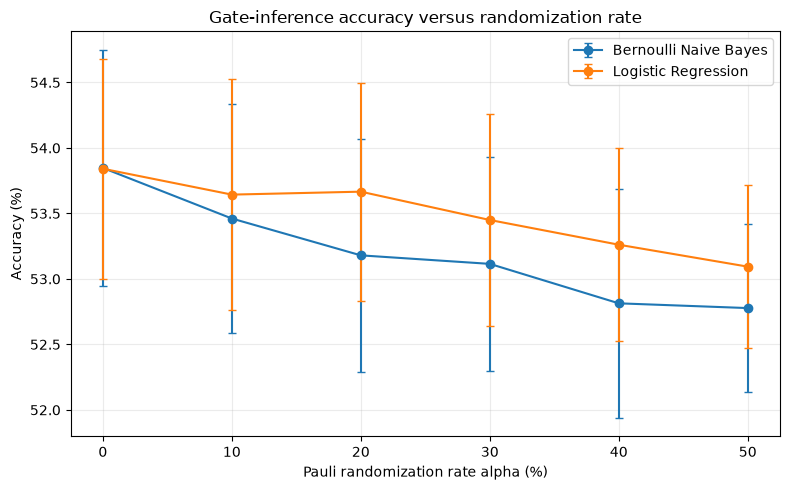

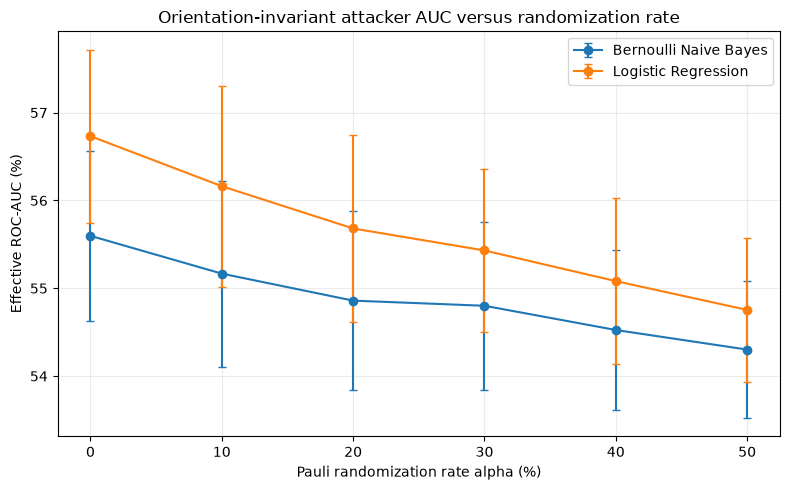

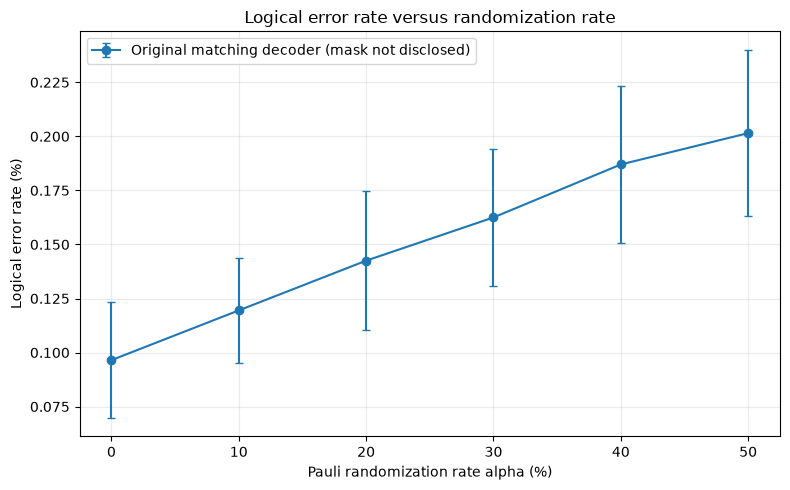


RATE SWEEP COMPLETED.
Interpret results using the 20 independent repetitions as the statistical units.


In [49]:
# ============================================================
# PAULI RANDOMIZATION RATE SWEEP
# 6 rates x 20 independent paired repetitions
# No physical Pauli injection is used in this experiment.
# ============================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymatching

from scipy.stats import wilcoxon, friedmanchisquare, spearmanr, t
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.exceptions import ConvergenceWarning

# ------------------------------------------------------------
# 0. Fail-closed preflight checks
# ------------------------------------------------------------

if not globals().get("pauli_frame_validation_passed", False):
    raise RuntimeError(
        "Rate sweep blocked: complete noiseless and noisy Pauli-frame "
        "validation must pass first."
    )

required_names = [
    "H_circuit", "S_circuit", "S_matcher", "data_qubits", "pauli_types",
    "virtual_error_masks", "virtual_error_observable_flips",
    "noiseless_validation_summary", "noisy_validation_summary",
    "S_observable_validation_summary",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError(f"Rate sweep blocked; missing required objects: {missing_names}")

if not (
    noiseless_validation_summary.get("passed", False)
    and noisy_validation_summary.get("passed", False)
    and S_observable_validation_summary.get("passed", False)
):
    raise RuntimeError("Rate sweep blocked: one or more validation summaries failed.")

if H_circuit.num_detectors != S_circuit.num_detectors:
    raise RuntimeError("H_L and S_L detector dimensions differ.")
if H_circuit.num_detectors != 100 or S_circuit.num_observables != 1:
    raise RuntimeError("Unexpected circuit dimensions for the registered experiment.")
if len(data_qubits) != 41 or set(pauli_types) != {"X", "Y", "Z"}:
    raise RuntimeError("The expected 41 x 3 Pauli selection library is unavailable.")

# Confirm all required mask entries still exist and have correct dimensions.
for gate_name, circuit in (("H_L", H_circuit), ("S_L", S_circuit)):
    for q in data_qubits:
        for p in pauli_types:
            mask = np.asarray(virtual_error_masks[gate_name][q][p], dtype=bool)
            if mask.shape != (circuit.num_detectors,):
                raise RuntimeError(f"Invalid detector mask: {gate_name}/{q}/{p}")
            if gate_name == "S_L":
                offset = virtual_error_observable_flips[gate_name][q][p]
                if offset not in (0, 1):
                    raise RuntimeError(f"Invalid S_L observable offset: {q}/{p}")

# ------------------------------------------------------------
# 1. Preregistered settings (do not tune after seeing results)
# ------------------------------------------------------------

SWEEP_RATES = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.5], dtype=float)
SWEEP_REPEATS = 20
SWEEP_SHOTS_PER_GATE = 10_000
SWEEP_MASTER_SEED = 20261101
SWEEP_TEST_SIZE = 0.20
SWEEP_SPLIT_SEED = 42
SWEEP_LOGISTIC_MAX_ITER = 3000

# Fixed balanced labels: 0 = H_L, 1 = S_L.
sweep_y = np.concatenate([
    np.zeros(SWEEP_SHOTS_PER_GATE, dtype=np.int8),
    np.ones(SWEEP_SHOTS_PER_GATE, dtype=np.int8),
])
sweep_train_idx, sweep_test_idx = train_test_split(
    np.arange(len(sweep_y)),
    test_size=SWEEP_TEST_SIZE,
    random_state=SWEEP_SPLIT_SEED,
    stratify=sweep_y,
)

# ------------------------------------------------------------
# 2. Helpers: common random choices and XOR frame transforms
# ------------------------------------------------------------

def make_shot_randomization(n_shots, rng):
    """Draw one U, data-qubit, and Pauli choice per shot."""
    uniforms = rng.random(n_shots)
    qubits = rng.choice(np.asarray(data_qubits, dtype=int), size=n_shots)
    paulis = rng.choice(np.asarray(pauli_types, dtype=object), size=n_shots)
    return uniforms, qubits, paulis


def apply_rate_transform(gate_name, base_records, base_observables,
                         uniforms, selected_qubits, selected_paulis, alpha):
    """Apply validated detector masks to shots with U < alpha.

    Returns transformed records, transformed optional observables, active-shot
    mask, and number of distinct (qubit, Pauli) cases used.
    """
    records = np.asarray(base_records, dtype=bool).copy()
    observables = None if base_observables is None else np.asarray(
        base_observables, dtype=bool
    ).copy()

    n = len(records)
    if not (len(uniforms) == len(selected_qubits) == len(selected_paulis) == n):
        raise ValueError(f"Shot-selection dimensions do not match for {gate_name}.")
    if not 0.0 <= float(alpha) <= 1.0:
        raise ValueError("alpha must be between 0 and 1.")
    if gate_name == "S_L":
        if observables is None or observables.shape != (n, 1):
            raise ValueError("S_L requires exactly one observable per shot.")
    elif observables is not None:
        raise ValueError("Only S_L observable corrections are in scope.")

    active = np.asarray(uniforms < alpha, dtype=bool)
    active_indices = np.flatnonzero(active)
    distinct_cases = set()

    if len(active_indices):
        selected_pairs = np.column_stack((
            np.asarray(selected_qubits[active_indices], dtype=int),
            np.asarray(selected_paulis[active_indices], dtype=str),
        ))
        # np.unique gives deterministic grouping of active cases.
        for q_value, p_value in np.unique(selected_pairs, axis=0):
            q_value = int(q_value)
            p_value = str(p_value)
            shot_indices = active_indices[
                (np.asarray(selected_qubits[active_indices], dtype=int) == q_value)
                & (np.asarray(selected_paulis[active_indices], dtype=str) == p_value)
            ]
            mask = np.asarray(
                virtual_error_masks[gate_name][q_value][p_value], dtype=bool
            )
            if mask.shape != (records.shape[1],):
                raise ValueError(f"Mask dimension mismatch: {gate_name}/{q_value}/{p_value}")
            records[shot_indices] ^= mask

            if gate_name == "S_L":
                offset = int(virtual_error_observable_flips["S_L"][q_value][p_value])
                if offset not in (0, 1):
                    raise ValueError(f"Invalid observable offset: {q_value}/{p_value}")
                observables[shot_indices, 0] ^= bool(offset)
            distinct_cases.add((q_value, p_value))

    return records, observables, active, len(distinct_cases)


def effective_auc(y_true, y_score):
    """Orientation-invariant AUC: an attacker can invert class labels."""
    raw_auc = float(roc_auc_score(y_true, y_score))
    return raw_auc, max(raw_auc, 1.0 - raw_auc)


def evaluate_classifier(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    raw_auc, attack_auc = effective_auc(y_test, probability)
    return float(accuracy_score(y_test, prediction)), raw_auc, attack_auc


def wilcoxon_pvalue(differences):
    differences = np.asarray(differences, dtype=float)
    if np.allclose(differences, 0.0, atol=0.0, rtol=0.0):
        return 1.0
    return float(wilcoxon(
        differences,
        zero_method="pratt",
        alternative="two-sided",
        method="auto",
    ).pvalue)


def holm_adjust(p_values):
    """Holm step-down adjusted p-values, returned in original order."""
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)
    order = np.argsort(p_values)
    adjusted_sorted = np.empty(m, dtype=float)
    running_max = 0.0
    for rank, original_index in enumerate(order):
        candidate = (m - rank) * p_values[original_index]
        running_max = max(running_max, candidate)
        adjusted_sorted[rank] = min(running_max, 1.0)
    adjusted = np.empty(m, dtype=float)
    for rank, original_index in enumerate(order):
        adjusted[original_index] = adjusted_sorted[rank]
    return adjusted


def paired_mean_ci(differences, confidence=0.95):
    """Two-sided t interval for the mean of run-level paired differences."""
    differences = np.asarray(differences, dtype=float)
    n = len(differences)
    mean = float(np.mean(differences))
    if n < 2:
        return mean, np.nan, np.nan
    sd = float(np.std(differences, ddof=1))
    se = sd / np.sqrt(n)
    critical = float(t.ppf((1 + confidence) / 2, df=n - 1))
    return mean, mean - critical * se, mean + critical * se

# ------------------------------------------------------------
# 3. Run the rate sweep
# ------------------------------------------------------------

sweep_run_rows = []
sweep_warning_rows = []

print("=" * 78)
print("PAIRED PAULI RANDOMIZATION RATE SWEEP")
print(f"Rates: {SWEEP_RATES.tolist()}")
print(f"Independent repetitions: {SWEEP_REPEATS}")
print(f"Shots per gate per repetition: {SWEEP_SHOTS_PER_GATE:,}")
print("Common random numbers across alpha: ENABLED")
print("Physical Pauli injection: NOT USED")
print("=" * 78)

for run in range(SWEEP_REPEATS):
    print(f"\nStarting sweep repetition {run + 1:02d}/{SWEEP_REPEATS}")

    run_rng = np.random.default_rng(SWEEP_MASTER_SEED + run)
    H_seed = int(run_rng.integers(1, 2**31 - 1))
    S_seed = int(run_rng.integers(1, 2**31 - 1))

    # Sample each ORIGINAL noisy circuit once. All alpha values reuse these.
    H_base = H_circuit.compile_detector_sampler(seed=H_seed).sample(
        shots=SWEEP_SHOTS_PER_GATE
    ).astype(bool)
    S_base, S_base_obs = S_circuit.compile_detector_sampler(seed=S_seed).sample(
        shots=SWEEP_SHOTS_PER_GATE,
        separate_observables=True,
    )
    S_base = np.asarray(S_base, dtype=bool)
    S_base_obs = np.asarray(S_base_obs, dtype=bool)

    if H_base.shape != (SWEEP_SHOTS_PER_GATE, H_circuit.num_detectors):
        raise RuntimeError("Unexpected H_L detector sample dimensions.")
    if S_base.shape != (SWEEP_SHOTS_PER_GATE, S_circuit.num_detectors):
        raise RuntimeError("Unexpected S_L detector sample dimensions.")
    if S_base_obs.shape != (SWEEP_SHOTS_PER_GATE, 1):
        raise RuntimeError("Unexpected S_L observable dimensions.")

    # Label-independent selections are drawn once and reused at every alpha.
    selection_rng = np.random.default_rng(SWEEP_MASTER_SEED * 10 + run)
    H_U, H_q, H_p = make_shot_randomization(SWEEP_SHOTS_PER_GATE, selection_rng)
    S_U, S_q, S_p = make_shot_randomization(SWEEP_SHOTS_PER_GATE, selection_rng)

    # The base dataset and labels are common to the two classifiers.
    X_base = np.vstack((H_base, S_base)).astype(np.uint8, copy=False)
    if X_base.shape != (2 * SWEEP_SHOTS_PER_GATE, H_circuit.num_detectors):
        raise RuntimeError("Unexpected stacked gate-inference data dimensions.")

    # Decode the baseline S_L sample once per independent repetition.
    S_decoded_base = np.asarray(
        S_matcher.decode_batch(S_base.astype(np.uint8, copy=False))
    ).reshape(-1).astype(bool)
    S_truth_base = S_base_obs.reshape(-1).astype(bool)
    if len(S_decoded_base) != SWEEP_SHOTS_PER_GATE:
        raise RuntimeError("Unexpected baseline S_L decoder output length.")
    baseline_errors = int(np.count_nonzero(S_decoded_base != S_truth_base))
    baseline_ler = baseline_errors / SWEEP_SHOTS_PER_GATE

    run_rows = []
    for alpha in SWEEP_RATES:
        H_trans, _, H_active, H_cases = apply_rate_transform(
            "H_L", H_base, None, H_U, H_q, H_p, float(alpha)
        )
        S_trans, S_obs_trans, S_active, S_cases = apply_rate_transform(
            "S_L", S_base, S_base_obs, S_U, S_q, S_p, float(alpha)
        )
        X_trans = np.vstack((H_trans, S_trans)).astype(np.uint8, copy=False)

        # Frame-aware inverse control: applying the same XOR masks again
        # must recover the exact original records and S_L observable.
        H_restored, _, _, _ = apply_rate_transform(
            "H_L", H_trans, None, H_U, H_q, H_p, float(alpha)
        )
        S_restored, S_obs_restored, _, _ = apply_rate_transform(
            "S_L", S_trans, S_obs_trans, S_U, S_q, S_p, float(alpha)
        )
        if not np.array_equal(H_restored, H_base):
            raise AssertionError(f"H_L frame-aware restoration failed at alpha={alpha}.")
        if not np.array_equal(S_restored, S_base):
            raise AssertionError(f"S_L frame-aware detector restoration failed at alpha={alpha}.")
        if not np.array_equal(S_obs_restored, S_base_obs):
            raise AssertionError(f"S_L frame-aware observable restoration failed at alpha={alpha}.")

        # Fit an attacker model at each alpha: the attacker knows alpha/policy,
        # but does not know the individual per-shot mask.
        X_train = X_trans[sweep_train_idx]
        X_test = X_trans[sweep_test_idx]
        y_train = sweep_y[sweep_train_idx]
        y_test = sweep_y[sweep_test_idx]

        bnb = BernoulliNB()
        bnb_accuracy, bnb_raw_auc, bnb_effective_auc = evaluate_classifier(
            bnb, X_train, y_train, X_test, y_test
        )

        logistic = LogisticRegression(
            solver="lbfgs",
            max_iter=SWEEP_LOGISTIC_MAX_ITER,
            tol=1e-4,
            random_state=SWEEP_MASTER_SEED + run,
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            lr_accuracy, lr_raw_auc, lr_effective_auc = evaluate_classifier(
                logistic, X_train, y_train, X_test, y_test
            )
        for warning_item in caught:
            sweep_warning_rows.append({
                "run": run + 1,
                "alpha": float(alpha),
                "category": warning_item.category.__name__,
                "message": str(warning_item.message),
            })

        # Fixed original S_L matching decoder, intentionally not given the
        # individual frame mask. Score in the transformed logical frame.
        S_decoded_trans = np.asarray(
            S_matcher.decode_batch(S_trans.astype(np.uint8, copy=False))
        ).reshape(-1).astype(bool)
        S_truth_trans = S_obs_trans.reshape(-1).astype(bool)
        if len(S_decoded_trans) != SWEEP_SHOTS_PER_GATE:
            raise RuntimeError("Unexpected S_L decoder output length.")

        transformed_errors = int(np.count_nonzero(S_decoded_trans != S_truth_trans))
        transformed_ler = transformed_errors / SWEEP_SHOTS_PER_GATE

        # At alpha=0, transformed data must be identical to the baseline.
        if alpha == 0.0:
            if not np.array_equal(H_trans, H_base) or not np.array_equal(S_trans, S_base):
                raise AssertionError("Alpha=0 changed detector records.")
            if not np.array_equal(S_obs_trans, S_base_obs):
                raise AssertionError("Alpha=0 changed logical observables.")
            if transformed_ler != baseline_ler:
                raise AssertionError("Alpha=0 LER differs from baseline.")

        transformed_fraction = (
            np.count_nonzero(H_active) + np.count_nonzero(S_active)
        ) / (2 * SWEEP_SHOTS_PER_GATE)

        row = {
            "run": run + 1,
            "alpha": float(alpha),
            "H_seed": H_seed,
            "S_seed": S_seed,
            "bnb_accuracy": bnb_accuracy,
            "bnb_raw_auc": bnb_raw_auc,
            "bnb_effective_auc": bnb_effective_auc,
            "logistic_accuracy": lr_accuracy,
            "logistic_raw_auc": lr_raw_auc,
            "logistic_effective_auc": lr_effective_auc,
            "baseline_ler": baseline_ler,
            "ler": transformed_ler,
            "utility": 1.0 - transformed_ler,
            "ler_change": transformed_ler - baseline_ler,
            "utility_change": baseline_ler - transformed_ler,
            "modified_fraction_H": float(np.mean(H_active)),
            "modified_fraction_S": float(np.mean(S_active)),
            "modified_fraction_pooled": float(transformed_fraction),
            "H_distinct_cases": int(H_cases),
            "S_distinct_cases": int(S_cases),
            "frame_aware_exact_restore": True,
        }
        sweep_run_rows.append(row)
        run_rows.append(row)

    # Compact per-repetition display.
    print(
        f"Run {run + 1:02d}: "
        + " | ".join(
            f"a={r['alpha']:.1f}: NB={r['bnb_accuracy']*100:.2f}%, "
            f"LR={r['logistic_accuracy']*100:.2f}%, "
            f"LER={r['ler']*100:.3f}%"
            for r in run_rows
        )
    )

# ------------------------------------------------------------
# 4. Build run-level data and descriptive summaries
# ------------------------------------------------------------

sweep_runs_df = pd.DataFrame(sweep_run_rows)
sweep_warning_df = pd.DataFrame(
    sweep_warning_rows,
    columns=["run", "alpha", "category", "message"],
)

if len(sweep_runs_df) != SWEEP_REPEATS * len(SWEEP_RATES):
    raise RuntimeError("Rate sweep did not produce the expected number of run-rate rows.")
if not sweep_runs_df["frame_aware_exact_restore"].all():
    raise RuntimeError("At least one frame-aware inverse check failed.")

primary_metrics = [
    ("bnb_accuracy", "BernoulliNB accuracy"),
    ("bnb_effective_auc", "BernoulliNB effective AUC"),
    ("logistic_accuracy", "Logistic Regression accuracy"),
    ("logistic_effective_auc", "Logistic Regression effective AUC"),
    ("ler", "Masked-record LER"),
]

def describe_percent(values):
    values = np.asarray(values, dtype=float) * 100.0
    return float(np.mean(values)), float(np.std(values, ddof=1))

summary_rows = []
for alpha in SWEEP_RATES:
    subset = sweep_runs_df[sweep_runs_df["alpha"] == alpha]
    row = {"alpha": float(alpha), "repetitions": len(subset)}
    for metric, _ in primary_metrics:
        mean, sd = describe_percent(subset[metric].to_numpy())
        row[f"{metric}_mean_pct"] = mean
        row[f"{metric}_sd_pp"] = sd
    ler_mean, ler_sd = describe_percent(subset["ler"].to_numpy())
    util_mean, util_sd = describe_percent(subset["utility"].to_numpy())
    mod_mean, mod_sd = describe_percent(subset["modified_fraction_pooled"].to_numpy())
    row.update({
        "utility_mean_pct": util_mean,
        "utility_sd_pp": util_sd,
        "modified_shots_mean_pct": mod_mean,
        "modified_shots_sd_pp": mod_sd,
        "mean_H_distinct_cases": float(subset["H_distinct_cases"].mean()),
        "mean_S_distinct_cases": float(subset["S_distinct_cases"].mean()),
    })
    summary_rows.append(row)

sweep_summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 100)
print("RATE SWEEP SUMMARY: MEAN +/- SAMPLE SD ACROSS 20 REPEATS (PERCENT)")
print("=" * 100)
summary_display_cols = [
    "alpha",
    "bnb_accuracy_mean_pct", "bnb_accuracy_sd_pp",
    "bnb_effective_auc_mean_pct", "bnb_effective_auc_sd_pp",
    "logistic_accuracy_mean_pct", "logistic_accuracy_sd_pp",
    "logistic_effective_auc_mean_pct", "logistic_effective_auc_sd_pp",
    "ler_mean_pct", "ler_sd_pp",
    "utility_mean_pct", "utility_sd_pp",
    "modified_shots_mean_pct", "modified_shots_sd_pp",
]
print(sweep_summary_df[summary_display_cols].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ------------------------------------------------------------
# 5. Paired comparisons against alpha=0 + global Holm correction
# ------------------------------------------------------------

raw_comparison_rows = []
for metric, label in primary_metrics:
    baseline_by_run = (
        sweep_runs_df[sweep_runs_df["alpha"] == 0.0]
        .set_index("run")[metric]
        .sort_index()
    )
    for alpha in SWEEP_RATES[1:]:
        treatment_by_run = (
            sweep_runs_df[sweep_runs_df["alpha"] == alpha]
            .set_index("run")[metric]
            .sort_index()
        )
        differences = treatment_by_run.to_numpy() - baseline_by_run.to_numpy()
        mean_diff, ci_low, ci_high = paired_mean_ci(differences)
        raw_comparison_rows.append({
            "metric": metric,
            "metric_label": label,
            "alpha": float(alpha),
            "mean_paired_change_pp": mean_diff * 100.0,
            "paired_change_ci95_low_pp": ci_low * 100.0,
            "paired_change_ci95_high_pp": ci_high * 100.0,
            "wilcoxon_p_raw": wilcoxon_pvalue(differences),
        })

sweep_pairwise_df = pd.DataFrame(raw_comparison_rows)
sweep_pairwise_df["wilcoxon_p_holm_25"] = holm_adjust(
    sweep_pairwise_df["wilcoxon_p_raw"].to_numpy()
)
sweep_pairwise_df["significant_holm_0_05"] = (
    sweep_pairwise_df["wilcoxon_p_holm_25"] < 0.05
)

print("\n" + "=" * 100)
print("PAIRED WILCOXON COMPARISONS VS ALPHA=0 (HOLM CORRECTED ACROSS 25 CONTRASTS)")
print("=" * 100)
print(sweep_pairwise_df[[
    "metric_label", "alpha", "mean_paired_change_pp",
    "paired_change_ci95_low_pp", "paired_change_ci95_high_pp",
    "wilcoxon_p_raw", "wilcoxon_p_holm_25", "significant_holm_0_05"
]].to_string(index=False, float_format=lambda x: f"{x:.6g}"))

# ------------------------------------------------------------
# 6. Omnibus rate effect + within-run monotonic trend analysis
# ------------------------------------------------------------

omnibus_rows = []
trend_rows = []
for metric, label in primary_metrics:
    matrix = np.vstack([
        sweep_runs_df[sweep_runs_df["alpha"] == alpha]
        .sort_values("run")[metric].to_numpy()
        for alpha in SWEEP_RATES
    ]).T  # rows = repetitions; columns = alpha levels

    if np.allclose(matrix, matrix[:, [0]]):
        friedman_p = 1.0
    else:
        friedman_p = float(friedmanchisquare(*[matrix[:, j] for j in range(matrix.shape[1])]).pvalue)

    run_rhos = []
    for row_values in matrix:
        rho = spearmanr(SWEEP_RATES, row_values).statistic
        run_rhos.append(0.0 if not np.isfinite(rho) else float(rho))
    run_rhos = np.asarray(run_rhos)
    trend_p = wilcoxon_pvalue(run_rhos)

    omnibus_rows.append({
        "metric": metric,
        "metric_label": label,
        "friedman_p_raw": friedman_p,
    })
    trend_rows.append({
        "metric": metric,
        "metric_label": label,
        "mean_run_spearman_rho": float(np.mean(run_rhos)),
        "median_run_spearman_rho": float(np.median(run_rhos)),
        "wilcoxon_p_for_run_rho": trend_p,
    })

sweep_omnibus_df = pd.DataFrame(omnibus_rows)
sweep_omnibus_df["friedman_p_holm_5"] = holm_adjust(
    sweep_omnibus_df["friedman_p_raw"].to_numpy()
)
sweep_trend_df = pd.DataFrame(trend_rows)
sweep_trend_df["trend_p_holm_5"] = holm_adjust(
    sweep_trend_df["wilcoxon_p_for_run_rho"].to_numpy()
)

print("\nOMNIBUS FRIEDMAN TESTS (ALL SIX RATES)")
print(sweep_omnibus_df.to_string(index=False, float_format=lambda x: f"{x:.6g}"))
print("\nWITHIN-REPETITION MONOTONIC TREND (SPEARMAN RHO; TESTED ACROSS 20 RUNS)")
print(sweep_trend_df.to_string(index=False, float_format=lambda x: f"{x:.6g}"))

# ------------------------------------------------------------
# 7. Warnings and reproducibility exports
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("MODEL WARNINGS")
print("=" * 78)
if sweep_warning_df.empty:
    print("No captured model warnings.")
else:
    print(sweep_warning_df.to_string(index=False))
    if (sweep_warning_df["category"] == "ConvergenceWarning").any():
        print("WARNING: At least one Logistic Regression fit did not converge; do not interpret LR results as final.")

# Save raw run-level data and summaries for audit/reproducibility.
export_dir = Path.cwd()
sweep_runs_path = export_dir / "SecureGate_rate_sweep_run_level.csv"
sweep_summary_path = export_dir / "SecureGate_rate_sweep_summary.csv"
sweep_pairwise_path = export_dir / "SecureGate_rate_sweep_pairwise_tests.csv"
sweep_trend_path = export_dir / "SecureGate_rate_sweep_trend_tests.csv"
sweep_warnings_path = export_dir / "SecureGate_rate_sweep_warnings.csv"

sweep_runs_df.to_csv(sweep_runs_path, index=False)
sweep_summary_df.to_csv(sweep_summary_path, index=False)
sweep_pairwise_df.to_csv(sweep_pairwise_path, index=False)
sweep_trend_df.to_csv(sweep_trend_path, index=False)
sweep_warning_df.to_csv(sweep_warnings_path, index=False)

print("\nExported reproducibility files:")
for path in [sweep_runs_path, sweep_summary_path, sweep_pairwise_path, sweep_trend_path, sweep_warnings_path]:
    print(f" - {path.resolve()}")

# ------------------------------------------------------------
# 8. Plots (descriptive; error bars are run-level SD)
# ------------------------------------------------------------

rates_pct = SWEEP_RATES * 100.0

def plot_rate_metric(metric_columns, labels, title, ylabel, filename):
    fig, ax = plt.subplots(figsize=(8, 5))
    for col, label in zip(metric_columns, labels):
        means = []
        sds = []
        for alpha in SWEEP_RATES:
            vals = sweep_runs_df.loc[sweep_runs_df["alpha"] == alpha, col].to_numpy() * 100.0
            means.append(np.mean(vals))
            sds.append(np.std(vals, ddof=1))
        ax.errorbar(rates_pct, means, yerr=sds, marker="o", capsize=3, label=label)
    ax.set_title(title)
    ax.set_xlabel("Pauli randomization rate alpha (%)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(rates_pct)
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(export_dir / filename, dpi=180, bbox_inches="tight")
    plt.show()

plot_rate_metric(
    ["bnb_accuracy", "logistic_accuracy"],
    ["Bernoulli Naive Bayes", "Logistic Regression"],
    "Gate-inference accuracy versus randomization rate",
    "Accuracy (%)",
    "SecureGate_rate_sweep_accuracy.png",
)
plot_rate_metric(
    ["bnb_effective_auc", "logistic_effective_auc"],
    ["Bernoulli Naive Bayes", "Logistic Regression"],
    "Orientation-invariant attacker AUC versus randomization rate",
    "Effective ROC-AUC (%)",
    "SecureGate_rate_sweep_auc.png",
)
plot_rate_metric(
    ["ler"],
    ["Original matching decoder (mask not disclosed)"],
    "Logical error rate versus randomization rate",
    "Logical error rate (%)",
    "SecureGate_rate_sweep_ler.png",
)

print("\nRATE SWEEP COMPLETED.")
print("Interpret results using the 20 independent repetitions as the statistical units.")


In [59]:
# SecureGate — Integrated Privacy / Decoder-Utility Experiment
#
# Purpose
# -------
# Evaluate, under one fresh paired simulation study:
#   1. Gate-inference accuracy on H_L versus S_L detector records,
#      before and after alpha=0.10 software Pauli-frame randomization.
#   2. S_L logical error rate (LER) and decoder utility for:
#        A. original records + PyMatching
#        B. randomized records + PyMatching
#        C. randomized records + frozen-threshold CNN selective override
#
# The CNN is the already-trained S_L model. It is NOT retrained here.
# The primary CNN confidence threshold is frozen at 0.999164999, which
# was selected from validation for the 2% target quota in the previous
# independent-confirmation run. Do not tune it using these new results.
#
# Design
# ------
# 20 independent repetitions x 25,000 shots per gate per repetition.
# Total fresh samples: 500,000 H_L + 500,000 S_L.
# The same fresh H_L/S_L samples are used for baseline and randomized
# comparisons within each repetition (paired design).
#
# No old Test split is read. No datasets or files are written.
# This is a new experiment: it samples fresh Stim circuits and runs the
# inference/decoder evaluation. It should be executed only once after
# confirming all preflight checks.

import gc
import warnings
import numpy as np
import pandas as pd
import torch
import pymatching

from scipy.stats import wilcoxon
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.exceptions import ConvergenceWarning

# ---------------------------------------------------------------------
# 0. FAIL-CLOSED PREFLIGHT
# ---------------------------------------------------------------------

required_objects = [
    "H_circuit", "S_circuit",
    "data_qubits", "pauli_types",
    "virtual_error_masks", "virtual_error_observable_flips",
    "pauli_frame_validation_passed",
    "SG_3DCNN_MODEL", "best_state", "DEVICE",
    "SG_POSITIONS", "sg_to_grid",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(f"Integrated experiment blocked; missing: {missing_objects}")

if not pauli_frame_validation_passed:
    raise RuntimeError("Integrated experiment blocked: Pauli-frame validation did not pass.")
if "SG_INTEGRATED_RUN_RESULTS" in globals():
    raise RuntimeError(
        "Integrated experiment outputs already exist in this kernel. "
        "Do not rerun the same seeded confirmation by accident."
    )

if H_circuit.num_detectors != 100 or S_circuit.num_detectors != 100:
    raise RuntimeError("Expected exactly 100 detectors for both H_L and S_L.")
if S_circuit.num_observables != 1:
    raise RuntimeError("Expected exactly one S_L logical observable.")
if len(data_qubits) * len(pauli_types) != 123:
    raise RuntimeError("Expected 123 Pauli-frame cases.")
if len(SG_POSITIONS) != 100:
    raise RuntimeError("SG_POSITIONS must map all 100 S_L detectors.")

for gate_name, circuit in (("H_L", H_circuit), ("S_L", S_circuit)):
    for q in data_qubits:
        for p in pauli_types:
            mask = np.asarray(virtual_error_masks[gate_name][q][p], dtype=np.uint8).reshape(-1)
            if mask.shape != (circuit.num_detectors,) or not np.all(np.isin(mask, [0, 1])):
                raise RuntimeError(f"Invalid detector mask: {gate_name}/{q}/{p}")
            if gate_name == "S_L":
                offset = int(virtual_error_observable_flips[gate_name][q][p])
                if offset not in (0, 1):
                    raise RuntimeError(f"Invalid S_L observable offset: {q}/{p}")

N_REPEATS = 20
SHOTS_PER_GATE = 25_000
ALPHA = 0.10
PRIMARY_CNN_THRESHOLD = 0.999164999
TEST_SIZE = 0.20
SPLIT_SEED = 42
LOGISTIC_MAX_ITER = 3000
CNN_BATCH_SIZE = 1024
DECODE_BATCH_SIZE = 25_000

# New seed namespace; distinct from the prior 500k confirmation seeds
# 20261105/20261106 and the prior validation cross-fit seed 20261107.
CIRCUIT_MASTER_SEED = 20261108
SELECTION_MASTER_SEED = 20261120

# Exact audited offset-case count (must remain 10/123 for this S_L bank).
S_OFFSET_CASES = sum(
    int(virtual_error_observable_flips["S_L"][q][p])
    for q in data_qubits for p in pauli_types
)
if S_OFFSET_CASES != 10:
    raise RuntimeError(f"Expected 10 S_L observable-offset cases, found {S_OFFSET_CASES}.")

# Restore the frozen best checkpoint; no optimizer/training is invoked.
SG_3DCNN_MODEL.load_state_dict(best_state)
SG_3DCNN_MODEL.to(DEVICE)
SG_3DCNN_MODEL.eval()

S_INTEGRATED_MATCHER = pymatching.Matching.from_detector_error_model(
    S_circuit.detector_error_model(decompose_errors=True)
)

print("=" * 78)
print("SECUREGATE — INTEGRATED PRIVACY / DECODER-UTILITY EXPERIMENT")
print("=" * 78)
print(f"Alpha: {ALPHA:.2f}")
print(f"Repeats: {N_REPEATS}")
print(f"Shots per gate per repeat: {SHOTS_PER_GATE:,}")
print(f"Total fresh shots per gate: {N_REPEATS * SHOTS_PER_GATE:,}")
print(f"Frozen CNN threshold (primary 2% validation target): {PRIMARY_CNN_THRESHOLD:.9f}")
print(f"Device: {DEVICE}")
print("Old train/validation/test files: NOT ACCESSED")
print("CNN retraining: NO")
print("Per-shot Pauli identity supplied to attackers/CNN: NO")
print("Files created or overwritten: NO")

# ---------------------------------------------------------------------
# 1. HELPERS — RANDOMIZATION, DECODING, ATTACKERS, STATISTICS
# ---------------------------------------------------------------------

def _draw_selections(n_shots, seed):
    rng = np.random.default_rng(int(seed))
    uniforms = rng.random(n_shots)
    qubits = rng.choice(np.asarray(data_qubits, dtype=int), size=n_shots)
    paulis = rng.choice(np.asarray(pauli_types, dtype=object), size=n_shots)
    return uniforms, qubits, paulis


def _apply_virtual_frame(gate_name, base_detectors, base_observables,
                         uniforms, selected_qubits, selected_paulis, alpha):
    records = np.asarray(base_detectors, dtype=np.uint8).copy()
    observables = None if base_observables is None else np.asarray(
        base_observables, dtype=np.uint8
    ).copy()
    n = len(records)
    if not (len(uniforms) == len(selected_qubits) == len(selected_paulis) == n):
        raise ValueError(f"Selection length mismatch for {gate_name}.")
    active = np.asarray(uniforms < float(alpha), dtype=bool)
    active_idx = np.flatnonzero(active)

    if gate_name == "S_L":
        if observables is None or observables.shape != (n, 1):
            raise ValueError("S_L transformation requires an (n, 1) observable array.")
    elif observables is not None:
        raise ValueError("Only the S_L branch is supplied with observable data in this study.")

    if len(active_idx):
        active_pairs = np.column_stack((
            np.asarray(selected_qubits[active_idx], dtype=int),
            np.asarray(selected_paulis[active_idx], dtype=str),
        ))
        for q_value, p_value in np.unique(active_pairs, axis=0):
            q_value = int(q_value)
            p_value = str(p_value)
            shot_idx = active_idx[
                (np.asarray(selected_qubits[active_idx], dtype=int) == q_value)
                & (np.asarray(selected_paulis[active_idx], dtype=str) == p_value)
            ]
            mask = np.asarray(
                virtual_error_masks[gate_name][q_value][p_value], dtype=np.uint8
            ).reshape(-1)
            if mask.shape != (records.shape[1],):
                raise ValueError(f"Mask shape mismatch for {gate_name}/{q_value}/{p_value}.")
            records[shot_idx] ^= mask
            if gate_name == "S_L":
                offset = int(virtual_error_observable_flips["S_L"][q_value][p_value])
                observables[shot_idx, 0] ^= np.uint8(offset)

    return records, observables, active


def _decode_in_batches(matcher, records, batch_size=DECODE_BATCH_SIZE):
    out = []
    for start in range(0, len(records), batch_size):
        end = min(start + batch_size, len(records))
        pred = matcher.decode_batch(np.asarray(records[start:end], dtype=bool))
        out.append(np.asarray(pred).reshape(-1).astype(np.uint8))
    return np.concatenate(out)


def _cnn_probabilities(detector_records):
    grid = sg_to_grid(np.asarray(detector_records, dtype=np.uint8))
    pieces = []
    with torch.no_grad():
        for start in range(0, len(grid), CNN_BATCH_SIZE):
            end = min(start + CNN_BATCH_SIZE, len(grid))
            xb = torch.from_numpy(grid[start:end]).unsqueeze(1).to(
                DEVICE, dtype=torch.float32
            )
            logits = SG_3DCNN_MODEL(xb)
            pieces.append(torch.sigmoid(logits).detach().cpu().numpy())
    probs = np.concatenate(pieces).reshape(-1)
    if len(probs) != len(detector_records) or not np.all(np.isfinite(probs)):
        raise RuntimeError("CNN returned invalid probability output.")
    return probs


def _effective_auc(y_true, probabilities):
    raw_auc = float(roc_auc_score(y_true, probabilities))
    return raw_auc, max(raw_auc, 1.0 - raw_auc)


def _fit_attacker(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    pred = np.asarray(model.predict(X_test), dtype=np.uint8)
    prob = np.asarray(model.predict_proba(X_test)[:, 1], dtype=float)
    raw_acc = float(accuracy_score(y_test, pred))
    # An attacker can invert the class mapping; report effective accuracy too.
    effective_acc = max(raw_acc, 1.0 - raw_acc)
    raw_auc, effective_auc = _effective_auc(y_test, prob)
    return {
        "raw_accuracy": raw_acc,
        "effective_accuracy": effective_acc,
        "raw_auc": raw_auc,
        "effective_auc": effective_auc,
    }


def _safe_wilcoxon(new_values, old_values):
    new_values = np.asarray(new_values, dtype=float)
    old_values = np.asarray(old_values, dtype=float)
    diff = new_values - old_values
    if len(diff) < 2 or np.allclose(diff, 0.0, atol=0.0, rtol=0.0):
        return 1.0
    return float(wilcoxon(
        new_values, old_values,
        zero_method="pratt",
        alternative="two-sided",
        method="auto",
    ).pvalue)


def _holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)
    order = np.argsort(p_values)
    adjusted_sorted = np.empty(m, dtype=float)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p_values[idx])
        adjusted_sorted[rank] = min(running, 1.0)
    adjusted = np.empty(m, dtype=float)
    adjusted[order] = adjusted_sorted
    return adjusted

# Fixed balanced classifier labels and a fixed, stratified split per repeat.
y_gate = np.concatenate([
    np.zeros(SHOTS_PER_GATE, dtype=np.uint8),
    np.ones(SHOTS_PER_GATE, dtype=np.uint8),
])
train_idx, test_idx = train_test_split(
    np.arange(2 * SHOTS_PER_GATE),
    test_size=TEST_SIZE,
    random_state=SPLIT_SEED,
    stratify=y_gate,
)
y_test = y_gate[test_idx]

# ---------------------------------------------------------------------
# 2. FRESH PAIRED REPEATED EXPERIMENT
# ---------------------------------------------------------------------

run_rows = []
convergence_warning_count = 0

for run in range(N_REPEATS):
    print(f"\nRun {run + 1:02d}/{N_REPEATS}")

    # Fresh, independently seeded original circuit samples.
    seed_rng = np.random.default_rng(CIRCUIT_MASTER_SEED + run)
    h_circuit_seed = int(seed_rng.integers(1, 2**31 - 1))
    s_circuit_seed = int(seed_rng.integers(1, 2**31 - 1))

    H_base = H_circuit.compile_detector_sampler(seed=h_circuit_seed).sample(
        shots=SHOTS_PER_GATE
    ).astype(np.uint8, copy=False)
    S_base, S_obs_base = S_circuit.compile_detector_sampler(seed=s_circuit_seed).sample(
        shots=SHOTS_PER_GATE,
        separate_observables=True,
    )
    H_base = np.asarray(H_base, dtype=np.uint8)
    S_base = np.asarray(S_base, dtype=np.uint8)
    S_obs_base = np.asarray(S_obs_base, dtype=np.uint8)

    if H_base.shape != (SHOTS_PER_GATE, 100):
        raise RuntimeError(f"Unexpected H_L sample shape: {H_base.shape}")
    if S_base.shape != (SHOTS_PER_GATE, 100) or S_obs_base.shape != (SHOTS_PER_GATE, 1):
        raise RuntimeError("Unexpected S_L detector/observable sample dimensions.")

    # Independent label-blind random selections for H_L and S_L.
    H_u, H_q, H_p = _draw_selections(
        SHOTS_PER_GATE, SELECTION_MASTER_SEED + 2 * run
    )
    S_u, S_q, S_p = _draw_selections(
        SHOTS_PER_GATE, SELECTION_MASTER_SEED + 2 * run + 1
    )

    H_rand, _, H_active = _apply_virtual_frame(
        "H_L", H_base, None, H_u, H_q, H_p, ALPHA
    )
    S_rand, S_obs_rand, S_active = _apply_virtual_frame(
        "S_L", S_base, S_obs_base, S_u, S_q, S_p, ALPHA
    )

    # Verify that observable-frame offsets occur only on randomized S_L shots.
    actual_offset_mask = np.logical_xor(
        S_obs_base.reshape(-1).astype(bool),
        S_obs_rand.reshape(-1).astype(bool),
    )
    if np.any(actual_offset_mask & ~S_active):
        raise AssertionError("An observable offset appeared on a non-randomized shot.")

    # ---------------- Gate-inference: baseline vs randomized records ----------------
    X_baseline = np.vstack((H_base, S_base)).astype(np.uint8, copy=False)
    X_randomized = np.vstack((H_rand, S_rand)).astype(np.uint8, copy=False)

    Xb_train = X_baseline[train_idx].astype(np.float32, copy=False)
    Xb_test = X_baseline[test_idx].astype(np.float32, copy=False)
    Xm_train = X_randomized[train_idx].astype(np.float32, copy=False)
    Xm_test = X_randomized[test_idx].astype(np.float32, copy=False)

    for attacker_name in ("BernoulliNB", "LogisticRegression"):
        if attacker_name == "BernoulliNB":
            baseline_model = BernoulliNB()
            randomized_model = BernoulliNB()
        else:
            baseline_model = LogisticRegression(
                solver="lbfgs", max_iter=LOGISTIC_MAX_ITER,
                tol=1e-4, random_state=CIRCUIT_MASTER_SEED + run,
            )
            randomized_model = LogisticRegression(
                solver="lbfgs", max_iter=LOGISTIC_MAX_ITER,
                tol=1e-4, random_state=CIRCUIT_MASTER_SEED + run,
            )

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            base_metrics = _fit_attacker(
                baseline_model, Xb_train, y_gate[train_idx], Xb_test, y_test
            )
            random_metrics = _fit_attacker(
                randomized_model, Xm_train, y_gate[train_idx], Xm_test, y_test
            )
        convergence_warning_count += sum(
            issubclass(w.category, ConvergenceWarning) for w in caught
        )

        if attacker_name == "BernoulliNB":
            nb_base, nb_rand = base_metrics, random_metrics
        else:
            lr_base, lr_rand = base_metrics, random_metrics

        del baseline_model, randomized_model

    # ---------------- Decoder: baseline PM, randomized PM, randomized hybrid ----------------
    pm_base_pred = _decode_in_batches(S_INTEGRATED_MATCHER, S_base)
    pm_rand_pred = _decode_in_batches(S_INTEGRATED_MATCHER, S_rand)

    base_truth = S_obs_base.reshape(-1).astype(np.uint8)
    randomized_truth = S_obs_rand.reshape(-1).astype(np.uint8)

    cnn_probability = _cnn_probabilities(S_rand)
    cnn_pred = (cnn_probability >= 0.5).astype(np.uint8)
    cnn_confidence = np.maximum(cnn_probability, 1.0 - cnn_probability)

    disagreement = (pm_rand_pred != cnn_pred)
    override_mask = disagreement & (cnn_confidence >= PRIMARY_CNN_THRESHOLD)
    hybrid_pred = pm_rand_pred.copy()
    hybrid_pred[override_mask] = cnn_pred[override_mask]

    base_errors = int(np.count_nonzero(pm_base_pred != base_truth))
    randomized_pm_errors = int(np.count_nonzero(pm_rand_pred != randomized_truth))
    hybrid_errors = int(np.count_nonzero(hybrid_pred != randomized_truth))

    corrected = int(np.count_nonzero(
        (pm_rand_pred != randomized_truth) & (hybrid_pred == randomized_truth)
    ))
    introduced = int(np.count_nonzero(
        (pm_rand_pred == randomized_truth) & (hybrid_pred != randomized_truth)
    ))
    net_saved = corrected - introduced

    if hybrid_errors - randomized_pm_errors != -net_saved:
        raise AssertionError("Hybrid error accounting does not reconcile.")

    n_disagreements = int(disagreement.sum())
    n_overrides = int(override_mask.sum())
    n_modified = int(S_active.sum())
    n_offsets = int(actual_offset_mask.sum())

    base_ler = base_errors / SHOTS_PER_GATE
    randomized_pm_ler = randomized_pm_errors / SHOTS_PER_GATE
    hybrid_ler = hybrid_errors / SHOTS_PER_GATE

    run_rows.append({
        "run": run + 1,
        "H_circuit_seed": h_circuit_seed,
        "S_circuit_seed": s_circuit_seed,
        "NB_baseline_accuracy": nb_base["raw_accuracy"],
        "NB_randomized_accuracy": nb_rand["raw_accuracy"],
        "NB_baseline_effective_accuracy": nb_base["effective_accuracy"],
        "NB_randomized_effective_accuracy": nb_rand["effective_accuracy"],
        "NB_baseline_effective_AUC": nb_base["effective_auc"],
        "NB_randomized_effective_AUC": nb_rand["effective_auc"],
        "LR_baseline_accuracy": lr_base["raw_accuracy"],
        "LR_randomized_accuracy": lr_rand["raw_accuracy"],
        "LR_baseline_effective_accuracy": lr_base["effective_accuracy"],
        "LR_randomized_effective_accuracy": lr_rand["effective_accuracy"],
        "LR_baseline_effective_AUC": lr_base["effective_auc"],
        "LR_randomized_effective_AUC": lr_rand["effective_auc"],
        "baseline_PM_errors": base_errors,
        "randomized_PM_errors": randomized_pm_errors,
        "hybrid_errors": hybrid_errors,
        "baseline_PM_LER": base_ler,
        "randomized_PM_LER": randomized_pm_ler,
        "randomized_hybrid_LER": hybrid_ler,
        "baseline_PM_utility": 1.0 - base_ler,
        "randomized_PM_utility": 1.0 - randomized_pm_ler,
        "randomized_hybrid_utility": 1.0 - hybrid_ler,
        "S_disagreements": n_disagreements,
        "S_actual_overrides": n_overrides,
        "S_override_fraction_of_disagreements": (
            n_overrides / n_disagreements if n_disagreements else np.nan
        ),
        "S_override_fraction_of_all_shots": n_overrides / SHOTS_PER_GATE,
        "S_corrected_PM_errors": corrected,
        "S_introduced_errors": introduced,
        "S_net_errors_saved": net_saved,
        "H_randomized_shots": int(H_active.sum()),
        "H_realized_modified_fraction": float(H_active.mean()),
        "S_randomized_shots": n_modified,
        "S_realized_modified_fraction": n_modified / SHOTS_PER_GATE,
        "S_observable_offsets": n_offsets,
        "S_offset_fraction_among_modified": n_offsets / n_modified if n_modified else np.nan,
        "S_offset_fraction_of_all_shots": n_offsets / SHOTS_PER_GATE,
    })

    print(
        f"Run {run + 1:02d}: "
        f"NB eff.acc {100*nb_base['effective_accuracy']:.2f}% -> "
        f"{100*nb_rand['effective_accuracy']:.2f}% | "
        f"LR eff.acc {100*lr_base['effective_accuracy']:.2f}% -> "
        f"{100*lr_rand['effective_accuracy']:.2f}% | "
        f"S_L LER PM {100*base_ler:.3f}% -> "
        f"random-PM {100*randomized_pm_ler:.3f}% -> "
        f"hybrid {100*hybrid_ler:.3f}% | "
        f"overrides {n_overrides}/{n_disagreements}"
    )

    # Release large per-run arrays before the next Stim repetition.
    del H_base, S_base, S_obs_base, H_rand, S_rand, S_obs_rand
    del X_baseline, X_randomized, Xb_train, Xb_test, Xm_train, Xm_test
    del pm_base_pred, pm_rand_pred, cnn_probability, cnn_pred, cnn_confidence
    del hybrid_pred, actual_offset_mask, H_active, S_active
    del H_u, H_q, H_p, S_u, S_q, S_p
    del nb_base, nb_rand, lr_base, lr_rand
    gc.collect()

# ---------------------------------------------------------------------
# 3. SUMMARIES AND PAIRED INFERENCE
# ---------------------------------------------------------------------

SG_INTEGRATED_RUN_RESULTS = pd.DataFrame(run_rows)

# Run-level paired tests. The 20 independent repetitions are the statistical units.
tests = []

def _add_test(name, new_col, old_col):
    p = _safe_wilcoxon(
        SG_INTEGRATED_RUN_RESULTS[new_col].to_numpy(),
        SG_INTEGRATED_RUN_RESULTS[old_col].to_numpy(),
    )
    tests.append({"comparison": name, "p_raw": p})

_add_test(
    "NB effective gate-inference accuracy: randomized vs baseline",
    "NB_randomized_effective_accuracy", "NB_baseline_effective_accuracy"
)
_add_test(
    "Logistic effective gate-inference accuracy: randomized vs baseline",
    "LR_randomized_effective_accuracy", "LR_baseline_effective_accuracy"
)
_add_test(
    "S_L LER: randomized PyMatching vs baseline PyMatching",
    "randomized_PM_LER", "baseline_PM_LER"
)
_add_test(
    "S_L LER: randomized hybrid vs randomized PyMatching",
    "randomized_hybrid_LER", "randomized_PM_LER"
)

SG_INTEGRATED_TESTS = pd.DataFrame(tests)
SG_INTEGRATED_TESTS["p_Holm"] = _holm_adjust(SG_INTEGRATED_TESTS["p_raw"].to_numpy())

summary_rows = []
summary_specs = [
    ("NB effective gate-inference accuracy", "NB_baseline_effective_accuracy", "NB_randomized_effective_accuracy"),
    ("Logistic effective gate-inference accuracy", "LR_baseline_effective_accuracy", "LR_randomized_effective_accuracy"),
    ("S_L PyMatching LER", "baseline_PM_LER", "randomized_PM_LER"),
    ("S_L hybrid LER", "randomized_PM_LER", "randomized_hybrid_LER"),
    ("S_L PyMatching utility", "baseline_PM_utility", "randomized_PM_utility"),
    ("S_L hybrid utility", "randomized_PM_utility", "randomized_hybrid_utility"),
]
for metric, old_col, new_col in summary_specs:
    old = SG_INTEGRATED_RUN_RESULTS[old_col].to_numpy(dtype=float)
    new = SG_INTEGRATED_RUN_RESULTS[new_col].to_numpy(dtype=float)
    diff = new - old
    summary_rows.append({
        "metric": metric,
        "reference_mean_percent": 100.0 * float(old.mean()),
        "new_mean_percent": 100.0 * float(new.mean()),
        "mean_paired_change_percentage_points": 100.0 * float(diff.mean()),
        "SD_of_paired_change_percentage_points": 100.0 * float(diff.std(ddof=1)),
    })
SG_INTEGRATED_SUMMARY = pd.DataFrame(summary_rows)

# Aggregate denominators explicitly: no ambiguous 'fraction' labels.
total_s_shots = N_REPEATS * SHOTS_PER_GATE
total_s_modified = int(SG_INTEGRATED_RUN_RESULTS["S_randomized_shots"].sum())
total_s_offsets = int(SG_INTEGRATED_RUN_RESULTS["S_observable_offsets"].sum())
total_s_disagreements = int(SG_INTEGRATED_RUN_RESULTS["S_disagreements"].sum())
total_s_overrides = int(SG_INTEGRATED_RUN_RESULTS["S_actual_overrides"].sum())
total_s_corrected = int(SG_INTEGRATED_RUN_RESULTS["S_corrected_PM_errors"].sum())
total_s_introduced = int(SG_INTEGRATED_RUN_RESULTS["S_introduced_errors"].sum())

override_audit = pd.DataFrame([
    {
        "quantity": "Overrides / all S_L shots",
        "numerator": total_s_overrides,
        "denominator": total_s_shots,
        "percent": 100.0 * total_s_overrides / total_s_shots,
    },
    {
        "quantity": "Overrides / PyMatching-CNN disagreements",
        "numerator": total_s_overrides,
        "denominator": total_s_disagreements,
        "percent": 100.0 * total_s_overrides / total_s_disagreements if total_s_disagreements else np.nan,
    },
    {
        "quantity": "Observable offsets / modified S_L shots",
        "numerator": total_s_offsets,
        "denominator": total_s_modified,
        "percent": 100.0 * total_s_offsets / total_s_modified if total_s_modified else np.nan,
    },
    {
        "quantity": "Observable offsets / all S_L shots",
        "numerator": total_s_offsets,
        "denominator": total_s_shots,
        "percent": 100.0 * total_s_offsets / total_s_shots,
    },
])

print("\n" + "=" * 78)
print("INTEGRATED EXPERIMENT — PER-RUN RESULTS")
print("=" * 78)
display(SG_INTEGRATED_RUN_RESULTS)

print("\n" + "=" * 78)
print("INTEGRATED EXPERIMENT — RUN-LEVEL SUMMARY")
print("=" * 78)
display(SG_INTEGRATED_SUMMARY)

print("\n" + "=" * 78)
print("PAIRED STATISTICAL TESTS (20 INDEPENDENT RUNS; HOLM-CORRECTED)")
print("=" * 78)
display(SG_INTEGRATED_TESTS)

print("\n" + "=" * 78)
print("EXPLICIT DENOMINATOR AUDIT")
print("=" * 78)
display(override_audit)

print("\n" + "=" * 78)
print("AGGREGATE SELECTIVE-OVERRIDE COUNTS")
print("=" * 78)
print("Total S_L shots:", f"{total_s_shots:,}")
print("Disagreements:", f"{total_s_disagreements:,}")
print("Actual overrides:", f"{total_s_overrides:,}")
print("Corrected PyMatching errors:", f"{total_s_corrected:,}")
print("New errors introduced:", f"{total_s_introduced:,}")
print("Net errors saved:", f"{total_s_corrected - total_s_introduced:,}")
print("Realized modified fraction:", f"{100*total_s_modified/total_s_shots:.4f}%")
print("Expected modified fraction:", f"{100*ALPHA:.4f}%")
print("Expected offset fraction among modified:", f"{100*S_OFFSET_CASES/123:.4f}%")
print("Expected offset fraction of all shots:", f"{100*ALPHA*S_OFFSET_CASES/123:.4f}%")
print("Logistic convergence warnings:", convergence_warning_count)
print("\nGate-inference records are identical for randomized-PM and randomized-hybrid paths;")
print("CNN changes only the S_L decoder output, not the detector records supplied to the attacker.")
SG_INTEGRATED_EXPERIMENT_COMPLETE = True
print("Integrated experiment complete. No files were created or overwritten.")


SECUREGATE — INTEGRATED PRIVACY / DECODER-UTILITY EXPERIMENT
Alpha: 0.10
Repeats: 20
Shots per gate per repeat: 25,000
Total fresh shots per gate: 500,000
Frozen CNN threshold (primary 2% validation target): 0.999164999
Device: mps
Old train/validation/test files: NOT ACCESSED
CNN retraining: NO
Per-shot Pauli identity supplied to attackers/CNN: NO
Files created or overwritten: NO

Run 01/20
Run 01: NB eff.acc 52.77% -> 52.99% | LR eff.acc 52.91% -> 52.78% | S_L LER PM 0.104% -> random-PM 0.140% -> hybrid 0.120% | overrides 7/173

Run 02/20
Run 02: NB eff.acc 54.20% -> 53.90% | LR eff.acc 54.35% -> 54.26% | S_L LER PM 0.100% -> random-PM 0.140% -> hybrid 0.112% | overrides 9/171

Run 03/20
Run 03: NB eff.acc 53.32% -> 53.42% | LR eff.acc 53.55% -> 53.69% | S_L LER PM 0.128% -> random-PM 0.144% -> hybrid 0.124% | overrides 9/166

Run 04/20
Run 04: NB eff.acc 53.70% -> 53.19% | LR eff.acc 53.43% -> 53.06% | S_L LER PM 0.096% -> random-PM 0.112% -> hybrid 0.124% | overrides 9/170

Run 05/

,run,H_circuit_seed,S_circuit_seed,NB_baseline_accuracy,NB_randomized_accuracy,NB_baseline_effective_accuracy,NB_randomized_effective_accuracy,NB_baseline_effective_AUC,NB_randomized_effective_AUC,LR_baseline_accuracy,...,S_corrected_PM_errors,S_introduced_errors,S_net_errors_saved,H_randomized_shots,H_realized_modified_fraction,S_randomized_shots,S_realized_modified_fraction,S_observable_offsets,S_offset_fraction_among_modified,S_offset_fraction_of_all_shots
0,1,66794912,1743184482,0.5277,0.5299,0.5277,0.5299,0.548427,0.547106,0.5291,...,6,1,5,2525,0.10100,2515,0.10060,194,0.077137,0.00776
1,2,1551805766,670202583,0.5420,0.5390,0.5420,0.5390,0.568714,0.563758,0.5435,...,8,1,7,2513,0.10052,2478,0.09912,189,0.076271,0.00756
2,3,1656982212,1344494084,0.5332,0.5342,0.5332,0.5342,0.555439,0.556577,0.5355,...,7,2,5,2447,0.09788,2419,0.09676,192,0.079372,0.00768
3,4,2117382935,1056882141,0.5370,0.5319,0.5370,0.5319,0.555837,0.548718,0.5343,...,3,6,-3,2529,0.10116,2440,0.09760,208,0.085246,0.00832
4,5,2113656627,1878218801,0.5384,0.5356,0.5384,0.5356,0.559870,0.555063,0.5364,...,4,2,2,2527,0.10108,2417,0.09668,202,0.083575,0.00808
5,6,2005135701,395141281,0.5431,0.5406,0.5431,0.5406,0.565297,0.560310,0.5473,...,6,1,5,2551,0.10204,2465,0.09860,212,0.086004,0.00848
6,7,2013865141,2039791969,0.5423,0.5377,0.5423,0.5377,0.564707,0.561257,0.5412,...,1,0,1,2492,0.09968,2542,0.10168,230,0.090480,0.00920
7,8,969021219,1077795241,0.5307,0.5264,0.5307,0.5264,0.552459,0.544297,0.5451,...,4,0,4,2569,0.10276,2506,0.10024,178,0.071030,0.00712
8,9,670154132,419958497,0.5447,0.5429,0.5447,0.5429,0.567700,0.563182,0.5394,...,4,3,1,2486,0.09944,2527,0.10108,237,0.093787,0.00948
9,10,1471026221,506374840,0.5533,0.5514,0.5533,0.5514,0.575028,0.569949,0.5478,...,3,1,2,2457,0.09828,2541,0.10164,214,0.084219,0.00856



INTEGRATED EXPERIMENT — RUN-LEVEL SUMMARY


,metric,reference_mean_percent,new_mean_percent,mean_paired_change_percentage_points,SD_of_paired_change_percentage_points
0,NB effective gate-inference accuracy,53.8935,53.6920,-0.2015,0.261539
1,Logistic effective gate-inference accuracy,53.9060,53.8490,-0.0570,0.218707
2,S_L PyMatching LER,0.0972,0.1192,0.0220,0.009841
3,S_L hybrid LER,0.1192,0.1056,-0.0136,0.011709
4,S_L PyMatching utility,99.9028,99.8808,-0.0220,0.009841
5,S_L hybrid utility,99.8808,99.8944,0.0136,0.011709



PAIRED STATISTICAL TESTS (20 INDEPENDENT RUNS; HOLM-CORRECTED)


,comparison,p_raw,p_Holm
0,NB effective gate-inference accuracy: randomiz...,0.003654,0.007309
1,Logistic effective gate-inference accuracy: ra...,0.331639,0.331639
2,S_L LER: randomized PyMatching vs baseline PyM...,0.000087,0.000348
3,S_L LER: randomized hybrid vs randomized PyMat...,0.000511,0.001534



EXPLICIT DENOMINATOR AUDIT


,quantity,numerator,denominator,percent
0,Overrides / all S_L shots,138,500000,0.027600
1,Overrides / PyMatching-CNN disagreements,138,3556,3.880765
2,Observable offsets / modified S_L shots,4129,49907,8.273389
3,Observable offsets / all S_L shots,4129,500000,0.825800



AGGREGATE SELECTIVE-OVERRIDE COUNTS
Total S_L shots: 500,000
Disagreements: 3,556
Actual overrides: 138
Corrected PyMatching errors: 103
New errors introduced: 35
Net errors saved: 68
Realized modified fraction: 9.9814%
Expected modified fraction: 10.0000%
Expected offset fraction among modified: 8.1301%
Expected offset fraction of all shots: 0.8130%
Logistic convergence warnings: 0

Gate-inference records are identical for randomized-PM and randomized-hybrid paths;
CNN changes only the S_L decoder output, not the detector records supplied to the attacker.
Integrated experiment complete. No files were created or overwritten.


In [60]:
from scipy.stats import wilcoxon
import numpy as np

r = SG_INTEGRATED_RUN_RESULTS

baseline = r["baseline_PM_LER"].to_numpy()
hybrid = r["randomized_hybrid_LER"].to_numpy()

delta_pp = 100 * np.mean(hybrid - baseline)

p_raw = wilcoxon(
    hybrid,
    baseline,
    alternative="two-sided",
    zero_method="pratt",
    method="auto"
).pvalue

print("HYBRID VS ORIGINAL BASELINE")
print("=" * 50)
print(f"Baseline LER: {100*baseline.mean():.6f}%")
print(f"Hybrid LER:   {100*hybrid.mean():.6f}%")
print(f"Paired change: {delta_pp:+.6f} percentage points")
print(f"Wilcoxon p-value (exploratory): {p_raw:.8g}")

HYBRID VS ORIGINAL BASELINE
Baseline LER: 0.097200%
Hybrid LER:   0.105600%
Paired change: +0.008400 percentage points
Wilcoxon p-value (exploratory): 0.021449943


In [61]:
# ============================================================
# SECUREGATE — POST-EXPERIMENT ATTACK METRIC AUDIT
# No Stim sampling. No model training. No files.
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, t

df = SG_INTEGRATED_RUN_RESULTS.copy()

attackers = {
    "Bernoulli Naive Bayes": (
        "NB_baseline_accuracy",
        "NB_randomized_accuracy",
        "NB_baseline_effective_accuracy",
        "NB_randomized_effective_accuracy",
        "NB_baseline_effective_AUC",
        "NB_randomized_effective_AUC",
    ),
    "Logistic Regression": (
        "LR_baseline_accuracy",
        "LR_randomized_accuracy",
        "LR_baseline_effective_accuracy",
        "LR_randomized_effective_accuracy",
        "LR_baseline_effective_AUC",
        "LR_randomized_effective_AUC",
    ),
}

audit_rows = []
p_values = []

for name, cols in attackers.items():
    b_raw, r_raw, b_eff, r_eff, b_auc, r_auc = cols

    raw_b = df[b_raw].to_numpy(float)
    raw_r = df[r_raw].to_numpy(float)

    effective_b = df[b_eff].to_numpy(float)
    effective_r = df[r_eff].to_numpy(float)

    raw_delta = 100 * (raw_r - raw_b)
    effective_delta = 100 * (effective_r - effective_b)

    p_raw = wilcoxon(
        raw_r, raw_b,
        zero_method="pratt",
        alternative="two-sided",
        method="auto",
    ).pvalue

    p_values.append(p_raw)

    n = len(raw_delta)
    mean_delta = raw_delta.mean()
    se = raw_delta.std(ddof=1) / np.sqrt(n)
    margin = t.ppf(0.975, n - 1) * se

    audit_rows.append({
        "attacker": name,
        "baseline_raw_mean_%": 100 * raw_b.mean(),
        "randomized_raw_mean_%": 100 * raw_r.mean(),
        "raw_change_pp": mean_delta,
        "raw_change_CI95_low_pp": mean_delta - margin,
        "raw_change_CI95_high_pp": mean_delta + margin,
        "baseline_runs_below_50%": int((raw_b < 0.5).sum()),
        "randomized_runs_below_50%": int((raw_r < 0.5).sum()),
        "effective_vs_raw_differ_baseline": bool(
            not np.allclose(raw_b, effective_b)
        ),
        "effective_vs_raw_differ_randomized": bool(
            not np.allclose(raw_r, effective_r)
        ),
        "raw_accuracy_p": p_raw,
        "baseline_effective_AUC_mean_%": 100 * df[b_auc].mean(),
        "randomized_effective_AUC_mean_%": 100 * df[r_auc].mean(),
    })

# Holm correction for the two raw-accuracy comparisons
order = np.argsort(p_values)
adjusted = np.empty(len(p_values))
running = 0.0

for rank, idx in enumerate(order):
    running = max(running, (len(p_values) - rank) * p_values[idx])
    adjusted[idx] = min(running, 1.0)

for row, p_holm in zip(audit_rows, adjusted):
    row["raw_accuracy_p_Holm"] = p_holm

SG_ATTACK_METRIC_AUDIT = pd.DataFrame(audit_rows)

print("ATTACK METRIC AUDIT")
display(SG_ATTACK_METRIC_AUDIT)

ATTACK METRIC AUDIT


,attacker,baseline_raw_mean_%,randomized_raw_mean_%,raw_change_pp,raw_change_CI95_low_pp,raw_change_CI95_high_pp,baseline_runs_below_50%,randomized_runs_below_50%,effective_vs_raw_differ_baseline,effective_vs_raw_differ_randomized,raw_accuracy_p,baseline_effective_AUC_mean_%,randomized_effective_AUC_mean_%,raw_accuracy_p_Holm
0,Bernoulli Naive Bayes,53.8935,53.692,-0.2015,-0.323904,-0.079096,0,0,False,False,0.003654,56.174220,55.749446,0.007309
1,Logistic Regression,53.9060,53.849,-0.0570,-0.159358,0.045358,0,0,False,False,0.331639,57.228687,56.748922,0.331639


In [62]:

# ============================================================
# SECUREGATE — RAW AUC RECONSTRUCTION AUDIT
#
# Replays the same 20 seeded detector datasets.
# Re-evaluates attackers only.
# No CNN inference, no decoding, no new experiment.
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, t
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import warnings

df = SG_INTEGRATED_RUN_RESULTS.copy()

required = [
    "H_circuit_seed", "S_circuit_seed",
    "NB_baseline_accuracy", "NB_randomized_accuracy",
    "LR_baseline_accuracy", "LR_randomized_accuracy",
    "NB_baseline_effective_AUC", "NB_randomized_effective_AUC",
    "LR_baseline_effective_AUC", "LR_randomized_effective_AUC",
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise RuntimeError(f"Missing columns: {missing}")

# Reproduce the original fixed classifier split.
y_gate = np.concatenate([
    np.zeros(SHOTS_PER_GATE, dtype=np.uint8),
    np.ones(SHOTS_PER_GATE, dtype=np.uint8),
])

train_idx, test_idx = train_test_split(
    np.arange(2 * SHOTS_PER_GATE),
    test_size=TEST_SIZE,
    random_state=SPLIT_SEED,
    stratify=y_gate,
)

rows = []

for i, saved in df.reset_index(drop=True).iterrows():

    print(f"Raw AUC replay: {i+1:02d}/20")

    # Recreate the exact original circuit samples.
    H_base = H_circuit.compile_detector_sampler(
        seed=int(saved["H_circuit_seed"])
    ).sample(shots=SHOTS_PER_GATE).astype(np.uint8)

    S_base, S_obs_base = S_circuit.compile_detector_sampler(
        seed=int(saved["S_circuit_seed"])
    ).sample(
        shots=SHOTS_PER_GATE,
        separate_observables=True
    )

    S_base = np.asarray(S_base, dtype=np.uint8)

    # Recreate the exact original label-blind selections.
    H_u, H_q, H_p = _draw_selections(
        SHOTS_PER_GATE, SELECTION_MASTER_SEED + 2*i
    )

    S_u, S_q, S_p = _draw_selections(
        SHOTS_PER_GATE, SELECTION_MASTER_SEED + 2*i + 1
    )

    H_rand, _, _ = _apply_virtual_frame(
        "H_L", H_base, None,
        H_u, H_q, H_p, ALPHA
    )

    S_rand, _, _ = _apply_virtual_frame(
        "S_L", S_base, np.asarray(S_obs_base, dtype=np.uint8),
        S_u, S_q, S_p, ALPHA
    )

    X_base = np.vstack((H_base, S_base)).astype(np.float32)
    X_rand = np.vstack((H_rand, S_rand)).astype(np.float32)

    y_train = y_gate[train_idx]
    y_test = y_gate[test_idx]

    model_specs = {
        "NB": (
            BernoulliNB(),
            BernoulliNB(),
            "NB_baseline_accuracy",
            "NB_randomized_accuracy",
            "NB_baseline_effective_AUC",
            "NB_randomized_effective_AUC",
        ),
        "LR": (
            LogisticRegression(
                solver="lbfgs",
                max_iter=LOGISTIC_MAX_ITER,
                tol=1e-4,
                random_state=CIRCUIT_MASTER_SEED + i,
            ),
            LogisticRegression(
                solver="lbfgs",
                max_iter=LOGISTIC_MAX_ITER,
                tol=1e-4,
                random_state=CIRCUIT_MASTER_SEED + i,
            ),
            "LR_baseline_accuracy",
            "LR_randomized_accuracy",
            "LR_baseline_effective_AUC",
            "LR_randomized_effective_AUC",
        ),
    }

    for name, spec in model_specs.items():

        model_b, model_r, acc_b_col, acc_r_col, auc_b_col, auc_r_col = spec

        model_b.fit(X_base[train_idx], y_train)
        model_r.fit(X_rand[train_idx], y_train)

        pred_b = model_b.predict(X_base[test_idx])
        pred_r = model_r.predict(X_rand[test_idx])

        prob_b = model_b.predict_proba(X_base[test_idx])[:, 1]
        prob_r = model_r.predict_proba(X_rand[test_idx])[:, 1]

        raw_auc_b = float(roc_auc_score(y_test, prob_b))
        raw_auc_r = float(roc_auc_score(y_test, prob_r))

        raw_acc_b = float(np.mean(pred_b == y_test))
        raw_acc_r = float(np.mean(pred_r == y_test))

        # Check reconstruction against the saved original outputs.
        assert np.isclose(
            raw_acc_b, saved[acc_b_col], atol=1e-10
        ), f"{name} baseline accuracy mismatch in run {i+1}"

        assert np.isclose(
            raw_acc_r, saved[acc_r_col], atol=1e-10
        ), f"{name} randomized accuracy mismatch in run {i+1}"

        effective_auc_b = max(raw_auc_b, 1-raw_auc_b)
        effective_auc_r = max(raw_auc_r, 1-raw_auc_r)

        assert np.isclose(
            effective_auc_b, saved[auc_b_col], atol=1e-10
        ), f"{name} baseline AUC reconstruction mismatch in run {i+1}"

        assert np.isclose(
            effective_auc_r, saved[auc_r_col], atol=1e-10
        ), f"{name} randomized AUC reconstruction mismatch in run {i+1}"

        rows.append({
            "run": i+1,
            "attacker": name,
            "baseline_raw_AUC": raw_auc_b,
            "randomized_raw_AUC": raw_auc_r,
            "baseline_raw_accuracy": raw_acc_b,
            "randomized_raw_accuracy": raw_acc_r,
        })

    del H_base, S_base, H_rand, S_rand, X_base, X_rand

SG_RAW_AUC_RUNS = pd.DataFrame(rows)

# Paired tests on the 20 independent repetitions.
summary = []

for name in ("NB", "LR"):

    part = SG_RAW_AUC_RUNS[
        SG_RAW_AUC_RUNS["attacker"] == name
    ].sort_values("run")

    baseline = part["baseline_raw_AUC"].to_numpy()
    randomized = part["randomized_raw_AUC"].to_numpy()

    diff_pp = 100 * (randomized - baseline)

    p = wilcoxon(
        randomized,
        baseline,
        zero_method="pratt",
        alternative="two-sided",
        method="auto",
    ).pvalue

    margin = (
        t.ppf(0.975, len(diff_pp)-1)
        * diff_pp.std(ddof=1)
        / np.sqrt(len(diff_pp))
    )

    summary.append({
        "attacker": name,
        "baseline_raw_AUC_percent": 100*baseline.mean(),
        "randomized_raw_AUC_percent": 100*randomized.mean(),
        "change_pp": diff_pp.mean(),
        "CI95_low_pp": diff_pp.mean()-margin,
        "CI95_high_pp": diff_pp.mean()+margin,
        "baseline_runs_raw_AUC_below_50": int((baseline < 0.5).sum()),
        "randomized_runs_raw_AUC_below_50": int((randomized < 0.5).sum()),
        "p_raw": p,
    })

# Holm correction across the two attacker AUC comparisons.
pvals = np.array([x["p_raw"] for x in summary])
order = np.argsort(pvals)
adjusted = np.empty(len(pvals))
running = 0.0

for rank, idx in enumerate(order):
    running = max(running, (len(pvals)-rank)*pvals[idx])
    adjusted[idx] = min(running, 1.0)

for row, p_adj in zip(summary, adjusted):
    row["p_Holm"] = p_adj

SG_RAW_AUC_SUMMARY = pd.DataFrame(summary)

print("\nRAW AUC RECONSTRUCTION: PASSED")
display(SG_RAW_AUC_SUMMARY)


Raw AUC replay: 01/20
Raw AUC replay: 02/20
Raw AUC replay: 03/20
Raw AUC replay: 04/20
Raw AUC replay: 05/20
Raw AUC replay: 06/20
Raw AUC replay: 07/20
Raw AUC replay: 08/20
Raw AUC replay: 09/20
Raw AUC replay: 10/20
Raw AUC replay: 11/20
Raw AUC replay: 12/20
Raw AUC replay: 13/20
Raw AUC replay: 14/20
Raw AUC replay: 15/20
Raw AUC replay: 16/20
Raw AUC replay: 17/20
Raw AUC replay: 18/20
Raw AUC replay: 19/20
Raw AUC replay: 20/20

RAW AUC RECONSTRUCTION: PASSED


,attacker,baseline_raw_AUC_percent,randomized_raw_AUC_percent,change_pp,CI95_low_pp,CI95_high_pp,baseline_runs_raw_AUC_below_50,randomized_runs_raw_AUC_below_50,p_raw,p_Holm
0,NB,56.174220,55.749446,-0.424774,-0.553955,-0.295593,0,0,0.000019,0.000019
1,LR,57.228687,56.748922,-0.479765,-0.605873,-0.353657,0,0,0.000002,0.000004


In [63]:
# %% [markdown]
# SecureGate — Nonlinear Attacker Challenge (HistGradientBoosting)
#
# Research question
# -----------------
# Does alpha=0.10 software-level virtual Pauli-frame randomization reduce
# an attacker's ability to infer H_L versus S_L when the attacker uses a
# nonlinear tree-boosting model?
#
# Design
# ------
# 1) A separate fresh pilot dataset selects one hyperparameter configuration
#    for the original and randomized distributions using validation ROC-AUC.
# 2) A fresh confirmation experiment uses 20 independent repetitions.
#    Each repetition has 25,000 H_L and 25,000 S_L shots, split into
#    60% train / 20% validation / 20% test.
# 3) The original and randomized versions use the SAME underlying Stim shots
#    and the SAME train/validation/test indices within each repetition.
# 4) Hyperparameters are frozen from the pilot. Validation data determines
#    the score direction and balanced-accuracy threshold. Test labels are
#    used only for final evaluation.
#
# Primary endpoint: validation-locked test ROC-AUC.
# Secondary endpoint: validation-thresholded test balanced accuracy.
# Statistical unit: the 20 independent repetitions.
#
# No old Train/Validation/Test datasets are accessed. No CNN is used.
# No per-shot Pauli identity is supplied to the attacker. No files are written.
# This experiment uses software-level detector-mask transformation, not
# direct physical Pauli insertion into newly compiled Stim circuits.

# %%
import gc
import time
import warnings
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon, t
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    balanced_accuracy_score,
    accuracy_score,
)

# ---------------------------------------------------------------------
# 0. FAIL-CLOSED PREFLIGHT
# ---------------------------------------------------------------------

required_objects = [
    "H_circuit",
    "S_circuit",
    "data_qubits",
    "pauli_types",
    "virtual_error_masks",
    "virtual_error_observable_flips",
    "pauli_frame_validation_passed",
]
missing = [name for name in required_objects if name not in globals()]
if missing:
    raise RuntimeError(f"HGB challenge blocked; missing objects: {missing}")

if not bool(pauli_frame_validation_passed):
    raise RuntimeError("HGB challenge blocked: Pauli-frame validation has not passed.")

if globals().get("SG_HGB_CHALLENGE_COMPLETE", False):
    raise RuntimeError(
        "HGB challenge already completed in this kernel. Do not rerun it."
    )

if H_circuit.num_detectors != 100 or S_circuit.num_detectors != 100:
    raise RuntimeError("Expected 100 detectors for both H_L and S_L.")
if S_circuit.num_observables != 1:
    raise RuntimeError("Expected one logical observable for S_L.")
if len(data_qubits) != 41 or set(pauli_types) != {"X", "Y", "Z"}:
    raise RuntimeError("Expected 41 data qubits and Pauli types X/Y/Z.")

for gate_name, circuit in (("H_L", H_circuit), ("S_L", S_circuit)):
    for q in data_qubits:
        for p in pauli_types:
            mask = np.asarray(
                virtual_error_masks[gate_name][q][p], dtype=np.uint8
            ).reshape(-1)
            if mask.shape != (circuit.num_detectors,):
                raise RuntimeError(f"Invalid mask shape: {gate_name}/{q}/{p}")
            if not np.all(np.isin(mask, (0, 1))):
                raise RuntimeError(f"Non-binary mask: {gate_name}/{q}/{p}")
            if gate_name == "S_L":
                offset = int(virtual_error_observable_flips[gate_name][q][p])
                if offset not in (0, 1):
                    raise RuntimeError(f"Invalid observable offset: {q}/{p}")

# ---------------------------------------------------------------------
# 1. FROZEN EXPERIMENTAL SETTINGS
# ---------------------------------------------------------------------

SG_HGB_ALPHA = 0.10
SG_HGB_REPEATS = 20
SG_HGB_SHOTS_PER_GATE = 25_000
SG_HGB_PILOT_SHOTS_PER_GATE = 8_000
SG_HGB_PRIMARY_METRIC = "validation_locked_test_ROC_AUC"
SG_HGB_SECONDARY_METRIC = "validation_thresholded_test_balanced_accuracy"

# New seed namespaces, separate from the earlier rate-sweep, CNN confirmation,
# and integrated-experiment seed namespaces.
SG_HGB_PILOT_CIRCUIT_SEED = 20261201
SG_HGB_PILOT_SELECTION_SEED = 20261211
SG_HGB_FINAL_CIRCUIT_MASTER_SEED = 20261221
SG_HGB_FINAL_SELECTION_MASTER_SEED = 20261241
SG_HGB_SPLIT_MASTER_SEED = 20261261
SG_HGB_MODEL_MASTER_SEED = 20261281

# Predeclared small grid. Pilot validation selects one configuration per
# distribution (baseline/randomized); the selected configurations are frozen
# for all 20 confirmation repetitions.
SG_HGB_CANDIDATES = [
    {
        "max_iter": 120,
        "learning_rate": 0.08,
        "max_leaf_nodes": 15,
        "min_samples_leaf": 30,
        "l2_regularization": 1.0,
    },
    {
        "max_iter": 160,
        "learning_rate": 0.05,
        "max_leaf_nodes": 31,
        "min_samples_leaf": 50,
        "l2_regularization": 2.0,
    },
    {
        "max_iter": 100,
        "learning_rate": 0.10,
        "max_leaf_nodes": 7,
        "min_samples_leaf": 20,
        "l2_regularization": 1.0,
    },
]

# ---------------------------------------------------------------------
# 2. LOCAL HELPERS — DO NOT MODIFY THE EXISTING PROJECT HELPERS
# ---------------------------------------------------------------------

def sg_hgb_draw_selections(n_shots, seed):
    rng = np.random.default_rng(int(seed))
    uniforms = rng.random(n_shots)
    qubits = rng.choice(np.asarray(data_qubits, dtype=int), size=n_shots)
    paulis = rng.choice(np.asarray(pauli_types, dtype=object), size=n_shots)
    return uniforms, qubits, paulis


def sg_hgb_apply_frame(gate_name, detector_records, observables,
                       uniforms, selected_qubits, selected_paulis):
    records = np.asarray(detector_records, dtype=np.uint8).copy()
    obs = None if observables is None else np.asarray(observables, dtype=np.uint8).copy()

    n = len(records)
    if not (len(uniforms) == len(selected_qubits) == len(selected_paulis) == n):
        raise ValueError("Pauli-selection arrays do not match shot count.")

    active = np.asarray(uniforms < SG_HGB_ALPHA, dtype=bool)
    active_idx = np.flatnonzero(active)

    if gate_name == "S_L":
        if obs is None or obs.shape != (n, 1):
            raise ValueError("S_L transformation requires an (n, 1) observable array.")
    elif obs is not None:
        raise ValueError("H_L branch must not receive observable samples.")

    if len(active_idx):
        active_pairs = np.column_stack((
            np.asarray(selected_qubits[active_idx], dtype=int),
            np.asarray(selected_paulis[active_idx], dtype=str),
        ))
        for q_value, p_value in np.unique(active_pairs, axis=0):
            q_value = int(q_value)
            p_value = str(p_value)
            shot_idx = active_idx[
                (np.asarray(selected_qubits[active_idx], dtype=int) == q_value)
                & (np.asarray(selected_paulis[active_idx], dtype=str) == p_value)
            ]
            mask = np.asarray(
                virtual_error_masks[gate_name][q_value][p_value], dtype=np.uint8
            ).reshape(-1)
            records[shot_idx] ^= mask
            if gate_name == "S_L":
                offset = np.uint8(
                    virtual_error_observable_flips["S_L"][q_value][p_value]
                )
                obs[shot_idx, 0] ^= offset

    return records, obs, active


def sg_hgb_sample_pair(shots_per_gate, circuit_master_seed, selection_seed):
    seed_rng = np.random.default_rng(int(circuit_master_seed))
    h_seed = int(seed_rng.integers(1, 2**31 - 1))
    s_seed = int(seed_rng.integers(1, 2**31 - 1))

    h_base = H_circuit.compile_detector_sampler(seed=h_seed).sample(
        shots=shots_per_gate
    ).astype(np.uint8, copy=False)

    s_base, s_obs_base = S_circuit.compile_detector_sampler(seed=s_seed).sample(
        shots=shots_per_gate,
        separate_observables=True,
    )
    s_base = np.asarray(s_base, dtype=np.uint8)
    s_obs_base = np.asarray(s_obs_base, dtype=np.uint8)

    if h_base.shape != (shots_per_gate, 100):
        raise RuntimeError(f"Unexpected H_L sample shape: {h_base.shape}")
    if s_base.shape != (shots_per_gate, 100):
        raise RuntimeError(f"Unexpected S_L sample shape: {s_base.shape}")
    if s_obs_base.shape != (shots_per_gate, 1):
        raise RuntimeError(f"Unexpected S_L observable shape: {s_obs_base.shape}")

    h_u, h_q, h_p = sg_hgb_draw_selections(
        shots_per_gate, int(selection_seed)
    )
    s_u, s_q, s_p = sg_hgb_draw_selections(
        shots_per_gate, int(selection_seed) + 1
    )

    h_rand, _, h_active = sg_hgb_apply_frame(
        "H_L", h_base, None, h_u, h_q, h_p
    )
    s_rand, s_obs_rand, s_active = sg_hgb_apply_frame(
        "S_L", s_base, s_obs_base, s_u, s_q, s_p
    )

    # Observable corrections must be confined to modified S_L shots.
    offset_mask = np.logical_xor(
        s_obs_base.reshape(-1).astype(bool),
        s_obs_rand.reshape(-1).astype(bool),
    )
    if np.any(offset_mask & ~s_active):
        raise AssertionError("Observable offset appeared on an unmodified shot.")

    return {
        "H_base": h_base,
        "S_base": s_base,
        "H_randomized": h_rand,
        "S_randomized": s_rand,
        "H_active": h_active,
        "S_active": s_active,
        "S_offsets": offset_mask,
        "H_seed": h_seed,
        "S_seed": s_seed,
    }


def sg_hgb_make_labels(shots_per_gate):
    return np.concatenate((
        np.zeros(shots_per_gate, dtype=np.uint8),
        np.ones(shots_per_gate, dtype=np.uint8),
    ))


def sg_hgb_split_pilot(y, seed):
    idx = np.arange(len(y))
    train_idx, val_idx = train_test_split(
        idx,
        test_size=0.25,
        random_state=int(seed),
        stratify=y,
    )
    return train_idx, val_idx


def sg_hgb_split_final(y, seed):
    idx = np.arange(len(y))
    train_val_idx, test_idx = train_test_split(
        idx,
        test_size=0.20,
        random_state=int(seed),
        stratify=y,
    )
    train_idx, val_idx = train_test_split(
        train_val_idx,
        test_size=0.25,
        random_state=int(seed) + 1,
        stratify=y[train_val_idx],
    )
    return train_idx, val_idx, test_idx


def sg_hgb_new_model(params, random_state):
    return HistGradientBoostingClassifier(
        **dict(params),
        early_stopping=False,
        random_state=int(random_state),
    )


def sg_hgb_oriented_validation_auc(y_val, probabilities):
    raw_auc = float(roc_auc_score(y_val, probabilities))
    direction = 1 if raw_auc >= 0.5 else -1
    oriented = probabilities if direction == 1 else 1.0 - probabilities
    oriented_auc = float(roc_auc_score(y_val, oriented))
    return raw_auc, direction, oriented, oriented_auc


def sg_hgb_choose_validation_threshold(y_val, oriented_probabilities):
    fpr, tpr, thresholds = roc_curve(y_val, oriented_probabilities)
    finite = np.isfinite(thresholds)
    if not np.any(finite):
        return 0.5
    j = tpr - fpr
    best_j = np.max(j[finite])
    candidates = np.flatnonzero(finite & np.isclose(j, best_j, rtol=0, atol=1e-12))
    # Deterministic tie-break: choose the candidate closest to 0.5.
    chosen = candidates[np.argmin(np.abs(thresholds[candidates] - 0.5))]
    return float(thresholds[chosen])


def sg_hgb_select_pilot_config(X_train, y_train, X_val, y_val,
                               condition_name, base_random_state):
    candidate_rows = []
    best = None

    for candidate_index, params in enumerate(SG_HGB_CANDIDATES, start=1):
        model = sg_hgb_new_model(
            params,
            base_random_state + candidate_index,
        )
        t0 = time.time()
        model.fit(X_train, y_train)
        fit_seconds = time.time() - t0

        val_prob = model.predict_proba(X_val)[:, 1]
        raw_auc, direction, val_oriented, oriented_auc = (
            sg_hgb_oriented_validation_auc(y_val, val_prob)
        )
        threshold = sg_hgb_choose_validation_threshold(y_val, val_oriented)
        val_ba = float(balanced_accuracy_score(
            y_val, (val_oriented >= threshold).astype(np.uint8)
        ))

        candidate_rows.append({
            "condition": condition_name,
            "candidate": candidate_index,
            "params": dict(params),
            "validation_raw_AUC": raw_auc,
            "validation_direction": direction,
            "validation_oriented_AUC": oriented_auc,
            "validation_balanced_accuracy": val_ba,
            "fit_seconds": fit_seconds,
        })

        if best is None or oriented_auc > best["validation_oriented_AUC"]:
            best = {
                "params": dict(params),
                "validation_oriented_AUC": oriented_auc,
                "candidate": candidate_index,
            }

        del model, val_prob, val_oriented
        gc.collect()

    return best, candidate_rows


def sg_hgb_evaluate_final_model(params, X_train, y_train, X_val, y_val,
                                X_test, y_test, random_state):
    model = sg_hgb_new_model(params, random_state)
    t0 = time.time()
    model.fit(X_train, y_train)
    fit_seconds = time.time() - t0

    val_prob = model.predict_proba(X_val)[:, 1]
    test_prob = model.predict_proba(X_test)[:, 1]

    val_raw_auc, direction, val_oriented, val_oriented_auc = (
        sg_hgb_oriented_validation_auc(y_val, val_prob)
    )
    val_threshold = sg_hgb_choose_validation_threshold(y_val, val_oriented)

    # Lock orientation and threshold using Validation only.
    test_oriented = test_prob if direction == 1 else 1.0 - test_prob
    test_raw_auc = float(roc_auc_score(y_test, test_prob))
    test_locked_auc = float(roc_auc_score(y_test, test_oriented))
    test_pred = (test_oriented >= val_threshold).astype(np.uint8)

    return {
        "model": model,
        "validation_raw_AUC": val_raw_auc,
        "validation_locked_AUC": val_oriented_auc,
        "validation_direction": direction,
        "validation_threshold": val_threshold,
        "test_raw_AUC": test_raw_auc,
        "test_validation_locked_AUC": test_locked_auc,
        "test_balanced_accuracy": float(balanced_accuracy_score(y_test, test_pred)),
        "test_accuracy": float(accuracy_score(y_test, test_pred)),
        "fit_seconds": fit_seconds,
    }

# ---------------------------------------------------------------------
# 3. PILOT — HYPERPARAMETER SELECTION USING VALIDATION ONLY
# ---------------------------------------------------------------------

print("=" * 78)
print("SECUREGATE — NONLINEAR ATTACKER CHALLENGE")
print("=" * 78)
print(f"Randomization alpha: {SG_HGB_ALPHA:.2f}")
print(f"Pilot shots per gate: {SG_HGB_PILOT_SHOTS_PER_GATE:,}")
print(f"Final repetitions: {SG_HGB_REPEATS}")
print(f"Final shots per gate per repetition: {SG_HGB_SHOTS_PER_GATE:,}")
print("Attacker: HistGradientBoostingClassifier")
print("Primary endpoint: validation-locked test ROC-AUC")
print("Secondary endpoint: validation-thresholded test balanced accuracy")
print("Old Train/Validation/Test files: NOT ACCESSED")
print("Test labels used for model selection or threshold selection: NO")
print("Per-shot Pauli identity supplied to attacker: NO")
print("CNN retraining or inference: NO")
print("Files created or overwritten: NO")

pilot = sg_hgb_sample_pair(
    SG_HGB_PILOT_SHOTS_PER_GATE,
    SG_HGB_PILOT_CIRCUIT_SEED,
    SG_HGB_PILOT_SELECTION_SEED,
)

y_pilot = sg_hgb_make_labels(SG_HGB_PILOT_SHOTS_PER_GATE)
pilot_train_idx, pilot_val_idx = sg_hgb_split_pilot(
    y_pilot, seed=SG_HGB_SPLIT_MASTER_SEED
)

X_pilot_baseline = np.vstack((pilot["H_base"], pilot["S_base"]))
X_pilot_randomized = np.vstack((pilot["H_randomized"], pilot["S_randomized"]))

pilot_selections = []
frozen_params = {}

for condition, X_pilot, state_offset in (
    ("baseline", X_pilot_baseline, 100),
    ("randomized", X_pilot_randomized, 200),
):
    print(f"\nPilot model selection: {condition}")
    best, rows = sg_hgb_select_pilot_config(
        X_pilot[pilot_train_idx],
        y_pilot[pilot_train_idx],
        X_pilot[pilot_val_idx],
        y_pilot[pilot_val_idx],
        condition,
        SG_HGB_MODEL_MASTER_SEED + state_offset,
    )
    frozen_params[condition] = best["params"]
    pilot_selections.extend(rows)
    print(
        f"Selected candidate {best['candidate']} | "
        f"validation oriented AUC={best['validation_oriented_AUC']:.6f} | "
        f"params={best['params']}"
    )

SG_HGB_PILOT_SELECTIONS = pd.DataFrame(pilot_selections)
SG_HGB_FROZEN_PARAMS = {
    key: dict(value) for key, value in frozen_params.items()
}

# Release pilot arrays before the fresh confirmation repetitions.
del pilot, y_pilot, X_pilot_baseline, X_pilot_randomized
for name in ("pilot_train_idx", "pilot_val_idx"):
    if name in globals():
        del globals()[name]
gc.collect()

print("\nFROZEN HGB CONFIGURATIONS")
print("Baseline:", SG_HGB_FROZEN_PARAMS["baseline"])
print("Randomized:", SG_HGB_FROZEN_PARAMS["randomized"])

# ---------------------------------------------------------------------
# 4. FRESH 20-REPETITION CONFIRMATION
# ---------------------------------------------------------------------

run_rows = []

for run in range(SG_HGB_REPEATS):
    print(f"\nHGB confirmation run {run + 1:02d}/{SG_HGB_REPEATS}")
    run_t0 = time.time()

    samples = sg_hgb_sample_pair(
        SG_HGB_SHOTS_PER_GATE,
        SG_HGB_FINAL_CIRCUIT_MASTER_SEED + run,
        SG_HGB_FINAL_SELECTION_MASTER_SEED + 2 * run,
    )

    y = sg_hgb_make_labels(SG_HGB_SHOTS_PER_GATE)
    train_idx, val_idx, test_idx = sg_hgb_split_final(
        y, seed=SG_HGB_SPLIT_MASTER_SEED + 10 + 2 * run
    )

    X_baseline = np.vstack((samples["H_base"], samples["S_base"]))
    X_randomized = np.vstack((samples["H_randomized"], samples["S_randomized"]))

    y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

    baseline_metrics = sg_hgb_evaluate_final_model(
        SG_HGB_FROZEN_PARAMS["baseline"],
        X_baseline[train_idx], y_train,
        X_baseline[val_idx], y_val,
        X_baseline[test_idx], y_test,
        SG_HGB_MODEL_MASTER_SEED + 1000 + run,
    )

    randomized_metrics = sg_hgb_evaluate_final_model(
        SG_HGB_FROZEN_PARAMS["randomized"],
        X_randomized[train_idx], y_train,
        X_randomized[val_idx], y_val,
        X_randomized[test_idx], y_test,
        SG_HGB_MODEL_MASTER_SEED + 2000 + run,
    )

    row = {
        "run": run + 1,
        "H_circuit_seed": samples["H_seed"],
        "S_circuit_seed": samples["S_seed"],
        "train_shots_total": len(train_idx),
        "validation_shots_total": len(val_idx),
        "test_shots_total": len(test_idx),
        "baseline_params": dict(SG_HGB_FROZEN_PARAMS["baseline"]),
        "randomized_params": dict(SG_HGB_FROZEN_PARAMS["randomized"]),
        "baseline_validation_raw_AUC": baseline_metrics["validation_raw_AUC"],
        "randomized_validation_raw_AUC": randomized_metrics["validation_raw_AUC"],
        "baseline_validation_direction": baseline_metrics["validation_direction"],
        "randomized_validation_direction": randomized_metrics["validation_direction"],
        "baseline_validation_threshold": baseline_metrics["validation_threshold"],
        "randomized_validation_threshold": randomized_metrics["validation_threshold"],
        "baseline_test_raw_AUC": baseline_metrics["test_raw_AUC"],
        "randomized_test_raw_AUC": randomized_metrics["test_raw_AUC"],
        "baseline_test_locked_AUC": baseline_metrics["test_validation_locked_AUC"],
        "randomized_test_locked_AUC": randomized_metrics["test_validation_locked_AUC"],
        "baseline_test_balanced_accuracy": baseline_metrics["test_balanced_accuracy"],
        "randomized_test_balanced_accuracy": randomized_metrics["test_balanced_accuracy"],
        "baseline_test_accuracy": baseline_metrics["test_accuracy"],
        "randomized_test_accuracy": randomized_metrics["test_accuracy"],
        "H_modified_shots": int(samples["H_active"].sum()),
        "H_modified_fraction": float(samples["H_active"].mean()),
        "S_modified_shots": int(samples["S_active"].sum()),
        "S_modified_fraction": float(samples["S_active"].mean()),
        "S_observable_offsets": int(samples["S_offsets"].sum()),
        "S_offset_fraction_among_modified": (
            float(samples["S_offsets"].sum() / samples["S_active"].sum())
            if samples["S_active"].sum() else np.nan
        ),
        "S_offset_fraction_of_all_shots": float(samples["S_offsets"].mean()),
        "baseline_fit_seconds": baseline_metrics["fit_seconds"],
        "randomized_fit_seconds": randomized_metrics["fit_seconds"],
        "run_seconds": time.time() - run_t0,
    }
    run_rows.append(row)

    print(
        f"Run {run + 1:02d}: "
        f"locked test AUC {baseline_metrics['test_validation_locked_AUC']:.4f} -> "
        f"{randomized_metrics['test_validation_locked_AUC']:.4f} | "
        f"test balanced accuracy "
        f"{100*baseline_metrics['test_balanced_accuracy']:.2f}% -> "
        f"{100*randomized_metrics['test_balanced_accuracy']:.2f}% | "
        f"modified H/S {samples['H_active'].mean():.2%}/{samples['S_active'].mean():.2%}"
    )

    # Release per-run arrays and models.
    del baseline_metrics, randomized_metrics
    del X_baseline, X_randomized, y, y_train, y_val, y_test
    del train_idx, val_idx, test_idx, samples
    gc.collect()

# ---------------------------------------------------------------------
# 5. PAIRED RUN-LEVEL ANALYSIS
# ---------------------------------------------------------------------

SG_HGB_RUN_RESULTS = pd.DataFrame(run_rows)


def sg_hgb_paired_summary(baseline_values, randomized_values, metric_name):
    baseline_values = np.asarray(baseline_values, dtype=float)
    randomized_values = np.asarray(randomized_values, dtype=float)
    delta = randomized_values - baseline_values
    n = len(delta)
    mean_delta = float(delta.mean())
    sd_delta = float(delta.std(ddof=1))
    margin = float(t.ppf(0.975, n - 1) * sd_delta / np.sqrt(n))
    p_one_sided = float(wilcoxon(
        randomized_values,
        baseline_values,
        zero_method="pratt",
        alternative="less",
        method="auto",
    ).pvalue)
    return {
        "metric": metric_name,
        "baseline_mean": float(baseline_values.mean()),
        "randomized_mean": float(randomized_values.mean()),
        "mean_paired_change": mean_delta,
        "SD_paired_change": sd_delta,
        "CI95_low_change": mean_delta - margin,
        "CI95_high_change": mean_delta + margin,
        "runs_randomized_lower": int(np.sum(randomized_values < baseline_values)),
        "runs_equal": int(np.sum(randomized_values == baseline_values)),
        "p_one_sided": p_one_sided,
    }


SG_HGB_SUMMARY = pd.DataFrame([
    sg_hgb_paired_summary(
        SG_HGB_RUN_RESULTS["baseline_test_locked_AUC"],
        SG_HGB_RUN_RESULTS["randomized_test_locked_AUC"],
        "Primary: validation-locked test ROC-AUC",
    ),
    sg_hgb_paired_summary(
        SG_HGB_RUN_RESULTS["baseline_test_balanced_accuracy"],
        SG_HGB_RUN_RESULTS["randomized_test_balanced_accuracy"],
        "Secondary: validation-thresholded test balanced accuracy",
    ),
])

# Holm correction across the two predeclared HGB endpoints.
pvals = SG_HGB_SUMMARY["p_one_sided"].to_numpy(dtype=float)
order = np.argsort(pvals)
adjusted_sorted = np.empty(len(pvals), dtype=float)
running = 0.0
for rank, idx in enumerate(order):
    running = max(running, (len(pvals) - rank) * pvals[idx])
    adjusted_sorted[rank] = min(running, 1.0)
adjusted = np.empty(len(pvals), dtype=float)
adjusted[order] = adjusted_sorted
SG_HGB_SUMMARY["p_Holm"] = adjusted

SG_HGB_TESTS = SG_HGB_SUMMARY[[
    "metric", "p_one_sided", "p_Holm", "runs_randomized_lower", "runs_equal"
]].copy()

SG_HGB_EXPERIMENT_COMPLETE = True

print("\n" + "=" * 78)
print("HGB NONLINEAR ATTACKER — PER-RUN RESULTS")
print("=" * 78)
display(SG_HGB_RUN_RESULTS)

print("\n" + "=" * 78)
print("HGB NONLINEAR ATTACKER — SUMMARY")
print("=" * 78)
display(SG_HGB_SUMMARY)

print("\n" + "=" * 78)
print("HGB PAIRED TESTS — HOLM CORRECTED")
print("=" * 78)
display(SG_HGB_TESTS)

print("\nFROZEN PILOT CONFIGURATIONS")
print(SG_HGB_FROZEN_PARAMS)
print("\nINTEGRITY")
print("Fresh pilot and final circuit samples: YES")
print("Final independent repetitions:", SG_HGB_REPEATS)
print("Final shots per gate per repetition:", f"{SG_HGB_SHOTS_PER_GATE:,}")
print("Old Train/Validation/Test files: NOT ACCESSED")
print("Test labels used for model/threshold selection: NO")
print("Per-shot Pauli identity supplied to attacker: NO")
print("CNN used or retrained: NO")
print("Files created or overwritten: NO")
print("HGB NONLINEAR ATTACKER CHALLENGE: COMPLETE")


SECUREGATE — NONLINEAR ATTACKER CHALLENGE
Randomization alpha: 0.10
Pilot shots per gate: 8,000
Final repetitions: 20
Final shots per gate per repetition: 25,000
Attacker: HistGradientBoostingClassifier
Primary endpoint: validation-locked test ROC-AUC
Secondary endpoint: validation-thresholded test balanced accuracy
Old Train/Validation/Test files: NOT ACCESSED
Test labels used for model selection or threshold selection: NO
Per-shot Pauli identity supplied to attacker: NO
CNN retraining or inference: NO
Files created or overwritten: NO

Pilot model selection: baseline
Selected candidate 1 | validation oriented AUC=0.693974 | params={'max_iter': 120, 'learning_rate': 0.08, 'max_leaf_nodes': 15, 'min_samples_leaf': 30, 'l2_regularization': 1.0}

Pilot model selection: randomized
Selected candidate 2 | validation oriented AUC=0.685329 | params={'max_iter': 160, 'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 50, 'l2_regularization': 2.0}

FROZEN HGB CONFIGURATIONS
Baselin

,run,H_circuit_seed,S_circuit_seed,train_shots_total,validation_shots_total,test_shots_total,baseline_params,randomized_params,baseline_validation_raw_AUC,randomized_validation_raw_AUC,...,H_modified_shots,H_modified_fraction,S_modified_shots,S_modified_fraction,S_observable_offsets,S_offset_fraction_among_modified,S_offset_fraction_of_all_shots,baseline_fit_seconds,randomized_fit_seconds,run_seconds
0,1,1874896504,1803342207,30000,10000,10000,"{'max_iter': 120, 'learning_rate': 0.08, 'max_...","{'max_iter': 160, 'learning_rate': 0.05, 'max_...",0.715545,0.708828,...,2439,0.09756,2491,0.09964,225,0.090325,0.00900,1.150046,2.079192,3.631274
1,2,129849351,1055592146,30000,10000,10000,"{'max_iter': 120, 'learning_rate': 0.08, 'max_...","{'max_iter': 160, 'learning_rate': 0.05, 'max_...",0.708846,0.704786,...,2576,0.10304,2422,0.09688,199,0.082164,0.00796,1.312200,2.230062,3.778844
2,3,1685063445,1160283096,30000,10000,10000,"{'max_iter': 120, 'learning_rate': 0.08, 'max_...","{'max_iter': 160, 'learning_rate': 0.05, 'max_...",0.711836,0.712197,...,2457,0.09828,2553,0.10212,213,0.083431,0.00852,0.995009,2.435565,3.714450
3,4,201928558,1509319599,30000,10000,10000,"{'max_iter': 120, 'learning_rate': 0.08, 'max_...","{'max_iter': 160, 'learning_rate': 0.05, 'max_...",0.710130,0.703372,...,2489,0.09956,2477,0.09908,219,0.088413,0.00876,0.940609,1.715016,2.877380
4,5,1491883002,1592698376,30000,10000,10000,"{'max_iter': 120, 'learning_rate': 0.08, 'max_...","{'max_iter': 160, 'learning_rate': 0.05, 'max_...",0.720699,0.715287,...,2516,0.10064,2548,0.10192,232,0.091052,0.00928,0.906919,1.827746,2.963464
5,6,608435907,814701973,30000,10000,10000,"{'max_iter': 120, 'learning_rate': 0.08, 'max_...","{'max_iter': 160, 'learning_rate': 0.05, 'max_...",0.716515,0.712818,...,2534,0.10136,2492,0.09968,211,0.084671,0.00844,0.952593,1.687867,2.846776
6,7,1111189297,1568497627,30000,10000,10000,"{'max_iter': 120, 'learning_rate': 0.08, 'max_...","{'max_iter': 160, 'learning_rate': 0.05, 'max_...",0.709465,0.708939,...,2519,0.10076,2506,0.10024,216,0.086193,0.00864,1.097216,1.722169,3.068602
7,8,2125058255,1844945304,30000,10000,10000,"{'max_iter': 120, 'learning_rate': 0.08, 'max_...","{'max_iter': 160, 'learning_rate': 0.05, 'max_...",0.710267,0.700854,...,2433,0.09732,2420,0.09680,188,0.077686,0.00752,0.899634,1.743488,2.883789
8,9,158840831,1054466817,30000,10000,10000,"{'max_iter': 120, 'learning_rate': 0.08, 'max_...","{'max_iter': 160, 'learning_rate': 0.05, 'max_...",0.717841,0.710315,...,2508,0.10032,2472,0.09888,191,0.077265,0.00764,0.836595,1.757064,2.809530
9,10,1780321541,1931405612,30000,10000,10000,"{'max_iter': 120, 'learning_rate': 0.08, 'max_...","{'max_iter': 160, 'learning_rate': 0.05, 'max_...",0.711364,0.710223,...,2442,0.09768,2538,0.10152,211,0.083136,0.00844,0.923272,1.671989,2.806840



HGB NONLINEAR ATTACKER — SUMMARY


,metric,baseline_mean,randomized_mean,mean_paired_change,SD_paired_change,CI95_low_change,CI95_high_change,runs_randomized_lower,runs_equal,p_one_sided,p_Holm
0,Primary: validation-locked test ROC-AUC,0.713055,0.707833,-0.005223,0.003531,-0.006875,-0.003570,18,0,0.000007,0.000013
1,Secondary: validation-thresholded test balance...,0.635400,0.631415,-0.003985,0.003396,-0.005575,-0.002395,17,1,0.000181,0.000181



HGB PAIRED TESTS — HOLM CORRECTED


,metric,p_one_sided,p_Holm,runs_randomized_lower,runs_equal
0,Primary: validation-locked test ROC-AUC,0.000007,0.000013,18,0
1,Secondary: validation-thresholded test balance...,0.000181,0.000181,17,1



FROZEN PILOT CONFIGURATIONS
{'baseline': {'max_iter': 120, 'learning_rate': 0.08, 'max_leaf_nodes': 15, 'min_samples_leaf': 30, 'l2_regularization': 1.0}, 'randomized': {'max_iter': 160, 'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 50, 'l2_regularization': 2.0}}

INTEGRITY
Fresh pilot and final circuit samples: YES
Final independent repetitions: 20
Final shots per gate per repetition: 25,000
Old Train/Validation/Test files: NOT ACCESSED
Test labels used for model/threshold selection: NO
Per-shot Pauli identity supplied to attacker: NO
CNN used or retrained: NO
Files created or overwritten: NO
HGB NONLINEAR ATTACKER CHALLENGE: COMPLETE


In [64]:

# ============================================================
# SECUREGATE — END-TO-END INTEGRATION AUDIT
#
# Read-only:
#   No Stim sampling
#   No CNN inference or training
#   No classifier fitting
#   No file creation or modification
# ============================================================

import numpy as np
import pandas as pd

audit_rows = []

def audit(name, passed, details):
    audit_rows.append({
        "component": name,
        "status": "PASS" if passed else "REVIEW",
        "details": str(details),
    })

# ------------------------------------------------------------
# 1. Fault-tolerant circuit layer
# ------------------------------------------------------------

for gate, variable in [
    ("H_L", "H_circuit"),
    ("S_L", "S_circuit"),
]:
    circuit = globals().get(variable)

    if circuit is None:
        audit(gate + " circuit", False, "Circuit object missing.")
        continue

    valid = (
        circuit.num_qubits == 81
        and circuit.num_measurements == 121
        and circuit.num_detectors == 100
    )

    if gate == "S_L":
        valid = valid and circuit.num_observables == 1

    audit(
        gate + " circuit",
        valid,
        f"{circuit.num_qubits} qubits, "
        f"{circuit.num_measurements} measurements, "
        f"{circuit.num_detectors} detectors, "
        f"{circuit.num_observables} observables"
    )

# ------------------------------------------------------------
# 2. Pauli-frame validation
# ------------------------------------------------------------

validation_passed = bool(
    globals().get("pauli_frame_validation_passed", False)
)

audit(
    "Pauli-frame validation gate",
    validation_passed,
    f"Validation passed = {validation_passed}"
)

for name, expected in [
    ("noiseless_validation_summary", 246),
    ("noisy_validation_summary", 246),
    ("S_observable_validation_summary", 123),
]:
    summary = globals().get(name)

    if not isinstance(summary, dict):
        audit(name, False, "Validation summary missing.")
        continue

    passed = bool(summary.get("passed", False))
    count = summary.get("cases_tested", -1)

    audit(
        name,
        passed and count == expected,
        f"Passed={passed}; cases={count}; expected={expected}"
    )

# ------------------------------------------------------------
# 3. Complete virtual Pauli-frame library
# ------------------------------------------------------------

masks = globals().get("virtual_error_masks")
offsets = globals().get("virtual_error_observable_flips")
data_qubits = globals().get("data_qubits")
pauli_types = globals().get("pauli_types")

if all(x is not None for x in [masks, offsets, data_qubits, pauli_types]):

    library_ok = True
    offset_count = 0

    for gate, n_detectors in [("H_L", 100), ("S_L", 100)]:
        for q in data_qubits:
            for p in pauli_types:

                mask = np.asarray(masks[gate][q][p]).reshape(-1)

                if mask.shape != (n_detectors,):
                    library_ok = False

                if not np.all(np.isin(mask, [0, 1])):
                    library_ok = False

                if gate == "S_L":
                    offset = int(offsets[gate][q][p])
                    if offset not in (0, 1):
                        library_ok = False
                    offset_count += offset

    audit(
        "Pauli mask library",
        library_ok and len(data_qubits) * len(pauli_types) == 123,
        "123 cases per gate; 100 binary detector features per case."
    )

    audit(
        "S_L observable-offset library",
        offset_count == 10,
        f"Observable-offset cases = {offset_count}; expected = 10."
    )

else:
    audit("Pauli mask library", False, "Required library objects missing.")

# ------------------------------------------------------------
# 4. Decoder and CNN availability
# ------------------------------------------------------------

model = globals().get("SG_3DCNN_MODEL")
checkpoint = globals().get("best_state")
device = globals().get("DEVICE")
positions = globals().get("SG_POSITIONS")
matcher = globals().get("S_INTEGRATED_MATCHER")

audit(
    "CNN model",
    model is not None,
    "Model object available."
)

audit(
    "CNN checkpoint",
    checkpoint is not None,
    "Best checkpoint available."
)

audit(
    "CNN detector geometry",
    positions is not None and len(positions) == 100,
    f"Detector positions = {len(positions) if positions is not None else 'missing'}"
)

audit(
    "PyMatching decoder",
    matcher is not None,
    "Integrated S_L matching decoder available."
)

audit(
    "CNN device",
    device is not None,
    f"Device = {device}"
)

# ------------------------------------------------------------
# 5. Integrated privacy / decoder-utility experiment
# ------------------------------------------------------------

integrated = globals().get("SG_INTEGRATED_RUN_RESULTS")

if isinstance(integrated, pd.DataFrame):

    required_columns = [
        "run",
        "NB_baseline_effective_accuracy",
        "NB_randomized_effective_accuracy",
        "LR_baseline_effective_accuracy",
        "LR_randomized_effective_accuracy",
        "baseline_PM_errors",
        "randomized_PM_errors",
        "hybrid_errors",
        "baseline_PM_LER",
        "randomized_PM_LER",
        "randomized_hybrid_LER",
        "S_actual_overrides",
        "S_disagreements",
        "S_corrected_PM_errors",
        "S_introduced_errors",
        "S_net_errors_saved",
        "S_randomized_shots",
        "S_observable_offsets",
    ]

    missing = [
        c for c in required_columns
        if c not in integrated.columns
    ]

    audit(
        "Integrated experiment table",
        len(integrated) == 20 and not missing,
        f"Rows={len(integrated)}; missing columns={missing}"
    )

    if not missing and len(integrated) == 20:

        run_ids_ok = (
            sorted(integrated["run"].astype(int).tolist())
            == list(range(1, 21))
        )

        audit(
            "Integrated independent repetitions",
            run_ids_ok,
            "Expected runs 1–20."
        )

        accounting_ok = (
            np.array_equal(
                integrated["S_net_errors_saved"].to_numpy(),
                (
                    integrated["S_corrected_PM_errors"]
                    - integrated["S_introduced_errors"]
                ).to_numpy()
            )
            and np.array_equal(
                integrated["hybrid_errors"].to_numpy(),
                (
                    integrated["randomized_PM_errors"]
                    - integrated["S_net_errors_saved"]
                ).to_numpy()
            )
        )

        audit(
            "CNN override error accounting",
            accounting_ok,
            "Net saved errors = corrected errors - introduced errors."
        )

        ler_ok = (
            np.allclose(
                integrated["baseline_PM_LER"],
                integrated["baseline_PM_errors"] / 25000
            )
            and np.allclose(
                integrated["randomized_PM_LER"],
                integrated["randomized_PM_errors"] / 25000
            )
            and np.allclose(
                integrated["randomized_hybrid_LER"],
                integrated["hybrid_errors"] / 25000
            )
        )

        audit(
            "LER denominator consistency",
            ler_ok,
            "Each LER uses 25,000 S_L shots per repetition."
        )

        override_ok = (
            np.array_equal(
                integrated["S_actual_overrides"].to_numpy(),
                (
                    integrated["S_corrected_PM_errors"]
                    + integrated["S_introduced_errors"]
                    + integrated["S_actual_overrides"]
                    - integrated["S_actual_overrides"]
                ).to_numpy()
            )
            and np.all(
                integrated["S_actual_overrides"]
                <= integrated["S_disagreements"]
            )
        )

        audit(
            "Override/disagreement accounting",
            override_ok,
            "Overrides cannot exceed disagreements."
        )

        print("\nINTEGRATED EXPERIMENT — RECOMPUTED MEANS")

        print(
            "NB effective accuracy:",
            round(100 * integrated["NB_baseline_effective_accuracy"].mean(), 4),
            "->",
            round(100 * integrated["NB_randomized_effective_accuracy"].mean(), 4)
        )

        print(
            "LR effective accuracy:",
            round(100 * integrated["LR_baseline_effective_accuracy"].mean(), 4),
            "->",
            round(100 * integrated["LR_randomized_effective_accuracy"].mean(), 4)
        )

        print(
            "S_L LER — PM:",
            round(100 * integrated["baseline_PM_LER"].mean(), 4),
            "-> randomized:",
            round(100 * integrated["randomized_PM_LER"].mean(), 4),
            "-> hybrid:",
            round(100 * integrated["randomized_hybrid_LER"].mean(), 4)
        )

else:
    audit(
        "Integrated experiment table",
        False,
        "SG_INTEGRATED_RUN_RESULTS missing."
    )

# ------------------------------------------------------------
# 6. HGB nonlinear attacker experiment
# ------------------------------------------------------------

hgb = globals().get("SG_HGB_RUN_RESULTS")
hgb_summary = globals().get("SG_HGB_SUMMARY")
hgb_tests = globals().get("SG_HGB_TESTS")

if isinstance(hgb, pd.DataFrame):

    needed = [
        "run",
        "H_circuit_seed",
        "S_circuit_seed",
        "baseline_test_locked_AUC",
        "randomized_test_locked_AUC",
        "baseline_test_balanced_accuracy",
        "randomized_test_balanced_accuracy",
    ]

    missing = [c for c in needed if c not in hgb.columns]

    audit(
        "HGB confirmation table",
        len(hgb) == 20 and not missing,
        f"Rows={len(hgb)}; missing columns={missing}"
    )

    if not missing and len(hgb) == 20:

        unique_seeds = (
            hgb["H_circuit_seed"].nunique() == 20
            and hgb["S_circuit_seed"].nunique() == 20
        )

        audit(
            "HGB independent circuit seeds",
            unique_seeds,
            "20 unique H seeds and 20 unique S seeds."
        )

        finite_metrics = np.all(np.isfinite(
            hgb[[
                "baseline_test_locked_AUC",
                "randomized_test_locked_AUC",
                "baseline_test_balanced_accuracy",
                "randomized_test_balanced_accuracy",
            ]].to_numpy(dtype=float)
        ))

        audit(
            "HGB test metrics",
            finite_metrics,
            "All final test metrics are finite."
        )

else:
    audit("HGB confirmation table", False, "SG_HGB_RUN_RESULTS missing.")

audit(
    "HGB summary and tests",
    isinstance(hgb_summary, pd.DataFrame)
    and isinstance(hgb_tests, pd.DataFrame)
    and len(hgb_summary) == 2
    and len(hgb_tests) == 2,
    "Two predefined endpoints: ROC-AUC and balanced accuracy."
)

# ------------------------------------------------------------
# 7. Raw AUC reconstruction audit
# ------------------------------------------------------------

raw_auc_runs = globals().get("SG_RAW_AUC_RUNS")
raw_auc_summary = globals().get("SG_RAW_AUC_SUMMARY")

if isinstance(raw_auc_runs, pd.DataFrame):

    raw_ok = (
        len(raw_auc_runs) == 40
        and set(raw_auc_runs["attacker"].unique()) == {"NB", "LR"}
        and raw_auc_runs.groupby("attacker").size().eq(20).all()
        and np.all(raw_auc_runs["baseline_raw_AUC"] > 0.5)
        and np.all(raw_auc_runs["randomized_raw_AUC"] > 0.5)
    )

    audit(
        "Raw AUC reconstruction",
        raw_ok,
        "40 rows; 20 repetitions per attacker; all raw AUC values > 0.5."
    )

else:
    audit(
        "Raw AUC reconstruction",
        False,
        "SG_RAW_AUC_RUNS missing."
    )

audit(
    "Raw AUC summary",
    isinstance(raw_auc_summary, pd.DataFrame)
    and len(raw_auc_summary) == 2,
    "NB and Logistic Regression raw AUC results."
)

# ------------------------------------------------------------
# 8. Consolidated audit report
# ------------------------------------------------------------

SG_END_TO_END_AUDIT = pd.DataFrame(audit_rows)

print("\n" + "=" * 75)
print("SECUREGATE — END-TO-END INTEGRATION AUDIT")
print("=" * 75)

display(SG_END_TO_END_AUDIT)

passed = int((SG_END_TO_END_AUDIT["status"] == "PASS").sum())
review = int((SG_END_TO_END_AUDIT["status"] == "REVIEW").sum())

print("\nPASS:", passed)
print("REVIEW:", review)

if review == 0:
    print("\nEND-TO-END AUDIT: PASSED")
else:
    print("\nEND-TO-END AUDIT: REVIEW REQUIRED")
    print("Do not rerun experiments to fix missing in-memory objects.")



INTEGRATED EXPERIMENT — RECOMPUTED MEANS
NB effective accuracy: 53.8935 -> 53.692
LR effective accuracy: 53.906 -> 53.849
S_L LER — PM: 0.0972 -> randomized: 0.1192 -> hybrid: 0.1056

SECUREGATE — END-TO-END INTEGRATION AUDIT


,component,status,details
0,H_L circuit,PASS,"81 qubits, 121 measurements, 100 detectors, 1 ..."
1,S_L circuit,PASS,"81 qubits, 121 measurements, 100 detectors, 1 ..."
2,Pauli-frame validation gate,PASS,Validation passed = True
3,noiseless_validation_summary,PASS,Passed=True; cases=246; expected=246
4,noisy_validation_summary,PASS,Passed=True; cases=246; expected=246
5,S_observable_validation_summary,PASS,Passed=True; cases=123; expected=123
6,Pauli mask library,PASS,123 cases per gate; 100 binary detector featur...
7,S_L observable-offset library,PASS,Observable-offset cases = 10; expected = 10.
8,CNN model,PASS,Model object available.
9,CNN checkpoint,PASS,Best checkpoint available.



PASS: 24
REVIEW: 0

END-TO-END AUDIT: PASSED


## 23. SecureGate — End-to-End System Demonstration

In [65]:
# ============================================================
# SECUREGATE — END-TO-END DEMONSTRATION
#
# Demonstrates the currently implemented pipeline in ONE fresh,
# small run. This is a functional demonstration, NOT a new
# confirmatory statistical experiment.
#
# Pipeline:
#   H_L / S_L Stim sampling
#   -> software-level virtual Pauli-frame transformation
#   -> gate-inference attackers (NB, LR, HGB)
#   -> S_L decoding (PyMatching)
#   -> frozen-threshold CNN selective override
#   -> privacy / decoder-utility summary
#
# No old dataset files are read.
# No prior results are overwritten.
# No CNN retraining.
# No per-shot Pauli identity is supplied to attackers or CNN.
# No files are created by this cell.
# ============================================================

import warnings
import numpy as np
import pandas as pd
import torch
import pymatching

from scipy.stats import wilcoxon
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    balanced_accuracy_score,
)

# ------------------------------------------------------------
# 0. FAIL-CLOSED PREFLIGHT
# ------------------------------------------------------------

SG_DEMO_REQUIRED = [
    "H_circuit",
    "S_circuit",
    "data_qubits",
    "pauli_types",
    "virtual_error_masks",
    "virtual_error_observable_flips",
    "pauli_frame_validation_passed",
    "SG_HGB_FROZEN_PARAMS",
    "SG_3DCNN_MODEL",
    "DEVICE",
    "SG_POSITIONS",
    "sg_to_grid",
]

SG_DEMO_MISSING = [x for x in SG_DEMO_REQUIRED if x not in globals()]
if SG_DEMO_MISSING:
    raise RuntimeError(f"End-to-end demo blocked; missing objects: {SG_DEMO_MISSING}")

if not bool(pauli_frame_validation_passed):
    raise RuntimeError("End-to-end demo blocked: Pauli-frame validation has not passed.")

if H_circuit.num_detectors != 100 or S_circuit.num_detectors != 100:
    raise RuntimeError("Expected 100 detectors for both H_L and S_L.")
if S_circuit.num_observables != 1:
    raise RuntimeError("Expected one S_L logical observable.")
if not isinstance(SG_HGB_FROZEN_PARAMS, dict):
    raise RuntimeError("Frozen HGB pilot configurations are unavailable.")
if not {"baseline", "randomized"}.issubset(SG_HGB_FROZEN_PARAMS):
    raise RuntimeError("Frozen HGB baseline/randomized configurations are incomplete.")
if not isinstance(SG_POSITIONS, dict) or len(SG_POSITIONS) != 100:
    raise RuntimeError("CNN detector geometry must contain 100 positions.")

SG_DEMO_MATCHER = globals().get("S_INTEGRATED_MATCHER")
if SG_DEMO_MATCHER is None:
    SG_DEMO_MATCHER = globals().get("SG_OVERRIDE_MATCHER")
if SG_DEMO_MATCHER is None:
    raise RuntimeError("No validated S_L PyMatching object is available.")

# Fixed demonstration settings. These are not inferential sample sizes.
SG_DEMO_ALPHA = 0.10
SG_DEMO_SHOTS_PER_GATE = 25_000
SG_DEMO_CNN_THRESHOLD = 0.999164999
SG_DEMO_H_SEED = 20261171
SG_DEMO_S_SEED = 20261172
SG_DEMO_H_SELECTION_SEED = 20261173
SG_DEMO_S_SELECTION_SEED = 20261174
SG_DEMO_SPLIT_SEED = 20261175
SG_DEMO_MODEL_SEED = 20261176
SG_DEMO_CNN_BATCH = 1024
SG_DEMO_DECODE_BATCH = 10_000

print("=" * 78)
print("SECUREGATE — END-TO-END DEMONSTRATION")
print("=" * 78)
print(f"Gates: H_L and S_L | alpha={SG_DEMO_ALPHA:.2f}")
print(f"Fresh shots per gate: {SG_DEMO_SHOTS_PER_GATE:,}")
print("Purpose: functional system demonstration only; not a new statistical confirmation.")
print("Software-level Pauli-frame transformation: YES")
print("Direct physical Pauli injection in this demo: NO")
print("CNN retraining: NO")
print("Old Train/Validation/Test datasets: NOT ACCESSED")
print("Files created/overwritten: NO")

# ------------------------------------------------------------
# 1. SAMPLE H_L AND S_L FROM FRESH STIM CIRCUITS
# ------------------------------------------------------------

print("\n[1/6] Sampling fresh H_L and S_L detector records...")

SG_DEMO_H_BASE = np.asarray(
    H_circuit.compile_detector_sampler(seed=SG_DEMO_H_SEED).sample(
        shots=SG_DEMO_SHOTS_PER_GATE
    ),
    dtype=np.uint8,
)

SG_DEMO_S_BASE_RAW, SG_DEMO_S_OBS_BASE_RAW = (
    S_circuit.compile_detector_sampler(seed=SG_DEMO_S_SEED).sample(
        shots=SG_DEMO_SHOTS_PER_GATE,
        separate_observables=True,
    )
)
SG_DEMO_S_BASE = np.asarray(SG_DEMO_S_BASE_RAW, dtype=np.uint8)
SG_DEMO_S_OBS_BASE = np.asarray(SG_DEMO_S_OBS_BASE_RAW, dtype=np.uint8).reshape(-1, 1)

for name, arr in (("H_L", SG_DEMO_H_BASE), ("S_L", SG_DEMO_S_BASE)):
    if arr.shape != (SG_DEMO_SHOTS_PER_GATE, 100):
        raise RuntimeError(f"Unexpected {name} detector matrix shape: {arr.shape}")
if SG_DEMO_S_OBS_BASE.shape != (SG_DEMO_SHOTS_PER_GATE, 1):
    raise RuntimeError("Unexpected S_L observable shape.")

print("H_L detector matrix:", SG_DEMO_H_BASE.shape)
print("S_L detector matrix:", SG_DEMO_S_BASE.shape)
print("S_L observable matrix:", SG_DEMO_S_OBS_BASE.shape)

# ------------------------------------------------------------
# 2. APPLY SOFTWARE-LEVEL VIRTUAL PAULI-FRAME TRANSFORMATION
# ------------------------------------------------------------

def sg_demo_transform(gate_name, records, observables, selection_seed):
    rng = np.random.default_rng(int(selection_seed))
    n = len(records)

    uniforms = rng.random(n)
    selected_qubits = rng.choice(np.asarray(data_qubits, dtype=int), size=n)
    selected_paulis = rng.choice(np.asarray(pauli_types, dtype=object), size=n)

    transformed = np.asarray(records, dtype=np.uint8).copy()
    transformed_obs = None if observables is None else np.asarray(observables, dtype=np.uint8).copy()
    active = uniforms < SG_DEMO_ALPHA

    if gate_name == "S_L" and (transformed_obs is None or transformed_obs.shape != (n, 1)):
        raise ValueError("S_L requires one observable bit per shot.")
    if gate_name == "H_L" and transformed_obs is not None:
        raise ValueError("H_L demo branch should not receive observable data.")

    active_idx = np.flatnonzero(active)
    if len(active_idx):
        q_active = selected_qubits[active_idx].astype(int)
        p_active = selected_paulis[active_idx].astype(str)
        pairs = np.column_stack((q_active, p_active))

        for q_value, p_value in np.unique(pairs, axis=0):
            q_value = int(q_value)
            p_value = str(p_value)
            shot_idx = active_idx[(q_active == q_value) & (p_active == p_value)]

            mask = np.asarray(
                virtual_error_masks[gate_name][q_value][p_value],
                dtype=np.uint8,
            ).reshape(-1)
            if mask.shape != (100,) or not np.all(np.isin(mask, (0, 1))):
                raise RuntimeError(f"Invalid {gate_name} Pauli mask at {(q_value, p_value)}")

            transformed[shot_idx] ^= mask

            if gate_name == "S_L":
                offset = int(virtual_error_observable_flips["S_L"][q_value][p_value])
                if offset not in (0, 1):
                    raise RuntimeError("Invalid S_L observable offset.")
                transformed_obs[shot_idx, 0] ^= np.uint8(offset)

    return transformed, transformed_obs, active

SG_DEMO_H_RANDOMIZED, _, SG_DEMO_H_ACTIVE = sg_demo_transform(
    "H_L", SG_DEMO_H_BASE, None, SG_DEMO_H_SELECTION_SEED
)
SG_DEMO_S_RANDOMIZED, SG_DEMO_S_OBS_RANDOMIZED, SG_DEMO_S_ACTIVE = sg_demo_transform(
    "S_L", SG_DEMO_S_BASE, SG_DEMO_S_OBS_BASE, SG_DEMO_S_SELECTION_SEED
)

SG_DEMO_S_OFFSET_MASK = np.logical_xor(
    SG_DEMO_S_OBS_BASE.reshape(-1).astype(bool),
    SG_DEMO_S_OBS_RANDOMIZED.reshape(-1).astype(bool),
)
if np.any(SG_DEMO_S_OFFSET_MASK & ~SG_DEMO_S_ACTIVE):
    raise AssertionError("Observable offset occurred on an unmodified S_L shot.")

SG_DEMO_H_ACTIVE_RATE = float(SG_DEMO_H_ACTIVE.mean())
SG_DEMO_S_ACTIVE_RATE = float(SG_DEMO_S_ACTIVE.mean())
SG_DEMO_S_OFFSET_ALL_RATE = float(SG_DEMO_S_OFFSET_MASK.mean())

print("\n[2/6] Software-level transformation complete.")
print(f"H_L modified fraction: {SG_DEMO_H_ACTIVE_RATE:.4%}")
print(f"S_L modified fraction: {SG_DEMO_S_ACTIVE_RATE:.4%}")
print(f"S_L observable-offset fraction of all shots: {SG_DEMO_S_OFFSET_ALL_RATE:.4%}")
print("Per-shot Pauli identity remains hidden from attackers and CNN.")

# ------------------------------------------------------------
# 3. GATE-INFERENCE ATTACK ENGINE: NB, LR, HGB
#    One fresh demonstration split; direction and threshold locked on Validation.
# ------------------------------------------------------------

print("\n[3/6] Training gate-inference attackers on the demonstration split...")

SG_DEMO_X_BASE = np.vstack((SG_DEMO_H_BASE, SG_DEMO_S_BASE)).astype(np.uint8)
SG_DEMO_X_RANDOMIZED = np.vstack((SG_DEMO_H_RANDOMIZED, SG_DEMO_S_RANDOMIZED)).astype(np.uint8)
SG_DEMO_Y = np.concatenate((
    np.zeros(SG_DEMO_SHOTS_PER_GATE, dtype=np.uint8),
    np.ones(SG_DEMO_SHOTS_PER_GATE, dtype=np.uint8),
))

all_idx = np.arange(len(SG_DEMO_Y))
train_val_idx, SG_DEMO_TEST_IDX = train_test_split(
    all_idx,
    test_size=0.20,
    random_state=SG_DEMO_SPLIT_SEED,
    stratify=SG_DEMO_Y,
)
SG_DEMO_TRAIN_IDX, SG_DEMO_VAL_IDX = train_test_split(
    train_val_idx,
    test_size=0.25,
    random_state=SG_DEMO_SPLIT_SEED + 1,
    stratify=SG_DEMO_Y[train_val_idx],
)
SG_DEMO_Y_TRAIN = SG_DEMO_Y[SG_DEMO_TRAIN_IDX]
SG_DEMO_Y_VAL = SG_DEMO_Y[SG_DEMO_VAL_IDX]
SG_DEMO_Y_TEST = SG_DEMO_Y[SG_DEMO_TEST_IDX]


def sg_demo_attacker_model(attacker_name, condition, random_state):
    if attacker_name == "BernoulliNB":
        return BernoulliNB()
    if attacker_name == "LogisticRegression":
        return LogisticRegression(
            solver="lbfgs",
            max_iter=3000,
            tol=1e-4,
            random_state=int(random_state),
        )
    if attacker_name == "HistGradientBoost":
        params = dict(SG_HGB_FROZEN_PARAMS[condition])
        return HistGradientBoostingClassifier(
            **params,
            early_stopping=False,
            random_state=int(random_state),
        )
    raise ValueError(f"Unknown attacker: {attacker_name}")


def sg_demo_validation_threshold(y_val, oriented_probabilities):
    fpr, tpr, thresholds = roc_curve(y_val, oriented_probabilities)
    finite = np.isfinite(thresholds)
    if not np.any(finite):
        return 0.5
    j = tpr - fpr
    best_j = np.max(j[finite])
    candidates = np.flatnonzero(finite & np.isclose(j, best_j, rtol=0, atol=1e-12))
    chosen = candidates[np.argmin(np.abs(thresholds[candidates] - 0.5))]
    return float(thresholds[chosen])


SG_DEMO_ATTACK_ROWS = []
for attacker_index, attacker_name in enumerate(("BernoulliNB", "LogisticRegression", "HistGradientBoost")):
    for condition, X_condition in (
        ("baseline", SG_DEMO_X_BASE),
        ("randomized", SG_DEMO_X_RANDOMIZED),
    ):
        model = sg_demo_attacker_model(
            attacker_name,
            condition,
            SG_DEMO_MODEL_SEED + attacker_index,
        )
        model.fit(X_condition[SG_DEMO_TRAIN_IDX], SG_DEMO_Y_TRAIN)

        val_prob = model.predict_proba(X_condition[SG_DEMO_VAL_IDX])[:, 1]
        val_raw_auc = float(roc_auc_score(SG_DEMO_Y_VAL, val_prob))
        direction = 1 if val_raw_auc >= 0.5 else -1
        val_oriented = val_prob if direction == 1 else 1.0 - val_prob
        threshold = sg_demo_validation_threshold(SG_DEMO_Y_VAL, val_oriented)

        test_prob = model.predict_proba(X_condition[SG_DEMO_TEST_IDX])[:, 1]
        test_oriented = test_prob if direction == 1 else 1.0 - test_prob
        test_locked_auc = float(roc_auc_score(SG_DEMO_Y_TEST, test_oriented))
        test_ba = float(balanced_accuracy_score(
            SG_DEMO_Y_TEST,
            (test_oriented >= threshold).astype(np.uint8),
        ))

        SG_DEMO_ATTACK_ROWS.append({
            "attacker": attacker_name,
            "condition": condition,
            "validation_raw_AUC": val_raw_auc,
            "validation_direction": direction,
            "validation_threshold": threshold,
            "test_validation_locked_AUC": test_locked_auc,
            "test_balanced_accuracy": test_ba,
        })
        del model, val_prob, test_prob, test_oriented

SG_DEMO_ATTACK_RESULTS = pd.DataFrame(SG_DEMO_ATTACK_ROWS)
print("Attack engine complete. Test labels were not used to select score direction or threshold.")
display(SG_DEMO_ATTACK_RESULTS)

# ------------------------------------------------------------
# 4. S_L DECODER ENGINE: PYMatching + FROZEN CNN OVERRIDE
# ------------------------------------------------------------

print("\n[4/6] Running S_L decoder paths...")


def sg_demo_decode_batches(matcher, records, batch_size=SG_DEMO_DECODE_BATCH):
    parts = []
    for start in range(0, len(records), batch_size):
        end = min(start + batch_size, len(records))
        pred = matcher.decode_batch(np.asarray(records[start:end], dtype=bool))
        parts.append(np.asarray(pred).reshape(-1).astype(np.uint8))
    return np.concatenate(parts)


SG_DEMO_PM_BASE = sg_demo_decode_batches(SG_DEMO_MATCHER, SG_DEMO_S_BASE)
SG_DEMO_PM_RANDOMIZED = sg_demo_decode_batches(SG_DEMO_MATCHER, SG_DEMO_S_RANDOMIZED)

SG_3DCNN_MODEL.eval()
SG_DEMO_S_GRID = sg_to_grid(SG_DEMO_S_RANDOMIZED)
SG_DEMO_CNN_PROB_PARTS = []
with torch.no_grad():
    for start in range(0, len(SG_DEMO_S_GRID), SG_DEMO_CNN_BATCH):
        end = min(start + SG_DEMO_CNN_BATCH, len(SG_DEMO_S_GRID))
        xb = torch.from_numpy(SG_DEMO_S_GRID[start:end]).unsqueeze(1).to(
            DEVICE, dtype=torch.float32
        )
        logits = SG_3DCNN_MODEL(xb)
        SG_DEMO_CNN_PROB_PARTS.append(torch.sigmoid(logits).detach().cpu().numpy())

SG_DEMO_CNN_PROB = np.concatenate(SG_DEMO_CNN_PROB_PARTS).reshape(-1)
if len(SG_DEMO_CNN_PROB) != SG_DEMO_SHOTS_PER_GATE or not np.all(np.isfinite(SG_DEMO_CNN_PROB)):
    raise RuntimeError("CNN output shape or values are invalid.")

SG_DEMO_CNN_PRED = (SG_DEMO_CNN_PROB >= 0.5).astype(np.uint8)
SG_DEMO_CNN_CONFIDENCE = np.maximum(SG_DEMO_CNN_PROB, 1.0 - SG_DEMO_CNN_PROB)
SG_DEMO_DISAGREEMENT = SG_DEMO_PM_RANDOMIZED != SG_DEMO_CNN_PRED
SG_DEMO_OVERRIDE_MASK = (
    SG_DEMO_DISAGREEMENT
    & (SG_DEMO_CNN_CONFIDENCE >= SG_DEMO_CNN_THRESHOLD)
)
SG_DEMO_HYBRID_PRED = SG_DEMO_PM_RANDOMIZED.copy()
SG_DEMO_HYBRID_PRED[SG_DEMO_OVERRIDE_MASK] = SG_DEMO_CNN_PRED[SG_DEMO_OVERRIDE_MASK]

SG_DEMO_S_TRUTH_BASE = SG_DEMO_S_OBS_BASE.reshape(-1).astype(np.uint8)
SG_DEMO_S_TRUTH_RANDOMIZED = SG_DEMO_S_OBS_RANDOMIZED.reshape(-1).astype(np.uint8)

SG_DEMO_BASE_ERRORS = int(np.count_nonzero(SG_DEMO_PM_BASE != SG_DEMO_S_TRUTH_BASE))
SG_DEMO_RANDOMIZED_ERRORS = int(np.count_nonzero(SG_DEMO_PM_RANDOMIZED != SG_DEMO_S_TRUTH_RANDOMIZED))
SG_DEMO_HYBRID_ERRORS = int(np.count_nonzero(SG_DEMO_HYBRID_PRED != SG_DEMO_S_TRUTH_RANDOMIZED))
SG_DEMO_CORRECTED = int(np.count_nonzero(
    (SG_DEMO_PM_RANDOMIZED != SG_DEMO_S_TRUTH_RANDOMIZED)
    & (SG_DEMO_HYBRID_PRED == SG_DEMO_S_TRUTH_RANDOMIZED)
))
SG_DEMO_INTRODUCED = int(np.count_nonzero(
    (SG_DEMO_PM_RANDOMIZED == SG_DEMO_S_TRUTH_RANDOMIZED)
    & (SG_DEMO_HYBRID_PRED != SG_DEMO_S_TRUTH_RANDOMIZED)
))
SG_DEMO_NET_SAVED = SG_DEMO_CORRECTED - SG_DEMO_INTRODUCED

if SG_DEMO_HYBRID_ERRORS - SG_DEMO_RANDOMIZED_ERRORS != -SG_DEMO_NET_SAVED:
    raise AssertionError("Selective override error accounting does not reconcile.")

SG_DEMO_LER_BASE = SG_DEMO_BASE_ERRORS / SG_DEMO_SHOTS_PER_GATE
SG_DEMO_LER_RANDOMIZED = SG_DEMO_RANDOMIZED_ERRORS / SG_DEMO_SHOTS_PER_GATE
SG_DEMO_LER_HYBRID = SG_DEMO_HYBRID_ERRORS / SG_DEMO_SHOTS_PER_GATE

SG_DEMO_DECODER_RESULTS = pd.DataFrame([
    {"decoder_path": "Original PyMatching", "errors": SG_DEMO_BASE_ERRORS,
     "LER_percent": 100 * SG_DEMO_LER_BASE, "utility_percent": 100 * (1-SG_DEMO_LER_BASE)},
    {"decoder_path": "Randomized PyMatching", "errors": SG_DEMO_RANDOMIZED_ERRORS,
     "LER_percent": 100 * SG_DEMO_LER_RANDOMIZED, "utility_percent": 100 * (1-SG_DEMO_LER_RANDOMIZED)},
    {"decoder_path": "Randomized Hybrid", "errors": SG_DEMO_HYBRID_ERRORS,
     "LER_percent": 100 * SG_DEMO_LER_HYBRID, "utility_percent": 100 * (1-SG_DEMO_LER_HYBRID)},
])

print("Decoder paths complete. CNN threshold was frozen from validation; no threshold tuning was performed.")
display(SG_DEMO_DECODER_RESULTS)

# ------------------------------------------------------------
# 5. CONSOLIDATED PRIVACY / UTILITY OUTPUT
# ------------------------------------------------------------

print("\n[5/6] Consolidating one-run demonstration metrics...")

SG_DEMO_PRIVACY_SUMMARY = SG_DEMO_ATTACK_RESULTS.pivot(
    index="attacker",
    columns="condition",
    values="test_validation_locked_AUC",
).reset_index()

SG_DEMO_SYSTEM_SUMMARY = pd.DataFrame([
    {
        "metric": "H_L modified fraction",
        "value_percent": 100 * SG_DEMO_H_ACTIVE_RATE,
    },
    {
        "metric": "S_L modified fraction",
        "value_percent": 100 * SG_DEMO_S_ACTIVE_RATE,
    },
    {
        "metric": "S_L observable offsets / all shots",
        "value_percent": 100 * SG_DEMO_S_OFFSET_ALL_RATE,
    },
    {
        "metric": "CNN overrides / all S_L shots",
        "value_percent": 100 * SG_DEMO_OVERRIDE_MASK.mean(),
    },
    {
        "metric": "CNN overrides / PM-CNN disagreements",
        "value_percent": (
            100 * SG_DEMO_OVERRIDE_MASK.sum() / SG_DEMO_DISAGREEMENT.sum()
            if SG_DEMO_DISAGREEMENT.sum() else np.nan
        ),
    },
])

SG_DEMO_FINAL_SUMMARY = pd.DataFrame([
    {"output": "Primary privacy demonstration", "result": "HGB validation-locked test AUC: "
     f"{SG_DEMO_PRIVACY_SUMMARY.loc[SG_DEMO_PRIVACY_SUMMARY.attacker == 'HistGradientBoost', 'baseline'].iloc[0]:.4f} -> "
     f"{SG_DEMO_PRIVACY_SUMMARY.loc[SG_DEMO_PRIVACY_SUMMARY.attacker == 'HistGradientBoost', 'randomized'].iloc[0]:.4f}"},
    {"output": "Decoder baseline LER", "result": f"{100*SG_DEMO_LER_BASE:.4f}%"},
    {"output": "Randomized PyMatching LER", "result": f"{100*SG_DEMO_LER_RANDOMIZED:.4f}%"},
    {"output": "Randomized Hybrid LER", "result": f"{100*SG_DEMO_LER_HYBRID:.4f}%"},
    {"output": "Net errors saved by CNN override", "result": str(SG_DEMO_NET_SAVED)},
])

print("\nATTACKER AUC — VALIDATION-LOCKED TEST SCORES")
display(SG_DEMO_PRIVACY_SUMMARY)

print("\nPAULI / OVERRIDE DENOMINATOR SUMMARY")
display(SG_DEMO_SYSTEM_SUMMARY)

print("\nSECUREGATE — END-TO-END DEMONSTRATION SUMMARY")
display(SG_DEMO_FINAL_SUMMARY)

# ------------------------------------------------------------
# 6. INTEGRITY AND SCOPE
# ------------------------------------------------------------

SG_DEMO_INTEGRITY = {
    "fresh_Stim_samples": True,
    "alpha": SG_DEMO_ALPHA,
    "shots_per_gate": SG_DEMO_SHOTS_PER_GATE,
    "H_L_and_S_L_attack_features": True,
    "software_level_Pauli_frame_transformation": True,
    "per_shot_Pauli_identity_disclosed": False,
    "CNN_retrained": False,
    "CNN_threshold_changed": False,
    "old_dataset_files_accessed": False,
    "files_created_or_overwritten": False,
    "statistical_claim_from_this_single_demo": False,
    "decoder_scope": "S_L only",
}

print("\n[6/6] DEMONSTRATION INTEGRITY")
for key, value in SG_DEMO_INTEGRITY.items():
    print(f"{key}: {value}")

print("\nEND-TO-END DEMONSTRATION: COMPLETE")
print("Reminder: this single run demonstrates the workflow; use the 20-run experiments for scientific claims.")


SECUREGATE — END-TO-END DEMONSTRATION
Gates: H_L and S_L | alpha=0.10
Fresh shots per gate: 25,000
Purpose: functional system demonstration only; not a new statistical confirmation.
Software-level Pauli-frame transformation: YES
Direct physical Pauli injection in this demo: NO
CNN retraining: NO
Old Train/Validation/Test datasets: NOT ACCESSED
Files created/overwritten: NO

[1/6] Sampling fresh H_L and S_L detector records...
H_L detector matrix: (25000, 100)
S_L detector matrix: (25000, 100)
S_L observable matrix: (25000, 1)

[2/6] Software-level transformation complete.
H_L modified fraction: 10.1560%
S_L modified fraction: 9.8240%
S_L observable-offset fraction of all shots: 0.7200%
Per-shot Pauli identity remains hidden from attackers and CNN.

[3/6] Training gate-inference attackers on the demonstration split...
Attack engine complete. Test labels were not used to select score direction or threshold.


,attacker,condition,validation_raw_AUC,validation_direction,validation_threshold,test_validation_locked_AUC,test_balanced_accuracy
0,BernoulliNB,baseline,0.563928,1,0.484828,0.557985,0.5376
1,BernoulliNB,randomized,0.559339,1,0.474552,0.554755,0.5342
2,LogisticRegression,baseline,0.573781,1,0.477652,0.572014,0.5551
3,LogisticRegression,randomized,0.569073,1,0.479444,0.567595,0.5524
4,HistGradientBoost,baseline,0.720916,1,0.502541,0.709219,0.6369
5,HistGradientBoost,randomized,0.717859,1,0.495252,0.702021,0.6303



[4/6] Running S_L decoder paths...
Decoder paths complete. CNN threshold was frozen from validation; no threshold tuning was performed.


,decoder_path,errors,LER_percent,utility_percent
0,Original PyMatching,23,0.092,99.908
1,Randomized PyMatching,32,0.128,99.872
2,Randomized Hybrid,26,0.104,99.896



[5/6] Consolidating one-run demonstration metrics...

ATTACKER AUC — VALIDATION-LOCKED TEST SCORES


condition,attacker,baseline,randomized
0,BernoulliNB,0.557985,0.554755
1,HistGradientBoost,0.709219,0.702021
2,LogisticRegression,0.572014,0.567595



PAULI / OVERRIDE DENOMINATOR SUMMARY


,metric,value_percent
0,H_L modified fraction,10.156000
1,S_L modified fraction,9.824000
2,S_L observable offsets / all shots,0.720000
3,CNN overrides / all S_L shots,0.024000
4,CNN overrides / PM-CNN disagreements,3.191489



SECUREGATE — END-TO-END DEMONSTRATION SUMMARY


,output,result
0,Primary privacy demonstration,HGB validation-locked test AUC: 0.7092 -> 0.7020
1,Decoder baseline LER,0.0920%
2,Randomized PyMatching LER,0.1280%
3,Randomized Hybrid LER,0.1040%
4,Net errors saved by CNN override,6



[6/6] DEMONSTRATION INTEGRITY
fresh_Stim_samples: True
alpha: 0.1
shots_per_gate: 25000
H_L_and_S_L_attack_features: True
software_level_Pauli_frame_transformation: True
per_shot_Pauli_identity_disclosed: False
CNN_retrained: False
CNN_threshold_changed: False
old_dataset_files_accessed: False
files_created_or_overwritten: False
statistical_claim_from_this_single_demo: False
decoder_scope: S_L only

END-TO-END DEMONSTRATION: COMPLETE
Reminder: this single run demonstrates the workflow; use the 20-run experiments for scientific claims.


In [66]:
import numpy as np

required = [
    "SG_DEMO_DISAGREEMENT",
    "SG_DEMO_OVERRIDE_MASK",
    "SG_DEMO_CORRECTED",
    "SG_DEMO_INTRODUCED",
    "SG_DEMO_NET_SAVED",
    "SG_DEMO_SHOTS_PER_GATE",
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Some demonstration variables are missing: "
        f"{missing}. Make sure the demonstration was run "
        "in this same kernel."
    )

n_shots = int(SG_DEMO_SHOTS_PER_GATE)
n_disagreements = int(np.count_nonzero(SG_DEMO_DISAGREEMENT))
n_overrides = int(np.count_nonzero(SG_DEMO_OVERRIDE_MASK))
n_corrected = int(SG_DEMO_CORRECTED)
n_introduced = int(SG_DEMO_INTRODUCED)
n_net_saved = int(SG_DEMO_NET_SAVED)

# Verify accounting
assert n_overrides == n_corrected + n_introduced
assert n_net_saved == n_corrected - n_introduced
assert n_overrides <= n_disagreements <= n_shots

print("SECUREGATE — DEMONSTRATION OVERRIDE COUNTS")
print(f"S_L shots:                     {n_shots:,}")
print(f"PyMatching/CNN disagreements:  {n_disagreements:,}")
print(f"Selected CNN overrides:        {n_overrides:,}")
print(f"Errors corrected:              {n_corrected:,}")
print(f"New errors introduced:         {n_introduced:,}")
print(f"Net errors saved:              {n_net_saved:,}")

print(
    f"Overrides / disagreements:     "
    f"{n_overrides/n_disagreements:.6%}"
)

print(
    f"Overrides / all S_L shots:     "
    f"{n_overrides/n_shots:.6%}"
)

print("Accounting checks: PASSED")

SECUREGATE — DEMONSTRATION OVERRIDE COUNTS
S_L shots:                     25,000
PyMatching/CNN disagreements:  188
Selected CNN overrides:        6
Errors corrected:              6
New errors introduced:         0
Net errors saved:              6
Overrides / disagreements:     3.191489%
Overrides / all S_L shots:     0.024000%
Accounting checks: PASSED


In [67]:
import importlib.metadata as metadata
import platform
import sys

packages = [
    "stim",
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "torch",
    "pymatching",
    "matplotlib",
    "ipython",
    "ipykernel",
]

print("SECUREGATE ENVIRONMENT MANIFEST")
print("=" * 45)

print("Python version:", sys.version)
print("Platform:", platform.platform())

print("\nInstalled package versions:")

for package in packages:
    try:
        version = metadata.version(package)
    except metadata.PackageNotFoundError:
        version = "Not installed"

    print(f"{package}=={version}")

SECUREGATE ENVIRONMENT MANIFEST
Python version: 3.12.14 (main, Aug 12 2026, 13:57:54) [Clang 21.0.0 (clang-2100.1.1.101)]
Platform: macOS-26.6.2-arm64-i386-64bit

Installed package versions:
stim==1.16.0
numpy==2.5.2
pandas==3.0.6
scipy==1.18.0
scikit-learn==1.9.1
torch==2.15.0
pymatching==2.4.0
matplotlib==3.11.1
ipython==9.16.1
ipykernel==7.3.0


In [68]:
%pip freeze

anyio==4.14.2
appnope==0.1.4
argon2-cffi==25.1.0
argon2-cffi-bindings==25.1.0
arrow==1.4.0
asttokens==3.0.2
async-lru==2.3.0
attrs==26.1.0
babel==2.18.0
beautifulsoup4==4.15.0
bleach==6.4.0
certifi==2026.7.22
cffi==2.1.1
cftime==1.6.5
charset-normalizer==3.5.1
cloudpickle==3.1.2
comm==0.2.3
contourpy==1.3.3
cycler==0.12.1
debugpy==1.8.21
defusedxml==0.7.1
dill==0.4.1
executing==2.2.1
fastjsonschema==2.22.2
filelock==4.2.6
fonttools==4.63.0
fqdn==1.5.1
fsspec==2026.9.0
galois==0.4.11
h11==0.16.0
httpcore==1.0.9
httpx==0.28.1
idna==3.18
ipykernel==7.3.0
ipython==9.16.1
ipython_pygments_lexers==1.1.1
isoduration==20.11.0
jedi==0.20.0
Jinja2==3.1.6
joblib==1.6.0
json5==0.15.0
jsonpointer==3.1.1
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter-events==0.12.1
jupyter-lsp==2.3.1
jupyter_builder==1.2.2
jupyter_client==8.9.1
jupyter_core==5.9.1
jupyter_server==2.20.0
jupyter_server_terminals==0.5.4
jupyterlab==4.6.3
jupyterlab_pygments==0.3.0
jupyterlab_server==2.28.0
kiwisolver==

In [69]:
# ============================================================
# SECUREGATE — REPRODUCIBILITY ARTIFACT EXPORT
# Reads existing objects only.
# No simulation, no model training, no new experiment.
# ============================================================

from pathlib import Path
import json
import platform
import sys
import subprocess
import hashlib
import shutil
import zipfile
import importlib.metadata

import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# 1. PREFLIGHT
# ------------------------------------------------------------

required = [
    "H_circuit",
    "S_circuit",
    "best_state",
    "SG_3DCNN_MODEL",
    "data_qubits",
    "pauli_types",
    "virtual_error_masks",
    "virtual_error_observable_flips",
    "SG_POSITIONS",
    "SG_HGB_FROZEN_PARAMS",
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Export blocked. Missing objects: " + str(missing)
    )

if best_state is None:
    raise RuntimeError("The best CNN checkpoint is unavailable.")

if not pauli_frame_validation_passed:
    raise RuntimeError("Pauli-frame validation has not passed.")

assert H_circuit.num_qubits == 81
assert S_circuit.num_qubits == 81
assert H_circuit.num_detectors == 100
assert S_circuit.num_detectors == 100

assert set(best_state) == set(SG_3DCNN_MODEL.state_dict())


# ------------------------------------------------------------
# 2. CREATE PACKAGE DIRECTORY
# ------------------------------------------------------------

OUT = Path.cwd() / "SecureGate_Reproducibility_Package"

OUT.mkdir(parents=True, exist_ok=True)

(OUT / "results").mkdir(exist_ok=True)

print("Export directory:", OUT.resolve())


# ------------------------------------------------------------
# 3. SAVE EXACT STIM CIRCUITS
# ------------------------------------------------------------

(OUT / "H_L_experiment.stim").write_text(
    str(H_circuit).rstrip() + "\n",
    encoding="utf-8",
)

(OUT / "S_L_experiment.stim").write_text(
    str(S_circuit).rstrip() + "\n",
    encoding="utf-8",
)


# ------------------------------------------------------------
# 4. SAVE COMPLETE PAULI-FRAME MASK BANK
# ------------------------------------------------------------

H_masks = np.stack([
    np.asarray(
        virtual_error_masks["H_L"][q][p],
        dtype=np.uint8
    )
    for q in data_qubits
    for p in pauli_types
])

S_masks = np.stack([
    np.asarray(
        virtual_error_masks["S_L"][q][p],
        dtype=np.uint8
    )
    for q in data_qubits
    for p in pauli_types
])

H_offsets = np.array([
    virtual_error_observable_flips["H_L"][q][p]
    for q in data_qubits
    for p in pauli_types
], dtype=np.uint8)

S_offsets = np.array([
    virtual_error_observable_flips["S_L"][q][p]
    for q in data_qubits
    for p in pauli_types
], dtype=np.uint8)

assert H_masks.shape == (123, 100)
assert S_masks.shape == (123, 100)
assert S_offsets.shape == (123,)
assert int(S_offsets.sum()) == 10

np.savez_compressed(
    OUT / "pauli_frame_bank.npz",
    data_qubits=np.asarray(data_qubits),
    pauli_types=np.asarray(pauli_types),
    H_masks=H_masks,
    S_masks=S_masks,
    H_offsets=H_offsets,
    S_offsets=S_offsets,
)

print("Pauli-frame bank saved:", H_masks.shape, S_masks.shape)


# ------------------------------------------------------------
# 5. SAVE THE FROZEN CNN CHECKPOINT
# ------------------------------------------------------------

checkpoint_state = {
    key: value.detach().cpu().clone()
    for key, value in best_state.items()
}

torch.save(
    {
        "state_dict": checkpoint_state,
        "model_name": "SecureGate3DCNN",
        "alpha": 0.10,
        "cnn_confidence_threshold": 0.999164999,
        "checkpoint_source": "best_state",
    },
    OUT / "cnn_checkpoint.pt",
)

print("CNN checkpoint saved.")


# ------------------------------------------------------------
# 6. SAVE DETECTOR GEOMETRY
# ------------------------------------------------------------

positions = {
    str(int(k)): [int(v) for v in value]
    for k, value in SG_POSITIONS.items()
}

with open(OUT / "detector_geometry.json", "w") as f:
    json.dump(positions, f, indent=2)


# ------------------------------------------------------------
# 7. SAVE FROZEN HGB PARAMETERS
# ------------------------------------------------------------

with open(OUT / "hgb_parameters.json", "w") as f:
    json.dump(SG_HGB_FROZEN_PARAMS, f, indent=2)


# ------------------------------------------------------------
# 8. EXPORT AVAILABLE RESULT TABLES
# ------------------------------------------------------------

prefixes = (
    "SG_INTEGRATED_",
    "SG_HGB_",
    "SG_FRESH_",
    "SG_DEMO_",
    "SG_END_TO_END_",
    "SG_OVERRIDE_",
    "SG_CNN_",
)

exported_tables = []

for name, obj in list(globals().items()):

    if (
        name.startswith(prefixes)
        and isinstance(obj, pd.DataFrame)
    ):
        obj.to_csv(
            OUT / "results" / f"{name}.csv",
            index=False,
        )
        exported_tables.append(name)

print("Result tables exported:", len(exported_tables))


# ------------------------------------------------------------
# 9. COPY TRAINING DATASETS IF AVAILABLE
# ------------------------------------------------------------

DATA_SOURCE = (
    Path.cwd() / "SecureGate_DistributionAware_Datasets"
)

datasets_included = False

if DATA_SOURCE.is_dir():

    destination = OUT / "datasets"

    if not destination.exists():
        shutil.copytree(DATA_SOURCE, destination)

    datasets_included = True

    print("Training dataset folder: INCLUDED")

else:
    print("WARNING: Training dataset folder not found.")
    print("CNN inference can still be tested using the checkpoint.")
    print("CNN retraining reproduction requires the dataset or regeneration.")


# ------------------------------------------------------------
# 10. SAVE ENVIRONMENT
# ------------------------------------------------------------

packages = [
    "stim",
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "torch",
    "pymatching",
    "matplotlib",
    "surface-sim",
]

versions = {}

for package in packages:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = "Not installed"

freeze = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"],
    capture_output=True,
    text=True,
    check=True,
)

(OUT / "pip_freeze.txt").write_text(freeze.stdout)

environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "packages": versions,
    "device": str(DEVICE),
    "datasets_included": datasets_included,
}

with open(OUT / "environment.json", "w") as f:
    json.dump(environment, f, indent=2)


# ------------------------------------------------------------
# 11. CHECKSUMS
# ------------------------------------------------------------

hashes = {}

for path in sorted(OUT.rglob("*")):

    if path.is_file() and path.name != "sha256_manifest.json":

        digest = hashlib.sha256(path.read_bytes()).hexdigest()

        hashes[str(path.relative_to(OUT))] = digest

with open(OUT / "sha256_manifest.json", "w") as f:
    json.dump(hashes, f, indent=2)


# ------------------------------------------------------------
# 12. CREATE ZIP PACKAGE
# ------------------------------------------------------------

ZIP_PATH = OUT.with_suffix(".zip")

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:

    for path in sorted(OUT.rglob("*")):

        if path.is_file():
            archive.write(
                path,
                arcname=str(path.relative_to(OUT.parent)),
            )


print("\n" + "=" * 65)
print("SECUREGATE REPRODUCIBILITY EXPORT")
print("=" * 65)

print("CNN checkpoint: SAVED")
print("H_L / S_L circuits: SAVED")
print("Pauli-frame masks: SAVED")
print("Detector geometry: SAVED")
print("HGB parameters: SAVED")
print("Result tables:", len(exported_tables))
print("Training datasets included:", datasets_included)
print("Environment manifest: SAVED")
print("SHA-256 checksums: SAVED")
print("ZIP package:", ZIP_PATH.resolve())
print("ZIP size:", f"{ZIP_PATH.stat().st_size:,}", "bytes")

print("\nEXPORT COMPLETE")

Export directory: /Users/marya/qiskit-project/securegate-saif/notebooks/SecureGate_Reproducibility_Package
Pauli-frame bank saved: (123, 100) (123, 100)
CNN checkpoint saved.
Result tables exported: 15
Training dataset folder: INCLUDED

SECUREGATE REPRODUCIBILITY EXPORT
CNN checkpoint: SAVED
H_L / S_L circuits: SAVED
Pauli-frame masks: SAVED
Detector geometry: SAVED
HGB parameters: SAVED
Result tables: 15
Training datasets included: True
Environment manifest: SAVED
SHA-256 checksums: SAVED
ZIP package: /Users/marya/qiskit-project/securegate-saif/notebooks/SecureGate_Reproducibility_Package.zip
ZIP size: 15,925,600 bytes

EXPORT COMPLETE


In [70]:

from pathlib import Path
import json
import numpy as np

# -------------------------------------------------
# Read-only export of the completed demonstration
# No sampling, training, or model inference.
# -------------------------------------------------

required = [
    "SG_DEMO_H_BASE", "SG_DEMO_H_RANDOMIZED", "SG_DEMO_H_ACTIVE",
    "SG_DEMO_S_BASE", "SG_DEMO_S_RANDOMIZED", "SG_DEMO_S_ACTIVE",
    "SG_DEMO_S_OBS_BASE", "SG_DEMO_S_OBS_RANDOMIZED",
    "SG_DEMO_S_OFFSET_MASK",
    "SG_DEMO_PM_BASE", "SG_DEMO_PM_RANDOMIZED",
    "SG_DEMO_CNN_PRED", "SG_DEMO_CNN_PROB",
    "SG_DEMO_CNN_CONFIDENCE", "SG_DEMO_DISAGREEMENT",
    "SG_DEMO_OVERRIDE_MASK", "SG_DEMO_HYBRID_PRED",
    "SG_DEMO_S_TRUTH_BASE", "SG_DEMO_S_TRUTH_RANDOMIZED",
    "SG_DEMO_ATTACK_RESULTS", "SG_DEMO_DECODER_RESULTS",
    "SG_DEMO_ALPHA", "SG_DEMO_SHOTS_PER_GATE",
    "SG_DEMO_CNN_THRESHOLD",
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Export stopped. The current kernel is missing:\n"
        + "\n".join(missing)
        + "\n\nDo not rerun experiments yet."
    )

# Locate project root
cwd = Path.cwd()
if cwd.name == "notebooks":
    project_root = cwd.parent
elif (cwd / "notebooks").is_dir():
    project_root = cwd
else:
    raise RuntimeError("Could not identify the SecureGate project root.")

out = project_root / "results"
out.mkdir(parents=True, exist_ok=True)

# Save real detector records and decoder predictions
np.savez_compressed(
    out / "securegate_expo_demo_snapshot.npz",

    H_baseline=SG_DEMO_H_BASE,
    H_randomized=SG_DEMO_H_RANDOMIZED,
    H_modified=SG_DEMO_H_ACTIVE,

    S_baseline=SG_DEMO_S_BASE,
    S_randomized=SG_DEMO_S_RANDOMIZED,
    S_modified=SG_DEMO_S_ACTIVE,

    S_observable_baseline=SG_DEMO_S_OBS_BASE,
    S_observable_randomized=SG_DEMO_S_OBS_RANDOMIZED,
    S_observable_offset=SG_DEMO_S_OFFSET_MASK,

    PyMatching_baseline=SG_DEMO_PM_BASE,
    PyMatching_randomized=SG_DEMO_PM_RANDOMIZED,

    CNN_prediction=SG_DEMO_CNN_PRED,
    CNN_probability=SG_DEMO_CNN_PROB,
    CNN_confidence=SG_DEMO_CNN_CONFIDENCE,

    disagreements=SG_DEMO_DISAGREEMENT,
    overrides=SG_DEMO_OVERRIDE_MASK,
    hybrid_prediction=SG_DEMO_HYBRID_PRED,

    S_truth_baseline=SG_DEMO_S_TRUTH_BASE,
    S_truth_randomized=SG_DEMO_S_TRUTH_RANDOMIZED,
)

# Save metric tables
SG_DEMO_ATTACK_RESULTS.to_csv(
    out / "securegate_expo_attack_metrics.csv", index=False
)
SG_DEMO_DECODER_RESULTS.to_csv(
    out / "securegate_expo_decoder_metrics.csv", index=False
)

# Save demonstration metadata and exact accounting
truth = np.asarray(SG_DEMO_S_TRUTH_RANDOMIZED).reshape(-1)
pm = np.asarray(SG_DEMO_PM_RANDOMIZED).reshape(-1)
hybrid = np.asarray(SG_DEMO_HYBRID_PRED).reshape(-1)

corrected = int(np.count_nonzero((pm != truth) & (hybrid == truth)))
introduced = int(np.count_nonzero((pm == truth) & (hybrid != truth)))

metadata = {
    "purpose": "single-run functional demonstration",
    "not_confirmatory_statistical_evidence": True,
    "alpha": float(SG_DEMO_ALPHA),
    "shots_per_gate": int(SG_DEMO_SHOTS_PER_GATE),
    "cnn_threshold": float(SG_DEMO_CNN_THRESHOLD),
    "disagreements": int(np.asarray(SG_DEMO_DISAGREEMENT).sum()),
    "overrides": int(np.asarray(SG_DEMO_OVERRIDE_MASK).sum()),
    "errors_corrected": corrected,
    "errors_introduced": introduced,
    "net_errors_saved": corrected - introduced,
    "per_shot_pauli_identity_saved": False,
}

with open(out / "securegate_expo_demo_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

assert metadata["overrides"] == corrected + introduced

print("SECUREGATE EXPO SNAPSHOT: EXPORTED")
print("Location:", out.resolve())
print("Files saved: 4")
print("Disagreements:", metadata["disagreements"])
print("Overrides:", metadata["overrides"])
print("Corrected:", corrected)
print("Introduced:", introduced)
print("Net errors saved:", corrected - introduced)
print("No new experiment was run.")


SECUREGATE EXPO SNAPSHOT: EXPORTED
Location: /Users/marya/qiskit-project/securegate-saif/results
Files saved: 4
Disagreements: 188
Overrides: 6
Corrected: 6
Introduced: 0
Net errors saved: 6
No new experiment was run.
